# Solace Health Clinics – Evidenz-Review

*Statistik und A/B-Testing · Modulprojekt · Autorin: Denise Tirrel · Stand: November 2026*

## Kurzfazit

1. **Serviceversprechen Downtown:** Die mittlere Wartezeit beträgt 12,2 Minuten und liegt damit klar unter 15 Minuten (einseitiger t-Test, p < 0,001, 95-%-Intervall des Mittelwerts [11,4; 12,9]). Trotzdem überschreiten 27,9 % der einzelnen Besuche die 15 Minuten.
2. **Riverside gegen Downtown:** Riverside wartet im Mittel 8,6 Minuten länger (95-%-Intervall [7,3; 9,8], Cohens d = 1,04). Selbst die untere Grenze liegt über der Handlungsschwelle von 5 Minuten, die ich erst nach dem Test festgelegt habe. Der Unterschied besteht in jedem Monat (+6,9 bis +9,7 Minuten im Januar bis März), hängt nicht an längeren Terminen (Termine dauern im Median 2,4 Minuten kürzer als geplant) und kostet Zufriedenheit: 3,85 gegen 4,19 Punkte, davon laufen etwa drei Viertel über die Wartezeit (Abschnitte 3.6 bis 3.8, Zusatz 18).
3. **SMS-Plan:** So, wie er geplant ist, belegt er nichts. Schon ohne SMS ergibt der Vergleich Riverside im März gegen Downtown im Februar einen scheinbaren Rückgang von 4,8 Punkten (Intervall [−12,7; 3,7]). Für einen Rückgang um 5 Punkte braucht man etwa 471 Termine je Gruppe. Während des Tests haben zudem beide Standorte die Behandlung eigenmächtig verändert (Anrufe in Riverside, E-Mails in Downtown), ohne dass es jemand erfasst hat. Auch das lässt sich nicht herausrechnen (Abschnitt 4.2).

**Weiterführende Auswertungen:** Achtzehn weitere Auswertungen mit Diagrammen (Teilgruppen, Regression, Versuchsplanung, Wahrscheinlichkeitsmodelle, Signifikanz, Grenzen des Modells, Diagnose, Kapazitätsplanung, Zufriedenheit) stützen diese Aussagen und ändern keine davon. Eine Lesehilfe nach Themen steht im Abschnitt „Weiterführende Auswertungen“.

**Checkpoint 1:** Kann man diesen Daten vertrauen? · **Checkpoint 2:** Einseitiger Test (Serviceversprechen Downtown) · **Checkpoint 3:** Zweiseitiger Vergleich (Riverside gegen Downtown)

### Inhaltsverzeichnis

| Abschnitt | Inhalt |
|---|---|
| 0 | Setup, Farbpalette, Hilfsfunktionen |
| 1.1 bis 1.3 | Laden, Daten-Audit (Duplikate, fehlende Werte, Typen), Bereinigung |
| 1.4 und 1.4b | Ausreißerregel (vor der Anwendung festgelegt) und Entscheidungsprotokoll |
| 1.5 bis 1.5c | Fünf-Punkte-Zusammenfassung, Median oder Mittelwert (Entscheidung 1) |
| 1.6 | Verteilungen im Detail (Histogramm und Dichteplot) |
| 1.7 | Zusammenhänge: Wartezeit gegen Zufriedenheit, Terminart gegen No-Show |
| Checkpoint 2 | Einseitiger Test: Downtown wartet im Durchschnitt weniger als 15 Minuten |
| 3.1 bis 3.8 | Zweiseitiger Vergleich Riverside gegen Downtown (Welch), praktische Relevanz, Robustheit, Schwelle (Entscheidung 2), Personalplanung in Stunden, Stabilität über die Monate, Termindauer, Zufriedenheit |
| Checkpoint 4, 4.1 und 4.2 | Design-Review des SMS-Plans: Zahlen, sechs Annahmen, Testplan, Vertiefung zu den Vorfällen während des Tests (Anrufe und E-Mails), Zerlegung des Plan-Vergleichs, Gegenprobe der Annahmen, Alternativen und Protokoll für einen neuen Lauf |
| Weiterführende Auswertungen | Achtzehn weiterführende Auswertungen mit Diagrammen: Teilgruppen, Teststärke, Schwankung der No-Show-Rate, Regression (einfach, multipel, Residuen, ausgelassene Variablen), Zusatz 7 (Betriebsdaten-Auswertung), Zusatz 8 (Mehrfachprüfung, Größenverhältnis), Zusatz 9 (Relevanzgrenze, Stichprobe, absolut und relativ), Zusatz 10 (Modellgüte, Zufallsspalten, Tag 37) und Zusatz 11 (Bayes, Binomial, Gamma mit den Projektdaten) und Zusatz 12 (Vorhersage für neue Tage) und Zusatz 13 (logistische Regression für No-Show) und Zusatz 14 (Signifikanz und praktische Bedeutung) und Zusatz 15 (was das Modell nicht erfassen kann) und Zusatz 16 (Diagnose: einflussreiche Tage, drei Intervallarten, Funktionsform) und Zusatz 17 (Kapazitätsplanung: Personal je Patientenzahl) und Zusatz 18 (Zufriedenheit: Mehrfachmodell und Weg über die Wartezeit) |
| Annahmen und Grenzen | Annahmen der Tests, Fehler 1. und 2. Art im Überblick, Grenzen der Aussagen |
| Formeln | Teststatistik, Freiheitsgrade, Intervalle und Effektstärke beider Tests |
| Glossar | Die wichtigsten Begriffe in einem Satz |
| Kennzahlen-Übersicht | jede zitierte Zahl an einer Stelle, mit Abschnitt |

**Reproduzierbarkeit:** Das Notebook läuft in einem frischen Kernel von oben nach unten durch. Gelesen wird `solace_visits.csv` (liegt im selben Ordner wie das Notebook). Zusatz 7 nutzt `solace_daily_ops.csv` aus demselben Ordner oder, falls sie fehlt, eine eingebettete Kopie. Zufallsprozesse (Streupunkt-Verwacklung, Bootstrap) verwenden den festen Startwert 42.

**Zu jedem Diagramm steht genau ein Satz, den es belegt.**

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.signal import find_peaks
import matplotlib
import matplotlib.ticker as mticker
import re

DATA_PATH = "solace_visits.csv"   # Dateiname wie vorgegeben; Datei im selben Ordner wie das Notebook
from pathlib import Path
_kandidaten = [Path.cwd(), Path.cwd().parent]            # VS Code startet oft im Projektordner statt im Notebook-Ordner
if "__vsc_ipynb_file__" in globals():
    _kandidaten.insert(0, Path(__vsc_ipynb_file__).parent)   # VS Code: Ordner dieses Notebooks zuerst
for _ordner in _kandidaten:
    if (_ordner / DATA_PATH).is_file():
        DATA_PATH = str(_ordner / DATA_PATH); break
if not Path(DATA_PATH).is_file():     # Fallback für Google Colab: Datei aus dem Kursordner hochladen
    try:
        from google.colab import files
        files.upload()
    except ModuleNotFoundError:
        pass
if not Path(DATA_PATH).is_file():
    raise FileNotFoundError(f"{DATA_PATH} nicht gefunden. Bitte die Datei aus dem Kursordner neben das Notebook legen.")
SEED = 42
# Dezimalkomma in allen Textausgaben und Tabellen (Tausenderpunkt, Komma als Dezimaltrenner)
import builtins
_print = builtins.print
_NUM = re.compile(r"(?<![\w.])\d{1,3}(?:,\d{3})+\.\d+(?![\w])|(?<![\w.])\d+\.\d+(?!\d|,\d)")
def _de(m):
    return m.group(0).replace(",", "§").replace(".", ",").replace("§", ".")
def print(*args, **kw):
    _print(*[_NUM.sub(_de, a if isinstance(a, str) else str(a)) for a in args], **kw)
def de_df(d, cols=None):
    """Textspalten einer Tabelle auf Dezimalkomma umstellen (cols: nur diese Spalten)."""
    d = d.copy()
    for k in (cols or list(d.columns)):
        d[k] = d[k].map(lambda v: _NUM.sub(_de, v) if isinstance(v, str) else v)
    return d
def _fmt_zahl(x):
    if x != x: return "NaN"
    if x == 0: return "0"
    ax = abs(x)
    if ax < 1e-3 or ax >= 1e7: return f"{x:.2e}".replace(".", ",")
    if ax >= 1000: return f"{x:,.2f}".replace(",", "§").replace(".", ",").replace("§", ".")
    s = f"{x:.4f}".rstrip("0"); s = s + "0" * (2 - len(s.split(".")[1])) if "." in s else s
    return s.replace(".", ",")
pd.set_option("display.float_format", _fmt_zahl)
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Pastell-Palette: helle Töne für Flächen, etwas kräftigere Pastelltöne für Linien und Punkte
PASTEL = {"blau": "#BCD5EE", "rosa": "#F8D5B5", "gruen": "#CBD8E6", "gelb": "#FBE7A1",
          "lila": "#D5CCE8", "pfirsich": "#CFE6EA", "grau": "#DDE3EB"}
LINE   = {"blau": "#4F8FD0", "rosa": "#E8802F", "gruen": "#7C97B5", "gelb": "#E7C65B",
          "lila": "#A98FD0", "pfirsich": "#6FB0BD", "grau": "#8A97A8"}
# Farbkonzept: Blautöne als ruhige Basis, Orange (Schlüssel "rosa") als einzige Akzentfarbe für das, worauf es ankommt
INK = "#12294A"                                           # Text, Achsen und Median in tiefem Marineblau
SITE_ORDER = ["Downtown", "Eastview", "Northgate", "Riverside"]
SITE_COL = {"Downtown": "blau", "Eastview": "pfirsich", "Northgate": "gruen", "Riverside": "rosa"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 13, "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 13,
    "legend.fontsize": 11.5, "legend.frameon": True, "legend.framealpha": .9, "legend.edgecolor": "#E5E7EB",
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.grid": True, "grid.alpha": .35, "grid.color": "#E5E7EB",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "lines.linewidth": 2.6, "axes.prop_cycle": cycler(color=[LINE[k] for k in LINE]),
})

def tukey(s, k=1.5):
    """Tukey-Zäune: [Q1 - k*IQR, Q3 + k*IQR]."""
    s = pd.Series(s).dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def hist_kde(s, title, unit, color="blau", bins=30, fence=True):
    """Histogramm (Dichte) + KDE; Mittelwert, Median, Ausreißergrenze und Gipfel direkt beschriftet."""
    s = pd.Series(s).dropna()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(s, bins=bins, density=True, color=PASTEL[color], edgecolor="white", label="Histogramm")
    xs = np.linspace(s.min(), s.max(), 500); kde = stats.gaussian_kde(s)(xs)
    ax.plot(xs, kde, color=LINE[color], label="Dichte (KDE)")
    ax.axvline(s.mean(), color=LINE["rosa"], ls="--", label=f"Mittelwert {s.mean():.1f}")
    ax.axvline(s.median(), color=INK, label=f"Median {s.median():.1f}")
    if fence:
        ax.axvline(tukey(s)[1], color=LINE["grau"], ls=":", label=f"obere Ausreißergrenze {tukey(s)[1]:.1f}")
    ax.set_ylim(0, max(kde.max(), ax.get_ylim()[1]) * 1.3); yt = ax.get_ylim()[1]
    med_left = (s.median() - xs.min()) / (xs.max() - xs.min()) > .25
    tag(ax, s.median(), yt * .90, f"Median {s.median():.1f}", INK, ox=-16 if med_left else 16, ha="right" if med_left else "left")
    tag(ax, s.mean(), yt * .78, f"Mittelwert {s.mean():.1f}", LINE["rosa"], ox=16, ha="left")
    if fence:
        tag(ax, tukey(s)[1], yt * (.66 if (tukey(s)[1] - xs.min()) / (xs.max() - xs.min()) < .6 else .30), f"Grenze {tukey(s)[1]:.1f}", LINE["grau"], ox=16, ha="left")
    pk, _ = find_peaks(kde, prominence=kde.max() * .12)
    for p in pk:
        tag(ax, xs[p], kde[p], f"Gipfel bei {xs[p]:.0f}", LINE[color], oy=28, va="bottom", arrow=False, fs=10.5)
    ax.set_title(title); ax.set_xlabel(unit); ax.set_ylabel("Dichte"); ax.legend(loc="upper right", fontsize=10)
    plt.tight_layout(); show()


_DEC = re.compile(r"(?<=\d)\.(?=\d)")
def show():
    """Dezimalpunkt in allen Beschriftungen durch Komma ersetzen, dann anzeigen."""
    for num in plt.get_fignums():
        fig = plt.figure(num); fig.canvas.draw()
        for ax in fig.axes:
            for axis in (ax.xaxis, ax.yaxis):
                labs = [t.get_text() for t in axis.get_ticklabels()]
                if any(_DEC.search(l) for l in labs):
                    axis.set_major_locator(mticker.FixedLocator(axis.get_ticklocs()))
                    axis.set_ticklabels([_DEC.sub(",", l) for l in labs])
            texts = list(ax.texts) + [ax.title, ax.xaxis.label, ax.yaxis.label]
            if ax.get_legend() is not None:
                texts += ax.get_legend().get_texts()
            for t in texts:
                t.set_text(_DEC.sub(",", t.get_text()))
        for t in fig.texts:
            t.set_text(_DEC.sub(",", t.get_text()))
    plt.show()

def tag(ax, x, y, text, color=INK, ox=0, oy=0, ha="center", va="center", fs=11, arrow=True):
    """Beschriftung mit weißem Kasten und optionaler Linie zum Datenpunkt."""
    ax.annotate(text, xy=(x, y), xytext=(ox, oy), textcoords="offset points", ha=ha, va=va, fontsize=fs, color=INK,
                bbox=dict(boxstyle="round,pad=.28", fc="white", ec=color, lw=1.2, alpha=.95),
                arrowprops=dict(arrowstyle="-", color=color, lw=1.2) if arrow else None, zorder=6)

def tagd(ax, xy, xytext, text, color=INK, ha="left", va="center", fs=11):
    """Beschriftung an fester Position (Datenkoordinaten) mit Linie zum Datenpunkt."""
    ax.annotate(text, xy=xy, xytext=xytext, textcoords="data", ha=ha, va=va, fontsize=fs, color=INK,
                bbox=dict(boxstyle="round,pad=.28", fc="white", ec=color, lw=1.2, alpha=.95),
                arrowprops=dict(arrowstyle="-", color=color, lw=1.2), zorder=6)

def mean_ci(x, level=.95):
    """Mittelwert und t-Intervall."""
    x = pd.Series(x).dropna(); m = x.mean(); h = stats.t.ppf((1 + level) / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return m, m - h, m + h

def welch_df(a, b):
    """Welch-Satterthwaite-Freiheitsgrade."""
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    return (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))

In [2]:
# Umgebung (für die Nachvollziehbarkeit auf einem anderen Rechner)
import sys, platform
from importlib.metadata import version
_print(f"Python {platform.python_version()} | pandas {version('pandas')} | numpy {version('numpy')} | scipy {version('scipy')} | matplotlib {version('matplotlib')}")
_print(f"Datei: {Path(DATA_PATH).name} | Zufallsstartwert: {SEED}")


Python 3.14.7 | pandas 3.0.6 | numpy 2.5.4 | scipy 1.18.1 | matplotlib 3.11.2
Datei: solace_visits.csv | Zufallsstartwert: 42


# Checkpoint 1: Kann man diesen Daten vertrauen?

**Ablauf:** Laden → Audit **vor** jeder Zusammenfassung → Bereinigung mit Begründung → Ausreißerregel festlegen, **dann** anwenden → Fünf-Punkte-Zusammenfassung → Mittelwert oder Median → Verteilungen → Zusammenhänge.

Als quantitatives Paar verwende ich `wait_time_min` gegen `patient_satisfaction` und als kategoriales Paar `appointment_type` gegen `no_show`.

## 1.1 Laden

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Form:", raw.shape)
raw.head()

Form: (1209, 14)


,visit_id,patient_id,appointment_date,clinic_site,appointment_type,insurance_type,day_of_week,no_show,wait_time_min,patient_satisfaction,scheduled_duration_min,actual_duration_min,visit_cost,zip_code
0,R-00001,P-0001,2026-02-28,Downtown,Specialist,Private,Saturday,0,"15,72","3,00",30,"23,54","228,12",8540
1,R-00002,P-0002,2026-02-12,Northgate,Checkup,Private,Thursday,0,"8,57","4,00",15,"9,83","118,09",7030
2,R-00003,P-0139,2026-01-08,Downtown,Follow-up,Self-pay,Thursday,1,"4,88",NaN,45,"23,93","257,17",6510
3,R-00004,P-0004,2026-02-04,Eastview,Urgent,Medicare,Wednesday,0,"3,77",NaN,10,"10,09","108,58",8540
4,R-00005,P-0005,2026-03-02,Northgate,Checkup,Private,Monday,0,"6,52","3,00",20,"14,31","102,36",2134


## 1.2 Audit (vor jeder Zusammenfassung)

In [4]:
print(raw.dtypes, "\n")
print("Fehlende Werte (nur Spalten mit Lücken):\n", raw.isna().sum()[lambda s: s > 0], "\n")
print("Vollständige Duplikate:", raw.duplicated().sum())
print("Doppelte visit_id:", raw.visit_id.duplicated().sum())
print("Zeitraum:", raw.appointment_date.min(), "bis", raw.appointment_date.max())
print("Besuche je Standort:", raw.clinic_site.value_counts().to_dict())

visit_id                      str
patient_id                    str
appointment_date              str
clinic_site                   str
appointment_type              str
insurance_type                str
day_of_week                   str
no_show                     int64
wait_time_min             float64
patient_satisfaction      float64
scheduled_duration_min      int64
actual_duration_min       float64
visit_cost                float64
zip_code                    int64
dtype: object 

Fehlende Werte (nur Spalten mit Lücken):
 patient_satisfaction    123
dtype: int64 

Vollständige Duplikate: 9
Doppelte visit_id: 9
Zeitraum: 2026-01-05 bis 2026-04-05
Besuche je Standort: {'Downtown': 430, 'Riverside': 290, 'Northgate': 267, 'Eastview': 222}


In [5]:
# Duplikate: gleiche visit_id UND identische Zeilen?
dups = raw[raw.duplicated(keep=False)].sort_values("visit_id")
print("Zeilen in Duplikat-Paaren:", len(dups), "| Standorte:", dups.clinic_site.value_counts().to_dict())

# Fehlende Zufriedenheit: zufällig verteilt oder systematisch?
sat_missing = raw.patient_satisfaction.isna()
print("\nAnteil fehlender Zufriedenheit nach Standort:\n", sat_missing.groupby(raw.clinic_site).mean().round(3).to_string())
print("\nAnteil fehlender Zufriedenheit nach no_show:\n", sat_missing.groupby(raw.no_show).mean().round(3).to_string())

# Logikprüfung: No-Shows dürften keine Wartezeit, Dauer, Kosten oder Bewertung haben
ns = raw[raw.no_show == 1]
print("\nNo-Shows:", len(ns),
      "| mit Wartezeit:", ns.wait_time_min.notna().sum(), "| mit Dauer:", ns.actual_duration_min.notna().sum(),
      "| mit Kosten:", ns.visit_cost.notna().sum(), "| mit Bewertung:", ns.patient_satisfaction.notna().sum())

# Spaltentyp: zip_code als Zahl verliert führende Nullen
print("\nzip_code (als Zahl eingelesen):", sorted(raw.zip_code.unique()))

Zeilen in Duplikat-Paaren: 18 | Standorte: {'Riverside': 8, 'Northgate': 6, 'Eastview': 4}

Anteil fehlender Zufriedenheit nach Standort:
 clinic_site
Downtown     0,10
Eastview    0,104
Northgate   0,094
Riverside    0,11

Anteil fehlender Zufriedenheit nach no_show:
 no_show
0   0,096
1   0,147

No-Shows: 129 | mit Wartezeit: 129 | mit Dauer: 129 | mit Kosten: 129 | mit Bewertung: 110

zip_code (als Zahl eingelesen): [np.int64(2134), np.int64(2139), np.int64(2445), np.int64(6510), np.int64(7001), np.int64(7030), np.int64(8540)]


### 1.2b Vertiefung: Fehlende Werte nach Terminart, Duplikat-Definition, Datentypen

In [6]:
# Fehlende Zufriedenheit nach einer weiteren Spalte aufgeschlüsselt: Terminart
tmp = raw.drop_duplicates()
miss_ = tmp.patient_satisfaction.isna()
print("Anteil fehlender Zufriedenheit nach Terminart (%):")
print((miss_.groupby(tmp.appointment_type).mean() * 100).round(1).to_string())
chi_m, p_m, _, _ = stats.chi2_contingency(pd.crosstab(tmp.appointment_type, miss_))
print(f"\nZusammenhang Terminart und Fehlen: chi2 = {chi_m:.1f}, p = {p_m:.1e}, Cramér's V = {np.sqrt(chi_m / len(tmp)):.2f}")

# Was heißt 'derselbe Besuch zweimal'? Definition: gleiche visit_id UND in allen Spalten identisch.
print("\nDoppelte visit_id:", raw.visit_id.duplicated().sum(), "| davon in allen Spalten identisch:", raw.duplicated().sum())
# Gegenprobe: dieselbe Person am selben Tag mit verschiedener visit_id ist nicht automatisch ein Fehler
same_day = tmp.groupby(["patient_id", "appointment_date"]).size()
print("Patient-Tage mit zwei verschiedenen Besuchen (verschiedene visit_id):", int((same_day > 1).sum()), "-> werden behalten")

# Datentypen: passt jeder Typ zu dem, was die Spalte darstellen soll?
print("\n", raw.dtypes.to_string())

Anteil fehlender Zufriedenheit nach Terminart (%):
appointment_type
Checkup       5,30
Follow-up     4,90
Specialist    4,70
Urgent       31,80

Zusammenhang Terminart und Fehlen: chi2 = 145,5, p = 2,5e-31, Cramér's V = 0,35

Doppelte visit_id: 9 | davon in allen Spalten identisch: 9
Patient-Tage mit zwei verschiedenen Besuchen (verschiedene visit_id): 20 -> werden behalten

 visit_id                      str
patient_id                    str
appointment_date              str
clinic_site                   str
appointment_type              str
insurance_type                str
day_of_week                   str
no_show                     int64
wait_time_min             float64
patient_satisfaction      float64
scheduled_duration_min      int64
actual_duration_min       float64
visit_cost                float64
zip_code                    int64


**Befunde:**
- **Fehlende Zufriedenheit ist nicht zufällig:** Über die Standorte ist der Anteil gleich (9 bis 11 Prozent), über die Terminart nicht: Bei Urgent fehlt die Bewertung in 31,8 Prozent der Besuche, bei den anderen Terminarten in etwa 5 Prozent (Cramérs V = 0,35). Das gehört zu den wichtigsten Befunden des Audits, weil Auswertungen mit der Zufriedenheit Urgent-Besuche untervertreten haben. Die Wirkung wird in 1.7 geprüft.
- **Duplikate:** Als „derselbe Besuch zweimal“ gelten Zeilen mit gleicher `visit_id`, die in allen Spalten identisch sind (9 Fälle). Zwei Besuche derselben Person am selben Tag mit verschiedener `visit_id` (20 Patient-Tage) sind kein Duplikat und bleiben: In allen 20 Fällen unterscheidet sich die Terminart, in 14 auch der Standort, ein echtes Duplikat wäre in allen Spalten gleich (Belege in 1.4c).
- **Datentypen:** `appointment_date` ist Text und gehört in ein Datum, `zip_code` ist eine Zahl, obwohl es eine Kennung ist (führende Nullen gehen verloren). `no_show` ist als 0/1-Zahl in Ordnung, weil der Mittelwert dann direkt die Rate ergibt.

## 1.3 Bereinigung

Erst jetzt wird verändert, was der Audit (1.2) als Problem gezeigt hat: Duplikate entfernen, Datentypen korrigieren. Die Begründung jeder Entscheidung steht gesammelt in 1.4b, nachdem auch die Ausreißerregel (1.4) angewendet wurde.

In [7]:
df = raw.drop_duplicates().copy()
df["appointment_date"] = pd.to_datetime(df["appointment_date"])
df["zip_code"] = df["zip_code"].astype(str).str.zfill(5)
print("Vorher:", len(raw), "| Nachher:", len(df), "| entfernt:", len(raw) - len(df))
print("\nDatentypen nach der Bereinigung:\n", df.dtypes.to_string())

Vorher: 1209 | Nachher: 1200 | entfernt: 9

Datentypen nach der Bereinigung:
 visit_id                             str
patient_id                           str
appointment_date          datetime64[us]
clinic_site                          str
appointment_type                     str
insurance_type                       str
day_of_week                          str
no_show                            int64
wait_time_min                    float64
patient_satisfaction             float64
scheduled_duration_min             int64
actual_duration_min              float64
visit_cost                       float64
zip_code                             str


## 1.4 Ausreißerregel (festgelegt vor der Anwendung)

**Regel:** Ein Wert ist markiert, wenn er außerhalb von **[Q1 minus 1,5 mal IQR, Q3 plus 1,5 mal IQR]** liegt (Tukey-Zäune, IQR = Q3 minus Q1). Die Regel gilt einheitlich für alle numerischen Variablen. Markierte Werte werden **nicht automatisch entfernt**. Danach wird jeder markierte Bereich einzeln als „eher Fehler“ oder „eher echter Extremwert“ eingeordnet.

In [8]:
OUT_VARS = ["wait_time_min", "visit_cost", "actual_duration_min", "patient_satisfaction"]
rows = []
for c in OUT_VARS:
    lo, hi = tukey(df[c]); s = df[c].dropna()
    n_out = int(((s < lo) | (s > hi)).sum())
    rows.append({"Variable": c, "untere Grenze": round(lo, 1), "obere Grenze": round(hi, 1),
                 "n markiert": n_out, "n gesamt": len(s), "Anteil %": round(100 * n_out / len(s), 1),
                 "Maximum": s.max()})
outlier_tbl = pd.DataFrame(rows)
outlier_tbl

,Variable,untere Grenze,obere Grenze,n markiert,n gesamt,Anteil %,Maximum
0,wait_time_min,"-9,50","35,80",32,1200,"2,70","69,78"
1,visit_cost,"-70,30","464,10",15,1200,"1,20","1.208,54"
2,actual_duration_min,"-6,00","51,30",17,1200,"1,40","600,00"
3,patient_satisfaction,"2,50","6,50",18,1077,"1,70","5,00"


**Gegenprobe mit einer zweiten Regel (z-Wert):** Ein Wert gilt hier als ungewöhnlich, wenn er mehr als 3 Standardabweichungen vom Mittelwert entfernt liegt (Betrag des z-Werts größer als 3). Beide Regeln sind verbreitet und kommen nahe der Grenze zu unterschiedlichen Ergebnissen. Die Hauptregel bleibt die IQR-Regel, weil sie auf Quartilen beruht und von den Extremwerten selbst weniger beeinflusst wird als Mittelwert und Standardabweichung.

In [9]:
rows = []
for c in OUT_VARS:
    s_ = df[c].dropna(); lo_, hi_ = tukey(s_)
    iqr_flag = (s_ < lo_) | (s_ > hi_); z_flag = ((s_ - s_.mean()) / s_.std()).abs() > 3
    rows.append({"Variable": c, "IQR-Regel": int(iqr_flag.sum()), "z-Wert-Regel": int(z_flag.sum()),
                 "von beiden markiert": int((iqr_flag & z_flag).sum()), "nur IQR": int((iqr_flag & ~z_flag).sum()), "nur z-Wert": int((~iqr_flag & z_flag).sum())})
pd.DataFrame(rows)

,Variable,IQR-Regel,z-Wert-Regel,von beiden markiert,nur IQR,nur z-Wert
0,wait_time_min,32,16,16,16,0
1,visit_cost,15,16,15,0,1
2,actual_duration_min,17,13,13,4,0
3,patient_satisfaction,18,3,3,15,0


**Lesart:** Bei der Dauer markiert die IQR-Regel 17 Werte und die z-Wert-Regel 13. Die 13 gemeinsamen sind die eindeutigen Fälle (3,4 bis 10 Stunden). Von den vier Werten, die nur die IQR-Regel markiert, liegen drei am gewöhnlichen oberen Rand und einer (74 Minuten bei geplanten 13) ist im Verhältnis zur Planung unplausibel, in absoluten Minuten aber nicht extrem. Deshalb prüft man jeden markierten Wert gegen seine eigene geplante Dauer und nicht nur gegen die Spalte. Bei der Wartezeit ist der Unterschied größer (32 gegenüber 16), weil der lange Schwanz die Standardabweichung aufbläht und die z-Wert-Regel dadurch weniger Werte findet. Bei der Zufriedenheit (3 gegenüber 18) zeigt sich, dass beide Regeln auf einer Skala von 1 bis 5 wenig taugen. Keine der Regeln ändert eine Entscheidung aus dieser Tabelle: Entfernt wird nichts automatisch.

In [10]:
# Einordnung: Was wurde markiert, nicht nur wie viel? Jeder markierte Dauerwert gegen seine eigene geplante Dauer.
hi_d = tukey(df.actual_duration_min)[1]
fd = df[df.actual_duration_min > hi_d][["actual_duration_min", "scheduled_duration_min", "appointment_type"]].copy()
fd["Verhältnis zur Planung"] = (fd.actual_duration_min / fd.scheduled_duration_min).round(1)
fd = fd.sort_values("actual_duration_min", ascending=False)
print(fd.to_string(index=False))
bad = fd[fd["Verhältnis zur Planung"] > 3]
print(f"\nVon {len(fd)} markierten Dauerwerten sind {len(bad)} mehr als das Dreifache der geplanten Dauer "
      f"(kleinster: {bad.actual_duration_min.min():.0f} Min, größter: {bad.actual_duration_min.max():.0f} Min); "
      f"{len(fd) - len(bad)} liegen nur um das {fd['Verhältnis zur Planung'].iloc[-1]:.1f}-fache über der Planung.")
print("Mittelwert der Dauer mit allen Werten: %.1f | ohne Werte über 120 Min: %.1f" % (
    df.actual_duration_min.mean(), df.actual_duration_min[df.actual_duration_min <= 120].mean()))

# Wartezeit und Kosten: Fallen die größten Werte gleichmäßig ab, oder hebt sich einer ab? Wo liegen die markierten?
for col in ["wait_time_min", "visit_cost"]:
    print(f"\n{col}: größte Werte", df[col].sort_values(ascending=False).head(8).round(1).tolist())
print("\nMarkierte Wartezeiten nach Standort:", df[df.wait_time_min > tukey(df.wait_time_min)[1]].clinic_site.value_counts().to_dict())
hc = df[df.visit_cost > tukey(df.visit_cost)[1]]
print("Markierte Kosten nach Terminart:", hc.appointment_type.value_counts().to_dict(), "| nach Versicherung:", hc.insurance_type.value_counts().to_dict())

 actual_duration_min  scheduled_duration_min appointment_type  Verhältnis zur Planung
              600,00                      60          Checkup                   10,00
              456,00                      60        Follow-up                    7,60
              418,50                      45          Checkup                    9,30
              399,00                      30          Checkup                   13,30
              396,00                      60          Checkup                    6,60
              391,50                      45          Checkup                    8,70
              384,00                      60           Urgent                    6,40
              372,00                      60           Urgent                    6,20
              366,00                      60          Checkup                    6,10
              333,00                      45          Checkup                    7,40
              324,00                      30          

**Einordnung je Variable (Fehler, echter Extremwert oder gewöhnlicher oberer Rand):**

- **`actual_duration_min` (17 markiert): 14 sehen wie Fehler aus, 3 sind der gewöhnliche obere Rand.** Dreizehn Werte dauern 3,4 bis 10 Stunden bei Terminen von 30 bis 60 Minuten, ein weiterer 74 Minuten bei einem 13-Minuten-Termin. Das sind das 5,7- bis 13,3-fache der Planung und physisch nicht plausibel. Die drei übrigen (52 bis 58,5 Minuten bei Terminen von 40 und 45 Minuten) liegen nur das 1,3-fache über der Planung, und die z-Wert-Regel markiert sie gar nicht.
- **`wait_time_min` (32 markiert): oberer Rand, kein unmöglicher Wert.** Die 32 Werte liegen zwischen 35,9 und 69,8 Minuten, keiner ist unmöglich. 17 gehören zu Riverside (5,9 % seiner Besuche gegenüber 1,6 % an den anderen Standorten), was zu dessen Mittelwert von 20,8 Minuten passt und ein Standort-Effekt ist. Von den übrigen 15 liegen 12 zwischen 36,6 und 43,1 Minuten, drei höher (52,5; 58,8 und 69,8).
- **`visit_cost` (15 markiert): überwiegend dicht über der Grenze, vier höhere Werte.** 11 der 15 Werte liegen zwischen 465 und 605 \$, dicht über der Grenze von 464 \$, wie es bei einer rechtsschiefen Verteilung vorkommt. Vier liegen höher (681,1; 798,2; 815,9 und der Höchstwert 1.208,5). Sie verteilen sich auf alle vier Standorte (5, 4, 4 und 2) und auf drei Terminarten. 10 von 15 sind privat versichert, die mittleren Kosten je Versicherungsart unterscheiden sich aber kaum (Median 153 bis 171 \$). Bei 15 Werten reicht das für kein Muster, ein Fehler ist nicht erkennbar.
- **`patient_satisfaction` (18 markiert):** Kein Ausreißerproblem, nur der untere Rand der Skala 1 bis 5.

**Konsequenz:** Die 14 fehlerhaft aussehenden Dauerwerte werden markiert und bei Dauer-Analysen getrennt behandelt. Alles andere bleibt: Wartezeiten und Kosten sind möglich (siehe oben), und ohne die Wartezeit-Ausreißer sinkt die Differenz nur von 8,58 auf 7,85 Minuten (Robustheitsprüfung in Teil 3). Die Dauer nutzen die Wartezeit-Tests nicht.

**1.4c Belege zur Einordnung.** Die Zahlen, auf die sich die Einordnung oben und das Entscheidungsprotokoll (1.4b) stützen.

In [11]:
zaun_w, zaun_k = tukey(df.wait_time_min)[1], tukey(df.visit_cost)[1]
hw, hk = df[df.wait_time_min > zaun_w], df[df.visit_cost > zaun_k]
ist_r = df.clinic_site == "Riverside"
anteil_r = (df.loc[ist_r, "wait_time_min"] > zaun_w).mean() * 100
anteil_u = (df.loc[~ist_r, "wait_time_min"] > zaun_w).mean() * 100
rest_w = hw[hw.clinic_site != "Riverside"].wait_time_min.sort_values()
rest_nah, rest_hoch = rest_w[rest_w < 45], rest_w[rest_w >= 45]
print(f"Wartezeit: Zaun {zaun_w:.1f} Min, {len(hw)} markierte Werte von {hw.wait_time_min.min():.1f} bis {hw.wait_time_min.max():.1f} Minuten")
print(f"Anteil markiert: Riverside {anteil_r:.1f} % ({int((hw.clinic_site == 'Riverside').sum())} von {int(ist_r.sum())}), "
      f"übrige Standorte {anteil_u:.1f} % ({len(rest_w)} von {int((~ist_r).sum())})")
print(f"Übrige {len(rest_w)} markierte Wartezeiten: {len(rest_nah)} zwischen {rest_nah.min():.1f} und {rest_nah.max():.1f} Minuten, höher: "
      + "; ".join(f"{v:.1f}" for v in rest_hoch))
nah_k = hk[hk.visit_cost < 650].visit_cost
print(f"Kosten: Zaun {zaun_k:.1f} $, {len(hk)} markierte Werte; {len(nah_k)} zwischen {nah_k.min():.0f} und {nah_k.max():.0f} $, höher: "
      + "; ".join(f"{v:,.1f}" for v in hk[hk.visit_cost >= 650].visit_cost.sort_values()))
print("Markierte Kosten nach Standort:", hk.clinic_site.value_counts().to_dict())
med_v = df.groupby("insurance_type").visit_cost.median()
print(f"Median der Besuchskosten je Versicherungsart: {med_v.min():.0f} bis {med_v.max():.0f} $ ("
      + ", ".join(f"{k} {v:.0f}" for k, v in med_v.items()) + ")")
zwei = df[df.duplicated(["patient_id", "appointment_date"], keep=False)].groupby(["patient_id", "appointment_date"])
n_tage, n_tag_art, n_tag_ort = zwei.ngroups, int((zwei.appointment_type.nunique() > 1).sum()), int((zwei.clinic_site.nunique() > 1).sum())
print(f"{n_tage} Patient-Tage mit zwei Besuchen: verschiedene Terminart in {n_tag_art}, verschiedener Standort in {n_tag_ort}")


Wartezeit: Zaun 35,8 Min, 32 markierte Werte von 35,9 bis 69,8 Minuten
Anteil markiert: Riverside 5,9 % (17 von 286), übrige Standorte 1,6 % (15 von 914)
Übrige 15 markierte Wartezeiten: 12 zwischen 36,6 und 43,1 Minuten, höher: 52,5; 58,8; 69,8
Kosten: Zaun 464,1 $, 15 markierte Werte; 11 zwischen 465 und 605 $, höher: 681,1; 798,2; 815,9; 1.208,5
Markierte Kosten nach Standort: {'Downtown': 5, 'Riverside': 4, 'Northgate': 4, 'Eastview': 2}
Median der Besuchskosten je Versicherungsart: 153 bis 171 $ (Medicaid 157, Medicare 171, Private 156, Self-pay 153)
20 Patient-Tage mit zwei Besuchen: verschiedene Terminart in 20, verschiedener Standort in 14


## 1.4b Entscheidungsprotokoll (nach Audit und Ausreißerprüfung)

| Befund | Gefahrlos ignorierbar? | Entscheidung | Verworfene Alternative | Begründung |
|---|---|---|---|---|
| 9 Duplikate (gleiche `visit_id`, alle Spalten identisch) | Nein | entfernt | behalten | Dieselben Besuche würden doppelt zählen. Wirkung in Teil 3 geprüft. |
| 20 Patient-Tage mit zwei verschiedenen Besuchen | Ja | behalten | entfernen | In allen 20 Fällen sind die Terminarten verschieden, in 14 auch die Standorte. Entfernen würde 20 echte Besuche löschen. |
| `patient_satisfaction` fehlt (10,2 %), **bei Urgent 31,8 %** | Nein | nichts ersetzt, nur Besuche mit Bewertung verwendet, Zusammenhang je Terminart nachgeprüft (1.7) | Mittelwert einsetzen | Einsetzen würde die Streuung verkleinern und den Zusammenhang abschwächen. Die Lücken sind systematisch, nicht zufällig. |
| `appointment_date` als Text | Nein | in Datum umgewandelt | Text lassen | Monatsvergleiche (Checkpoint 4) brauchen ein echtes Datum. |
| `zip_code` als Zahl | Für die Tests ja, als Kennung nein | in fünfstelligen Text umgewandelt | Zahl lassen | Führende Nullen gehen verloren, eine Kennung wird nicht gerechnet. |
| `no_show` als 0/1-Zahl | Ja | so gelassen | in Text umwandeln | Der Mittelwert ergibt direkt die Rate. |
| No-Shows mit Messwerten | Nein | gemeldet, nicht gelöscht, Wirkung auf beide Tests geprüft (Teil 3) | stillschweigend entfernen | Ob die Zeilen die Tests verzerren, prüft man und nimmt es nicht an. |
| Extreme Wartezeiten und Kosten | Ja | behalten | entfernen | Die Werte sind möglich (siehe 1.4), und Entfernen würde die Daten auf die Werte beschränken, die ohnehin ins Bild passen. Wirkung geprüft: ohne die Wartezeit-Ausreißer sinkt die Differenz von 8,58 auf 7,85 Minuten, die Aussage bleibt (Teil 3). |
| Extreme Dauerwerte | Nein | markiert, bei Dauer-Analysen getrennt behandelt | löschen | 14 Werte sind physisch nicht plausibel (3,4 bis 10 Stunden bei Terminen von höchstens 60 Minuten, 74 Minuten bei einem 13-Minuten-Termin). Löschen der Zeilen würde auch gültige Wartezeiten und Kosten entfernen. Die Wartezeit-Tests nutzen die Dauer nicht, nur Dauer-Aussagen ändern sich (Mittel 25,0 statt 21,1 Minuten). |

## 1.5 Fünf-Punkte-Zusammenfassung von `visit_cost` (Aufgabe 1)

               Wert
Minimum       70,86
Q1           130,13
Median       157,28
Q3           263,73
Maximum    1.208,54
Mittelwert   190,83

Schiefe: 2,49
Abstand Minimum bis Q1: 59,3 | Q1 bis Median: 27,2 | Median bis Q3: 106,4 | Q3 bis Maximum: 944,8


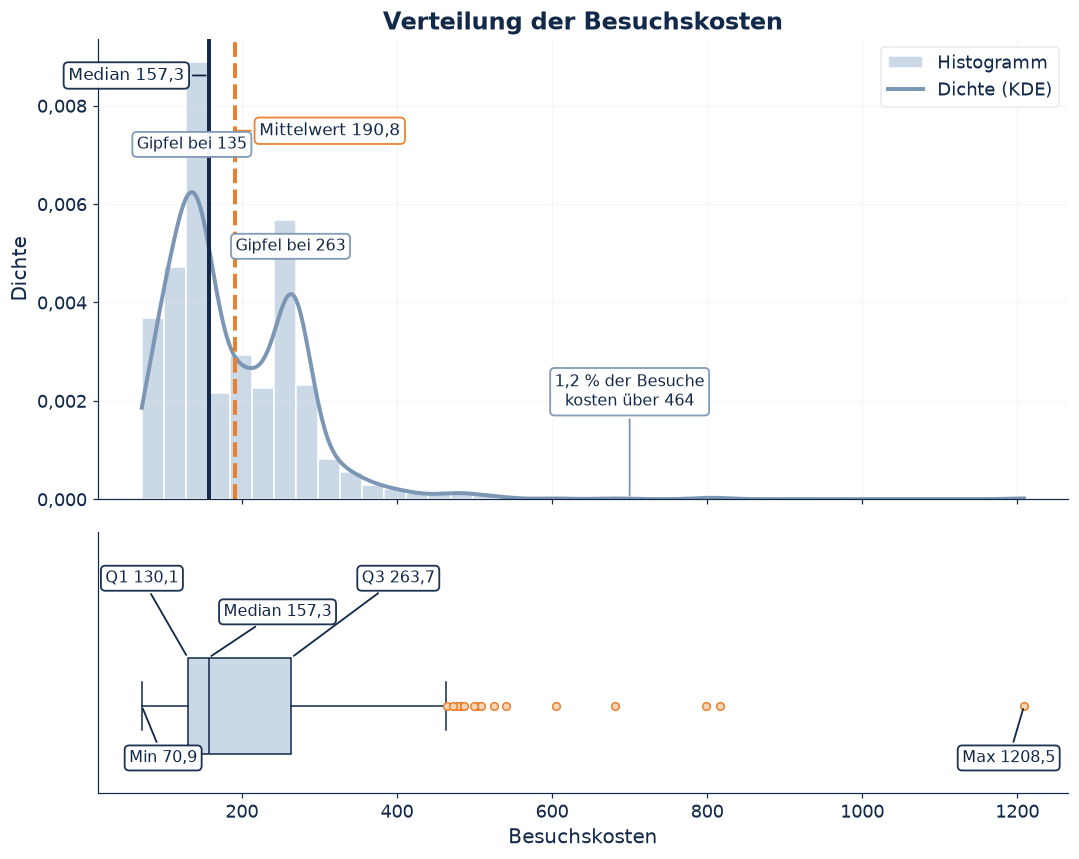

In [12]:
c = df.visit_cost
q1c, medc, q3c = c.quantile([.25, .5, .75])
summ_c = pd.DataFrame({"Wert": [c.min(), q1c, medc, q3c, c.max(), c.mean()]},
                      index=["Minimum", "Q1", "Median", "Q3", "Maximum", "Mittelwert"]).round(2)
print(summ_c.to_string()); print("\nSchiefe:", round(c.skew(), 2))
print(f"Abstand Minimum bis Q1: {q1c - c.min():.1f} | Q1 bis Median: {medc - q1c:.1f} | Median bis Q3: {q3c - medc:.1f} | Q3 bis Maximum: {c.max() - q3c:.1f}")

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.7]})
ax[0].hist(c, bins=40, density=True, color=PASTEL["gruen"], edgecolor="white", label="Histogramm")
xs = np.linspace(c.min(), c.max(), 600); kde = stats.gaussian_kde(c)(xs)
ax[0].plot(xs, kde, color=LINE["gruen"], label="Dichte (KDE)")
ax[0].axvline(c.mean(), color=LINE["rosa"], ls="--"); ax[0].axvline(medc, color=INK)
ax[0].set_ylim(0, kde.max() * 1.5); yt = ax[0].get_ylim()[1]
tag(ax[0], medc, yt * .92, f"Median {medc:.1f}", INK, ox=-16, ha="right")
tag(ax[0], c.mean(), yt * .80, f"Mittelwert {c.mean():.1f}", LINE["rosa"], ox=16, ha="left")
for p in find_peaks(kde, prominence=kde.max() * .12)[0]:
    tag(ax[0], xs[p], kde[p], f"Gipfel bei {xs[p]:.0f}", LINE["gruen"], oy=26, va="bottom", arrow=False, fs=10.5)
tag(ax[0], 700, kde[np.abs(xs - 700).argmin()], f"{100 * (c > 464).mean():.1f} % der Besuche\nkosten über 464", LINE["gruen"], oy=70, fs=10.5)
ax[0].set_title("Verteilung der Besuchskosten"); ax[0].set_ylabel("Dichte"); ax[0].legend(loc="upper right")
ax[1].boxplot(c, vert=False, widths=.5, patch_artist=True, boxprops=dict(facecolor=PASTEL["gruen"], edgecolor=INK),
              medianprops=dict(color=INK), whiskerprops=dict(color=INK), capprops=dict(color=INK),
              flierprops=dict(marker="o", markerfacecolor=PASTEL["rosa"], markeredgecolor=LINE["rosa"], markersize=5))
for lab, val, yv, off in [("Min", c.min(), 1.0, (14, -34)), ("Q1", q1c, 1.25, (-30, 52)), ("Median", medc, 1.25, (45, 30)),
                          ("Q3", q3c, 1.25, (70, 52)), ("Max", c.max(), 1.0, (-10, -34))]:
    tag(ax[1], val, yv, f"{lab} {val:.1f}", INK, ox=off[0], oy=off[1], fs=10.5)
ax[1].set_ylim(.55, 1.9); ax[1].set_yticks([]); ax[1].set_xlabel("Besuchskosten"); ax[1].grid(False)
plt.tight_layout(); show()

**Aussage:** Die Besuchskosten sind stark rechtsschief: Der Mittelwert (190,83) liegt über dem Median (157,28), und der Abstand vom Median zu Q3 (106,4) ist fast viermal so groß wie der von Q1 zum Median (27,2).

**Was die sechs Zahlen gemeinsam über die Form sagen:** Mittelwert über Median und der längere obere Abstand zeigen eine rechtsschiefe Verteilung (Schiefe 2,49). Der Schwanz ist lang: Von Q3 (263,73) bis zum Maximum (1.208,54) sind es 944,8, vom Minimum (70,86) bis Q1 (130,13) nur 59,3, einzelne sehr teure Besuche ziehen den Mittelwert nach oben. Was die sechs Zahlen nicht zeigen, sind die zwei Gipfel (um 135 und um 263), deshalb gehört neben die Zahlen das Histogramm.

## 1.5b Welche einzelne Zahl beschreibt `visit_cost` am besten? (Aufgabe 2)

In [13]:
n_c = len(c)
print(f"Mittelwert x N = {c.mean():.4f} x {n_c} = {c.mean() * n_c:,.2f} | tatsächliche Summe = {c.sum():,.2f}")
print(f"Median x N     = {medc:.4f} x {n_c} = {medc * n_c:,.2f} | weicht um {c.sum() - medc * n_c:,.2f} von der Summe ab")
print(f"\nAnteil der Besuche mit Kosten zwischen 170 und 215 (um den Mittelwert herum): {100 * ((c >= 170) & (c <= 215)).mean():.1f} %")
print(f"Anteil der No-Show-Zeilen an der Gesamtsumme: {df.loc[df.no_show == 1, 'visit_cost'].sum():,.2f} von {c.sum():,.2f} = {100 * df.loc[df.no_show == 1, 'visit_cost'].sum() / c.sum():.1f} %")

Mittelwert x N = 190,8338 x 1200 = 229.000,58 | tatsächliche Summe = 229.000,58
Median x N     = 157,2850 x 1200 = 188.742,00 | weicht um 40.258,58 von der Summe ab

Anteil der Besuche mit Kosten zwischen 170 und 215 (um den Mittelwert herum): 11,8 %
Anteil der No-Show-Zeilen an der Gesamtsumme: 25.371,70 von 229.000,58 = 11,1 %


**Entscheidung für die Kennzahl: der Median (157,28).** Die Kennzahl soll zeigen, was ein typischer Besuch kostet, und das beantwortet der Median: Die Hälfte der Besuche kostet weniger, die Hälfte mehr. Der Mittelwert (190,83) wird von wenigen sehr teuren Besuchen nach oben gezogen, der teuerste kostet 1.208,54.

**Die eine Frage, für die der Mittelwert die richtige Antwort wäre:** „Wie hoch sind die Gesamtkosten für alle N Besuche?“ Mittelwert mal Anzahl rekonstruiert die Gesamtsumme exakt (190,83 mal 1.200 gleich 229.000,58), der Median kann das nicht (er ergäbe 188.742,00). Für die Budgetplanung ist der Mittelwert deshalb die richtige Zahl.

**Zwei Einschränkungen:** Erstens liegt keine der beiden Zahlen auf einem der zwei Gipfel (135 und 263), der Mittelwert sogar im Tal dazwischen, wo nur rund 12 Prozent der Besuche liegen. Eine einzelne Zahl beschreibt diese Verteilung nur unvollständig, deshalb gehört das Histogramm dazu. Zweitens stecken in der Gesamtsumme 25.371,70 (11,1 Prozent) aus No-Show-Zeilen, die laut Audit unmögliche Kosten haben. Wer die Summe meldet, muss das vorher klären.

**Meine Entscheidung 1 (Median statt Mittelwert):**

Ich nehme für die Besuchskosten den Median (157,28) statt des Mittelwerts (190,83), weil die Kennzahl zeigen soll, was ein typischer Besuch kostet. Die Kosten sind rechtsschief: Ein paar sehr teure Besuche, der höchste liegt bei 1.208,54, ziehen den Durchschnitt nach oben. Der Median wird davon kaum beeinflusst und passt deshalb besser zum normalen Fall.

Der Mittelwert wäre die richtige Zahl, wenn es um die gesamten Kosten ginge. Dann rechnet man 190,83 mal 1.200 Besuche und kommt auf 229.000,58. Die teuren Besuche habe ich nicht entfernt, weil sie plausibel aussehen und ich kein Fehlermuster gefunden habe.

Eine Einschränkung: Die Verteilung hat zwei Häufungen, eine bei etwa 135 und eine bei etwa 263. Der Median liegt zwischen beiden und beschreibt keine der beiden Gruppen. Er sagt nur, wo die Mitte aller Besuche liegt.

In [14]:
print(f"Rohdaten ({len(raw)} Zeilen):     Mittelwert {raw.visit_cost.mean():.2f} | Median {raw.visit_cost.median():.2f}")
print(f"Bereinigt ({len(df)} Zeilen): Mittelwert {df.visit_cost.mean():.2f} | Median {df.visit_cost.median():.2f}")

Rohdaten (1209 Zeilen):     Mittelwert 190,73 | Median 157,04
Bereinigt (1200 Zeilen): Mittelwert 190,83 | Median 157,28


**Abgleich Rohdaten gegen bereinigt:** Die neun Duplikate verschieben die Besuchskosten kaum (Median 157,04 gegen 157,28). Wer die Aufgaben auf den Rohdaten rechnet, bekommt also leicht abweichende Nachkommastellen. Die Hauptanalyse verwendet die bereinigten Daten, weil Duplikate dieselben Besuche doppelt zählen würden.

### 1.5c Zusatz: Fünf-Punkte-Zusammenfassung der Wartezeit (Grundlage für die Tests)

            Wert (Min)
Minimum           0,87
Q1                7,48
Median           12,52
Q3               18,80
Maximum          69,78
Mittelwert       14,25

Schiefe: 1,29


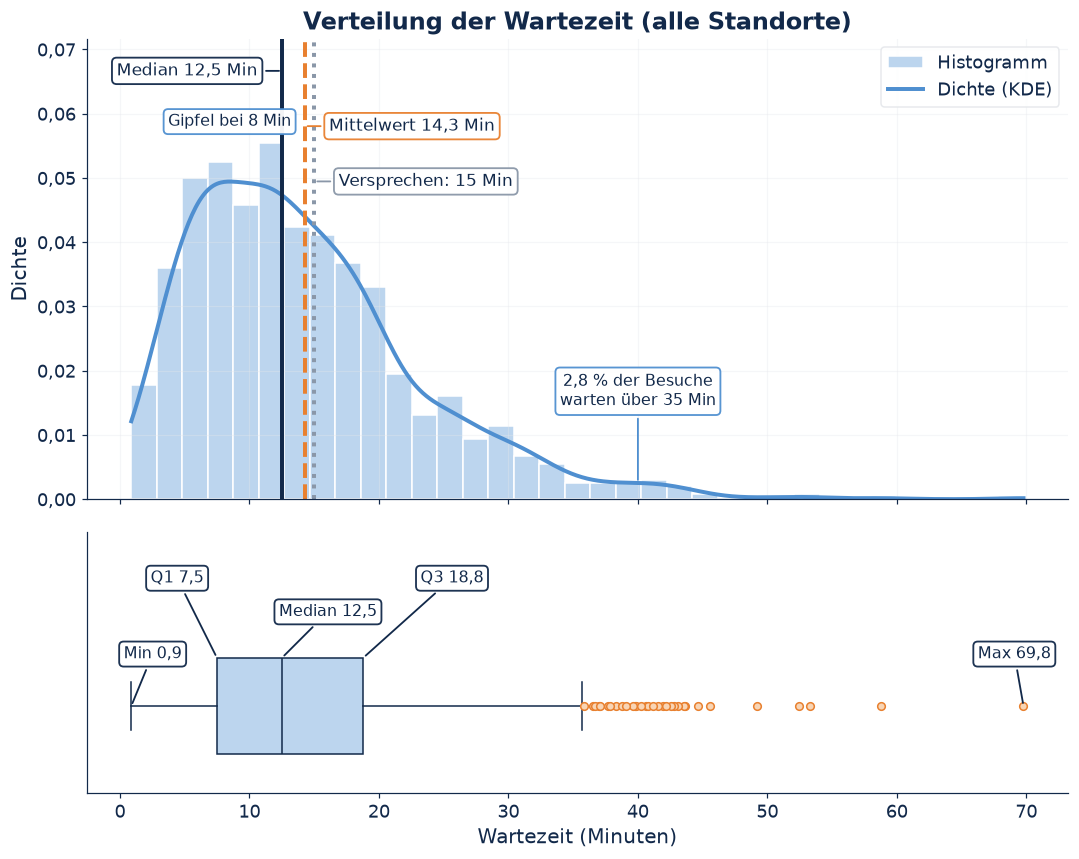

In [15]:
w = df.wait_time_min
summary = pd.DataFrame({"Wert (Min)": [w.min(), w.quantile(.25), w.median(), w.quantile(.75), w.max(), w.mean()]},
                       index=["Minimum", "Q1", "Median", "Q3", "Maximum", "Mittelwert"]).round(2)
print(summary.to_string()); print("\nSchiefe:", round(w.skew(), 2))

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.7]})
ax[0].hist(w, bins=35, density=True, color=PASTEL["blau"], edgecolor="white", label="Histogramm")
xs = np.linspace(w.min(), w.max(), 500); kde = stats.gaussian_kde(w)(xs)
ax[0].plot(xs, kde, color=LINE["blau"], label="Dichte (KDE)")
ax[0].axvline(w.mean(), color=LINE["rosa"], ls="--")
ax[0].axvline(w.median(), color=INK)
ax[0].axvline(15, color=LINE["grau"], ls=":")
ax[0].set_ylim(0, kde.max() * 1.45); yt = ax[0].get_ylim()[1]
tag(ax[0], w.median(), yt * .93, f"Median {w.median():.1f} Min", INK, ox=-16, ha="right")
tag(ax[0], w.mean(), yt * .81, f"Mittelwert {w.mean():.1f} Min", LINE["rosa"], ox=16, ha="left")
tag(ax[0], 15, yt * .69, "Versprechen: 15 Min", LINE["grau"], ox=16, ha="left")
pk = xs[kde.argmax()]; tag(ax[0], pk, kde.max(), f"Gipfel bei {pk:.0f} Min", LINE["blau"], oy=34, va="bottom", arrow=False, fs=10.5)
tag(ax[0], 40, kde[np.abs(xs - 40).argmin()], f"{100 * (w > 35).mean():.1f} % der Besuche\nwarten über 35 Min", LINE["blau"], ox=0, oy=60, fs=10.5)
ax[0].set_title("Verteilung der Wartezeit (alle Standorte)"); ax[0].set_ylabel("Dichte"); ax[0].legend(loc="upper right")
ax[1].boxplot(w, vert=False, widths=.5, patch_artist=True, boxprops=dict(facecolor=PASTEL["blau"], edgecolor=INK),
              medianprops=dict(color=INK), whiskerprops=dict(color=INK), capprops=dict(color=INK),
              flierprops=dict(marker="o", markerfacecolor=PASTEL["rosa"], markeredgecolor=LINE["rosa"], markersize=5))
q1_, q3_ = w.quantile(.25), w.quantile(.75)
for lab, val, yv, off in [("Min", w.min(), 1.0, (14, 34)), ("Q1", q1_, 1.25, (-26, 52)), ("Median", w.median(), 1.25, (30, 30)),
                          ("Q3", q3_, 1.25, (58, 52)), ("Max", w.max(), 1.0, (-6, 34))]:
    tag(ax[1], val, yv, f"{lab} {val:.1f}", INK, ox=off[0], oy=off[1], fs=10.5)
ax[1].set_ylim(.55, 1.9); ax[1].set_yticks([]); ax[1].set_xlabel("Wartezeit (Minuten)"); ax[1].grid(False)
plt.tight_layout(); show()

**Aussage:** Die Wartezeit ist rechtsschief: Der Mittelwert (14,3 Minuten) liegt über dem Median (12,5 Minuten), und ein langer Schwanz reicht bis fast 70 Minuten.

**Was die sechs Zahlen gemeinsam zeigen:** Von Minimum (0,9) bis Q1 (7,5) sind es 6,6 Minuten, von Q3 (18,8) bis Maximum (69,8) aber 51 Minuten. Der obere Teil ist also weit gestreckter als der untere, und der Mittelwert wird von diesem Schwanz nach oben gezogen.

**Dieselbe Logik für die Wartezeit: Median (12,5 Minuten) für den typischen Patienten.** Die Kennzahl soll beantworten, wie lange ein *typischer* Patient wartet, und das tut der Median: Die Hälfte der Besuche wartet kürzer als 12,5 Minuten, die andere Hälfte länger. Der Mittelwert (14,3 Minuten) beantwortet stattdessen die Frage, wie viel Wartezeit pro Besuch insgesamt anfällt. Das ist die richtige Größe für Personalplanung und für die Tests in Checkpoint 2 und 3, als einzelne Kennzahl führt er aber dazu, dass der typische Patient schlechter dargestellt wird, als er es erlebt.

## 1.6 Verteilungen im Detail (Histogramm und Dichteplot)

Die gestrichelte orange Linie ist der Mittelwert, die dunkelblaue der Median, die gepunktete graue Linie die obere Ausreißergrenze aus 1.4.

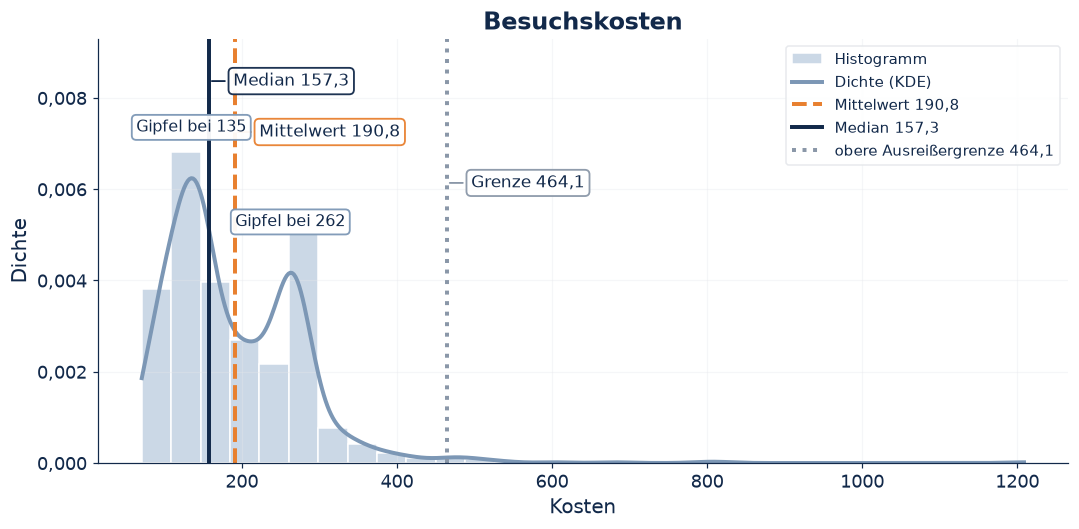

In [16]:
hist_kde(df.visit_cost, "Besuchskosten", "Kosten", color="gruen")

**Aussage:** Die Besuchskosten sind rechtsschief und haben zwei deutliche Gipfel, einen bei etwa 135 und einen bei etwa 263.

**Lesart:** Der Mittelwert (190,83) fällt in die Lücke zwischen den beiden Gipfeln und beschreibt kaum einen tatsächlichen Besuch. 59,8 Prozent der Besuche kosten weniger als 200 (Median dieser Gruppe etwa 135), die übrigen 40,2 Prozent mehr (Median etwa 264). Für Aussagen über die Kosten braucht es deshalb beide Gruppen und nicht nur eine Kennzahl.

Ausgeblendete Dauerwerte (über 120 Min): 13


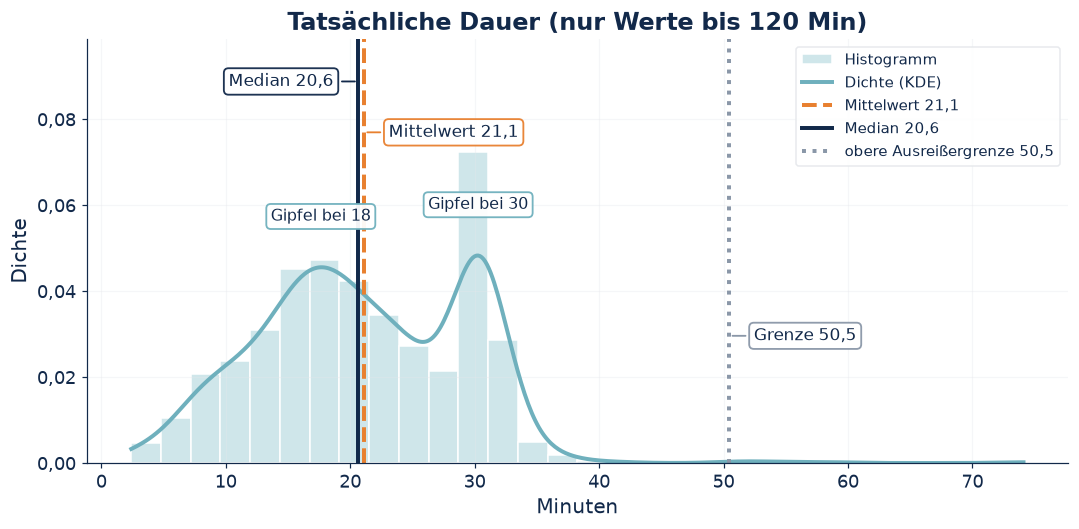

In [17]:
dur = df.actual_duration_min
print("Ausgeblendete Dauerwerte (über 120 Min):", int((dur > 120).sum()))
hist_kde(dur[dur <= 120], "Tatsächliche Dauer (nur Werte bis 120 Min)", "Minuten", color="pfirsich")

**Aussage:** Die tatsächliche Dauer streut um etwa 20 Minuten mit zwei Gipfeln, die ausgeblendeten Werte über 120 Minuten sind die vermuteten Eingabefehler.

**Lesart:** Ohne die 13 Werte über 120 Minuten (1.187 Besuche) liegt der Median bei etwa 20,6 Minuten, die mittlere Hälfte zwischen 15,4 und 29,4 Minuten. Die zwei Gipfel gehen auf die geplanten Zeitfenster zurück (Aufschlüsselung nach geplanter Dauer weiter unten). Die 13 ausgeblendeten Werte dauern mehrere Stunden und würden den Mittelwert stark anheben, deshalb beschreibt der Median die typische Dauer besser.

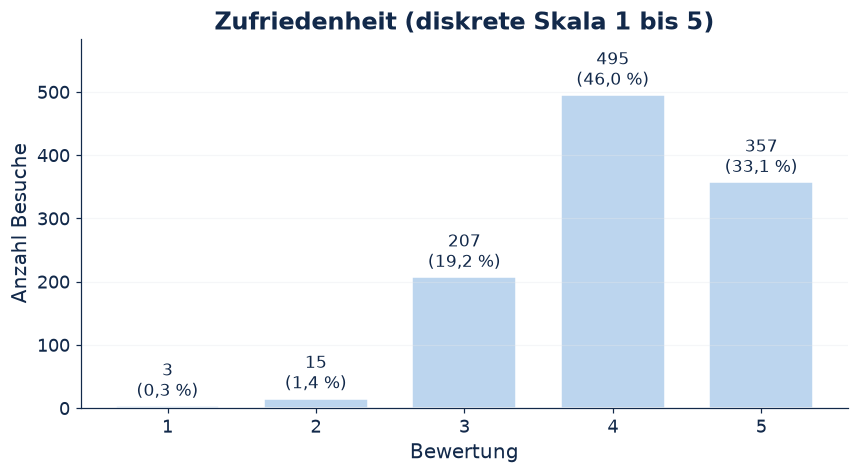

In [18]:
counts = df.patient_satisfaction.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index, counts.values, color=PASTEL["blau"], edgecolor="white", width=.7)
ax.bar_label(bars, labels=[f"{v}\n({100 * v / counts.sum():.1f} %)" for v in counts.values], fontsize=11, color=INK, padding=3)
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Zufriedenheit (diskrete Skala 1 bis 5)"); ax.set_xlabel("Bewertung"); ax.set_ylabel("Anzahl Besuche")
ax.grid(axis="x", visible=False); plt.tight_layout(); show()

**Aussage:** Die Zufriedenheit ist linksschief, die meisten Besuche werden mit 4 oder 5 bewertet, und Bewertungen unter 3 sind selten.

**Lesart:** 79,1 Prozent der 1.077 bewerteten Besuche erhalten eine 4 oder 5, 33,1 Prozent die Bestnote und nur 1,7 Prozent (18 Besuche) eine Bewertung unter 3. Mittelwert (4,10) und Median (4) liegen eng beieinander, der Schwanz nach unten enthält kaum Besuche. Weil 123 Bewertungen fehlen (vor allem bei Urgent), gilt das für die Besuche mit Bewertung.

### Woher kommen die zwei Gipfel?

Zwei Gipfel deuten auf eine Mischung aus zwei Gruppen. Ich prüfe, ob die vorhandenen Variablen sie erklären.

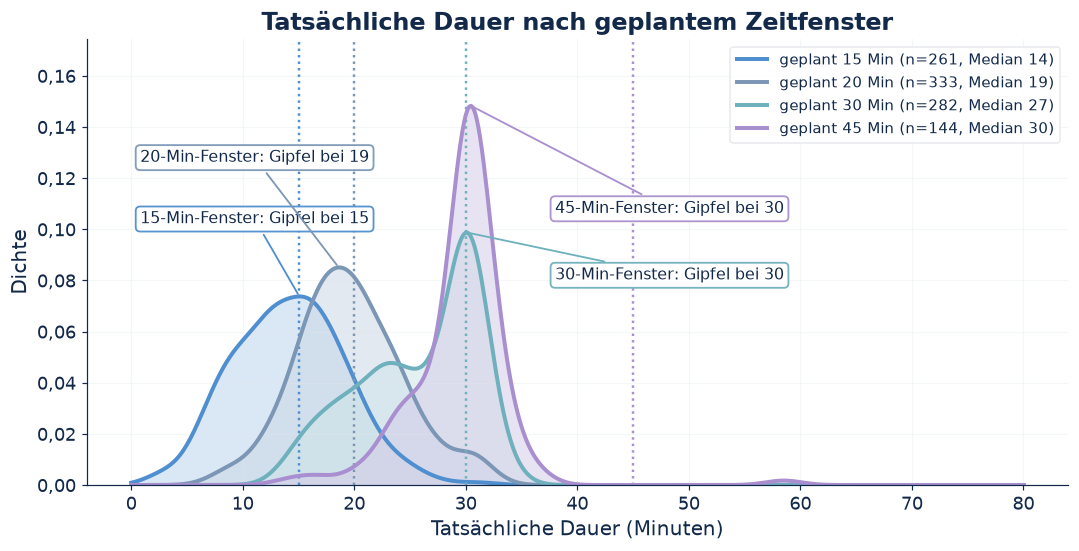

In [19]:
slots = [15, 20, 30, 45]; cols = ["blau", "gruen", "pfirsich", "lila"]
tpos = {15: (.8, .104, "left"), 20: (.8, .128, "left"), 30: (38, .082, "left"), 45: (38, .108, "left")}
xs = np.linspace(0, 80, 500)
fig, ax = plt.subplots(figsize=(10, 5.2))
for sl, cl in zip(slots, cols):
    d_ = df.loc[(df.scheduled_duration_min == sl) & (df.actual_duration_min <= 120), "actual_duration_min"]
    k_ = stats.gaussian_kde(d_)(xs)
    ax.fill_between(xs, k_, color=PASTEL[cl], alpha=.55)
    ax.plot(xs, k_, color=LINE[cl], label=f"geplant {sl} Min (n={len(d_)}, Median {d_.median():.0f})")
    ax.axvline(sl, color=LINE[cl], ls=":", lw=1.6)
    tx, ty, ha = tpos[sl]
    tagd(ax, (xs[k_.argmax()], k_.max()), (tx, ty), f"{sl}-Min-Fenster: Gipfel bei {xs[k_.argmax()]:.0f}", LINE[cl], ha=ha, fs=10.5)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.set_title("Tatsächliche Dauer nach geplantem Zeitfenster"); ax.set_xlabel("Tatsächliche Dauer (Minuten)")
ax.set_ylabel("Dichte"); ax.legend(loc="upper right", fontsize=10); plt.tight_layout(); show()

**Aussage:** Der erste Gipfel stammt von den kurzen Zeitfenstern (15 und 20 Minuten), die um ihre geplante Länge streuen, der zweite bei etwa 30 Minuten von den 30- und 45-Minuten-Fenstern, die beide bei etwa 30 Minuten enden.

**Auffälligkeit:** Besuche mit 45 Minuten Plan dauern im Median nur 30 Minuten und folgen ihrem Zeitfenster (gepunktete Linie) nicht. Warum das so ist (zum Beispiel eine Obergrenze bei der Abrechnung oder im Erfassungssystem), kann dieser Datensatz nicht beantworten.

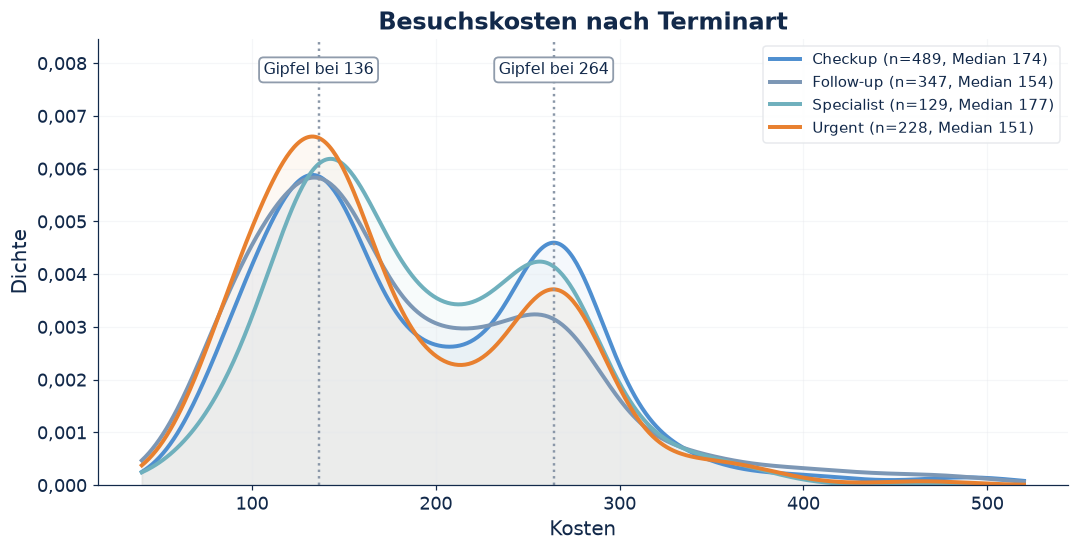

In [20]:
types = ["Checkup", "Follow-up", "Specialist", "Urgent"]; cols = ["blau", "gruen", "pfirsich", "rosa"]
xs = np.linspace(40, 520, 500)
fig, ax = plt.subplots(figsize=(10, 5.2))
for t_, cl in zip(types, cols):
    c_ = df.loc[(df.appointment_type == t_) & (df.visit_cost <= 520), "visit_cost"]
    k_ = stats.gaussian_kde(c_)(xs)
    ax.fill_between(xs, k_, color=PASTEL[cl], alpha=.15)
    ax.plot(xs, k_, color=LINE[cl], label=f"{t_} (n={len(c_)}, Median {c_.median():.0f})")
k_all = stats.gaussian_kde(df.loc[df.visit_cost <= 520, "visit_cost"])(xs)
for p in find_peaks(k_all, prominence=k_all.max() * .2)[0]:
    ax.axvline(xs[p], color=LINE["grau"], ls=":", lw=1.6)
ax.set_ylim(0, ax.get_ylim()[1] * 1.22); yt = ax.get_ylim()[1]
for p in find_peaks(k_all, prominence=k_all.max() * .2)[0]:
    tag(ax, xs[p], yt * .93, f"Gipfel bei {xs[p]:.0f}", LINE["grau"], ox=0, arrow=False, fs=10.5)
ax.set_title("Besuchskosten nach Terminart"); ax.set_xlabel("Kosten"); ax.set_ylabel("Dichte")
ax.legend(loc="upper right", fontsize=10); plt.tight_layout(); show()

**Aussage:** Alle vier Terminarten zeigen dieselben zwei Kostengipfel, die Terminart erklärt sie also nicht.

Auch Versicherungsart und geplante Dauer erklären sie nicht (der Anteil der Besuche über 200 liegt in allen größeren Gruppen bei etwa 35 bis 45 Prozent), und die Mediane der Standorte liegen dicht beieinander (156 bis 160). **Was die Gipfel verursacht, kann dieser Datensatz nicht beantworten.** Das ist eine offene Frage für Solace (zum Beispiel zwei Preisstufen oder Leistungspakete) und ändert keinen der folgenden Tests.

## 1.7 Zusammenhänge

### Quantitativ: Wartezeit gegen Zufriedenheit

**Umgang mit fehlenden Werten (vor der Berechnung festgelegt):** Verwendet werden nur Besuche mit vorhandener Zufriedenheitsbewertung (n = 1.077), nichts wird ersetzt. Das Audit hat gezeigt, dass die Bewertung nicht zufällig fehlt (bei Urgent in 31,8 Prozent der Besuche, sonst in etwa 5 Prozent). Deshalb wird nach der Berechnung geprüft, ob der Zusammenhang in jeder Terminart derselbe ist.

n = 1077 | Pearson r = -0,388 (95%-KI -0,438 bis -0,336, p = 4,4e-40) | Spearman rho = -0,403 (p = 2,5e-43)
Erklärte Varianz (r im Quadrat): 15,1 %


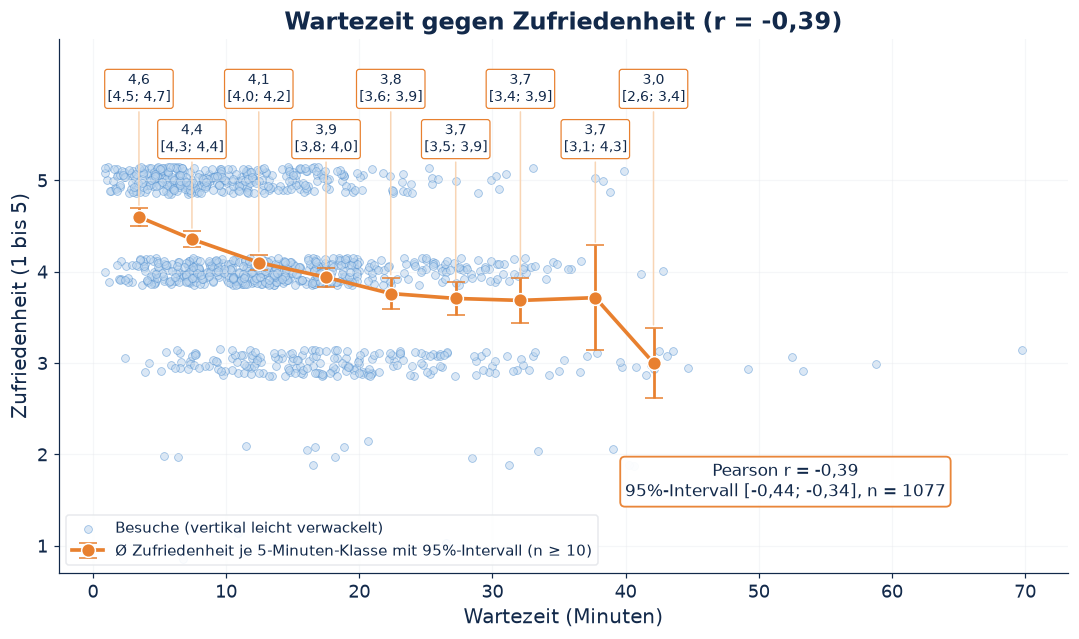

In [21]:
s2 = df[["wait_time_min", "patient_satisfaction"]].dropna()
r, p_r = stats.pearsonr(s2.wait_time_min, s2.patient_satisfaction)
rho, p_rho = stats.spearmanr(s2.wait_time_min, s2.patient_satisfaction)
z = np.arctanh(r); se_z = 1 / np.sqrt(len(s2) - 3)
r_lo, r_hi = np.tanh([z - 1.96 * se_z, z + 1.96 * se_z])
print(f"n = {len(s2)} | Pearson r = {r:.3f} (95%-KI {r_lo:.3f} bis {r_hi:.3f}, p = {p_r:.1e}) | Spearman rho = {rho:.3f} (p = {p_rho:.1e})")
print(f"Erklärte Varianz (r im Quadrat): {100 * r**2:.1f} %")

fig, ax = plt.subplots(figsize=(10, 6))
jit = np.random.default_rng(SEED).uniform(-.15, .15, len(s2))
ax.scatter(s2.wait_time_min, s2.patient_satisfaction + jit, s=26, alpha=.55, color=PASTEL["blau"], edgecolor=LINE["blau"], linewidth=.5,
           label="Besuche (vertikal leicht verwackelt)")
bins = pd.cut(s2.wait_time_min, bins=range(0, 80, 5))
rows_ = []
for _, g in s2.groupby(bins, observed=True):
    if len(g) >= 10:
        m_, lo_, hi_ = mean_ci(g.patient_satisfaction); rows_.append((g.wait_time_min.mean(), m_, lo_, hi_, len(g)))
mb = pd.DataFrame(rows_, columns=["x", "m", "lo", "hi", "n"])
ax.errorbar(mb.x, mb.m, yerr=[mb.m - mb.lo, mb.hi - mb.m], fmt="o-", color=LINE["rosa"], ms=9, markeredgecolor="white",
            capsize=6, lw=2.4, elinewidth=1.8, label="Ø Zufriedenheit je 5-Minuten-Klasse mit 95%-Intervall (n ≥ 10)")
for k_, (_, r_) in enumerate(mb.iterrows()):
    yy = 6.0 if k_ % 2 == 0 else 5.45
    ax.annotate(f"{r_.m:.1f}\n[{r_.lo:.1f}; {r_.hi:.1f}]", (r_.x, r_.hi), xytext=(r_.x, yy), textcoords="data", ha="center", va="center",
                fontsize=9, color=INK, bbox=dict(boxstyle="round,pad=.2", fc="white", ec=LINE["rosa"], lw=.8),
                arrowprops=dict(arrowstyle="-", color=PASTEL["rosa"], lw=1))
ax.set_ylim(.7, 6.55); ax.set_xlabel("Wartezeit (Minuten)"); ax.set_ylabel("Zufriedenheit (1 bis 5)")
tag(ax, 52, 1.7, f"Pearson r = {r:.2f}\n95%-Intervall [{r_lo:.2f}; {r_hi:.2f}], n = {len(s2)}", LINE["rosa"], arrow=False)
ax.set_title(f"Wartezeit gegen Zufriedenheit (r = {r:.2f})"); ax.set_yticks([1, 2, 3, 4, 5]); ax.legend(loc="lower left", fontsize=10)
plt.tight_layout(); show()

**Aussage:** Mit längerer Wartezeit sinkt die mittlere Zufriedenheit von etwa 4,6 auf etwa 3,7, ein moderater negativer Zusammenhang (r = −0,39).

**Lesart:** Die Stärke ist die Aussage: Wartezeit erklärt etwa 15 Prozent der Unterschiede in der Zufriedenheit, der Rest hat andere Ursachen. Das ist ein Zusammenhang, kein Beleg dafür, dass kürzeres Warten die Zufriedenheit verursacht.

In [22]:
typ = df.loc[s2.index, "appointment_type"]
rows = []
for t_ in ["Checkup", "Follow-up", "Specialist", "Urgent"]:
    g = s2[typ == t_]
    rows.append({"Terminart": t_, "n mit Bewertung": len(g), "Pearson r": round(stats.pearsonr(g.wait_time_min, g.patient_satisfaction)[0], 2),
                 "Ø Zufriedenheit": round(g.patient_satisfaction.mean(), 2)})
pd.DataFrame(rows)

,Terminart,n mit Bewertung,Pearson r,Ø Zufriedenheit
0,Checkup,464,"-0,42","4,11"
1,Follow-up,331,"-0,34","4,11"
2,Specialist,123,"-0,45","4,11"
3,Urgent,159,"-0,35","4,06"


**Aussage:** In jeder Terminart liegt der Zusammenhang zwischen −0,34 und −0,45 und die mittlere Zufriedenheit zwischen 4,06 und 4,11, die systematisch fehlenden Bewertungen bei Urgent verzerren den Befund also nicht.

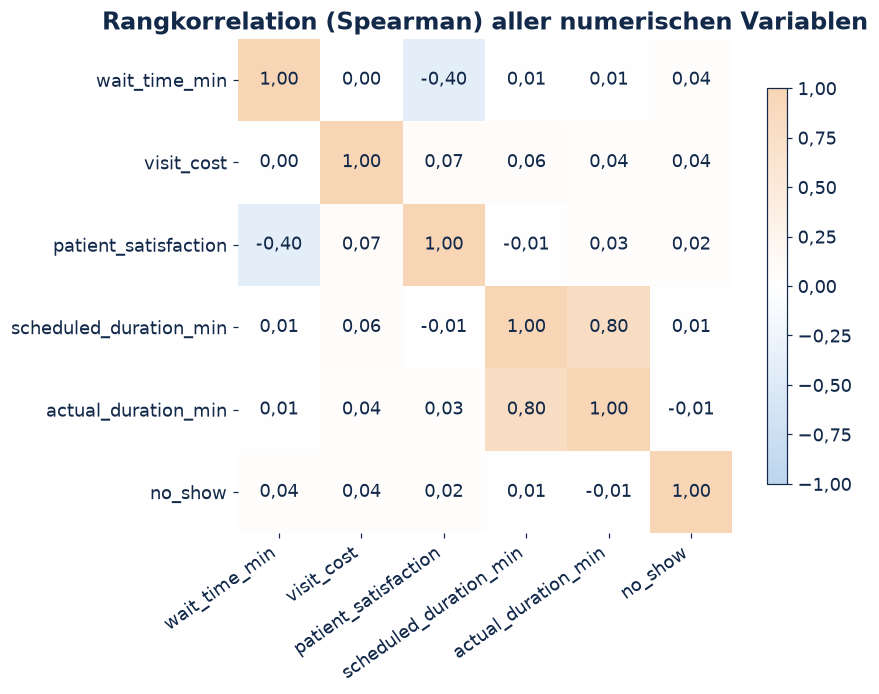

In [23]:
num_cols = ["wait_time_min", "visit_cost", "patient_satisfaction", "scheduled_duration_min", "actual_duration_min", "no_show"]
corr = df[num_cols].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("pastell", [PASTEL["blau"], "#FFFFFF", PASTEL["rosa"]])
fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=35, ha="right")
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols); ax.grid(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color=INK, fontsize=12)
for sp_ in ax.spines.values(): sp_.set_visible(False)
ax.set_title("Rangkorrelation (Spearman) aller numerischen Variablen")
fig.colorbar(im, ax=ax, shrink=.8); plt.tight_layout(); show()

**Aussage:** Stark hängen nur geplante und tatsächliche Dauer zusammen (0,80) und, mit umgekehrtem Vorzeichen, Wartezeit und Zufriedenheit (−0,40), alle anderen Paare liegen nahe null.

### Kategorial: Terminart gegen No-Show

no_show             0   1
appointment_type         
Checkup           445  45
Follow-up         313  35
Specialist        120   9
Urgent            193  40 

chi2 = 13,34, df = 3, p = 0,0040, Cramér's V = 0,105 | kleinste erwartete Häufigkeit: 13,9

Standardisierte Residuen (Betrag über 2 = Zelle treibt den Zusammenhang):
                   kein No-Show  No-Show
appointment_type                       
Checkup                   0,37    -1,06
Follow-up                 0,14    -0,39
Specialist                0,45    -1,31
Urgent                   -1,04     2,99


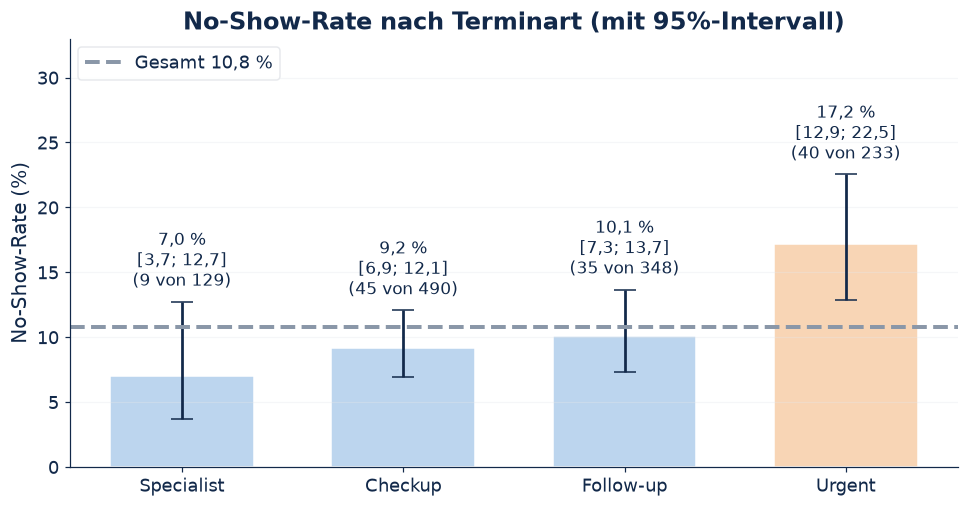

In [24]:
ct = pd.crosstab(df.appointment_type, df.no_show)
chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
n_ct = ct.values.sum(); cramer_v = np.sqrt(chi2 / (n_ct * (min(ct.shape) - 1)))
print(ct, "\n")
print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p_chi:.4f}, Cramér's V = {cramer_v:.3f} | kleinste erwartete Häufigkeit: {expected.min():.1f}")
resid = pd.DataFrame((ct.values - expected) / np.sqrt(expected), index=ct.index, columns=["kein No-Show", "No-Show"]).round(2)
print("\nStandardisierte Residuen (Betrag über 2 = Zelle treibt den Zusammenhang):\n", resid)

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

rate = ct[1] / ct.sum(axis=1)
order = rate.sort_values().index
ci_ = np.array([wilson(ct.loc[t_, 1], ct.loc[t_].sum()) for t_ in order])
colmap = dict(zip(order, [PASTEL["blau"], PASTEL["blau"], PASTEL["blau"], PASTEL["rosa"]]))
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(order, rate[order] * 100, color=[colmap[t_] for t_ in order], edgecolor="white", width=.65,
              yerr=[(rate[order] - ci_[:, 0]) * 100, (ci_[:, 1] - rate[order]) * 100], capsize=7, error_kw=dict(ecolor=INK, lw=1.8))
for x_, (t_, hi_) in enumerate(zip(order, ci_[:, 1])):
    ax.text(x_, hi_ * 100 + .8, f"{rate[t_] * 100:.1f} %\n[{ci_[x_, 0] * 100:.1f}; {ci_[x_, 1] * 100:.1f}]\n({ct.loc[t_, 1]} von {ct.loc[t_].sum()})",
            ha="center", va="bottom", color=INK, fontsize=11)
ax.set_ylim(0, 33)
ax.axhline(df.no_show.mean() * 100, color=LINE["grau"], ls="--", label=f"Gesamt {df.no_show.mean() * 100:.1f} %")
ax.set_title("No-Show-Rate nach Terminart (mit 95%-Intervall)"); ax.set_ylabel("No-Show-Rate (%)"); ax.set_xlabel("")
ax.grid(axis="x", visible=False); ax.legend(loc="upper left"); plt.tight_layout(); show()

**Aussage:** Urgent-Termine werden mit rund 17 Prozent am häufigsten nicht wahrgenommen und Specialist-Termine mit rund 7 Prozent am seltensten, der Unterschied ist signifikant und nach Cramérs V schwach (0,11), gemessen an der Basisrate aber groß.

**Lesart:** Mit 1.200 Besuchen wird auch ein kleiner Effekt signifikant, deshalb zählt die Stärke: Die Terminart erklärt nur einen kleinen Teil der No-Shows. Die Intervalle von Urgent und Specialist überlappen sich nicht, die beiden mittleren Terminarten liegen dazwischen.

**Praktische Größe (Triage):** Der Abstand zwischen Urgent (17,2 Prozent) und Specialist (7,0 Prozent) beträgt 10,2 Prozentpunkte, etwa so viel wie die gesamte Basisrate (10,8 Prozent), und Urgent hat die 2,5-fache Rate. Gemessen an der Basisrate ist das nicht klein, auch wenn Cramérs V schwach wirkt: V misst den Zusammenhang über alle vier Terminarten, der Abstand zwischen den Extremen sagt mehr über die Entscheidungsrelevanz. Ein plausibler Mechanismus ist, dass Urgent-Termine kurzfristig gebucht werden und sich der Anlass von selbst erledigen kann. Das ist eine Hypothese und aus diesen Daten nicht prüfbar. Nach der Triage-Logik (groß, plausibel, als nicht zufällig ausgewiesen) wäre das Muster eine weitere Untersuchung wert.

In [25]:
erw = pd.DataFrame(expected, index=ct.index, columns=["erwartet kein No-Show", "erwartet No-Show"]).round(1)
pd.DataFrame({"No-Shows beobachtet": ct[1], "No-Shows erwartet": erw["erwartet No-Show"],
              "Differenz": (ct[1] - erw["erwartet No-Show"]).round(1)})

,No-Shows beobachtet,No-Shows erwartet,Differenz
appointment_type,,,
Checkup,45,"52,70","-7,70"
Follow-up,35,"37,40","-2,40"
Specialist,9,"13,90","-4,90"
Urgent,40,"25,00","15,00"


**In Alltagssprache:** Würde die Terminart keine Rolle spielen, wären bei diesen 1.200 Besuchen etwa 52,7 No-Shows bei Checkup, 37,4 bei Follow-up, 13,9 bei Specialist und 25,0 bei Urgent zu erwarten. Beobachtet sind 45, 35, 9 und 40. Auffällig ist Urgent mit 15 No-Shows mehr als erwartet (40 statt 25,0). Bei Specialist (9 statt 13,9) und Checkup (45 statt 52,7) sind es weniger, Follow-up liegt fast genau beim Erwartungswert (35 statt 37,4). Der kleine p-Wert (0,004) heißt nur, dass dieses Bild nicht nach Zufall aussieht, über die Stärke sagt er nichts, die liefert Cramérs V (0,11).

### Wie sicher ist der Abstand zwischen Urgent und Specialist? (Intervall)

Urgent: 40 von 233 = 17,2 % | Specialist: 9 von 129 = 7,0 %
Abstand: 10,2 Prozentpunkte, 95%-Intervall [3,0; 16,5]
Verhältnis der Raten: 2,46, 95%-Intervall [1,23; 4,91]


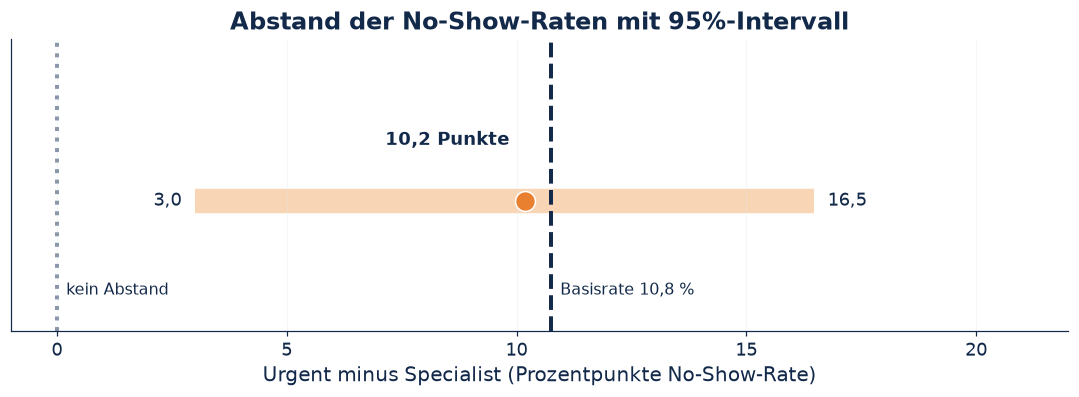

In [26]:
k_u, n_u = int(ct.loc["Urgent", 1]), int(ct.loc["Urgent"].sum()); k_s, n_s = int(ct.loc["Specialist", 1]), int(ct.loc["Specialist"].sum())
p_u, p_s = k_u / n_u, k_s / n_s
l_u, h_u = wilson(k_u, n_u); l_s, h_s = wilson(k_s, n_s)
d_nsh = p_u - p_s                                                             # Abstand in Prozentpunkten (als Anteil)
dn_lo = d_nsh - np.sqrt((p_u - l_u) ** 2 + (h_s - p_s) ** 2)                  # Newcombe-Intervall für die Differenz
dn_hi = d_nsh + np.sqrt((h_u - p_u) ** 2 + (p_s - l_s) ** 2)
rr = p_u / p_s; se_rr = np.sqrt(1 / k_u - 1 / n_u + 1 / k_s - 1 / n_s)
rr_lo, rr_hi = np.exp(np.log(rr) + np.array([-1, 1]) * 1.96 * se_rr)
print(f"Urgent: {k_u} von {n_u} = {p_u * 100:.1f} % | Specialist: {k_s} von {n_s} = {p_s * 100:.1f} %")
print(f"Abstand: {d_nsh * 100:.1f} Prozentpunkte, 95%-Intervall [{dn_lo * 100:.1f}; {dn_hi * 100:.1f}]")
print(f"Verhältnis der Raten: {rr:.2f}, 95%-Intervall [{rr_lo:.2f}; {rr_hi:.2f}]")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hlines(0, dn_lo * 100, dn_hi * 100, color=PASTEL["rosa"], lw=16, zorder=1)
ax.plot(d_nsh * 100, 0, "o", color=LINE["rosa"], ms=13, markeredgecolor="white", zorder=2)
ax.text(dn_lo * 100 - .3, 0, f"{dn_lo * 100:.1f}", ha="right", va="center", fontsize=11.5)
ax.text(dn_hi * 100 + .3, 0, f"{dn_hi * 100:.1f}", ha="left", va="center", fontsize=11.5)
ax.text(d_nsh * 100 - .35, .32, f"{d_nsh * 100:.1f} Punkte", ha="right", va="bottom", fontsize=11.5, fontweight="bold")
ax.axvline(0, color=LINE["grau"], ls=":"); ax.axvline(df.no_show.mean() * 100, color=INK, ls="--")
ax.text(df.no_show.mean() * 100 + .2, -.55, f"Basisrate {df.no_show.mean() * 100:.1f} %", fontsize=10.5, va="center")
ax.text(.2, -.55, "kein Abstand", fontsize=10.5, va="center", color=INK)
ax.set_yticks([]); ax.set_ylim(-.8, 1); ax.set_xlim(-1, 22)
ax.set_xlabel("Urgent minus Specialist (Prozentpunkte No-Show-Rate)"); ax.set_title("Abstand der No-Show-Raten mit 95%-Intervall")
ax.grid(axis="y", visible=False); plt.tight_layout(); show()

**Aussage:** Der Abstand von 10,2 Prozentpunkten zwischen Urgent und Specialist liegt mit seinem Intervall (3,0 bis 16,5) klar über null, ist aber ungenau, weil Specialist nur 129 Besuche hat.

**Lesart:** Die Rate von Urgent ist mit 95 Prozent Sicherheit das 1,2- bis 4,9-fache der Rate von Specialist (Punktschätzung 2,5-fach). Auch am unteren Ende ist der Abstand mit 3 Punkten nicht null, aber nur etwa ein Viertel der Basisrate (10,8 Prozent). Der Befund trägt die Aussage „Urgent fällt häufiger aus“, nicht die Aussage „es sind genau 10 Punkte“. Für eine genauere Zahl bräuchte es mehr Specialist-Besuche.

## Entscheidungsregeln (vor den Tests festgehalten)

Diese Regeln stehen vor den Tests, damit die Ergebnisse nicht nachträglich zur Lesart passen. Die Spalte „Vorab festgelegt?“ nennt, was vor der Analyse feststand und was nicht.

| Entscheidung | Regel | Begründung | Vorab festgelegt? |
|---|---|---|---|
| Checkpoint 2, Hypothesen | H₀: μ ≥ 15 Minuten, H₁: μ < 15 Minuten, einseitiger t-Test, α = 0,05 | Die Frage lautet nur „kürzer als 15 Minuten?“ | Ja, aus der Aufgabe und dem Serviceversprechen |
| Checkpoint 3, Hypothesen | H₀: μ_Riverside = μ_Downtown, H₁: ungleich, zweiseitiger Welch-Test, α = 0,05 | Die Frage verlangt keine Richtung, beide Ergebnisse wären eine Entscheidung wert | Ja, aus der Aufgabe |
| Handlungsschwelle | Relevant, wenn die untere Grenze des 95-%-Intervalls über 5 Minuten liegt. Unklar, wenn das Intervall die 5 Minuten einschließt. Nicht relevant, wenn die obere Grenze darunter liegt. | Wer einen Termin vereinbart, erwartet, dass er eingehalten wird. Eine Verzögerung bis etwa 5 Minuten (ein Drittel des Serviceversprechens) ist vertretbar, weil im Betriebsablauf Störungen vorkommen (verspätete vorherige Patienten, umfangreichere Untersuchungen). Die Begründung ist fachlich und kommt nicht aus den Daten. | Nein: Die Schwelle wurde nach dem Welch-Test festgelegt. Deshalb wird geprüft, bei welchen Schwellen die Aussage hält (3, 5, 7 und 10 Minuten). |
| SMS-Test (Checkpoint 4) | Hauptkennzahl No-Show-Rate, kleinster relevanter Effekt 5 Prozentpunkte, α = 0,05, 80 % Power, etwa 470 Termine je Gruppe | Der Test ist noch nicht durchgeführt, die Festlegung erfolgt vor dem ersten Termin | Ja, vorab für den neuen Test |


# Checkpoint 2: Einen einseitigen Test lesen (Downtown, Serviceversprechen)

**Frage:** Warten Patienten in Downtown im Durchschnitt weniger als 15 Minuten?

In [27]:
dt = df.loc[df.clinic_site == "Downtown", "wait_time_min"].dropna()
MU0 = 15                                          # Serviceversprechen: weniger als 15 Minuten
n_d = len(dt); xbar = dt.mean(); sd_d = dt.std(ddof=1); se_d = sd_d / np.sqrt(n_d)
t_stat = (xbar - MU0) / se_d; dfree = n_d - 1
p_one = stats.t.cdf(t_stat, dfree)                # einseitig: P(T <= t) unter H0
p_two = 2 * p_one

res = stats.ttest_1samp(dt, MU0, alternative="less")
assert np.isclose(res.statistic, t_stat) and np.isclose(res.pvalue, p_one)     # Handrechnung = scipy

ci_lo2, ci_hi2 = stats.t.interval(0.95, dfree, loc=xbar, scale=se_d)
upper95 = xbar + stats.t.ppf(0.95, dfree) * se_d

print(f"n = {n_d} | Mittelwert = {xbar:.2f} | SD = {sd_d:.2f} | Standardfehler = {se_d:.3f}")
print(f"t = {t_stat:.2f} | Freiheitsgrade = {dfree}")
print(f"p einseitig = {p_one:.2e} | p zweiseitig (für diese Frage falsch) = {p_two:.2e}")
print(f"95%-Konfidenzintervall des Mittelwerts: {ci_lo2:.2f} bis {ci_hi2:.2f} Min")
print(f"Einseitige obere 95%-Grenze: {upper95:.2f} Min (unter 15: {upper95 < MU0})")

n = 430 | Mittelwert = 12,18 | SD = 8,12 | Standardfehler = 0,392
t = -7,20 | Freiheitsgrade = 429
p einseitig = 1,35e-12 | p zweiseitig (für diese Frage falsch) = 2,70e-12
95%-Konfidenzintervall des Mittelwerts: 11,41 bis 12,95 Min
Einseitige obere 95%-Grenze: 12,82 Min (unter 15: True)


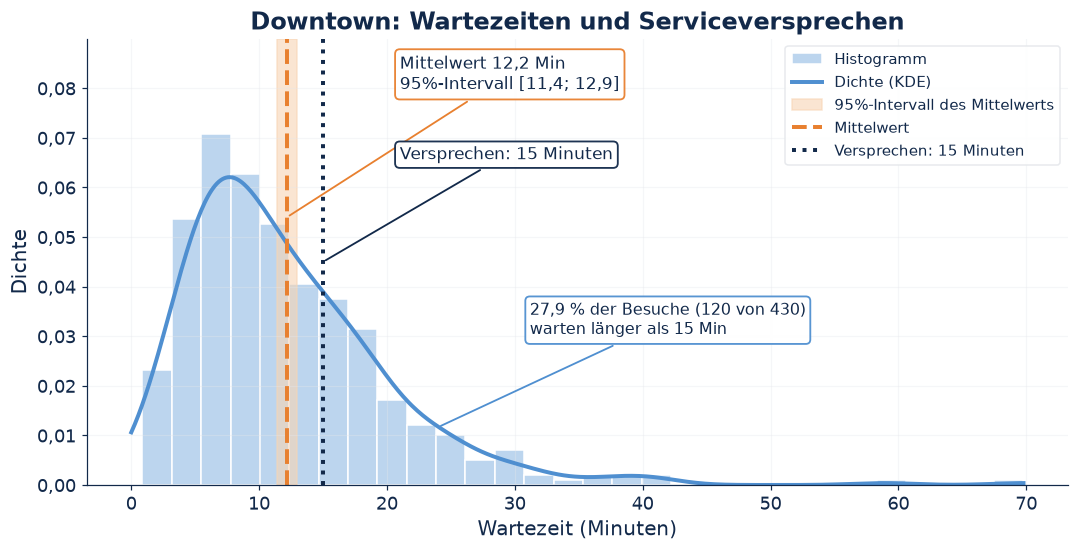

In [28]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.hist(dt, bins=30, density=True, color=PASTEL["blau"], edgecolor="white", label="Histogramm")
xs = np.linspace(0, dt.max(), 500); kde = stats.gaussian_kde(dt)(xs)
ax.plot(xs, kde, color=LINE["blau"], label="Dichte (KDE)")
ax.axvspan(ci_lo2, ci_hi2, color=PASTEL["rosa"], alpha=.6, label="95%-Intervall des Mittelwerts")
ax.axvline(xbar, color=LINE["rosa"], ls="--", label="Mittelwert")
ax.axvline(MU0, color=INK, ls=":", label="Versprechen: 15 Minuten")
ax.set_ylim(0, kde.max() * 1.45); yt = ax.get_ylim()[1]
tagd(ax, (xbar, yt * .60), (21, yt * .92), f"Mittelwert {xbar:.1f} Min\n95%-Intervall [{ci_lo2:.1f}; {ci_hi2:.1f}]", LINE["rosa"])
tagd(ax, (MU0, yt * .50), (21, yt * .74), "Versprechen: 15 Minuten", INK)
share = (dt > MU0).mean()
tag(ax, 24, kde[np.abs(xs - 24).argmin()], f"{share * 100:.1f} % der Besuche ({int((dt > MU0).sum())} von {n_d})\nwarten länger als 15 Min", LINE["blau"], ox=60, oy=70, ha="left", fs=10.5)
ax.set_title("Downtown: Wartezeiten und Serviceversprechen"); ax.set_xlabel("Wartezeit (Minuten)"); ax.set_ylabel("Dichte")
ax.legend(loc="upper right", fontsize=10); plt.tight_layout(); show()

**Aussage:** Der Durchschnitt von Downtown (12,2 Minuten) liegt mit seinem ganzen Intervall links von 15 Minuten, 27,9 Prozent der einzelnen Besuche (120 von 430) überschreiten die 15 Minuten aber.

In [29]:
# Was ändert alpha = 0,05 gegenüber 0,01? Kritische Werte (einseitig, links) für t- und Normalverteilung
rows = []
for alpha in (0.05, 0.01):
    rows.append({"alpha": alpha, "kritischer t-Wert (df=429)": round(stats.t.ppf(alpha, dfree), 3),
                 "kritischer z-Wert (Normal)": round(stats.norm.ppf(alpha), 3),
                 "beobachtetes t": round(t_stat, 2), "p kleiner als alpha?": bool(p_one < alpha)})
pd.DataFrame(rows)

,alpha,kritischer t-Wert (df=429),kritischer z-Wert (Normal),beobachtetes t,p kleiner als alpha?
0,"0,05","-1,648","-1,645","-7,20",True
1,"0,01","-2,335","-2,326","-7,20",True


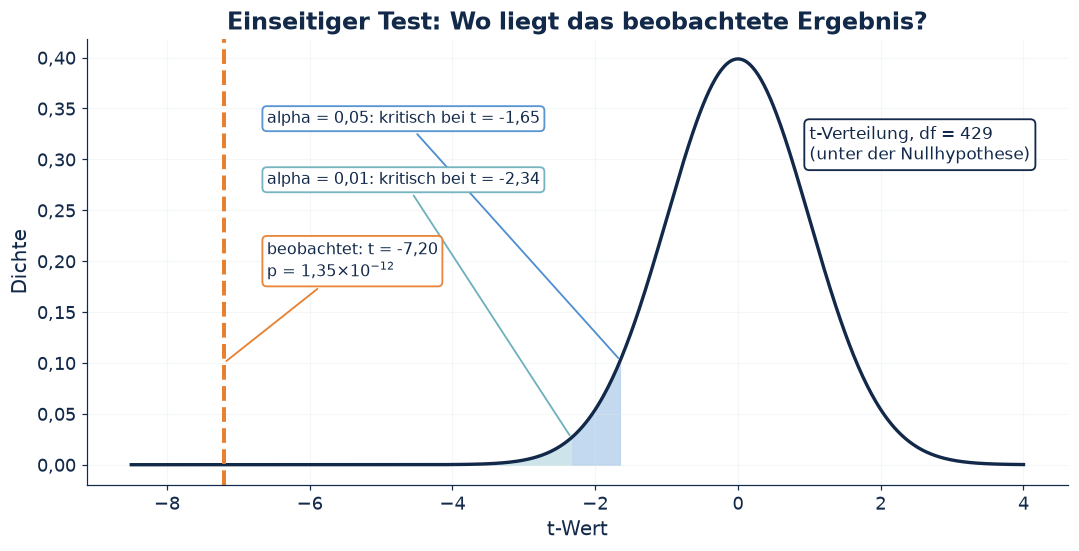

In [30]:
xs = np.linspace(-8.5, 4, 600)
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(xs, stats.t.pdf(xs, dfree), color=INK, lw=2.2, label=f"t-Verteilung, df = {dfree} (unter der Nullhypothese)")
for alpha, cl, ty in [(0.05, "blau", .34), (0.01, "pfirsich", .28)]:
    tc = stats.t.ppf(alpha, dfree); m_ = xs <= tc
    ax.fill_between(xs[m_], stats.t.pdf(xs[m_], dfree), color=PASTEL[cl], alpha=.9, label=f"Ablehnungsbereich alpha = {alpha}")
    tagd(ax, (tc, stats.t.pdf(tc, dfree)), (-6.6, ty), f"alpha = {alpha}: kritisch bei t = {tc:.2f}", LINE[cl], fs=10.5)
ax.axvline(t_stat, color=LINE["rosa"], ls="--", label="beobachtetes t")
mant, ex = f"{p_one:.2e}".split("e")
tagd(ax, (t_stat, .10), (-6.6, .20), f"beobachtet: t = {t_stat:.2f}\np = {mant}" + r"$\times 10^{" + str(int(ex)) + r"}$", LINE["rosa"], fs=10.5)
ax.set_title("Einseitiger Test: Wo liegt das beobachtete Ergebnis?"); ax.set_xlabel("t-Wert"); ax.set_ylabel("Dichte")
ax.text(1.0, .30, "t-Verteilung, df = 429\n(unter der Nullhypothese)", fontsize=11, color=INK, bbox=dict(boxstyle="round,pad=.3", fc="white", ec=INK, lw=1.2))
plt.tight_layout(); show()

**Aussage:** Das beobachtete Ergebnis liegt weit außerhalb beider Ablehnungsbereiche, die Wahl zwischen 0,05 und 0,01 ändert hier nichts.

### Annahmen-Check: Darf man hier einen t-Test verwenden?

Der t-Test setzt voraus, dass der **Mittelwert** der Stichprobe annähernd normalverteilt ist, nicht dass die einzelnen Wartezeiten es sind. Beides wird geprüft.

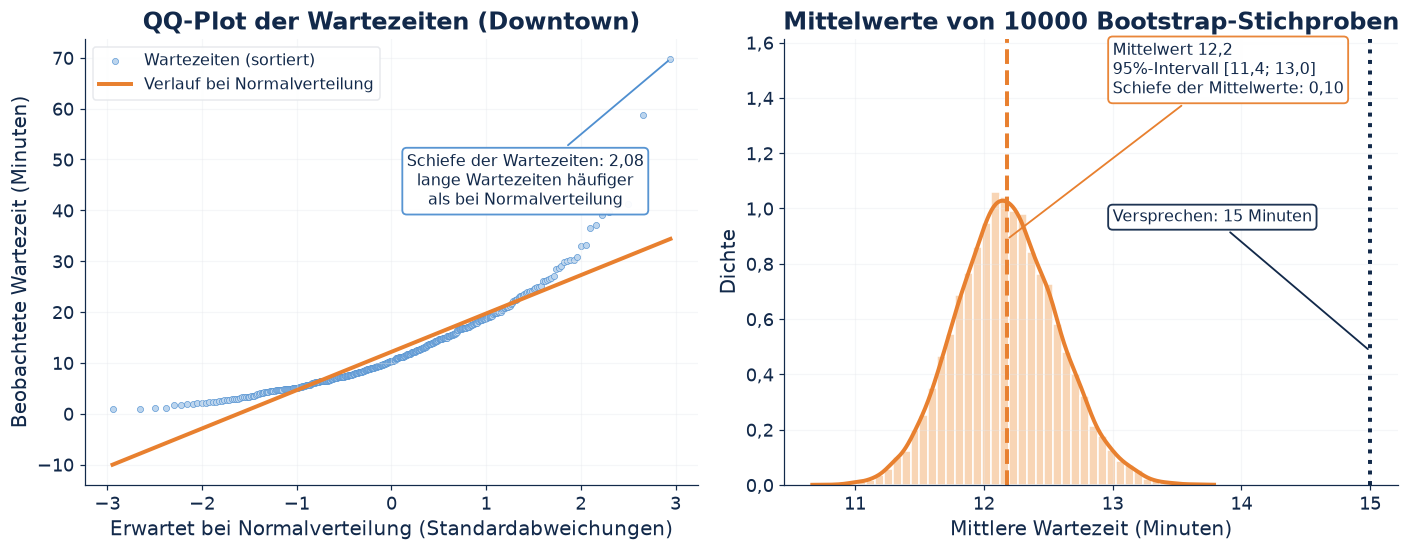

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
(osm, osr), (slope_, icpt_, _) = stats.probplot(dt, dist="norm")
ax[0].scatter(osm, osr, s=16, color=PASTEL["blau"], edgecolor=LINE["blau"], linewidth=.4, label="Wartezeiten (sortiert)")
ax[0].plot(osm, slope_ * osm + icpt_, color=LINE["rosa"], label="Verlauf bei Normalverteilung")
ax[0].set_title("QQ-Plot der Wartezeiten (Downtown)"); ax[0].set_xlabel("Erwartet bei Normalverteilung (Standardabweichungen)")
ax[0].set_ylabel("Beobachtete Wartezeit (Minuten)"); ax[0].legend(loc="upper left", fontsize=10.5)
tag(ax[0], osm[-1], osr[-1], f"Schiefe der Wartezeiten: {dt.skew():.2f}\nlange Wartezeiten häufiger\nals bei Normalverteilung", LINE["blau"], ox=-95, oy=-80, fs=10.5)

boot_means = rng.choice(dt.values, (10_000, n_d)).mean(axis=1)
bl, bh = np.percentile(boot_means, [2.5, 97.5])
ax[1].hist(boot_means, bins=45, density=True, color=PASTEL["rosa"], edgecolor="white", label="10000 Bootstrap-Mittelwerte")
xs_ = np.linspace(boot_means.min(), boot_means.max(), 400)
ax[1].plot(xs_, stats.gaussian_kde(boot_means)(xs_), color=LINE["rosa"], label="Dichte (KDE)")
ax[1].axvline(MU0, color=INK, ls=":"); ax[1].axvline(xbar, color=LINE["rosa"], ls="--")
ax[1].set_ylim(0, ax[1].get_ylim()[1] * 1.45); yt_ = ax[1].get_ylim()[1]
tagd(ax[1], (xbar, yt_ * .55), (13.0, yt_ * .93), f"Mittelwert {xbar:.1f}\n95%-Intervall [{bl:.1f}; {bh:.1f}]\nSchiefe der Mittelwerte: {stats.skew(boot_means):.2f}", LINE["rosa"], fs=10.5)
tagd(ax[1], (MU0, yt_ * .30), (13.0, yt_ * .60), "Versprechen: 15 Minuten", INK, fs=10.5)
ax[1].set_title("Mittelwerte von 10000 Bootstrap-Stichproben"); ax[1].set_xlabel("Mittlere Wartezeit (Minuten)"); ax[1].set_ylabel("Dichte")
plt.tight_layout(); show()

**Aussage:** Die einzelnen Wartezeiten sind deutlich schief (der QQ-Plot krümmt sich nach oben), die Mittelwerte wiederholter Stichproben sind dagegen fast symmetrisch und liegen komplett links von 15 Minuten, deshalb ist der t-Test bei 430 Besuchen verlässlich.

## Antworten Checkpoint 2

**Hypothesen.** Die Nullhypothese lautet: Patienten in Downtown warten im Durchschnitt 15 Minuten oder länger, das Versprechen gilt also nicht. Die Alternativhypothese lautet: Sie warten im Durchschnitt weniger als 15 Minuten. Der Test schützt die Nullhypothese: Sie bleibt gültig, bis die Daten deutlich dagegen sprechen. So wird das Versprechen nicht vorschnell als erfüllt gefeiert, die Beweislast liegt beim Versprechen.

**Was 0,05 bedeutet und was 0,01 ändern würde.** Mit dem Signifikanzniveau α = 0,05 nehmen wir in Kauf, dass wir in höchstens 5 von 100 Fällen „Versprechen eingehalten“ sagen, obwohl die durchschnittliche Wartezeit in Wahrheit bei 15 Minuten oder darüber liegt. Mit 0,01 wäre es höchstens 1 von 100. Die Schwelle wird strenger (kritischer t-Wert minus 2,34 statt minus 1,65), die Daten müssen also deutlicher sprechen. Der Preis dafür ist, dass wir ein tatsächlich eingehaltenes Versprechen leichter übersehen. Bei diesen Daten ändert sich nichts, weil das beobachtete t von minus 7,2 jenseits beider Schwellen liegt.

**Verteilung und Freiheitsgrade.** Verwendet wird die t-Verteilung. Die Normalverteilung würde voraussetzen, dass wir die wahre Streuung der Wartezeiten kennen. Wir schätzen sie aber aus den 430 Besuchen, und diese Schätzung bringt zusätzliche Unsicherheit mit, die die t-Verteilung über breitere Ränder berücksichtigt. Die 429 Freiheitsgrade sind 430 Besuche minus 1, weil der Mittelwert schon aus denselben Daten stammt. Sie bestimmen, wie stark die t-Verteilung von der Normalverteilung abweicht. Bei 429 ist der Unterschied winzig (minus 1,648 gegenüber minus 1,645), die t-Verteilung bleibt trotzdem die korrekte Wahl. Dass die Stichprobenmittelwerte trotz schiefer Einzelwerte näherungsweise normalverteilt sind, folgt bei n = 430 aus dem zentralen Grenzwertsatz.

**Warum einseitig.** Die Frage lautet nur, ob die Wartezeit kürzer als 15 Minuten ist. Eine längere Wartezeit ist keine zweite interessante Möglichkeit, sondern das Gegenteil des Versprechens. Der gesamte Ablehnungsbereich gehört deshalb auf die Seite, die das Versprechen stützt. Ein zweiseitiger p-Wert (2,7 statt 1,35, jeweils mal 10 hoch minus 12) wäre falsch gewesen: Er prüft zusätzlich eine Richtung, nach der niemand gefragt hat, und beantwortet die Frage „ist die Wartezeit anders als 15 Minuten?“ statt „ist sie kürzer?“. Hier ändert es die Schlussfolgerung nicht, es ist trotzdem eine andere Frage.

**Was der Test belegt und was nicht.** Belegt ist, dass die durchschnittliche Wartezeit in Downtown unter 15 Minuten liegt (Mittelwert 12,2, Intervall 11,4 bis 12,9 Minuten). Nicht belegt ist, dass jeder einzelne Patient weniger als 15 Minuten wartet, denn viele einzelne Wartezeiten liegen darüber. Der Test sagt auch nichts über andere Standorte oder andere Zeiträume.

**Testentscheidung (formal).** Geprüft wird H₀: μ ≥ 15 Minuten gegen H₁: μ < 15 Minuten. Der einseitige t-Test ergibt t(429) = −7,20 und p = 1,35 × 10⁻¹². Die Nullhypothese wird bei α = 0,05 und auch bei α = 0,01 verworfen. Das 95-%-Konfidenzintervall des Mittelwerts [11,4; 12,9] enthält ausschließlich Werte unter 15 Minuten und ist damit mit der Alternativhypothese vereinbar. Unter den Testannahmen (unabhängige Besuche, näherungsweise normalverteilte Stichprobenmittelwerte) sprechen die Daten dafür, dass die mittlere Wartezeit in Downtown in der Grundgesamtheit unter 15 Minuten liegt.

# Checkpoint 3: Einen zweiseitigen Vergleich lesen (Riverside gegen Downtown)

**Frage:** Unterscheidet sich die durchschnittliche Wartezeit in Riverside von der in Downtown?

## 3.1 Die Standorte im Überblick

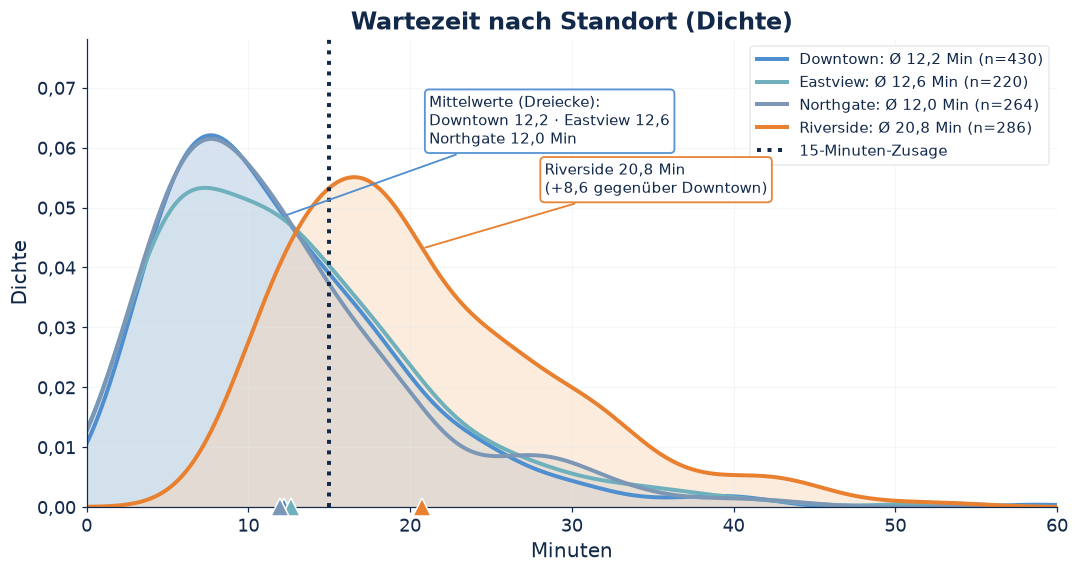

In [32]:
xs = np.linspace(0, 60, 500)
fig, ax = plt.subplots(figsize=(10, 5.4))
for site in SITE_ORDER:
    w_ = df.loc[df.clinic_site == site, "wait_time_min"]; k_ = stats.gaussian_kde(w_)(xs)
    ax.fill_between(xs, k_, color=PASTEL[SITE_COL[site]], alpha=.45)
    ax.plot(xs, k_, color=LINE[SITE_COL[site]], label=f"{site}: Ø {w_.mean():.1f} Min (n={len(w_)})")
    ax.plot(w_.mean(), 0, marker="^", ms=12, color=LINE[SITE_COL[site]], markeredgecolor="white", clip_on=False, zorder=5)
ax.axvline(15, color=INK, ls=":", label="15-Minuten-Zusage")
ax.set_ylim(0, ax.get_ylim()[1] * 1.2)
mm = {s_: df.loc[df.clinic_site == s_, "wait_time_min"].mean() for s_ in SITE_ORDER}
kd = stats.gaussian_kde(df.loc[df.clinic_site == "Downtown", "wait_time_min"])
tag(ax, 12.2, kd(12.2)[0], f"Mittelwerte (Dreiecke):\nDowntown {mm['Downtown']:.1f} · Eastview {mm['Eastview']:.1f}\nNorthgate {mm['Northgate']:.1f} Min", LINE["blau"], ox=95, oy=62, ha="left", fs=10)
kr = stats.gaussian_kde(df.loc[df.clinic_site == "Riverside", "wait_time_min"])
tag(ax, mm["Riverside"], kr(mm["Riverside"])[0], f"Riverside {mm['Riverside']:.1f} Min\n(+{mm['Riverside'] - mm['Downtown']:.1f} gegenüber Downtown)", LINE["rosa"], ox=80, oy=45, ha="left", fs=10)
ax.set_title("Wartezeit nach Standort (Dichte)"); ax.set_xlabel("Minuten"); ax.set_ylabel("Dichte")
ax.set_xlim(0, 60); ax.legend(loc="upper right", fontsize=10); plt.tight_layout(); show()

**Aussage:** Drei Standorte liegen fast deckungsgleich bei etwa 12 Minuten, Riverside ist als Ganzes nach rechts verschoben (Ø 20,8 Minuten).

**Lesart:** Die Mittelwerte von Downtown, Eastview und Northgate liegen mit 12,2, 12,6 und 12,0 Minuten fast gleichauf, die Mediane bei 10,2 bis 11,3 Minuten. Riverside liegt mit 20,8 Minuten (Median 18,8) etwa 8 bis 9 Minuten darüber. Die Verschiebung betrifft damit die ganze Verteilung und nicht nur den Schwanz.

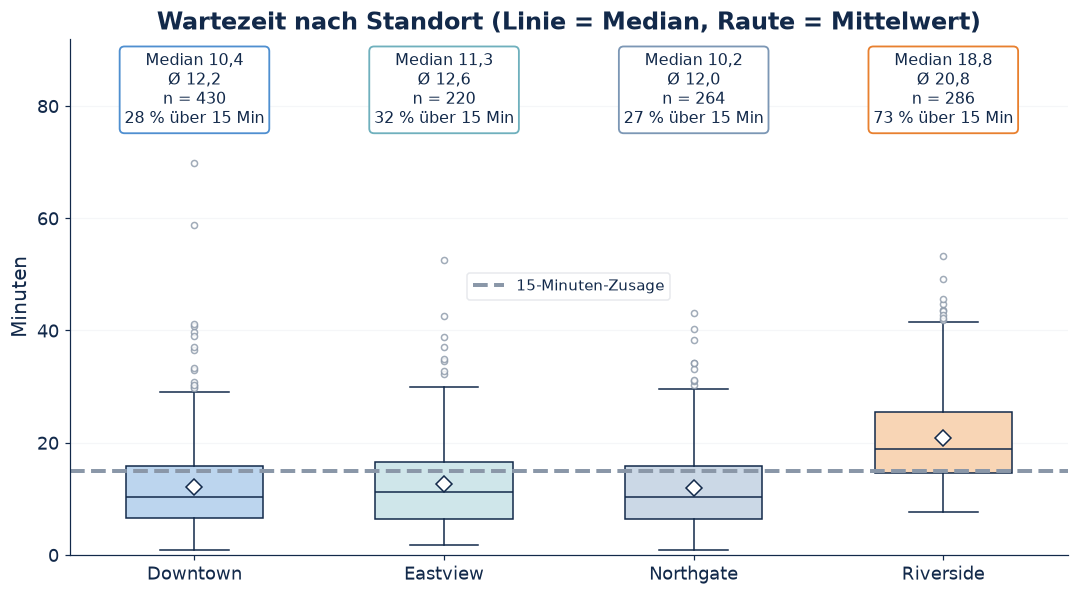

In [33]:
fig, ax = plt.subplots(figsize=(10, 5.6))
data = [df.loc[df.clinic_site == s_, "wait_time_min"] for s_ in SITE_ORDER]
bp = ax.boxplot(data, tick_labels=SITE_ORDER, patch_artist=True, showmeans=True, widths=.55,
                medianprops=dict(color=INK), whiskerprops=dict(color=INK), capprops=dict(color=INK),
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=INK, markersize=7),
                flierprops=dict(marker="o", markerfacecolor="white", markeredgecolor=LINE["grau"], markersize=4, alpha=.8))
for patch, s_ in zip(bp["boxes"], SITE_ORDER):
    patch.set_facecolor(PASTEL[SITE_COL[s_]]); patch.set_edgecolor(INK)
ax.axhline(15, color=LINE["grau"], ls="--", label="15-Minuten-Zusage")
ax.set_ylim(0, 92)
for i, d_ in enumerate(data, start=1):
    ax.text(i, 76, f"Median {d_.median():.1f}\nØ {d_.mean():.1f}\nn = {len(d_)}\n{100 * (d_ > 15).mean():.0f} % über 15 Min",
            ha="center", va="bottom", fontsize=10.5, color=INK, bbox=dict(boxstyle="round,pad=.3", fc="white", ec=LINE[SITE_COL[SITE_ORDER[i - 1]]], lw=1.2))
ax.set_title("Wartezeit nach Standort (Linie = Median, Raute = Mittelwert)"); ax.set_ylabel("Minuten")
ax.legend(loc="center", bbox_to_anchor=(.5, .52), fontsize=10); ax.grid(axis="x", visible=False); plt.tight_layout(); show()

**Aussage:** Die mittlere Hälfte der Besuche in Riverside liegt fast vollständig über dem Median der anderen drei Standorte, und 73 Prozent der Riverside-Besuche warten über 15 Minuten gegenüber etwa 27 bis 32 Prozent an den anderen Standorten.

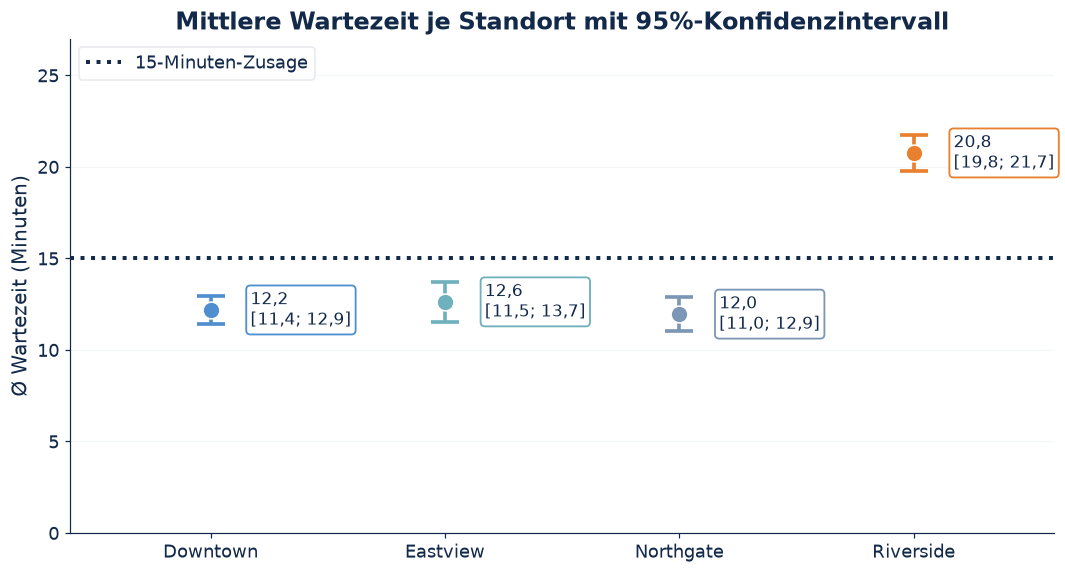

In [34]:
fig, ax = plt.subplots(figsize=(10, 5.4))
for i, site in enumerate(SITE_ORDER):
    m_, lo_, hi_ = mean_ci(df.loc[df.clinic_site == site, "wait_time_min"])
    ax.errorbar(i, m_, yerr=[[m_ - lo_], [hi_ - m_]], fmt="o", color=LINE[SITE_COL[site]], ms=11, markeredgecolor="white",
                capsize=9, elinewidth=2.4, capthick=2.4)
    ax.annotate(f"{m_:.1f}\n[{lo_:.1f}; {hi_:.1f}]", (i, m_), xytext=(i + .17, m_), textcoords="data", ha="left", va="center", fontsize=11, color=INK,
                bbox=dict(boxstyle="round,pad=.25", fc="white", ec=LINE[SITE_COL[site]], lw=1.2))
ax.axhline(15, color=INK, ls=":", label="15-Minuten-Zusage")
ax.set_xticks(range(4)); ax.set_xticklabels(SITE_ORDER); ax.set_xlim(-.6, 3.6); ax.set_ylim(0, 27)
ax.set_ylabel("Ø Wartezeit (Minuten)"); ax.set_title("Mittlere Wartezeit je Standort mit 95%-Konfidenzintervall")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False); plt.tight_layout(); show()

**Aussage:** Die Mittelwert-Intervalle der drei Standorte Downtown, Eastview und Northgate überlappen sich und liegen links von 15 Minuten, das Intervall von Riverside liegt komplett rechts davon.

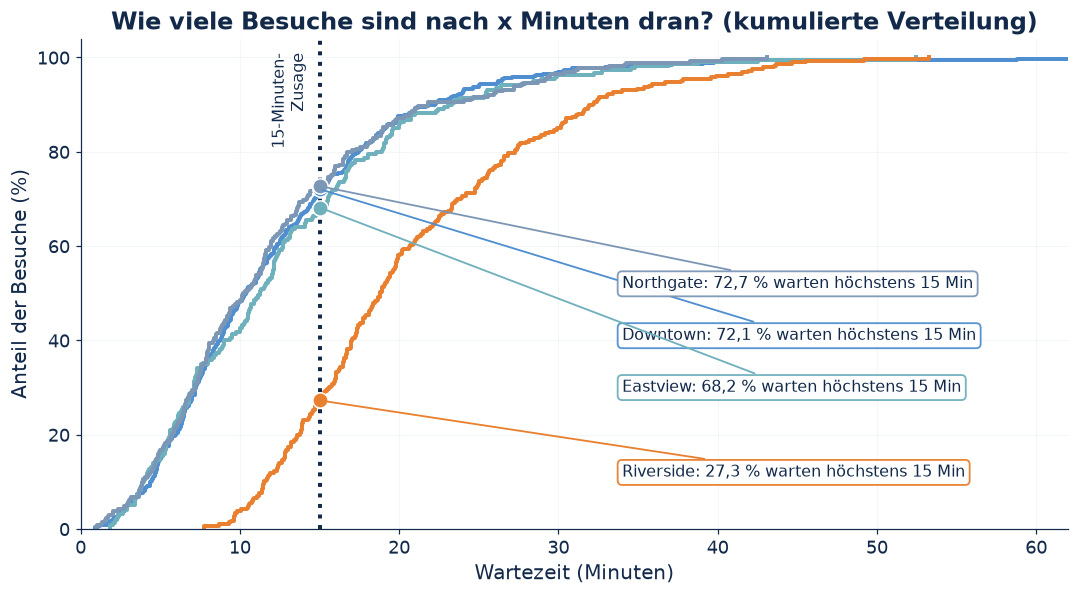

In [35]:
fig, ax = plt.subplots(figsize=(10, 5.6))
ylab = {"Northgate": 52, "Downtown": 41, "Eastview": 30, "Riverside": 12}
for site in SITE_ORDER:
    w_ = np.sort(df.loc[df.clinic_site == site, "wait_time_min"].values); yv = np.arange(1, len(w_) + 1) / len(w_) * 100
    ax.step(w_, yv, where="post", color=LINE[SITE_COL[site]], label=site)
    p15 = (w_ <= 15).mean() * 100
    ax.plot(15, p15, "o", color=LINE[SITE_COL[site]], ms=10, markeredgecolor="white", zorder=5)
    tagd(ax, (15, p15), (34, ylab[site]), f"{site}: {p15:.1f} % warten höchstens 15 Min", LINE[SITE_COL[site]], fs=10.5)
ax.axvline(15, color=INK, ls=":")
ax.text(14.3, 101, "15-Minuten-\nZusage", rotation=90, ha="right", va="top", fontsize=10.5, color=INK)
ax.set_ylim(0, 104); ax.set_xlim(0, 62)
ax.set_title("Wie viele Besuche sind nach x Minuten dran? (kumulierte Verteilung)"); ax.set_xlabel("Wartezeit (Minuten)")
ax.set_ylabel("Anteil der Besuche (%)"); plt.tight_layout(); show()

**Aussage:** Nach 15 Minuten sind in Downtown, Eastview und Northgate rund 68 bis 73 Prozent der Besuche dran, in Riverside nur 27 Prozent.

**Lesart:** Umgekehrt gelesen: In Riverside warten 72,7 Prozent länger als 15 Minuten, in Downtown 27,9, in Eastview 31,8 und in Northgate 27,3 Prozent. Das Serviceversprechen von 15 Minuten hält Riverside damit bei gut jedem vierten Besuch, die anderen drei Standorte bei etwa sieben von zehn.

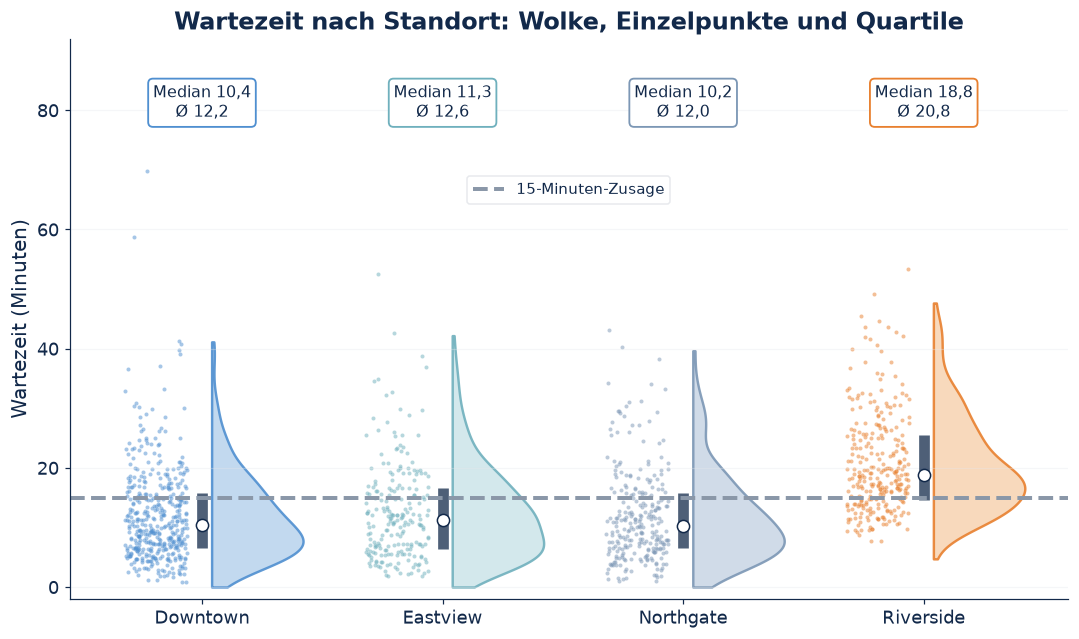

In [36]:
fig, ax = plt.subplots(figsize=(10, 6))
for i, site in enumerate(SITE_ORDER):
    w_ = df.loc[df.clinic_site == site, "wait_time_min"]; col = SITE_COL[site]
    ys = np.linspace(max(w_.min() - 3, 0), w_.quantile(.995), 300)
    k_ = stats.gaussian_kde(w_)(ys); k_ = k_ / k_.max() * .38
    ax.fill_betweenx(ys, i + .04, i + .04 + k_, color=PASTEL[col], edgecolor=LINE[col], alpha=.9, lw=1.6)
    ax.scatter(i - .06 - np.random.default_rng(SEED + i).uniform(0, .26, len(w_)), w_, s=7, alpha=.5, color=LINE[col], linewidths=0)
    q1_, md_, q3_ = w_.quantile([.25, .5, .75])
    ax.plot([i, i], [q1_, q3_], color=INK, lw=7, solid_capstyle="butt", alpha=.75)
    ax.plot(i, md_, "o", color="white", ms=8, markeredgecolor=INK, zorder=5)
    ax.text(i, 78, f"Median {md_:.1f}\nØ {w_.mean():.1f}", ha="center", va="bottom", fontsize=10.5, color=INK,
            bbox=dict(boxstyle="round,pad=.3", fc="white", ec=LINE[col], lw=1.2))
ax.axhline(15, color=LINE["grau"], ls="--", label="15-Minuten-Zusage")
ax.set_xticks(range(4)); ax.set_xticklabels(SITE_ORDER); ax.set_xlim(-.55, 3.6); ax.set_ylim(-2, 92)
ax.set_title("Wartezeit nach Standort: Wolke, Einzelpunkte und Quartile"); ax.set_ylabel("Wartezeit (Minuten)")
ax.legend(loc="center", bbox_to_anchor=(.5, .73), fontsize=10); ax.grid(axis="x", visible=False); plt.tight_layout(); show()

**Aussage:** Die Einzelpunkte zeigen, dass Riverside nicht von wenigen Ausreißern lebt: Fast die gesamte Wolke liegt höher als bei den anderen drei Standorten (weißer Punkt = Median, dicker Strich = mittlere Hälfte der Besuche).

## 3.2 Der Welch-Test

In [37]:
rv = df.loc[df.clinic_site == "Riverside", "wait_time_min"].dropna()
dw = dt                                           # Downtown aus Checkpoint 2
n1, n2 = len(rv), len(dw); m1, m2 = rv.mean(), dw.mean(); s1, s2_ = rv.std(ddof=1), dw.std(ddof=1)

diff = m1 - m2
se_w = np.sqrt(s1**2 / n1 + s2_**2 / n2)
df_w = welch_df(rv, dw)
t_w = diff / se_w
p_w = 2 * stats.t.sf(abs(t_w), df_w)

w_res = stats.ttest_ind(rv, dw, equal_var=False)
assert np.isclose(w_res.statistic, t_w) and np.isclose(w_res.pvalue, p_w)         # Handrechnung = scipy

ci_lo, ci_hi = diff + np.array([-1, 1]) * stats.t.ppf(0.975, df_w) * se_w
sp = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2_**2) / (n1 + n2 - 2))
d_cohen = diff / sp
se_dc = np.sqrt((n1 + n2) / (n1 * n2) + d_cohen**2 / (2 * (n1 + n2)))
d_lo, d_hi = d_cohen - 1.96 * se_dc, d_cohen + 1.96 * se_dc

print(f"Riverside: n={n1}, Ø={m1:.2f}, SD={s1:.2f} | Downtown: n={n2}, Ø={m2:.2f}, SD={s2_:.2f}")
print(f"Differenz = {diff:.2f} Min | 95%-KI: {ci_lo:.2f} bis {ci_hi:.2f}")
print(f"Welch-t = {t_w:.2f}, df = {df_w:.1f}, p = {p_w:.1e}")
print(f"Cohens d = {d_cohen:.2f} (95%-KI {d_lo:.2f} bis {d_hi:.2f})")

st = stats.ttest_ind(rv, dw, equal_var=True)
print(f"\nZum Vergleich Standard-t-Test: t = {st.statistic:.2f}, df = {n1 + n2 - 2}, p = {st.pvalue:.1e}")
print(f"Streuungsverhältnis Riverside/Downtown: {s1 / s2_:.2f} | Levene-Test p = {stats.levene(rv, dw).pvalue:.3f}")

Riverside: n=286, Ø=20,76, SD=8,40 | Downtown: n=430, Ø=12,18, SD=8,12
Differenz = 8,58 Min | 95%-KI: 7,33 bis 9,82
Welch-t = 13,56, df = 596,8, p = 1,0e-36
Cohens d = 1,04 (95%-KI 0,88 bis 1,20)

Zum Vergleich Standard-t-Test: t = 13,65, df = 714, p = 7,2e-38
Streuungsverhältnis Riverside/Downtown: 1,03 | Levene-Test p = 0,175


In [38]:
def welch_summary(frame, label):
    r_ = frame.loc[frame.clinic_site == "Riverside", "wait_time_min"].dropna()
    d_ = frame.loc[frame.clinic_site == "Downtown", "wait_time_min"].dropna()
    t_ = stats.ttest_ind(r_, d_, equal_var=False)
    sp_ = np.sqrt(((len(r_) - 1) * r_.var() + (len(d_) - 1) * d_.var()) / (len(r_) + len(d_) - 2))
    print(f"{label}: n Riverside={len(r_)}, Differenz={r_.mean() - d_.mean():.2f}, t={t_.statistic:.2f}, p={t_.pvalue:.1e}, d={(r_.mean() - d_.mean()) / sp_:.2f}")
welch_summary(raw, "Rohdaten   ")
welch_summary(df,  "Bereinigt  ")

Rohdaten   : n Riverside=290, Differenz=8,54, t=13,51, p=1,6e-36, d=1,03
Bereinigt  : n Riverside=286, Differenz=8,58, t=13,56, p=1,0e-36, d=1,04


**Abgleich:** Auf den Rohdaten (n = 290 für Riverside) ergibt sich eine Differenz von 8,54 Minuten und t = 13,51, auf den bereinigten Daten 8,58 Minuten und t = 13,56. Der Unterschied betrifft nur die Nachkommastellen, die Aussage ist identisch.

**Welcher Fehler wird hier kontrolliert?**

- **Fehler 1. Art (falscher Alarm):** Wir behaupten einen Unterschied, den es nicht gibt. Dieses Risiko legt Alpha = 0,05 fest. Bei p ≈ 1e-36 ist es praktisch ausgeschlossen, dass 8,6 Minuten Zufall sind.
- **Fehler 2. Art (verpasster Unterschied):** Wir übersehen einen echten Unterschied. Das kontrolliert die Teststärke, nicht Alpha. Mit n = 286 und 430 und diesen Streuungen erkennt der Test bei 80 % Power Unterschiede ab etwa 1,8 Minuten (minimal nachweisbarer Effekt). Der beobachtete Unterschied ist fast fünfmal so groß.
- **Warum zweiseitig:** Beide Richtungen wären eine Entscheidung wert, ein deutlich kürzeres Warten in Riverside genauso wie ein längeres.

## 3.3 Praktische Relevanz statt nur Signifikanz

Der Schwellenwert für „handlungsrelevant“ wird **vor der Interpretation** der Intervalle festgelegt und begründet (siehe Entscheidung 2). Er wurde erst nach dem Welch-Test gewählt und ist deshalb keine ursprüngliche Vorabfestlegung. Die Robustheitsprüfung weiter unten zeigt, ob die Aussage von dieser Wahl abhängt. 

In [39]:
BUSINESS_THRESHOLD_MIN = 5          # Differenz in Minuten, ab der die Operations-Leitung handeln würde (fachliche Setzung, siehe Entscheidung 2)

B = 10_000                          # Bootstrap: Verteilung der Differenz ohne Normalitätsannahme
boot_diff = rng.choice(rv.values, (B, n1)).mean(axis=1) - rng.choice(dw.values, (B, n2)).mean(axis=1)
boot_lo, boot_hi = np.percentile(boot_diff, [2.5, 97.5])
print(f"Bootstrap-95%-Intervall der Differenz: {boot_lo:.2f} bis {boot_hi:.2f} Min (Welch: {ci_lo:.2f} bis {ci_hi:.2f})")

mw = stats.mannwhitneyu(rv, dw, alternative="two-sided")
prob_sup = mw.statistic / (n1 * n2)
print(f"Mann-Whitney-U: p = {mw.pvalue:.1e} | Wahrscheinlichkeit, dass eine zufällige Riverside-Wartezeit länger ist als eine zufällige Downtown-Wartezeit: {prob_sup:.2f}")

mde = (stats.norm.ppf(.975) + stats.norm.ppf(.80)) * se_w
print(f"Kleinste mit 80 % Power erkennbare Differenz bei diesen Stichproben: {mde:.2f} Min")
print("Untere Intervallgrenze über der Schwelle?", bool(ci_lo > BUSINESS_THRESHOLD_MIN))

Bootstrap-95%-Intervall der Differenz: 7,34 bis 9,81 Min (Welch: 7,33 bis 9,82)
Mann-Whitney-U: p = 2,3e-43 | Wahrscheinlichkeit, dass eine zufällige Riverside-Wartezeit länger ist als eine zufällige Downtown-Wartezeit: 0,80
Kleinste mit 80 % Power erkennbare Differenz bei diesen Stichproben: 1,77 Min
Untere Intervallgrenze über der Schwelle? True


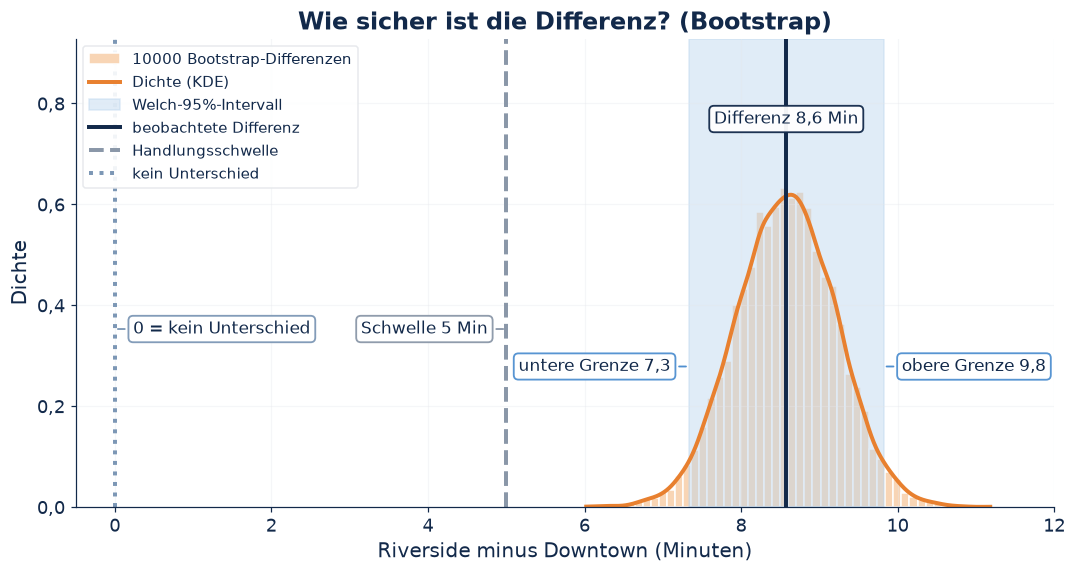

In [40]:
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.hist(boot_diff, bins=50, density=True, color=PASTEL["rosa"], edgecolor="white", label="10000 Bootstrap-Differenzen")
xs = np.linspace(boot_diff.min(), boot_diff.max(), 500); kd_ = stats.gaussian_kde(boot_diff)(xs)
ax.plot(xs, kd_, color=LINE["rosa"], label="Dichte (KDE)")
ax.axvspan(ci_lo, ci_hi, color=PASTEL["blau"], alpha=.45, label="Welch-95%-Intervall")
ax.axvline(diff, color=INK, label="beobachtete Differenz")
ax.axvline(BUSINESS_THRESHOLD_MIN, color=LINE["grau"], ls="--", label="Handlungsschwelle")
ax.axvline(0, color=LINE["gruen"], ls=":", label="kein Unterschied")
ax.set_xlim(-.5, 12); ax.set_ylim(0, kd_.max() * 1.5); yt = ax.get_ylim()[1]
tag(ax, diff, kd_.max(), f"Differenz {diff:.1f} Min", INK, oy=44, va="bottom", arrow=True)
tag(ax, ci_lo, yt * .30, f"untere Grenze {ci_lo:.1f}", LINE["blau"], ox=-12, ha="right")
tag(ax, ci_hi, yt * .30, f"obere Grenze {ci_hi:.1f}", LINE["blau"], ox=12, ha="left")
tag(ax, BUSINESS_THRESHOLD_MIN, yt * .38, f"Schwelle {BUSINESS_THRESHOLD_MIN} Min", LINE["grau"], ox=-12, ha="right")
tag(ax, 0, yt * .38, "0 = kein Unterschied", LINE["gruen"], ox=12, ha="left")
ax.set_title("Wie sicher ist die Differenz? (Bootstrap)"); ax.set_xlabel("Riverside minus Downtown (Minuten)"); ax.set_ylabel("Dichte")
ax.legend(loc="upper left", fontsize=10); plt.tight_layout(); show()

**Aussage:** Auch wiederholtes Neuziehen der Stichproben liefert nie eine Differenz in der Nähe von null oder von 5 Minuten, der Unterschied von etwa 8,6 Minuten ist stabil.

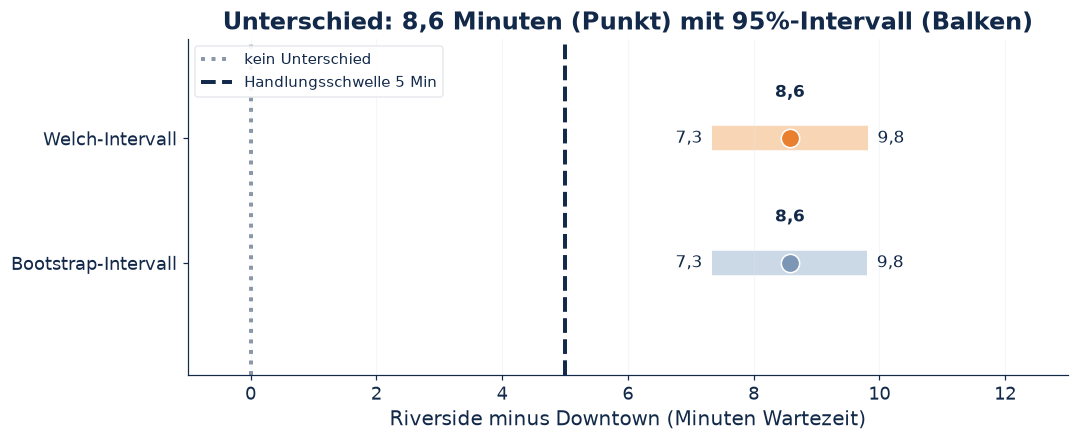

In [41]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for y, (lab, lo, hi, cl) in enumerate([("Bootstrap-Intervall", boot_lo, boot_hi, "gruen"), ("Welch-Intervall", ci_lo, ci_hi, "rosa")]):
    ax.hlines(y, lo, hi, color=PASTEL[cl], lw=16, zorder=1)
    ax.plot(diff, y, "o", color=LINE[cl], ms=12, markeredgecolor="white", zorder=2)
    ax.text(lo - .15, y, f"{lo:.1f}", ha="right", va="center", fontsize=11, color=INK)
    ax.text(hi + .15, y, f"{hi:.1f}", ha="left", va="center", fontsize=11, color=INK)
    ax.text(diff, y + .30, f"{diff:.1f}", ha="center", va="bottom", fontsize=11, color=INK, fontweight="bold")
ax.axvline(0, color=LINE["grau"], ls=":", label="kein Unterschied")
ax.axvline(BUSINESS_THRESHOLD_MIN, color=INK, ls="--", label=f"Handlungsschwelle {BUSINESS_THRESHOLD_MIN} Min")
ax.set_yticks([0, 1]); ax.set_yticklabels(["Bootstrap-Intervall", "Welch-Intervall"]); ax.set_ylim(-.9, 1.8); ax.set_xlim(-1, 13)
ax.set_xlabel("Riverside minus Downtown (Minuten Wartezeit)"); ax.set_title(f"Unterschied: {diff:.1f} Minuten (Punkt) mit 95%-Intervall (Balken)")
ax.legend(loc="upper left", fontsize=10); ax.grid(axis="y", visible=False); plt.tight_layout(); show()

**Aussage:** Selbst die untere Grenze beider Intervalle (etwa 7,3 Minuten) liegt über der Handlungsschwelle von 5 Minuten, der Unterschied ist also nicht nur zufällig, sondern auch groß genug zum Handeln.

## 3.4 Robustheit gegenüber den Datenentscheidungen aus Checkpoint 1

### Robustheit der Schwelle

Differenz 8,58 Min | Welch-Intervall [7,33; 9,82] | Bootstrap-Intervall [7,34; 9,81]
 Schwelle (Min) Differenz darüber? Untere Welch-Grenze darüber? Untere Bootstrap-Grenze darüber?
              3                 ja                           ja                               ja
              5                 ja                           ja                               ja
              7                 ja                           ja                               ja
             10               nein                         nein                             nein


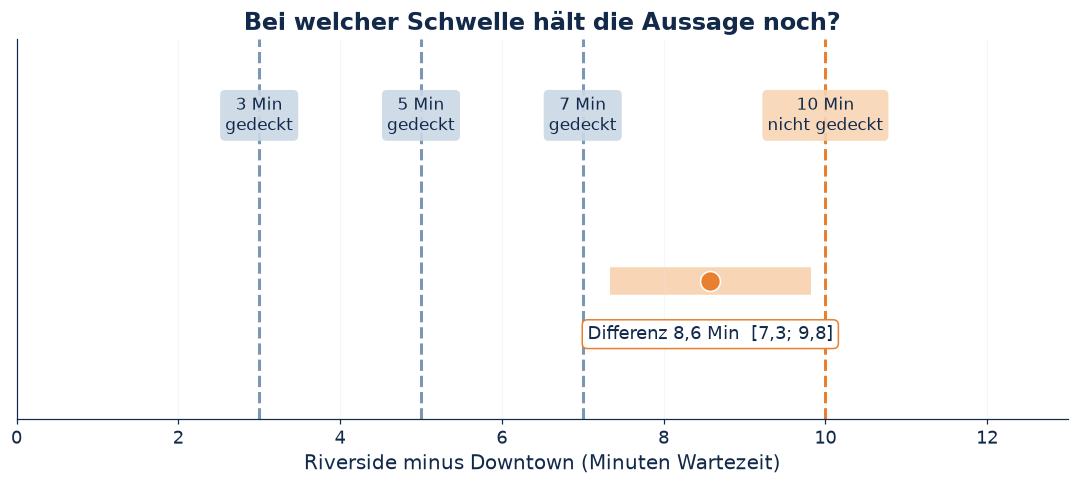

In [42]:
# Robustheit der Schwelle: Hält die Aussage auch bei anderen Schwellen?
SCHWELLEN = [3, 5, 7, 10]
sens_tab = pd.DataFrame({
    "Schwelle (Min)": SCHWELLEN,
    "Differenz darüber?": ["ja" if diff > s_ else "nein" for s_ in SCHWELLEN],
    "Untere Welch-Grenze darüber?": ["ja" if ci_lo > s_ else "nein" for s_ in SCHWELLEN],
    "Untere Bootstrap-Grenze darüber?": ["ja" if boot_lo > s_ else "nein" for s_ in SCHWELLEN],
})
print(f"Differenz {diff:.2f} Min | Welch-Intervall [{ci_lo:.2f}; {ci_hi:.2f}] | Bootstrap-Intervall [{boot_lo:.2f}; {boot_hi:.2f}]")
print(sens_tab.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.hlines(0, ci_lo, ci_hi, color=PASTEL["rosa"], lw=18, zorder=1)
ax.plot(diff, 0, "o", color=LINE["rosa"], ms=13, markeredgecolor="white", zorder=3)
ax.text(diff, -.32, f"Differenz {diff:.1f} Min  [{ci_lo:.1f}; {ci_hi:.1f}]", ha="center", va="top", fontsize=11.5, color=INK,
        bbox=dict(boxstyle="round,pad=.3", fc="white", ec=LINE["rosa"]))
for s_ in SCHWELLEN:
    ok = ci_lo > s_
    ax.axvline(s_, color=LINE["gruen"] if ok else LINE["rosa"], ls="--", lw=2)
    ax.text(s_, 1.05, f"{s_} Min\n{'gedeckt' if ok else 'nicht gedeckt'}", ha="center", va="bottom", fontsize=11, color=INK,
            bbox=dict(boxstyle="round,pad=.3", fc=PASTEL["gruen"] if ok else PASTEL["rosa"], ec="none", alpha=.9))
ax.set_xlim(0, 13); ax.set_ylim(-1.0, 1.75); ax.set_yticks([])
ax.set_xlabel("Riverside minus Downtown (Minuten Wartezeit)")
ax.set_title("Bei welcher Schwelle hält die Aussage noch?")
ax.grid(axis="y", visible=False); plt.tight_layout(); show()

**Aussage:** Die Aussage „Riverside wartet handlungsrelevant länger“ ist für Schwellen von 3, 5 und 7 Minuten durch die untere Intervallgrenze (7,3 Minuten) gedeckt, bei 10 Minuten nicht mehr, denn der beobachtete Unterschied beträgt nur 8,6 Minuten.

**Meine Entscheidung 2 (Schwelle für „handlungsrelevant“):**

Ich setze die Grenze für „handlungsrelevant“ bei einem Unterschied von fünf Minuten in der durchschnittlichen Wartezeit. Wer einen Termin vereinbart, geht davon aus, dass er eingehalten wird. Eine kleine Verzögerung ist aber vertretbar, weil im Betriebsablauf immer wieder Störungen vorkommen, zum Beispiel wenn ein vorheriger Patient zu spät kommt oder eine Untersuchung länger dauert als geplant. Fünf Minuten, ein Drittel des Serviceversprechens von 15 Minuten, halte ich noch für akzeptabel, ein größerer Unterschied fällt Patienten eher auf. Das Drittel ist eine Orientierung und kein Naturgesetz: Die Aussage hängt nicht an genau 5 Minuten, sie gilt unverändert für jede Schwelle bis 7,3 Minuten. Kleinere Abweichungen könnte man statistisch nachweisen, aber sie würden im Alltag nichts verändern. Diese Begründung ist fachlich und folgt nicht aus den Tests. Ich habe auch drei und zehn Minuten überlegt: Drei läge nur wenig über dem kleinsten Unterschied, den der Test sicher erkennt (1,8 Minuten), und würde schon alltägliche Verzögerungen als Handlungsbedarf zählen. Mit zehn wäre schon der beobachtete Unterschied von 8,6 Minuten nicht mehr relevant, die Schwelle würde dann das Ergebnis bestimmen statt der fachlichen Überlegung. Die Schwelle ist eine fachliche Einschätzung, keine mathematische Regel.

**Hinweis zur Reihenfolge:** Die Ergebnisse des Welch-Tests kannte ich zu dem Zeitpunkt schon. Deshalb prüfe ich zusätzlich, bei welchen Schwellen die Aussage hält (siehe Tabelle und Diagramm oben).

Zur Absicherung schaue ich auf die untere Grenze des 95-%-Intervalls (etwa 7,3 Minuten). Sie liegt noch klar über der Fünf-Minuten-Schwelle. Die Aussage „Riverside wartet handlungsrelevant länger“ gilt damit auch an dieser Grenze.

In [43]:
def run_tests(frame, label):
    d_ = frame.loc[frame.clinic_site == "Downtown", "wait_time_min"].dropna()
    r_ = frame.loc[frame.clinic_site == "Riverside", "wait_time_min"].dropna()
    p1 = stats.ttest_1samp(d_, MU0, alternative="less").pvalue
    df_ = welch_df(r_, d_); se_ = np.sqrt(r_.var(ddof=1) / len(r_) + d_.var(ddof=1) / len(d_))
    dif = r_.mean() - d_.mean(); h = stats.t.ppf(.975, df_) * se_
    return {"Variante": label, "n Downtown": len(d_), "Downtown Ø": round(d_.mean(), 2), "p (einseitig)": f"{p1:.1e}",
            "n Riverside": len(r_), "Differenz": round(dif, 2), "KI untere": round(dif - h, 2), "KI obere": round(dif + h, 2),
            "p (Welch)": f"{stats.ttest_ind(r_, d_, equal_var=False).pvalue:.1e}"}

hi_w = tukey(df.wait_time_min)[1]
variants = [("Rohdaten (mit Duplikaten)", raw), ("Bereinigt (Hauptanalyse)", df),
            ("Ohne No-Show-Zeilen", df[df.no_show == 0]),
            ("Ohne Wartezeit-Ausreißer (Tukey)", df[df.wait_time_min <= hi_w])]
robust = pd.DataFrame([run_tests(f, l) for l, f in variants])
de_df(robust)


,Variante,n Downtown,Downtown Ø,p (einseitig),n Riverside,Differenz,KI untere,KI obere,p (Welch)
0,Rohdaten (mit Duplikaten),430,"12,18","1,3e-12",290,"8,54","7,30","9,78","1,6e-36"
1,Bereinigt (Hauptanalyse),430,"12,18","1,3e-12",286,"8,58","7,33","9,82","1,0e-36"
2,Ohne No-Show-Zeilen,380,"11,91","4,4e-13",259,"8,83","7,51","10,16","4,3e-34"
3,Ohne Wartezeit-Ausreißer (Tukey),422,"11,55","2,8e-24",269,"7,85","6,85","8,86","1,1e-44"


Anteil Terminarten je Standort:
appointment_type  Checkup  Follow-up  Specialist  Urgent
clinic_site                                             
Downtown             0,45       0,28        0,09    0,18
Eastview             0,43       0,25        0,12    0,20
Northgate            0,34       0,36        0,11    0,18
Riverside            0,38       0,27        0,12    0,22 

Ø Wartezeit je Standort und Terminart (Minuten):
appointment_type  Checkup  Follow-up  Specialist  Urgent
clinic_site                                             
Downtown            13,30      10,20       12,40   12,30
Eastview            12,00      13,50       13,70   12,30
Northgate           11,90      11,10       12,10   13,60
Riverside           21,30      20,50       19,90   20,60


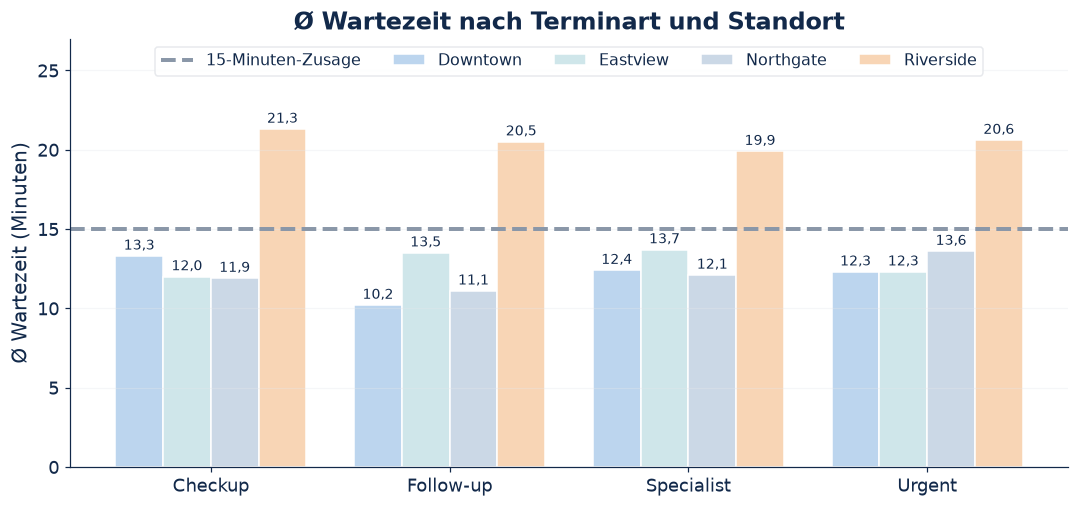

In [44]:
# Ist die Terminart-Mischung eine Erklärung für den Standortunterschied?
print("Anteil Terminarten je Standort:")
print(pd.crosstab(df.clinic_site, df.appointment_type, normalize="index").round(2), "\n")
by_type = df.pivot_table(index="clinic_site", columns="appointment_type", values="wait_time_min", aggfunc="mean").round(1)
print("Ø Wartezeit je Standort und Terminart (Minuten):"); print(by_type)

fig, ax = plt.subplots(figsize=(10, 4.8))
xpos = np.arange(len(by_type.columns)); wd = .2
for i, site in enumerate(SITE_ORDER):
    bars_ = ax.bar(xpos + (i - 1.5) * wd, by_type.loc[site].values, width=wd, color=PASTEL[SITE_COL[site]], edgecolor="white", label=site)
    ax.bar_label(bars_, fmt="%.1f", fontsize=9, padding=2, color=INK)
ax.axhline(15, color=LINE["grau"], ls="--", label="15-Minuten-Zusage")
ax.set_xticks(xpos); ax.set_xticklabels(by_type.columns); ax.set_ylabel("Ø Wartezeit (Minuten)")
ax.set_title("Ø Wartezeit nach Terminart und Standort"); ax.grid(axis="x", visible=False); ax.legend(ncol=5, loc="upper center", fontsize=10.5)
ax.set_ylim(0, 27); plt.tight_layout(); show()

**Aussage:** Riverside wartet in jeder Terminart rund 20 Minuten, die anderen Standorte etwa 10 bis 14, die Terminart-Mischung erklärt den Unterschied also nicht.

**Lesart:** Die Mittelwerte von Riverside liegen je Terminart bei 19,9 bis 21,3 Minuten, die der anderen Standorte bei 10,2 bis 13,7. Weil der Abstand in jeder Terminart ähnlich groß ist, entsteht er nicht durch eine andere Zusammensetzung der Termine.

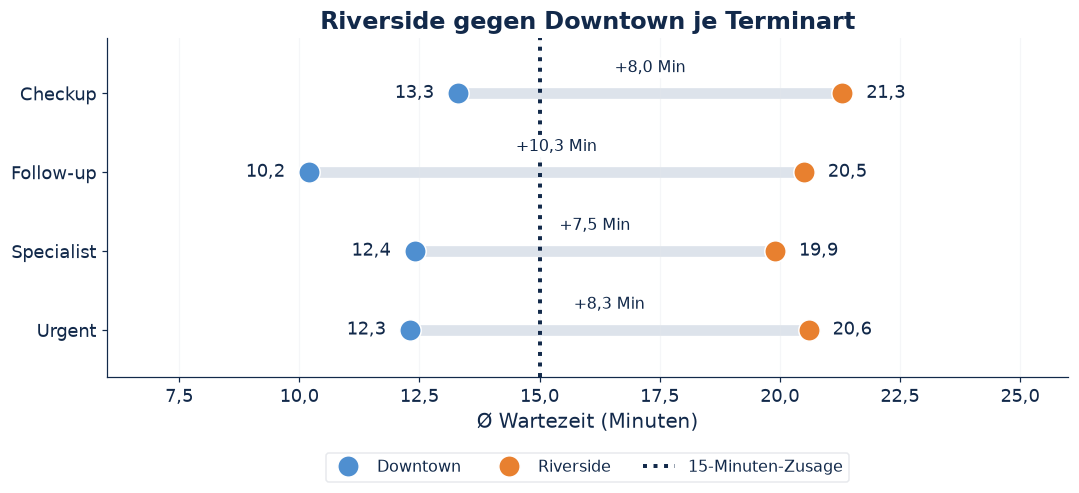

In [45]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for j, t_ in enumerate(by_type.columns):
    d_, r_ = by_type.loc["Downtown", t_], by_type.loc["Riverside", t_]
    ax.hlines(j, d_, r_, color=PASTEL["grau"], lw=7, zorder=1)
    ax.plot(d_, j, "o", color=LINE["blau"], ms=14, markeredgecolor="white", zorder=2, label="Downtown" if j == 0 else None)
    ax.plot(r_, j, "o", color=LINE["rosa"], ms=14, markeredgecolor="white", zorder=2, label="Riverside" if j == 0 else None)
    ax.text(d_ - .5, j, f"{d_:.1f}", ha="right", va="center", fontsize=11.5)
    ax.text(r_ + .5, j, f"{r_:.1f}", ha="left", va="center", fontsize=11.5)
    ax.text((d_ + r_) / 2, j - .22, f"+{r_ - d_:.1f} Min", ha="center", va="bottom", fontsize=10.5, color=INK, zorder=6, bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none"))
ax.axvline(15, color=INK, ls=":", label="15-Minuten-Zusage")
ax.set_yticks(range(len(by_type.columns))); ax.set_yticklabels(by_type.columns); ax.invert_yaxis()
ax.set_xlim(6, 26); ax.set_ylim(len(by_type.columns) - .4, -.7)
ax.set_xlabel("Ø Wartezeit (Minuten)"); ax.set_title("Riverside gegen Downtown je Terminart")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.2), ncol=3, fontsize=10.5); ax.grid(axis="y", visible=False); plt.tight_layout(); show()

**Aussage:** In jeder der vier Terminarten wartet Riverside 7,5 bis 10,3 Minuten länger als Downtown, der Standortunterschied ist also überall gleich gerichtet und ähnlich groß.

**Ergebnis der Robustheitsprüfung:** Keine der Datenentscheidungen aus Checkpoint 1 (Duplikate entfernen, No-Show-Zeilen behalten, Wartezeit-Ausreißer behalten) verändert eine der beiden Schlussfolgerungen. Die Differenz bleibt zwischen 7,9 und 8,8 Minuten, das Intervall liegt in jeder Variante über der Handlungsschwelle von 5 Minuten. Mit diesen Stichprobengrößen wäre außerdem schon ein Unterschied ab etwa 1,8 Minuten erkennbar gewesen, 8,6 Minuten liegen weit darüber. Das Datenqualitätsproblem, das eine Schlussfolgerung dagegen verändert hätte, sind die extremen Dauerwerte: Sie verschieben den Mittelwert der Dauer deutlich (siehe 1.4), berühren die Wartezeit-Tests aber nicht.

## Antworten Checkpoint 3

**Hypothesen und warum zweiseitig.** Die Nullhypothese lautet: Riverside und Downtown haben im Durchschnitt dieselbe Wartezeit. Die Alternativhypothese lautet: Die Durchschnitte unterscheiden sich. Die Frage verlangt keine Richtung. Ob Riverside länger oder kürzer wartet, wäre jeweils eine Entscheidung wert (Personal aufstocken oder umverteilen), also müssen beide Seiten geprüft werden. Beim Serviceversprechen war die Richtung durch die Frage selbst vorgegeben („weniger als 15 Minuten“), hier nicht. Die Richtung kommt aus der Fragestellung, nicht aus den Daten.

**Testentscheidung (formal).** Geprüft wird H₀: μ_Riverside − μ_Downtown = 0 gegen H₁: μ_Riverside − μ_Downtown ≠ 0. Der Welch-Test ergibt t(596,8) = 13,56 und einen zweiseitigen p-Wert von etwa 1,0 × 10⁻³⁶. Die Nullhypothese gleicher Populationsmittelwerte wird bei α = 0,05 und bei α = 0,01 verworfen. Das 95-%-Konfidenzintervall der Differenz [7,3; 9,8] schließt den Wert null aus und enthält nur Werte, die mit den Daten vereinbar sind. Unter den Testannahmen sprechen die Daten damit für einen Unterschied der durchschnittlichen Wartezeiten zwischen den Standorten in der Grundgesamtheit.

**Welch-Test und `equal_var=False`.** Der Test ist der Welch-t-Test für zwei unabhängige Gruppen. Mit `equal_var=False` wird nicht vorausgesetzt, dass beide Standorte gleich stark streuen, und die Freiheitsgrade werden entsprechend angepasst (596,8 statt 714). Das ist die sichere Standardeinstellung: Streuen die Standorte gleich, kostet es praktisch nichts (hier t 13,56 gegenüber 13,65 beim Standard-Test, Streuungen 8,40 und 8,12 Minuten, Levene-Test p = 0,175). Streuen sie ungleich, besonders bei ungleich großen Gruppen (286 gegenüber 430 Besuchen), schützt er vor einem falschen p-Wert. Man müsste sonst vorher per Vortest entscheiden, ob die Streuungen gleich sind, und dieser Vortest wäre selbst eine Fehlerquelle. Außerdem belegen ähnlich aussehende Stichprobenstreuungen nicht, dass die Streuungen in der Grundgesamtheit gleich sind. Deshalb ist Welch auch hier die verlässlichere Wahl.

**Typ-I- und Typ-II-Fehler in der Personalentscheidung.** Ein Typ-I-Fehler wäre: Wir schließen, dass Riverside anders wartet, obwohl es in Wahrheit keinen Unterschied gibt. Die Kosten wären Personal, das ohne Bedarf nach Riverside verlegt oder dort eingestellt wird, und eine Lücke an der Stelle, von der es abgezogen wird. Ein Typ-II-Fehler wäre: Wir übersehen einen echten Unterschied. Die Patienten in Riverside würden weiter länger warten, und in diesen Daten sinkt die Zufriedenheit mit der Wartezeit (Korrelation minus 0,39). Typ I kostet bekannte, begrenzte Mehrkosten, weil sich eine Umbesetzung zurücknehmen lässt. Typ II verursacht verdeckte Kosten, die sich aufsummieren, solange der Unterschied unentdeckt bleibt: Die 8,6 Minuten entsprechen etwa 41 zusätzlichen Wartestunden im Beobachtungszeitraum (Überschlag, siehe unten).

**Was ein p-Wert von etwa 10 hoch minus 36 belegt und was nicht.** Belegt ist, dass eine Differenz von 8,6 Minuten bei gleichen wahren Durchschnitten praktisch nie zufällig entstünde. Nicht belegt ist, wie groß oder wichtig der Unterschied ist, denn ein p-Wert sagt nichts über die Größe. Nicht belegt ist auch die Ursache: Die Terminart erklärt den Unterschied nicht, aber ob es am Personal, den Räumen oder den Abläufen liegt, zeigen diese Daten nicht. Und nicht belegt ist, dass mehr Personal das Problem lösen würde.

**Was ich der Operations-Leitung vorlegen würde.** Das Konfidenzintervall, in Minuten: Riverside wartet vermutlich 7,3 bis 9,8 Minuten länger als Downtown. Das ist die Größe, mit der sich Personal planen lässt. Cohens d (etwa 1,0, also rund eine Standardabweichung Unterschied) ordnet dazu ein, dass der Effekt groß ist (nach der üblichen Faustregel ab 0,8). Der p-Wert gehört höchstens als Randnotiz dazu. Die Handlungsschwelle von 5 Minuten ist akzeptabel, weil im Betriebsablauf Störungen vorkommen können, etwa durch Verspätungen vorheriger Patienten oder längere Untersuchungen. Gewählt habe ich sie nach Kenntnis der Zahlen. Die Aussage „handlungsrelevant“ gilt aber für jede Schwelle bis 7,3 Minuten, weil die untere Intervallgrenze dort liegt.

**Was das in Stunden heißt.** 286 Besuche in Riverside mal 8,6 Minuten ergeben überschlagen etwa 41 zusätzliche Wartestunden im Beobachtungszeitraum (gut ein Quartal). Das ist eine grobe Größenordnung aus Besuchszahl mal Differenz und keine gemessene Größe.

**Was ich als Nächstes untersuchen würde.** Warum Riverside länger wartet, lässt sich aus diesem Log nicht klären. Dafür würde ich Wartezeit nach Uhrzeit sowie die Personalbesetzung in Riverside erheben und mit den anderen Standorten vergleichen. Wochentag und Terminart sind schon geprüft.

**Handlungsempfehlung.** Erstens: den SMS-Test nur mit zufälliger Zuteilung je Termin starten, in allen vier Standorten gleichzeitig, mit etwa 470 Terminen je Gruppe, weil nur das die SMS von Standort und Monat trennt. Zweitens: in Riverside erst die Ursache der Mehrwartezeit klären und dann Maßnahmen wählen, denn Terminart, Versicherung und Wochentag erklären sie nicht und eine Wirkung von mehr Personal ist nicht belegt. Drittens: das Versprechen auch als Anteil messen und nicht nur als Durchschnitt, denn in Downtown liegen 27,9 Prozent der Besuche über 15 Minuten.

**Mit mehr Zeit würde ich** die Wartezeit nach Uhrzeit und Besetzung auswerten, die Schwelle für „handlungsrelevant“ vorab gemeinsam mit Solace festlegen und der Ursache der zwei Kostengipfel (um 135 und um 263) sowie der fehlenden Zufriedenheit bei Urgent nachgehen.

### 3.5 Vertiefung: Das Intervall in der Sprache der Personalplanung

Das Intervall der Differenz [7,3; 9,8] Minuten wird greifbar, wenn man es in Wartezeit je Tag, Wochenstunden und betroffene Patienten übersetzt. Das ist eine Rechnung aus Besuchszahl mal Differenz und keine gemessene Größe: Es ist die gesamte zusätzliche Wartezeit der Patienten und keine Arbeitszeit des Personals.

Beobachtungszeitraum: 91 Tage (13 Wochen), Riverside: 286 Besuche (3,1 je Tag)
Zusätzliche Wartezeit aller Riverside-Patienten gegenüber dem Downtown-Niveau: 35 bis 47 Stunden (Punktschätzung 41), das sind 2,7 bis 3,6 Stunden je Woche oder 23 bis 31 Minuten je Tag
Downtown: 27,9 % der Besuche über 15 Minuten (120 von 430), 95-%-Intervall [23,9; 32,3]
Riverside: 72,7 % der Besuche über 15 Minuten (208 von 286), 95-%-Intervall [67,3; 77,6]


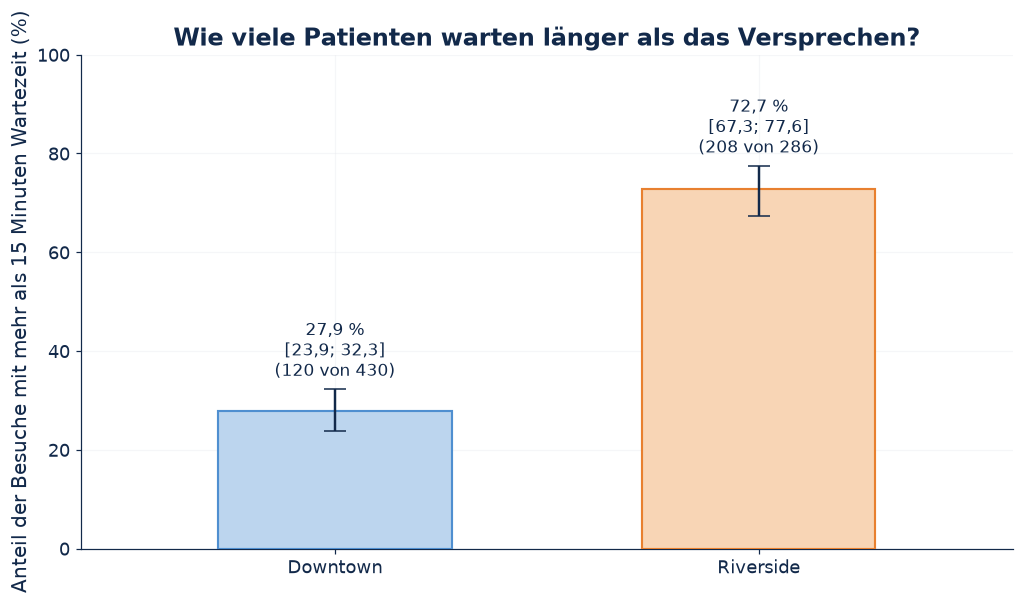

In [46]:
# 3.5 Das Intervall in der Sprache der Personalplanung
datum = pd.to_datetime(df.appointment_date); TAGE = (datum.max() - datum.min()).days + 1
std_lo, std_mid, std_hi = np.array([ci_lo, diff, ci_hi]) * n1 / 60
print(f"Beobachtungszeitraum: {TAGE} Tage ({TAGE / 7:.0f} Wochen), Riverside: {n1} Besuche ({n1 / TAGE:.1f} je Tag)")
print(f"Zusätzliche Wartezeit aller Riverside-Patienten gegenüber dem Downtown-Niveau: {std_lo:.0f} bis {std_hi:.0f} Stunden (Punktschätzung {std_mid:.0f}),"
      f" das sind {std_lo / (TAGE / 7):.1f} bis {std_hi / (TAGE / 7):.1f} Stunden je Woche oder {ci_lo * n1 / TAGE:.0f} bis {ci_hi * n1 / TAGE:.0f} Minuten je Tag")

def anteil_ci(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return p, c - h, c + h

fig, ax = plt.subplots(figsize=(9.5, 5.4))
for k, (st_, serie) in enumerate([("Downtown", dw), ("Riverside", rv)]):
    n_, ueber = len(serie), int((serie > MU0).sum()); p_, lo_, hi_ = anteil_ci(ueber, n_)
    print(f"{st_}: {p_ * 100:.1f} % der Besuche über {MU0} Minuten ({ueber} von {n_}), 95-%-Intervall [{lo_ * 100:.1f}; {hi_ * 100:.1f}]")
    ax.bar(k, p_ * 100, width=.55, color=PASTEL[SITE_COL[st_]], edgecolor=LINE[SITE_COL[st_]], lw=1.4, zorder=3)
    ax.errorbar(k, p_ * 100, yerr=[[(p_ - lo_) * 100], [(hi_ - p_) * 100]], color=INK, capsize=7, lw=1.6, zorder=4)
    ax.text(k, hi_ * 100 + 1.5, f"{p_ * 100:.1f} %\n[{lo_ * 100:.1f}; {hi_ * 100:.1f}]\n({ueber} von {n_})", ha="center", va="bottom", fontsize=11, color=INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Downtown", "Riverside"]); ax.set_ylim(0, 100); ax.set_xlim(-.6, 1.6)
ax.set_ylabel(f"Anteil der Besuche mit mehr als {MU0} Minuten Wartezeit (%)"); ax.set_title("Wie viele Patienten warten länger als das Versprechen?")
plt.tight_layout(); show()

**Aussage:** 73 % der Riverside-Besuche (208 von 286) warten länger als 15 Minuten, in Downtown 28 % (120 von 430), und die zusätzliche Wartezeit in Riverside summiert sich über das Quartal auf 35 bis 47 Stunden, das sind 2,7 bis 3,6 Stunden je Woche.

**Einordnung:**
- **Für die Betriebsleitung:** Ein Riverside-Patient wartet im Mittel 7,3 bis 9,8 Minuten länger als in Downtown. Bei gut drei Besuchen je Tag sind das 23 bis 31 Minuten zusätzliche Wartezeit am Tag. Das Intervall sagt, wie groß der Unterschied höchstens und mindestens ist, der p-Wert sagt nur, dass er nicht null ist.
- **Mittelwert und Anteil ergänzen sich:** „8,6 Minuten“ klingt klein, „73 % gegen 28 %“ zeigt, wie viele Patienten das Serviceversprechen anders erleben. Der Test aus Checkpoint 2 betrifft den Durchschnitt. Das Versprechen „Bei uns wartest du weniger als 15 Minuten“ hört dagegen jeder einzelne Patient, und es gilt auch in Downtown nicht für alle (28 % darüber).
- **Grenzen:** Die Stunden sind ein Überschlag für 91 Tage, die Anteile gelten für diesen Zeitraum. Warum Riverside länger wartet und ob mehr Personal es löst, zeigen diese Daten nicht.

### 3.6 Vertiefung: Bleibt der Standortunterschied über die Zeit gleich?

Der Welch-Test in 3.2 fasst alle 91 Tage zusammen. Wäre der Unterschied nur in einem Monat entstanden (durch einen Engpass oder eine einmalige Aktion), würde der Durchschnitt das verdecken. Ich rechne deshalb denselben Vergleich je Kalendermonat und prüfe mit einem F-Test, ob sich die Lücke zwischen den Monaten überhaupt unterscheidet (Wechselwirkung Standort × Monat, Modell mit und ohne Wechselwirkung). Der April enthält nur die ersten fünf Tage und wird der Vollständigkeit halber gezeigt.

            Monat  n Riverside  n Downtown  Mittel Riverside  Mittel Downtown  Differenz  untere  obere  p (Welch)
           Januar           85         139             21,41            11,73       9,68    7,28  12,07    3,2e-13
          Februar           91         131             20,96            12,00       8,96    6,86  11,06    9,7e-15
             März           98         137             19,92            13,05       6,86    4,61   9,11    7,3e-09
April (nur 1.–5.)           12          23             21,42            10,70      10,72    5,85  15,60    2,9e-04

Test auf unterschiedliche Lücken (Wechselwirkung Standort × Monat): F(3; 708) = 1,35, p = 0,256


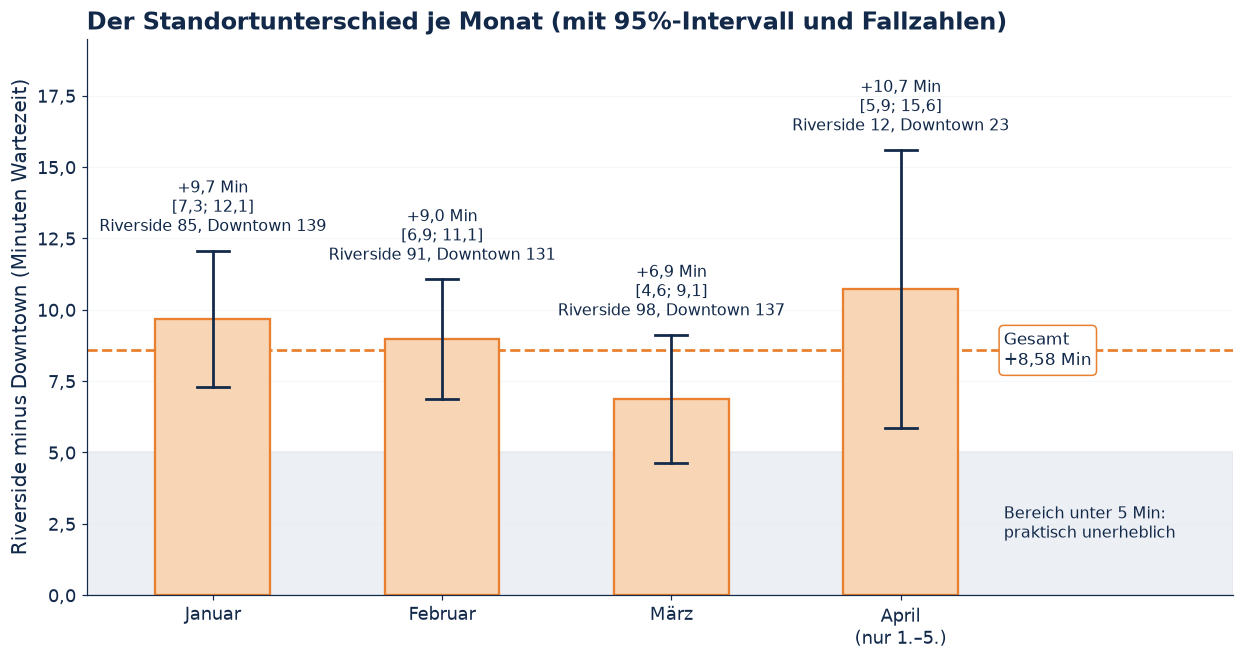

In [47]:
# Abschnitt 3.6: Bleibt der Standortunterschied über die Monate gleich? (Riverside gegen Downtown, je Kalendermonat)
def abschnitt36_monate():
    mn = lambda x, nd=1: f"{x:.{nd}f}".replace("-", "−")
    d = df[df.clinic_site.isin(["Riverside", "Downtown"])].assign(monat=lambda t: t.appointment_date.dt.month)
    namen = {1: "Januar", 2: "Februar", 3: "März", 4: "April\n(nur 1.–5.)"}
    zeilen = []
    for m, nm in namen.items():
        a = d[(d.monat == m) & (d.clinic_site == "Riverside")].wait_time_min; b = d[(d.monat == m) & (d.clinic_site == "Downtown")].wait_time_min
        dif = a.mean() - b.mean(); h = stats.t.ppf(.975, welch_df(a, b)) * np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        zeilen.append((nm, len(a), len(b), a.mean(), b.mean(), dif, dif - h, dif + h, stats.ttest_ind(a, b, equal_var=False).pvalue))
    tab = pd.DataFrame(zeilen, columns=["Monat", "n Riverside", "n Downtown", "Mittel Riverside", "Mittel Downtown", "Differenz", "untere", "obere", "p (Welch)"])
    tab["Monat"] = tab["Monat"].str.replace("\n", " ")
    print(tab.to_string(index=False, float_format=lambda v: f"{v:.2f}" if abs(v) > 1e-3 else f"{v:.1e}"))
    # Gleich große Lücke in allen Monaten? F-Test: Modell mit Standort + Monat gegen Modell mit zusätzlicher Wechselwirkung Standort × Monat
    y = d.wait_time_min.values; R = (d.clinic_site == "Riverside").astype(float).values; M = np.column_stack([(d.monat == m).astype(float) for m in (2, 3, 4)])
    X0 = np.column_stack([np.ones(len(y)), R, M]); X1 = np.column_stack([X0, M * R[:, None]])
    rss = lambda X: (lambda r: r @ r)(y - X @ np.linalg.lstsq(X, y, rcond=None)[0])
    r0, r1 = rss(X0), rss(X1); F = (r0 - r1) / 3 / (r1 / (len(y) - X1.shape[1])); pF = stats.f.sf(F, 3, len(y) - X1.shape[1])
    print(f"\nTest auf unterschiedliche Lücken (Wechselwirkung Standort × Monat): F(3; {len(y) - X1.shape[1]}) = {F:.2f}, p = {pF:.3f}")
    ges = df[df.clinic_site == "Riverside"].wait_time_min.mean() - df[df.clinic_site == "Downtown"].wait_time_min.mean()
    fig, ax = plt.subplots(figsize=(11.5, 6.2)); x = np.arange(4)
    ax.axhspan(0, 5, color=PASTEL["grau"], alpha=.55, zorder=0); ax.axhline(ges, color=LINE["rosa"], ls="--", lw=1.8)
    for i, z in enumerate(zeilen):
        ax.bar(i, z[5], .5, color=PASTEL["rosa"], edgecolor=LINE["rosa"], lw=1.5, zorder=2)
        ax.plot([i, i], [z[6], z[7]], color=INK, lw=1.8, zorder=3); ax.plot([i - .07, i + .07], [z[6]] * 2, color=INK, lw=1.8); ax.plot([i - .07, i + .07], [z[7]] * 2, color=INK, lw=1.8)
        ax.text(i, z[7] + .5, f"+{mn(z[5])} Min\n[{mn(z[6])}; {mn(z[7])}]\nRiverside {z[1]}, Downtown {z[2]}", ha="center", va="bottom", fontsize=10.5)
    ax.text(3.45, ges, f"Gesamt\n+{mn(ges, 2)} Min", color=INK, ha="left", va="center", fontsize=11, bbox=dict(boxstyle="round,pad=.28", fc="white", ec=LINE["rosa"]))
    ax.text(3.45, 2.5, "Bereich unter 5 Min:\npraktisch unerheblich", color=INK, ha="left", va="center", fontsize=10.5)
    ax.set_xticks(x); ax.set_xticklabels([z[0] for z in zeilen]); ax.set_ylim(0, 19.5); ax.set_xlim(-.55, 4.45)
    ax.set_ylabel("Riverside minus Downtown (Minuten Wartezeit)"); ax.grid(axis="x", visible=False)
    ax.set_title("Der Standortunterschied je Monat (mit 95%-Intervall und Fallzahlen)", loc="left")
    plt.tight_layout(); show()
    return tab, F, pF

z36 = abschnitt36_monate()

**Aussage:** In jedem Monat wartet Riverside länger als Downtown (+6,9 bis +10,7 Minuten, alle Intervalle liegen über 0), die Lücke ist im März mit +6,9 [4,6; 9,1] am kleinsten, ein Unterschied zwischen den Monaten lässt sich aber nicht nachweisen (F = 1,35; p = 0,256).

**Einordnung:**
- **Kein Ein-Monats-Effekt:** Riverside liegt von Januar bis März bei 21,4, 21,0 und 19,9 Minuten, Downtown bei 11,7, 12,0 und 13,1. Der Befund aus 3.2 stützt sich nicht auf einen einzelnen Monat.
- **März:** Die Untergrenze (4,6) liegt knapp unter der 5-Minuten-Schwelle. Riverside wartet im März 1,5 Minuten weniger als im Januar, Downtown 1,3 Minuten mehr. In den März fallen auch die eigenmächtigen Änderungen ab dem 15. März (Abschnitt 4.2). Ob sie die Lücke verkleinert haben, lässt sich nicht trennen, zumal der Monatsunterschied nicht signifikant ist.
- **April:** Fünf Tage, 12 und 23 Besuche, Intervall [5,9; 15,6]. Zu wenig für eine eigene Aussage.
- **Grenzen:** Vier Intervalle ohne Korrektur für Mehrfachvergleiche, beschreibend gemeint. Die Monate sind keine Zufallsstichproben, sondern aufeinanderfolgende Zeiträume.

### 3.7 Vertiefung: Erklären längere Termine die Wartezeit?

Bei der 5-Minuten-Schwelle (Entscheidung 2) nenne ich als Gründe für Wartezeiten unter anderem Verzögerungen vorheriger Patienten, längere Untersuchungen und Störungen im Betriebsablauf. Die Daten enthalten für jeden Besuch die geplante und die tatsächliche Dauer. Damit lässt sich prüfen, ob Termine in Riverside länger dauern als geplant und ob Tage mit längeren Terminen längere Wartezeiten haben. Die **Überziehung** ist tatsächliche minus geplante Dauer (negativ heißt: kürzer als geplant). Auf Tagesebene fasse ich je Standort und Tag den Median der Überziehung und die mittlere Wartezeit zusammen (mindestens 3 Termine). Weil Überziehung und Wartezeit schief verteilt sind, nutze ich die Rangkorrelation nach Spearman.

Überziehung = tatsächliche minus geplante Dauer. Im Anzeigefenster von −30 bis +30 Minuten liegen 1175 von 1200 Terminen (25 außerhalb, darunter Extremwerte bis +540 Min).
Alle 1200 Termine: Median −2,4 Min, Mittelwert −1,1 Min; Anteil Termine, die länger dauern als geplant: 34,1 % (409 von 1200).
             Termine  Median_Ueberziehung  Anteil_ueber_Plan  Mittel_Wartezeit
clinic_site                                                                   
Downtown         430                 -2,2               33,5              12,2
Eastview         220                 -2,4               35,0              12,6
Northgate        264                 -2,2               36,7              12,0
Riverside        286                 -3,0               31,8              20,8


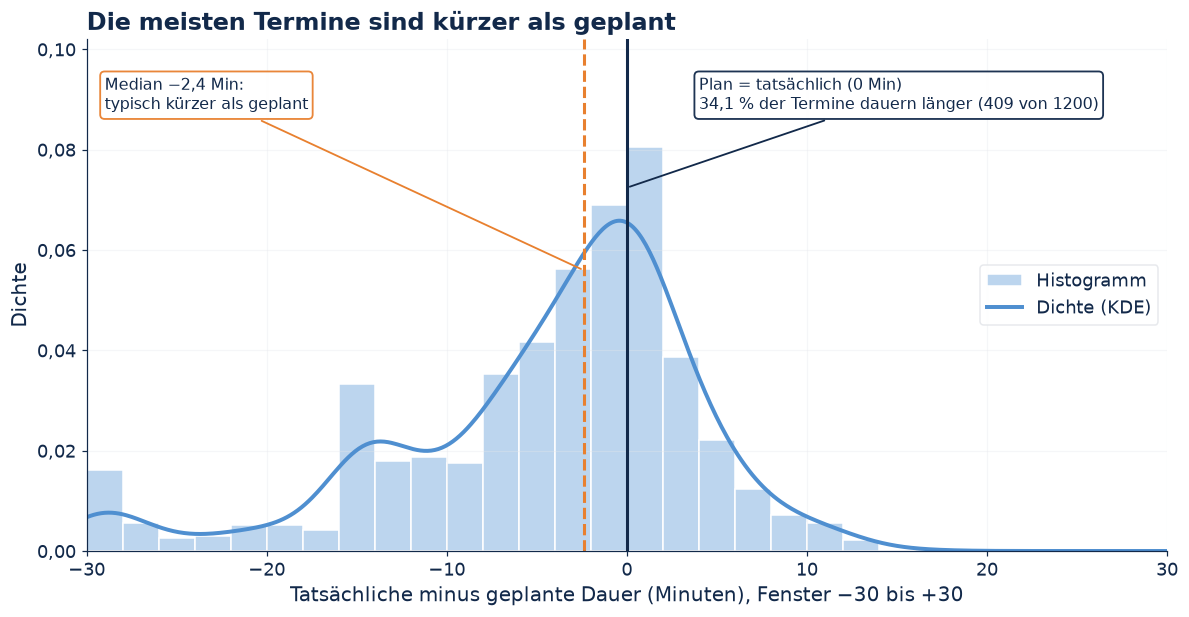


Standort-Tage mit mindestens 3 Terminen: 237. Spearman-Korrelation Wartezeit (Tagesmittel) gegen Überziehung (Tagesmedian): rho = −0,005 [−0,13; 0,12], p = 0,94.
Einzelne Termine: rho = −0,021, p = 0,47 (n = 1200).


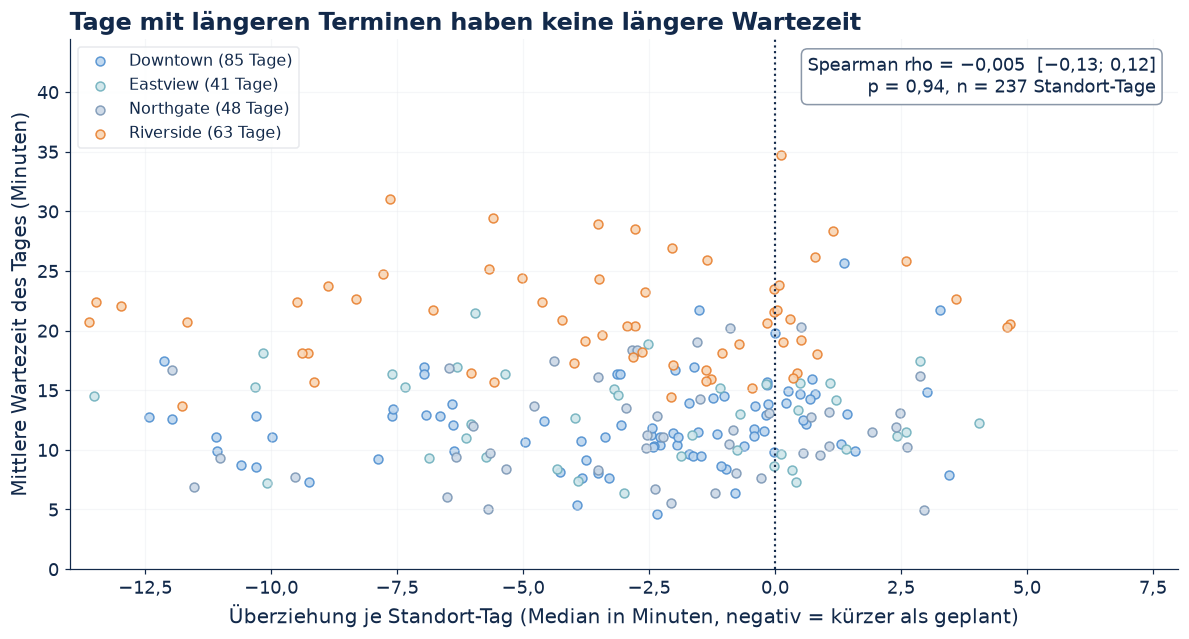

In [48]:
# Abschnitt 3.7: Termindauer. Erklären längere Untersuchungen die Wartezeit?
def abschnitt37_dauer():
    mn = lambda x, nd=1: f"{x:.{nd}f}".replace("-", "−")
    d = df.assign(ueber=df.actual_duration_min - df.scheduled_duration_min)
    n_aus = int(((d.ueber < -30) | (d.ueber > 30)).sum()); w = d[d.ueber.between(-30, 30)]
    print(f"Überziehung = tatsächliche minus geplante Dauer. Im Anzeigefenster von −30 bis +30 Minuten liegen {len(w)} von {len(d)} Terminen ({n_aus} außerhalb, darunter Extremwerte bis +{d.ueber.max():.0f} Min).")
    print(f"Alle {len(d)} Termine: Median {mn(d.ueber.median())} Min, Mittelwert {mn(d.ueber.mean())} Min; Anteil Termine, die länger dauern als geplant: {(d.ueber > 0).mean() * 100:.1f} % ({int((d.ueber > 0).sum())} von {len(d)}).")
    tab = d.groupby("clinic_site").agg(Termine=("ueber", "size"), Median_Ueberziehung=("ueber", "median"), Anteil_ueber_Plan=("ueber", lambda s: (s > 0).mean() * 100), Mittel_Wartezeit=("wait_time_min", "mean")).reindex(SITE_ORDER)
    print(tab.to_string(float_format=lambda v: f"{v:.1f}"))
    fig, ax = plt.subplots(figsize=(11, 5.8)); bins = np.arange(-30, 31, 2); xs = np.linspace(-30, 30, 600)
    ax.hist(w.ueber, bins=bins, density=True, color=PASTEL["blau"], edgecolor="white", label="Histogramm"); kd = stats.gaussian_kde(w.ueber)(xs); ax.plot(xs, kd, color=LINE["blau"], label="Dichte (KDE)")
    ax.axvline(0, color=INK, lw=2); ax.axvline(d.ueber.median(), color=LINE["rosa"], ls="--", lw=2)
    ym = kd.max(); ax.set_ylim(0, ym * 1.55); ax.set_xlim(-30, 30)
    tagd(ax, (0, ym * 1.1), (4, ym * 1.38), f"Plan = tatsächlich (0 Min)\n{(d.ueber > 0).mean() * 100:.1f} % der Termine dauern länger ({int((d.ueber > 0).sum())} von {len(d)})", INK, fs=10.5)
    tagd(ax, (d.ueber.median(), ym * .85), (-29, ym * 1.38), f"Median {mn(d.ueber.median())} Min:\ntypisch kürzer als geplant", LINE["rosa"], fs=10.5)
    ax.set_xlabel("Tatsächliche minus geplante Dauer (Minuten), Fenster −30 bis +30"); ax.set_ylabel("Dichte"); ax.legend(loc="center right")
    ax.set_title("Die meisten Termine sind kürzer als geplant", loc="left"); plt.tight_layout(); show()
    # Tagesebene: je Standort und Tag Mittelwert von Wartezeit und Überziehung (mindestens 3 Termine)
    tg = d.groupby(["clinic_site", "appointment_date"]).agg(w=("wait_time_min", "mean"), o=("ueber", "median"), n=("ueber", "size")).reset_index(); tg = tg[tg.n >= 3]
    rho, p = stats.spearmanr(tg.w, tg.o); rv, pv = stats.spearmanr(d.wait_time_min, d.ueber)
    z = np.arctanh(rho); h = 1.96 / np.sqrt(len(tg) - 3); lo, hi = np.tanh(z - h), np.tanh(z + h)
    print(f"\nStandort-Tage mit mindestens 3 Terminen: {len(tg)}. Spearman-Korrelation Wartezeit (Tagesmittel) gegen Überziehung (Tagesmedian): rho = {mn(rho, 3)} [{mn(lo, 2)}; {mn(hi, 2)}], p = {p:.2f}.")
    print(f"Einzelne Termine: rho = {mn(rv, 3)}, p = {pv:.2f} (n = {len(d)}).")
    fig, ax = plt.subplots(figsize=(11, 6))
    for s_ in SITE_ORDER:
        t_ = tg[tg.clinic_site == s_]; ax.scatter(t_.o, t_.w, s=34, color=PASTEL[SITE_COL[s_]], edgecolor=LINE[SITE_COL[s_]], lw=1, alpha=.9, label=f"{s_} ({len(t_)} Tage)")
    ax.set_xlim(-14, 8); ax.set_ylim(0, max(tg.w) * 1.28)
    ax.text(.98, .97, f"Spearman rho = {mn(rho, 3)}  [{mn(lo, 2)}; {mn(hi, 2)}]\np = {p:.2f}, n = {len(tg)} Standort-Tage", transform=ax.transAxes, ha="right", va="top", fontsize=11.5, bbox=dict(boxstyle="round,pad=.35", fc="white", ec=LINE["grau"]))
    ax.axvline(0, color=INK, lw=1.4, ls=":"); ax.set_xlabel("Überziehung je Standort-Tag (Median in Minuten, negativ = kürzer als geplant)"); ax.set_ylabel("Mittlere Wartezeit des Tages (Minuten)")
    ax.legend(loc="upper left", fontsize=10.5); ax.set_title("Tage mit längeren Terminen haben keine längere Wartezeit", loc="left"); plt.tight_layout(); show()
    return tab, rho, p

z37 = abschnitt37_dauer()

**Aussage:** Termine dauern im Median 2,4 Minuten kürzer als geplant, und nur 34,1 % (409 von 1.200) überschreiten die geplante Dauer.

**Aussage:** Tage mit längeren Terminen haben keine längere Wartezeit (Spearman rho = −0,005, 237 Standort-Tage), und Riverside hat trotz der höchsten Wartezeit die kürzesten Termine (Median −3,0 Minuten gegen −2,2 in Downtown).

**Einordnung:**
- **Riverside:** Nur 31,8 % der Termine dauern länger als geplant, in Downtown 33,5 %. Die 8,6 Minuten Unterschied entstehen nicht dadurch, dass Termine in Riverside länger dauern.
- **Was das nicht ausschließt:** Die Daten haben keine Uhrzeiten und keine Reihenfolge der Termine innerhalb eines Tages. Ob ein einzelner langer Termin die nachfolgenden Patienten verzögert, lässt sich deshalb nicht prüfen. Auf Tagesebene mittelt sich das heraus. Gezeigt ist: Die Überziehung erklärt die Wartezeit der Tage nicht. Nicht gezeigt ist, dass einzelne Verzögerungen nie eine Rolle spielen.
- **Wohin der Befund zeigt:** Zu den Betriebsdaten (Zusatz 7 und 17) passt, dass Patientenzahl und Personal die Wartezeit erklären. Für Riverside einzeln gibt es keine Personaldaten, die Ursache bleibt offen.
- **Darstellung:** Das Histogramm zeigt das Fenster von −30 bis +30 Minuten (1.175 von 1.200 Terminen). 25 Termine liegen außerhalb, darunter die als Erfassungsfehler markierten Extremwerte aus 1.4 (bis +540 Minuten). Der Median ist davon nicht betroffen, deshalb steht er im Vordergrund.

### 3.8 Vertiefung: Was bedeuten die 8,6 Minuten für die Patienten?

Die 8,6 Minuten sind eine Zahl für den Betrieb. Für die Patienten zählt, wie sie die Wartezeit erleben. Die Zufriedenheit (1 bis 5 Punkte) liegt für 1.077 von 1.200 Besuchen vor, die Bewertung fehlt vor allem bei Urgent (siehe 1.2b). Ich vergleiche beide Standorte mit dem Welch-Test und, weil die Zufriedenheit nur fünf Stufen hat, zusätzlich mit dem Mann-Whitney-U-Test, und zeige, wie die Zufriedenheit mit der Wartezeit sinkt. Dazu teile ich die Wartezeit in sechs Klassen.

Zufriedenheit (1 bis 5), nur Besuche mit Bewertung: Riverside 3,85 (n = 254), Downtown 4,19 (n = 387).
Differenz −0,34 [−0,46; −0,22], Welch-Test p = 4,3e-08, Mann-Whitney-U (ohne Annahme einer Normalverteilung) p = 3,8e-08, Cohens d = −0,45.
Anteil zufrieden (4 oder 5 Punkte): Riverside 68,5 % (174 von 254), Downtown 82,7 % (320 von 387).
           n  Mittelwert  untere  obere  Anteil_zufrieden
kl                                                       
bis 5    127        4,60    4,50   4,69             97,64
5–10     265        4,35    4,27   4,44             88,68
10–15    262        4,10    4,01   4,18             83,21
15–20    207        3,94    3,83   4,04             73,43
20–30    147        3,73    3,61   3,86             61,22
über 30   69        3,52    3,33   3,71             47,83

Spearman-Korrelation Wartezeit gegen Zufriedenheit: rho = −0,403 (p < 0,001, n = 1077); Zufriedenheit ist eine Rangskala, deshalb Rangkorrelation.


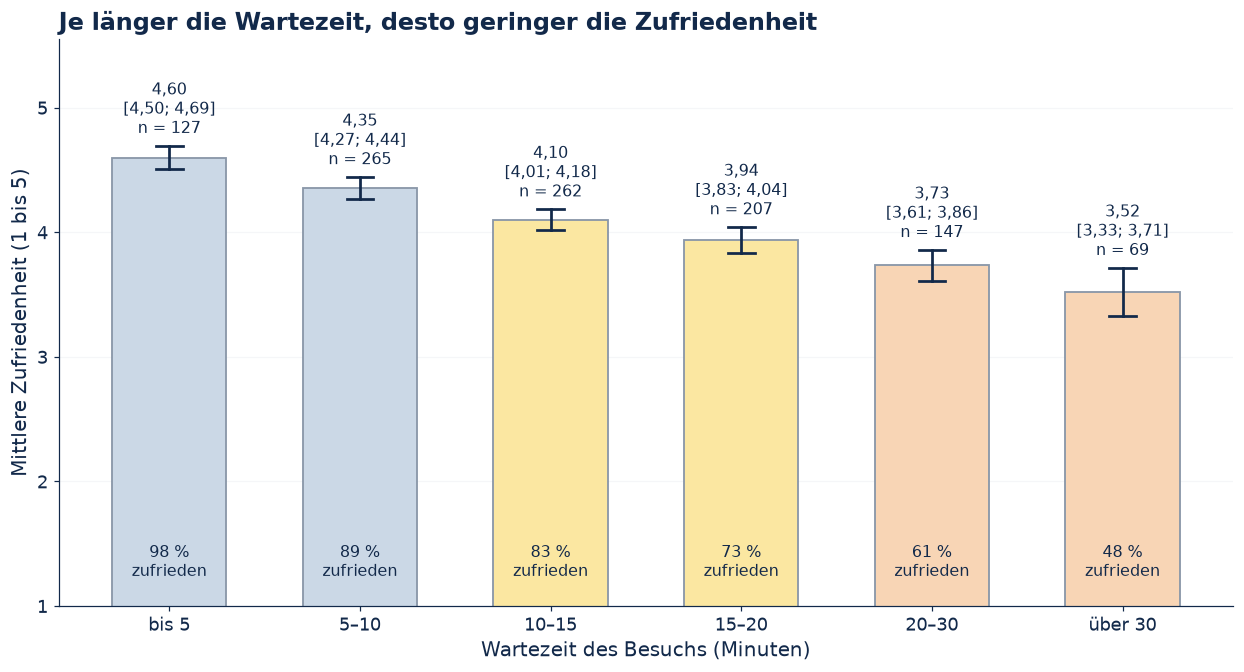

In [49]:
# Abschnitt 3.8: Zufriedenheit. Was bedeuten 8,6 Minuten für die Patienten?
def abschnitt38_zufriedenheit():
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−")
    s = df.dropna(subset=["patient_satisfaction"]); a = s[s.clinic_site == "Riverside"].patient_satisfaction; b = s[s.clinic_site == "Downtown"].patient_satisfaction
    dif = a.mean() - b.mean(); h = stats.t.ppf(.975, welch_df(a, b)) * np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b)); tw = stats.ttest_ind(a, b, equal_var=False); mw = stats.mannwhitneyu(a, b)
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    print(f"Zufriedenheit (1 bis 5), nur Besuche mit Bewertung: Riverside {mn(a.mean())} (n = {len(a)}), Downtown {mn(b.mean())} (n = {len(b)}).")
    print(f"Differenz {mn(dif)} [{mn(dif - h)}; {mn(dif + h)}], Welch-Test p = {tw.pvalue:.1e}, Mann-Whitney-U (ohne Annahme einer Normalverteilung) p = {mw.pvalue:.1e}, Cohens d = {mn(dif / sp)}.")
    anteil = lambda x: ((x >= 4).mean() * 100, int((x >= 4).sum()), len(x))
    print(f"Anteil zufrieden (4 oder 5 Punkte): Riverside {anteil(a)[0]:.1f} % ({anteil(a)[1]} von {anteil(a)[2]}), Downtown {anteil(b)[0]:.1f} % ({anteil(b)[1]} von {anteil(b)[2]}).")
    klassen = [0, 5, 10, 15, 20, 30, 100]; namen = ["bis 5", "5–10", "10–15", "15–20", "20–30", "über 30"]
    s = s.assign(kl=pd.cut(s.wait_time_min, klassen, labels=namen)); g_ = s.groupby("kl", observed=True).patient_satisfaction
    tab = pd.DataFrame({"n": g_.size(), "Mittelwert": g_.mean(), "untere": [mean_ci(x)[1] for _, x in g_], "obere": [mean_ci(x)[2] for _, x in g_], "Anteil_zufrieden": g_.apply(lambda x: (x >= 4).mean() * 100)})
    print(tab.to_string(float_format=lambda v: f"{v:.2f}"))
    rho, p = stats.spearmanr(s.wait_time_min, s.patient_satisfaction); print(f"\nSpearman-Korrelation Wartezeit gegen Zufriedenheit: rho = {mn(rho, 3)} (p < 0,001, n = {len(s)}); Zufriedenheit ist eine Rangskala, deshalb Rangkorrelation.")
    fig, ax = plt.subplots(figsize=(11.5, 6.3)); cols = [PASTEL["gruen"], PASTEL["gruen"], PASTEL["gelb"], PASTEL["gelb"], PASTEL["rosa"], PASTEL["rosa"]]
    for i, (k, r) in enumerate(tab.iterrows()):
        ax.bar(i, r.Mittelwert, .6, color=cols[i], edgecolor=LINE["grau"], lw=1.2, zorder=2); ax.plot([i, i], [r.untere, r.obere], color=INK, lw=1.8, zorder=3)
        ax.plot([i - .07, i + .07], [r.untere] * 2, color=INK, lw=1.8); ax.plot([i - .07, i + .07], [r.obere] * 2, color=INK, lw=1.8)
        ax.text(i, r.obere + .06, f"{mn(r.Mittelwert)}\n[{mn(r.untere)}; {mn(r.obere)}]\nn = {int(r.n)}", ha="center", va="bottom", fontsize=10.5)
        ax.text(i, 1.35, f"{r.Anteil_zufrieden:.0f} %\nzufrieden".replace(".", ","), ha="center", va="center", fontsize=10.2, color=INK)
    ax.set_xticks(range(len(namen))); ax.set_xticklabels(namen); ax.set_ylim(1, 5.55); ax.set_xlabel("Wartezeit des Besuchs (Minuten)"); ax.set_ylabel("Mittlere Zufriedenheit (1 bis 5)")
    ax.grid(axis="x", visible=False); ax.set_title("Je länger die Wartezeit, desto geringer die Zufriedenheit", loc="left"); plt.tight_layout(); show()
    return tab, dif, h

z38 = abschnitt38_zufriedenheit()

**Aussage:** Je länger die Wartezeit, desto geringer die Zufriedenheit: von 4,60 Punkten bei bis zu 5 Minuten auf 3,52 bei über 30 Minuten, und nur noch 48 % der Patienten mit mehr als 30 Minuten Wartezeit sind zufrieden (4 oder 5 Punkte), gegen 98 % bei bis zu 5 Minuten.

**Einordnung:**
- **Standortvergleich:** Riverside 3,85 Punkte (n = 254), Downtown 4,19 (n = 387), Differenz −0,34 [−0,46; −0,22], Welch p = 4,3 × 10⁻⁸, Mann-Whitney p = 3,8 × 10⁻⁸, Cohens d = −0,45. Zufrieden sind in Riverside 68,5 % (174 von 254), in Downtown 82,7 % (320 von 387), also 14 Prozentpunkte weniger.
- **Rangkorrelation:** rho = −0,403 (n = 1.077), passend zum Pearson-Wert −0,388 aus 1.7.
- **Kein Sprung bei 15 Minuten:** Die Zufriedenheit sinkt von Klasse zu Klasse um etwa 0,2 Punkte. Das Serviceversprechen von 15 Minuten ist keine Grenze, an der sie einbricht, sondern ein Punkt auf einem gleitenden Verlauf.
- **Grenzen:** Beobachtungsdaten. Besuche ohne Bewertung (123, vor allem Urgent) fehlen. Die Klassen sind nicht gleich breit (5 Minuten, ab 20 Minuten 10 Minuten und mehr). Warum Patienten unzufrieden sind, zeigt die Zahl nicht. Wie viel davon über die Wartezeit läuft, prüft Zusatz 18.

# Checkpoint 4: Zahlen zur Design-Review

Checkpoint 4 ist eine Design-Review ohne Datensatz. Die Zahlen im Abgabedokument stammen aus dem Besuchslog, das **keine SMS-Erinnerung** enthält, und zeigen, was der geplante Vergleich ohne jede Wirkung der SMS ergeben hätte.

Riverside ['Januar: 8,2 % (7 von 85) ', 'Februar: 12,1 % (11 von 91) ', 'März: 8,2 % (8 von 98) ']
Downtown ['Januar: 11,5 % (16 von 139) ', 'Februar: 13,0 % (17 von 131) ', 'März: 10,9 % (15 von 137) ']
Alle Standorte ['Januar: 10,6 % (38 von 358) ', 'Februar: 12,6 % (47 von 373) ', 'März: 9,4 % (38 von 406) ']

Plan-Vergleich ohne SMS: Riverside März 8,2 % gegen Downtown Februar 13,0 % = 4,8 Punkte 'Rückgang'
Alle Standorte: Februar 12,6 % gegen März 9,4 %
No-Show-Rate je Standort (gesamter Zeitraum): {'Downtown': 11,6, 'Eastview': 12,7, 'Northgate': 9,1, 'Riverside': 9,4}
Patienten an mehr als einem Standort: 14


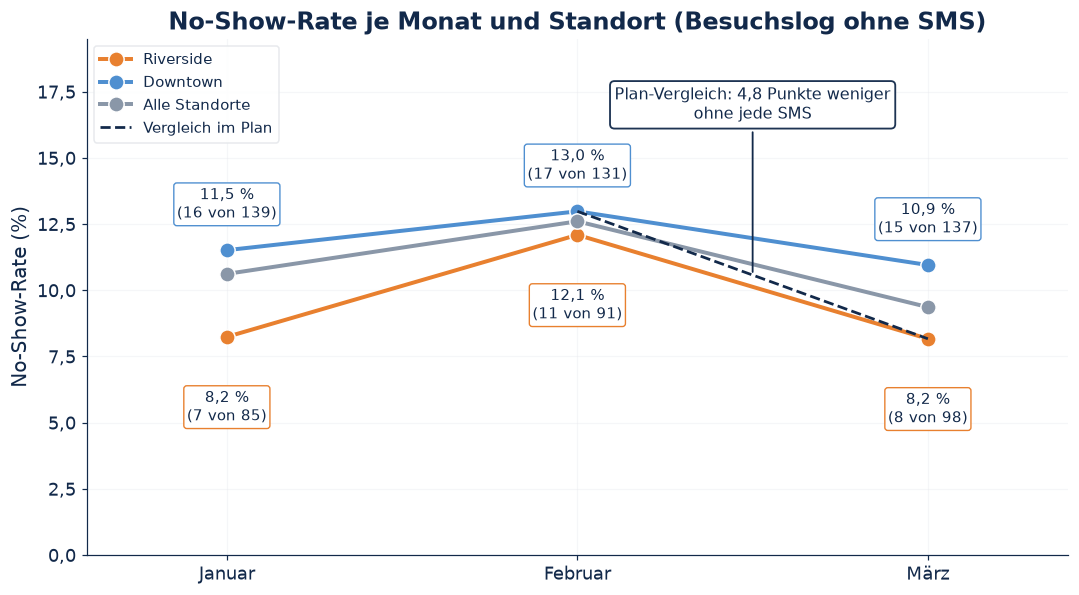

In [50]:
d4 = df.copy(); d4["monat"] = pd.to_datetime(d4.appointment_date).dt.to_period("M")
voll = d4[d4.monat.astype(str).isin(["2026-01", "2026-02", "2026-03"])]            # April hat nur 5 Tage und bleibt draußen
def rate(frame): return frame.no_show.mean() * 100, int(frame.no_show.sum()), len(frame)

monate = ["2026-01", "2026-02", "2026-03"]; namen = ["Januar", "Februar", "März"]
serien = {"Riverside": voll[voll.clinic_site == "Riverside"], "Downtown": voll[voll.clinic_site == "Downtown"], "Alle Standorte": voll}
tab4 = {s_: [rate(f[f.monat.astype(str) == m_]) for m_ in monate] for s_, f in serien.items()}
for s_, v in tab4.items():
    print(s_, [f"{n_}: {r_:.1f} % ({k_} von {n}) " .replace(".", ",") for n_, (r_, k_, n) in zip(namen, v)])

dt_feb = tab4["Downtown"][1]; rv_mar = tab4["Riverside"][2]
placebo = dt_feb[0] - rv_mar[0]
print(f"\nPlan-Vergleich ohne SMS: Riverside März {rv_mar[0]:.1f} % gegen Downtown Februar {dt_feb[0]:.1f} % = {placebo:.1f} Punkte 'Rückgang'")
print(f"Alle Standorte: Februar {tab4['Alle Standorte'][1][0]:.1f} % gegen März {tab4['Alle Standorte'][2][0]:.1f} %")
print("No-Show-Rate je Standort (gesamter Zeitraum):", (df.groupby("clinic_site").no_show.mean() * 100).round(1).to_dict())
print("Patienten an mehr als einem Standort:", int((df.groupby("patient_id").clinic_site.nunique() > 1).sum()))

fig, ax = plt.subplots(figsize=(10, 5.6))
farben = {"Riverside": "rosa", "Downtown": "blau", "Alle Standorte": "grau"}
for s_, v in tab4.items():
    ax.plot(namen, [x[0] for x in v], "o-", color=LINE[farben[s_]], ms=10, markeredgecolor="white", label=s_)
for s_, v in tab4.items():
    for i, (r_, k_, n) in enumerate(v):
        dy = {"Riverside": -34, "Downtown": 18, "Alle Standorte": -34 if s_ == "Alle Standorte" and False else 12}[s_]
        if s_ == "Alle Standorte": continue
        ax.annotate(f"{r_:.1f} %\n({k_} von {n})", (i, r_), xytext=(0, dy), textcoords="offset points", ha="center",
                    va="top" if dy < 0 else "bottom", fontsize=10, color=INK, bbox=dict(boxstyle="round,pad=.2", fc="white", ec=LINE[farben[s_]], lw=.9))
ax.plot([1, 2], [dt_feb[0], rv_mar[0]], ls="--", color=INK, lw=1.8, label="Vergleich im Plan")
tagd(ax, (1.5, (dt_feb[0] + rv_mar[0]) / 2), (1.5, 17.0), f"Plan-Vergleich: {placebo:.1f} Punkte weniger\nohne jede SMS", INK, ha="center", fs=10.5)
ax.set_xlim(-.4, 2.4); ax.set_ylim(0, 19.5); ax.set_ylabel("No-Show-Rate (%)"); ax.set_title("No-Show-Rate je Monat und Standort (Besuchslog ohne SMS)")
ax.legend(loc="upper left", fontsize=10); plt.tight_layout(); show()

**Aussage:** Schon ohne SMS ergibt der Plan-Vergleich (Riverside im März gegen Downtown im Februar) 4,8 Prozentpunkte weniger Ausfälle, mehr als das Doppelte der erwarteten 2 Punkte, weil Monat und Standort sich zugleich unterscheiden. Mit nur 98 und 131 Besuchen ist der Abstand aber ungenau: Sein 95-%-Intervall reicht von −12,7 bis +3,7 Punkten und schließt null ein.

In [51]:
# Wie sicher ist der scheinbare Rückgang? Wilson-Intervalle je Gruppe, Newcombe-Intervall für den Abstand
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return p, c - h, c + h
k_rmar, n_rmar = rv_mar[1], rv_mar[2]; k_dfeb, n_dfeb = dt_feb[1], dt_feb[2]
p_rmar, lo_rmar, hi_rmar = wilson(k_rmar, n_rmar); p_dfeb, lo_dfeb, hi_dfeb = wilson(k_dfeb, n_dfeb)
diff_pl = p_rmar - p_dfeb
lo_pl = diff_pl - np.sqrt((p_rmar - lo_rmar)**2 + (hi_dfeb - p_dfeb)**2); hi_pl = diff_pl + np.sqrt((hi_rmar - p_rmar)**2 + (p_dfeb - lo_dfeb)**2)
print(f"Riverside März:  {k_rmar} von {n_rmar} = {p_rmar*100:.1f} % [{lo_rmar*100:.1f}; {hi_rmar*100:.1f}]")
print(f"Downtown Februar: {k_dfeb} von {n_dfeb} = {p_dfeb*100:.1f} % [{lo_dfeb*100:.1f}; {hi_dfeb*100:.1f}]")
print(f"Abstand: {diff_pl*100:.1f} Punkte, 95-%-Intervall [{lo_pl*100:.1f}; {hi_pl*100:.1f}] -> schließt null ein: {lo_pl < 0 < hi_pl}")

Riverside März:  8 von 98 = 8,2 % [4,2; 15,3]
Downtown Februar: 17 von 131 = 13,0 % [8,3; 19,8]
Abstand: -4,8 Punkte, 95-%-Intervall [-12,7; 3,7] -> schließt null ein: True


**Aussage:** Der scheinbare Rückgang von 4,8 Punkten ist statistisch nicht von null zu unterscheiden (Intervall −12,7 bis +3,7). Der Plan-Vergleich kann also einen großen Effekt zeigen und trotzdem nichts belegen, denn Standort und Monat unterscheiden sich zugleich und die Gruppen sind klein.

**Auch ein signifikantes Ergebnis würde nichts belegen.** Hätte der Plan-Vergleich zwischen Riverside und Downtown einen deutlichen, statistisch signifikanten Unterschied gezeigt, ließe er sich der SMS trotzdem nicht zuschreiben: Standort, Monat, der freiwillige Manager und Downtowns eigene Erinnerungs-E-Mails wirken zugleich. Ein kleiner p-Wert sagt nur, dass der Unterschied nicht null ist, nicht, woher er kommt. Ein Beispiel aus diesen Daten: Die 8,6 Minuten Wartezeit zwischen den beiden Standorten sind hochsignifikant und haben mit der SMS nichts zu tun.

Chance, einen Rückgang um 2 Punkte zu erkennen (Ausgangsrate Riverside 9,4 %): 1 Monat 8 %, 1 Quartal 16 %
Nötige Termine je Gruppe bei Ausgangsrate 10,75 % (80 % Power): 2 Punkte 3449, 3 Punkte 1460, 5 Punkte 471
Besuche im Log je Quartal: 1200 -> Dauer für 5 Punkte: 0,8 Quartale, für 2 Punkte: 5,7 Quartale


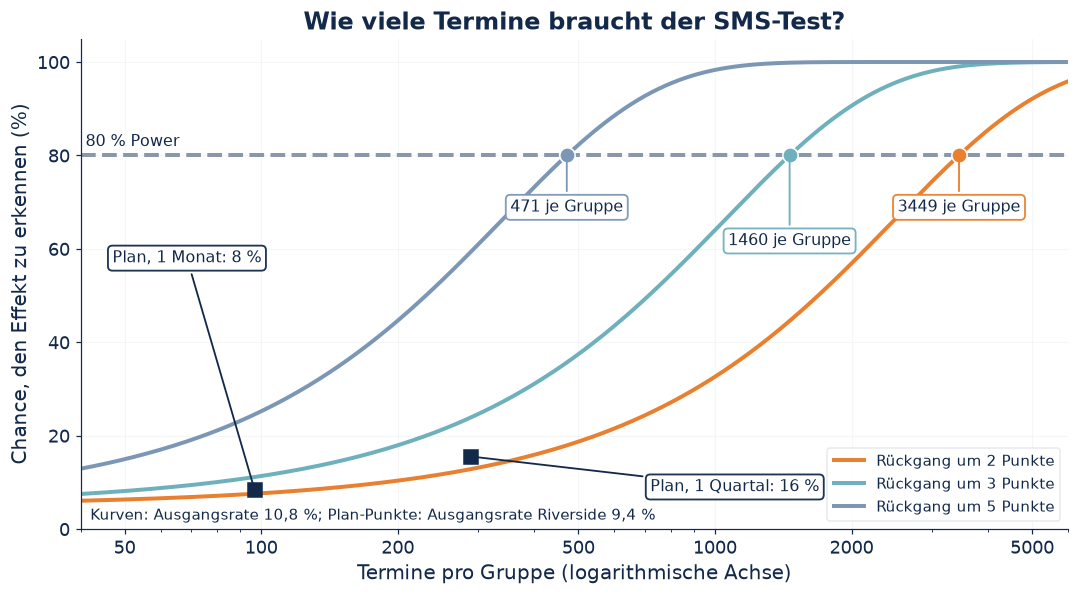

In [52]:
p0 = df.no_show.mean(); p_riv = df.loc[df.clinic_site == "Riverside", "no_show"].mean()

def power(p1, p2, n1, n2, alpha=.05):
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2); z = abs(p1 - p2) / se; zc = stats.norm.ppf(1 - alpha / 2)
    return stats.norm.sf(zc - z) + stats.norm.cdf(-zc - z)

def n_for(p1, p2, pw=.8, alpha=.05):
    return (stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(pw)) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2) ** 2

pw_monat = power(p_riv, p_riv - .02, 290 / 3, 430 / 3); pw_quartal = power(p_riv, p_riv - .02, 290, 430)
print(f"Chance, einen Rückgang um 2 Punkte zu erkennen (Ausgangsrate Riverside {p_riv * 100:.1f} %): "
      f"1 Monat {pw_monat * 100:.0f} %, 1 Quartal {pw_quartal * 100:.0f} %")
print(f"Nötige Termine je Gruppe bei Ausgangsrate {p0 * 100:.2f} % (80 % Power): "
      f"2 Punkte {n_for(p0, p0 - .02):.0f}, 3 Punkte {n_for(p0, p0 - .03):.0f}, 5 Punkte {n_for(p0, p0 - .05):.0f}")
print(f"Besuche im Log je Quartal: {len(df)} -> Dauer für 5 Punkte: {2 * n_for(p0, p0 - .05) / len(df):.1f} Quartale, für 2 Punkte: {2 * n_for(p0, p0 - .02) / len(df):.1f} Quartale")

ns = np.logspace(np.log10(40), np.log10(6000), 300)
fig, ax = plt.subplots(figsize=(10, 5.6))
for eff, col in [(2, "rosa"), (3, "pfirsich"), (5, "gruen")]:
    pw = [power(p0, p0 - eff / 100, n, n) * 100 for n in ns]
    ax.plot(ns, pw, color=LINE[col], label=f"Rückgang um {eff} Punkte")
    nn = n_for(p0, p0 - eff / 100)
    ax.plot(nn, 80, "o", color=LINE[col], ms=10, markeredgecolor="white", zorder=5)
    tag(ax, nn, 80, f"{nn:.0f} je Gruppe", LINE[col], ox=0, oy=-34 - (eff == 3) * 22, fs=10.5)
ax.axhline(80, color=LINE["grau"], ls="--"); ax.text(41, 82, "80 % Power", fontsize=10.5, color=INK)
ax.plot(290 / 3, pw_monat * 100, "s", color=INK, ms=9); ax.plot(290, pw_quartal * 100, "s", color=INK, ms=9)
tagd(ax, (290 / 3, pw_monat * 100), (47, 58), f"Plan, 1 Monat: {pw_monat * 100:.0f} %", INK, fs=10.5)
tagd(ax, (290, pw_quartal * 100), (720, 9), f"Plan, 1 Quartal: {pw_quartal * 100:.0f} %", INK, fs=10.5)
ax.set_xscale("log"); ax.set_xlim(40, 6000); ax.set_ylim(0, 105)
ax.set_xticks([50, 100, 200, 500, 1000, 2000, 5000]); ax.set_xticklabels(["50", "100", "200", "500", "1000", "2000", "5000"])
ax.set_xlabel("Termine pro Gruppe (logarithmische Achse)"); ax.set_ylabel("Chance, den Effekt zu erkennen (%)")
ax.text(42, 2, "Kurven: Ausgangsrate 10,8 %; Plan-Punkte: Ausgangsrate Riverside 9,4 %", fontsize=9.5, color=INK)
ax.set_title("Wie viele Termine braucht der SMS-Test?"); ax.legend(loc="lower right", fontsize=10); plt.tight_layout(); show()

**Aussage:** Der geplante Test hat nur eine Chance von etwa 8 bis 16 Prozent, einen echten Rückgang um 2 Punkte zu erkennen, für 80 Prozent bräuchte er rund 3.400 Termine je Gruppe, für einen Rückgang um 5 Punkte genügen rund 470.

In [53]:
# Begründung der Festlegungen im Testplan (4.1)
n5_plan = n_for(p0, p0 - .05)
pw2_plan, pw3_plan = power(p0, p0 - .02, n5_plan, n5_plan), power(p0, p0 - .03, n5_plan, n5_plan)
print(f"5 Punkte sind {5 / (p0 * 100) * 100:.0f} % der Ausgangsrate von {p0 * 100:.2f} % (fast eine Halbierung)")
print(f"Zielraten: 5 Punkte weniger = {(p0 - .05) * 100:.2f} %, 2 Punkte weniger = {(p0 - .02) * 100:.2f} %")
print(f"Je Quartal {len(df)} Besuche, bei 1:1 etwa {len(df) / 2:.0f} je Gruppe; nötig für 5 Punkte: {n5_plan:.0f} Termine je Gruppe")
print(f"Chance, bei {n5_plan:.0f} Terminen je Gruppe einen echten Rückgang um 2 Punkte zu erkennen: {pw2_plan * 100:.0f} %, um 3 Punkte: {pw3_plan * 100:.0f} %")


5 Punkte sind 47 % der Ausgangsrate von 10,75 % (fast eine Halbierung)
Zielraten: 5 Punkte weniger = 5,75 %, 2 Punkte weniger = 8,75 %
Je Quartal 1200 Besuche, bei 1:1 etwa 600 je Gruppe; nötig für 5 Punkte: 471 Termine je Gruppe
Chance, bei 471 Terminen je Gruppe einen echten Rückgang um 2 Punkte zu erkennen: 18 %, um 3 Punkte: 36 %


## 4.1 Ergänzungen zur Design-Review

**Randomisierungseinheit:** Je Termin oder je Patient? Im Log kommen auf 1.200 Besuche 1.180 verschiedene Patienten. Fast jeder Patient erscheint also nur einmal, deshalb ist das Zuteilen je Termin hier praktisch dasselbe wie je Patient. Bei wiederkehrenden Patienten müsste je Patient zugeteilt werden, damit niemand beide Varianten erlebt.

**Interferenz (Ansteckung zwischen den Gruppen):** Reden Patienten oder Familien mit Kontrollpatienten über die SMS oder wird die Erinnerung weitergegeben, verwischt der Unterschied. Das verzerrt den Effekt in Richtung null, der Test würde die SMS also eher unterschätzen als überschätzen. Die beiden Fälle, die im Plan selbst genannt werden (Anrufe in Riverside, E-Mails in Downtown), behandelt Abschnitt 4.2.

**Eine klar definierte Behandlung:** Die SMS muss in allen Terminen gleich sein (Text, Zeitpunkt, Absender). Sonst ist unklar, was genau getestet wurde.

**Testplan (vor dem Start festlegen):**

| Feld | Festlegung |
|---|---|
| Hauptmetrik (genau eine) | No-Show-Rate |
| H0 / H1 | H0: Die SMS ändert die No-Show-Rate nicht. H1: Die Raten unterscheiden sich (zweiseitig). |
| Alpha | 0,05 |
| Minimaler relevanter Effekt | 5 Prozentpunkte weniger No-Shows (knapp die Hälfte der heutigen Rate von 10,75 %) |
| Stichprobe | etwa 470 Termine je Gruppe (80 % Power), für 2 Punkte etwa 3.400 |
| Leitplanken (dürfen nicht schlechter werden) | Beschwerden und Abmeldungen von SMS, Wartezeit |
| Zuteilung | zufällig, je Termin bzw. Patient, gleichzeitig im selben Zeitraum und an denselben Standorten |

**Begründung der Festlegungen.** Die Rate liegt bei 10,75 Prozent, 5 Punkte wären fast eine Halbierung. Das ist ungefähr der kleinste Effekt, den der Test innerhalb eines Quartals über alle Standorte erkennen kann (bei 1.200 Terminen rund 600 je Gruppe, nötig sind etwa 470). Ob sich eine SMS erst ab 5 Punkten lohnt, hängt von ihren Kosten und vom Wert eines gefüllten Termins ab, beides kenne ich nicht. Die 5 Punkte setze ich deshalb als Ausgangswert an, Solace kann ihn anhand der Kosten anpassen. Der Plan erwartet nur etwa 2 Punkte: Hätte die SMS wirklich so viel Wirkung, bliebe sie mit 470 Terminen je Gruppe meist unentdeckt (Chance etwa 18 Prozent), sichtbar würde sie erst bei etwa 3.400. Der Test ist zweiseitig, weil auch ein Anstieg (zum Beispiel durch genervte Patienten) eine Entscheidung wert wäre. 80 Prozent Power heißt, dass ein echter Effekt dieser Größe in vier von fünf Durchläufen gefunden wird. Das ist die übliche Untergrenze, mehr Power würde mehr Termine kosten. Die Zahlen stehen in der Zelle vor diesem Abschnitt.


## 4.2 Vertiefung: Was während des Tests geschah und was daraus folgt

Der Plan nennt unter „Während des Tests“ zwei eigenmächtige Handlungen von Mitarbeitenden. Sie sind keine Randnotiz: Sie zeigen, was passiert, wenn ein Test nicht gegen vorhersehbares Verhalten abgesichert ist, und sie verletzen Annahme 3 (keine Interferenz) ausdrücklich. Ich prüfe beide einzeln: Wer hat entschieden, was hat sich an der Behandlung geändert, in welche Richtung verzerrt es das Ergebnis, ab wann gilt es, und lässt es sich nachträglich beheben?

| | Riverside: Front-Desk-Team ruft an | Downtown: Manager schreibt E-Mails |
|---|---|---|
| Zitat aus dem Plan | „hörte das Front-Desk-Team von Riverside, dass die Erinnerungen funktionierten, und begann, Patienten ohne hinterlegte Mobilnummer telefonisch anzurufen“ | „Der Manager von Downtown hörte von der Initiative und begann, seinen eigenen Patienten Erinnerungs-E-Mails zu senden“ |
| Wer entschied | Das Team am Empfang, nach einer Information von außen und ohne Daten dahinter | Die Standortleitung, nach Hörensagen |
| Was sich ändert | Die Behandlung ist nicht mehr „SMS“, sondern „SMS oder Anruf“. Die Anrufe gehen an Patienten, die keine SMS erreichen kann | Die Kontrolle ist nicht mehr „keine Erinnerung“, sondern „E-Mail-Erinnerung“ |
| Richtung der Verzerrung | Die Behandlung wird verstärkt: Die Wirkung der SMS wird überschätzt | Der Kontrast wird abgeschwächt: Die Wirkung der SMS wird unterschätzt |
| Verletzte Annahmen | 3 (Behandlung verändert sich), 1 (wer angerufen wird, hängt an der Handynummer, nicht am Zufall), 5 (die Kennzahl misst jetzt ein Paket) | 3 (Kontrolle erlebt nicht mehr den Status quo) |
| Nachträglich prüfbar? | Nein, Anrufe sind nirgends erfasst | Nein, Versand und Empfänger sind nirgends erfasst |

**Was daraus folgt:**

1. **Die Behandlung ist nicht mehr die geplante.** Ab dem 15. März bekommt ein Teil der Riverside-Patienten eine SMS, ein anderer Teil einen Anruf. Der Arm „SMS“ enthält damit Patienten, die nie eine SMS erhalten haben, und eine zweite Maßnahme, die vermutlich stärker wirkt als eine SMS, weil sie persönlicher ist (Vermutung, im Log nicht prüfbar). Was der Test am Ende misst, ist ein „Erinnerungspaket“ und nicht die SMS.
2. **Wer angerufen wird, ist nicht zufällig.** Patienten ohne hinterlegte Mobilnummer unterscheiden sich vermutlich von den übrigen (Alter, Erreichbarkeit, Versicherung). Das ist Annahme 1 im Kleinen: Die Auswahl hängt an einer Eigenschaft der Patienten und nicht am Los. Im Besuchslog steht keine Telefonnummer, ich kann den Anteil nicht schätzen.
3. **Die Kontrolle ist nicht mehr der Status quo, aber der Plan merkt es nicht.** Der Vergleich nutzt Downtown im Februar, also vor den E-Mails. Behebt man den Fehler der Gleichzeitigkeit (Downtown im März), trägt man die E-Mails in den Vergleich: Die Korrektur von Annahme 4 deckt die Verletzung von Annahme 3 erst auf.
4. **Zwei Verzerrungen mit entgegengesetztem Vorzeichen.** Die Anrufe vergrößern den Abstand, die E-Mails verkleinern ihn. Der Nettoeffekt ist unbekannt. Ein sichtbarer Rückgang könnte von den Anrufen stammen, ein ausbleibender könnte durch die E-Mails verdeckt sein. Beide Ergebnisse wären nicht zu deuten.
5. **Es lässt sich nicht herausrechnen.** Wie viele Patienten angerufen oder angeschrieben wurden, wer und wann, steht nirgends. Auch eine Auswertung „nur der Patienten mit SMS“ hilft nicht: Das wäre eine Auswahl nach der Handynummer und damit selbst verzerrt.
6. **Die Mitarbeitenden kannten die Zwischenstände.** „hörte, dass die Erinnerungen funktionierten“ zeigt, dass ein Eindruck ohne Daten das Verhalten geändert hat. Zwischenstände eines laufenden Tests gehören deshalb nur dem Auswerteteam.
7. **Das ist kein Fehlverhalten, sondern ein Designfehler.** Beide Gruppen wollten helfen. Dass sich ein vermeintlicher Erfolg herumspricht und Nachahmung auslöst, war vorhersehbar und hätte im Plan durch Regeln abgesichert werden müssen.

**Zeitliche Einordnung:** „Nach zwei Wochen“ heißt bei Start am 1. März ab dem 15. März. Die folgende Zelle zählt, wie viele Besuche des Testmonats danach liegen. Das Besuchslog enthält keine SMS, die Zahlen zeigen also nur die Größenordnung der Phasen und nicht die Wirkung einer Maßnahme.

Riverside im März: 98 Besuche, davon ab dem 15. März 58 (59,2 %), davor 40
Downtown im März: 137 Besuche, davon ab dem 15. März 74 (54,0 %), davor 63


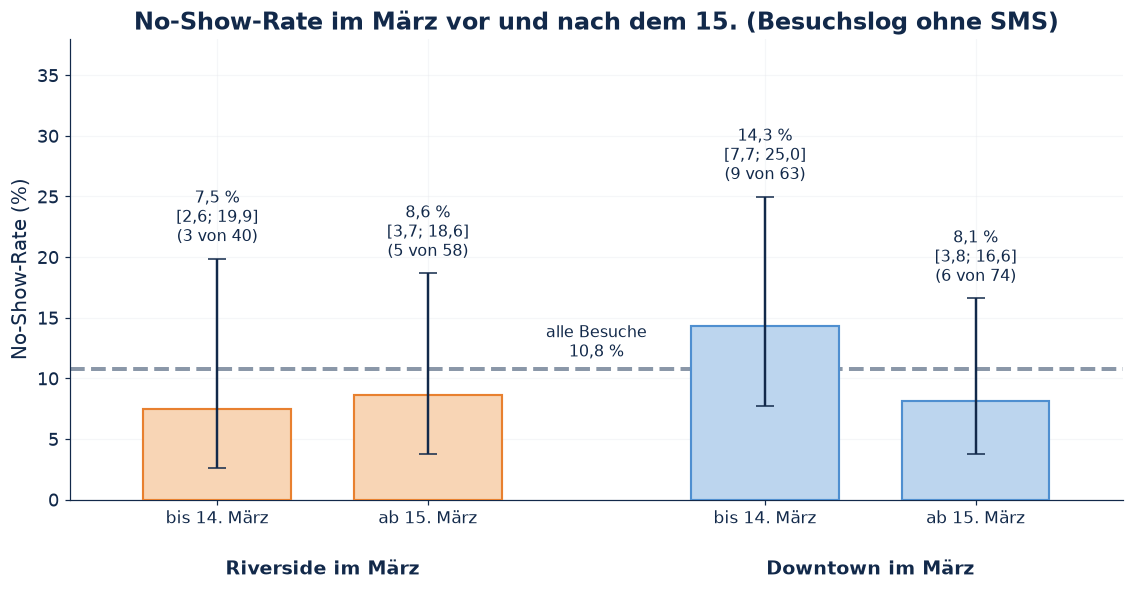

In [54]:
# 4.2a Zeitliche Einordnung: ab wann galten die Eigenmächtigkeiten? ("nach zwei Wochen" = ab dem 15. März bei Start am 1. März)
GRENZE = pd.Timestamp("2026-03-15")
mar = voll[voll.monat.astype(str) == "2026-03"].copy(); mar["datum"] = pd.to_datetime(mar.appointment_date)
phasen = {}
for st in ["Riverside", "Downtown"]:
    f = mar[mar.clinic_site == st]
    phasen[st] = {"erste zwei Wochen": f[f.datum < GRENZE], "ab dem 15. März": f[f.datum >= GRENZE]}
    n_ges = len(f); n_sp = len(phasen[st]["ab dem 15. März"])
    print(f"{st} im März: {n_ges} Besuche, davon ab dem 15. März {n_sp} ({n_sp / n_ges * 100:.1f} %), davor {n_ges - n_sp}")
anteil_spaet = len(phasen["Riverside"]["ab dem 15. März"]) / sum(len(v) for v in phasen["Riverside"].values()) * 100

fig, ax = plt.subplots(figsize=(10.5, 5.8))
xpos = {("Riverside", "erste zwei Wochen"): 0, ("Riverside", "ab dem 15. März"): 1, ("Downtown", "erste zwei Wochen"): 2.6, ("Downtown", "ab dem 15. März"): 3.6}
for (st, ph), x in xpos.items():
    f = phasen[st][ph]; k, n = int(f.no_show.sum()), len(f); p, lo, hi = wilson(k, n)
    ax.bar(x, p * 100, width=.7, color=PASTEL[SITE_COL[st]], edgecolor=LINE[SITE_COL[st]], lw=1.4, zorder=3)
    ax.errorbar(x, p * 100, yerr=[[(p - lo) * 100], [(hi - p) * 100]], color=INK, capsize=6, lw=1.6, zorder=4)
    ax.text(x, hi * 100 + 1.0, f"{p * 100:.1f} %\n[{lo * 100:.1f}; {hi * 100:.1f}]\n({k} von {n})", ha="center", va="bottom", fontsize=10.5, color=INK, zorder=5)
ax.set_xticks([0, 1, 2.6, 3.6]); ax.set_xticklabels(["bis 14. März", "ab 15. März", "bis 14. März", "ab 15. März"], fontsize=11)
for x, t in [(.5, "Riverside im März"), (3.1, "Downtown im März")]:
    ax.text(x, -.13, t, ha="center", va="top", fontsize=12.5, fontweight="bold", color=INK, transform=ax.get_xaxis_transform())
ax.set_ylim(0, 38); ax.set_xlim(-.7, 4.3); ax.set_ylabel("No-Show-Rate (%)")
ax.set_title("No-Show-Rate im März vor und nach dem 15. (Besuchslog ohne SMS)")
ax.axhline(df.no_show.mean() * 100, color=LINE["grau"], ls="--", zorder=2)
ax.text(1.8, df.no_show.mean() * 100 + .6, f"alle Besuche\n{df.no_show.mean() * 100:.1f} %", ha="center", va="bottom", fontsize=10.5, color=INK)
plt.tight_layout(); plt.subplots_adjust(bottom=.2); show()

**Aussage:** Ab dem 15. März liegen 58 von 98 Riverside-Besuchen (59 %), Anrufe und E-Mails betreffen also mehr als die Hälfte des Testmonats, und selbst ohne jede Maßnahme schwankt die Halbmonatsrate stark (Downtown 14,3 % und 8,1 %, Intervalle [7,7; 25,0] und [3,8; 16,6]).

**Einordnung:**
- **Zwei Phasen in einem Arm:** Nur etwa 41 % der Riverside-Besuche liegen vor der Änderung. Die Behandlung gilt im Mittel für keinen der beiden Zustände rein.
- **Die Phasen lassen sich nicht trennen:** Mit 40 und 58 Besuchen überlappen sich die Intervalle fast vollständig. Auch ein Vorher-Nachher-Vergleich innerhalb des März würde nichts belegen.
- **Natürliche Schwankung:** Downtown fällt im März ohne jede Maßnahme (im Log) von 14,3 % auf 8,1 %, ein Rückgang von 6,2 Punkten innerhalb eines Monats. Schwankungen dieser Größe sind bei so kleinen Gruppen normal und größer als der erwartete SMS-Effekt von 2 Punkten.

Riverside Januar bis März: 9,5 % (26 von 274), Downtown: 11,8 % (48 von 407)
Standortunterschied -2,3 | Monatsunterschied (alle Standorte, März minus Februar) -3,2 | Summe -5,5 | Plan-Vergleich -4,8 | Rest +0,7 Punkte
Zwölf Standort-Monate (Januar bis März, vier Standorte): von 7,1 % bis 15,3 %, Standardabweichung 2,6 Punkte


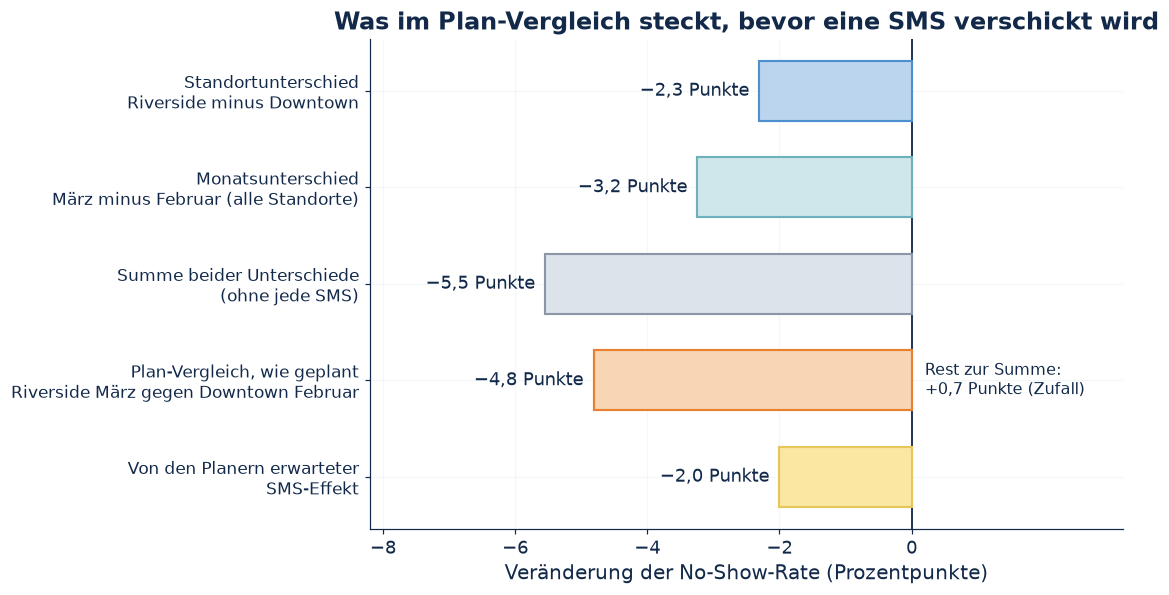

No-Show-Rate je Standort, gesamter Zeitraum: {'Downtown': 11,6, 'Eastview': 12,7, 'Northgate': 9,1, 'Riverside': 9,4}
Eastview: Januar 15,3 % (9 von 59), Februar und März zusammen 12,1 % (18 von 149), ohne SMS
Vier Kennzahlen mit je 5 % Fehlalarmrisiko: Chance auf mindestens einen Fehlalarm 18,5 %, Bonferroni-Schwelle je Kennzahl 0,0125


In [55]:
# 4.2b Was steckt im Plan-Vergleich? Standort- und Monatsunterschied ohne jede SMS
je_standort = voll.groupby("clinic_site").no_show.agg(["mean", "sum", "count"])
standort_diff = (je_standort.loc["Riverside", "mean"] - je_standort.loc["Downtown", "mean"]) * 100
monat_diff = tab4["Alle Standorte"][2][0] - tab4["Alle Standorte"][1][0]
plan_diff = rv_mar[0] - dt_feb[0]
summe_diff = standort_diff + monat_diff; rest_diff = plan_diff - summe_diff
print(f"Riverside Januar bis März: {je_standort.loc['Riverside', 'mean'] * 100:.1f} % ({int(je_standort.loc['Riverside', 'sum'])} von {int(je_standort.loc['Riverside', 'count'])}), "
      f"Downtown: {je_standort.loc['Downtown', 'mean'] * 100:.1f} % ({int(je_standort.loc['Downtown', 'sum'])} von {int(je_standort.loc['Downtown', 'count'])})")
print(f"Standortunterschied {standort_diff:.1f} | Monatsunterschied (alle Standorte, März minus Februar) {monat_diff:.1f} | Summe {summe_diff:.1f} | Plan-Vergleich {plan_diff:.1f} | Rest {rest_diff:+.1f} Punkte")

zellen = voll.groupby(["clinic_site", "monat"]).no_show.mean() * 100
sd_zellen, min_zelle, max_zelle = zellen.std(), zellen.min(), zellen.max()
print(f"Zwölf Standort-Monate (Januar bis März, vier Standorte): von {min_zelle:.1f} % bis {max_zelle:.1f} %, Standardabweichung {sd_zellen:.1f} Punkte")

fig, ax = plt.subplots(figsize=(10.5, 5.6))
balken = [("Standortunterschied\nRiverside minus Downtown", standort_diff, "blau"),
          ("Monatsunterschied\nMärz minus Februar (alle Standorte)", monat_diff, "pfirsich"),
          ("Summe beider Unterschiede\n(ohne jede SMS)", summe_diff, "grau"),
          ("Plan-Vergleich, wie geplant\nRiverside März gegen Downtown Februar", plan_diff, "rosa"),
          ("Von den Planern erwarteter\nSMS-Effekt", -2.0, "gelb")]
for k, (txt, val, col) in enumerate(balken):
    ax.barh(k, val, height=.62, color=PASTEL[col], edgecolor=LINE[col], lw=1.4, zorder=3)
    ax.text(val - .15, k, f"{val:.1f} Punkte".replace("-", "−"), ha="right", va="center", fontsize=11.5, color=INK, zorder=5)
ax.set_yticks(range(len(balken))); ax.set_yticklabels([b[0] for b in balken], fontsize=11); ax.invert_yaxis()
ax.axvline(0, color=INK, lw=1.2)
ax.set_xlim(-8.2, 3.2); ax.set_xticks(range(-8, 1, 2)); ax.set_xlabel("Veränderung der No-Show-Rate (Prozentpunkte)")
ax.text(.2, 3, f"Rest zur Summe:\n{rest_diff:+.1f} Punkte (Zufall)".replace("-", "−"), ha="left", va="center", fontsize=10.5, color=INK)
ax.set_title("Was im Plan-Vergleich steckt, bevor eine SMS verschickt wird")
plt.tight_layout(); show()

# Weitere Stellen im Plantext
je_st_gesamt = (df.groupby("clinic_site").no_show.mean() * 100).round(1).to_dict()
print("No-Show-Rate je Standort, gesamter Zeitraum:", je_st_gesamt)
ev = voll[voll.clinic_site == "Eastview"]
ev_jan = ev[ev.monat.astype(str) == "2026-01"]; ev_sp = ev[ev.monat.astype(str) != "2026-01"]
print(f"Eastview: Januar {ev_jan.no_show.mean() * 100:.1f} % ({int(ev_jan.no_show.sum())} von {len(ev_jan)}), Februar und März zusammen {ev_sp.no_show.mean() * 100:.1f} % ({int(ev_sp.no_show.sum())} von {len(ev_sp)}), ohne SMS")
p_mind1 = 1 - .95 ** 4
print(f"Vier Kennzahlen mit je 5 % Fehlalarmrisiko: Chance auf mindestens einen Fehlalarm {p_mind1 * 100:.1f} %, Bonferroni-Schwelle je Kennzahl {.05 / 4:.4f}")

**Aussage:** Ohne jede SMS erklären Standort (−2,3 Punkte) und Monat (−3,2 Punkte) zusammen −5,5 Punkte, der Plan-Vergleich zeigt −4,8: Der scheinbare Rückgang ist schon vor der ersten SMS da, und der erwartete SMS-Effekt von −2,0 Punkten geht darin unter.

**Einordnung:**
- **Rechnung:** Standortunterschied = Rate Riverside minus Rate Downtown über Januar bis März (9,5 % gegen 11,8 %), Monatsunterschied = Rate aller Standorte im März minus im Februar (9,4 % gegen 12,6 %). Der Rest von +0,7 Punkten ist Zufall und Wechselwirkung. Es ist eine grobe Zerlegung aus zwei Differenzen, kein Modell, und die Anteile sind unsicher.
- **Was sie zeigt:** Der Plan-Vergleich hätte auch dann einen „Erfolg“ gemeldet, wenn die SMS nichts bewirkt hätte. Ein Ergebnis, das sich schon ohne die Maßnahme einstellt, kann sie nicht belegen.
- **Natürliche Streuung zwischen den Standorten:** Die zwölf Standort-Monate (Januar bis März) liegen zwischen 7,1 % und 15,3 %, die Standardabweichung beträgt 2,6 Punkte. Der erwartete Effekt von 2 Punkten liegt unter dieser Streuung. Mehr dazu in Zusatz 3.

**Weitere Stellen im Plantext, die das Urteil stützen.**

- **Das Ziel ist ein Beweisauftrag.** „Zeigen Sie, dass die SMS-Erinnerung No-Shows reduziert“ legt das Ergebnis vor dem Test fest. Ein Test fragt ergebnisoffen, ob es einen Unterschied gibt (H0: Die SMS ändert nichts). Wer „zeigen“ soll, sucht Belege für eine Antwort, und das erklärt auch, warum Mitarbeitende aus Überzeugung nachhelfen. Das ist durch Umformulieren behebbar.
- **Auswahl nach dem höchsten Wert (Regression zur Mitte).** „weil die No-Show-Rate dort am höchsten ist“: Wer einen Standort wegen eines Spitzenwerts wählt, sieht bei der nächsten Messung meist weniger, auch ohne Maßnahme. Im Log hatte Eastview im Januar 15,3 % (9 von 59) und im Februar und März zusammen 12,1 % (18 von 149), ohne SMS. Das ist ein Beispiel für das Muster und kein Beweis, die Gruppen sind klein. Außerdem stimmt die Begründung im Log nicht: Riverside liegt mit 9,4 % unter Downtown (11,6 %) und Eastview (12,7 %).
- **Die Messung ist nicht identisch.** „weil die Februar-Zahlen … bereits bereinigt und geladen wurden“: Februar ist bereinigt, März nicht. Mein Audit zeigt, was das ausmacht: 9 doppelte Zeilen und 129 No-Shows, die trotzdem Wartezeit, Dauer und Kosten haben. Die Größenordnung ist hier klein, das Prinzip nicht: Beide Arme brauchen dieselbe Definition von „No-Show“ und dieselbe Bereinigung.
- **Vier Kennzahlen, ein Fehlalarmrisiko.** „berichten, was sich davon bewegt“ prüft No-Shows, Wartezeit, Zufriedenheit und Umsatz. Mit vier Kennzahlen und je 5 % Fehlalarmrisiko liegt die Chance auf mindestens einen Fehlalarm bei 18,5 % (näherungsweise, für unabhängige Tests), bei Bonferroni-Korrektur wäre die Schwelle je Kennzahl 0,0125. Wer nach dem Ergebnis auswählt, was er berichtet, findet fast immer etwas. Behebbar: eine primäre Kennzahl, die anderen als Leitplanken.
- **Ein Standort je Arm heißt: eine Einheit je Arm.** Gezählt werden Besuche (98 und 137 im März), zugeteilt wird der Standort. Die Besuche eines Standorts teilen Personal, Manager und Einzugsgebiet und sind keine unabhängigen Wiederholungen. Der Standortunterschied lässt sich deshalb nicht von der SMS trennen, egal wie viele Besuche man zählt.

### Gegenprobe: Welche Annahme entscheidet das Urteil, und warum die anderen es nicht tun

Ich repariere jeweils **nur eine** Annahme und frage, ob der Plan danach trägt:

| Allein repariert | Was danach noch gilt | Trägt der Plan? |
|---|---|---|
| 4 Gleichzeitigkeit (beide Arme im März) | Ein Standort je Arm: Manager, Wartezeit (8,6 Minuten länger in Riverside) und Patientenmix bleiben mit der SMS vermischt | Nein |
| 5 Kennzahl vorab (eine primäre, gleich gemessen) | Wie oben | Nein |
| 6 Power (mehr Termine oder längere Laufzeit) | Mehr Besuche machen den Standortunterschied nur noch deutlicher signifikant, nicht der SMS zuschreibbar (Beispiel: der Wartezeitunterschied mit p ≈ 10⁻³⁶ hat mit der SMS nichts zu tun) | Nein, es verschlimmert es |
| 3 Interferenz (Protokoll gegen Anrufe und E-Mails) | Wie oben | Nein |
| 1 Zufällige Zuteilung je Termin, alle Standorte, selber Zeitraum | Standort und Monat sind in beiden Armen gleich verteilt, die Unabhängigkeit (2) ist mit erledigt | Ja, die übrigen Punkte werden dann erst sinnvoll |

**Aussage:** Nur Annahme 1 hat die Eigenschaft, dass die Reparatur aller anderen nichts nützt, solange sie verletzt bleibt, und dass ihre Reparatur Standort und Zeitraum in beide Arme gleich verteilt.

**Warum die anderen fünf für sich genommen nicht ausschlaggebend sind:** Gleichzeitigkeit, Kennzahl, Ziel und Power lassen sich durch Umschreiben oder Planen beheben, ohne dass sich an der Art des Vergleichs etwas ändert. Die Interferenz ist für diesen Lauf nicht mehr rückgängig zu machen, in einem neuen lässt sie sich per Protokoll verhindern. Die Zuteilung dagegen entscheidet, **was** verglichen wird (Standorte statt Termine), und das ist ein neues Design.

### Wenn eine zufällige Zuteilung je Termin nicht möglich ist

| Alternative | Stärke | Schwäche |
|---|---|---|
| **Gestaffelte Einführung:** Alle vier Standorte bekommen die SMS, der Starttermin wird ausgelost. Vergleich: Standorte vor und nach der Einführung, Standorte ohne SMS als Kontrolle | Jeder Standort ist seine eigene Kontrolle, das Los schützt vor Auswahl durch Freiwilligkeit | Nur vier Einheiten, Saison und Ansteckung zwischen Standorten bleiben möglich, Ergebnis ist eine Beobachtung mit Einschränkungen |
| **Vorher-Nachher an einem Standort** | Einfach | Schwächste Variante: Saison und Regression zur Mitte sind nicht von der SMS zu trennen |
| **Einführen ohne Test** (die SMS ist billig und risikoarm) | Kein Aufwand für ein Design, das nicht tragen würde | Es gibt keine Wirkungsaussage, nur Beobachtung von No-Show-Rate und Leitplanken |

### Protokoll für einen neuen Lauf, damit sich Eigenmächtigkeit nicht wiederholt

- **Schriftliche Regeln für alle Standorte** vor dem Start: Erinnerungen gehen nur über den Test, Anrufe und E-Mails entweder für alle gleich oder gar nicht. Schulung des Empfangs und der Standortleitungen.
- **Zuteilung automatisch im System**, nicht durch das Personal, damit niemand auswählen oder nachhelfen kann.
- **Kontaktfeld je Termin** („SMS / Anruf / E-Mail / keine“, mit Datum). So wird jede Abweichung messbar und kann ausgewertet werden.
- **Auswertung nach Zuteilung**, nicht nach tatsächlicher Behandlung (Intention-to-treat). Abweichungen gehen als Nebenauswertung ein.
- **Keine Zwischenergebnisse an die Standorte.** Nur das Auswerteteam sieht Zwischenstände, ein Abbruch folgt vorab festgelegten Kriterien.
- **Die Beobachtung der Mitarbeitenden ernst nehmen:** Wenn der Empfang glaubt, dass Anrufe helfen, ist das eine eigene Hypothese. Sie lässt sich in einem zweiten Test prüfen (Patienten ohne Mobilnummer: Anruf gegen kein Anruf, zufällig zugeteilt). Der Anteil der Patienten ohne Nummer ist im Log nicht erfasst und müsste vorher erhoben werden, weil er die Fallzahl bestimmt.

## Weiterführende Auswertungen

Die folgenden achtzehn Auswertungen vertiefen die Tests. Sie sind beschreibend, liefern keine zusätzlichen Testergebnisse und ändern keine Aussage der Tests. Zusatz 4 bis 7 behandeln die Regressionsanalyse (lineare Regression, R², Koeffizienten, p-Werte, ausgelassene Variablen); Zusatz 7 erklärt die Wartezeit mit den Betriebsdaten, Zusatz 8 und 9 behandeln die Versuchsplanung (Mehrfachprüfung, Größenverhältnis, Relevanzgrenze, Stichprobe, Darstellung), Zusatz 10 die Modellgüte der Regression (Modellgüte, Zufallsspalten, Tag 37), Zusatz 11 Wahrscheinlichkeitsmodelle mit den Projektdaten (Bayes, Binomial, Poisson, Gamma, Perzentile), Zusatz 12 die Vorhersage für neue Tage (Kreuzvalidierung, Vorhersageintervall), Zusatz 13 die logistische Regression für No-Show, Zusatz 14 Signifikanz und praktische Bedeutung (Permutationstest, Stichprobengröße, Koeffizienten je Standardabweichung, Mehrfachprüfung), Zusatz 15 was das Modell nicht erfassen kann (Zerlegung bei ausgelassenen Variablen, alle Teilmodelle, Confounding-Simulation, Kollider), Zusatz 16 die Diagnose des Betriebsdaten-Modells (einflussreiche Tage, robuste und Bootstrap-Intervalle, Wechselwirkungen und Krümmung), Zusatz 17 die Kapazitätsplanung (Personal je Patientenzahl für das 15-Minuten-Versprechen) und Zusatz 18 die Zufriedenheit mit mehreren Einflussgrößen samt Mediation über die Wartezeit. Sie prüfen nur, ob die Aussagen auch in Teilgruppen halten (Zusatz 1), wie gut der Welch-Test kleine Unterschiede erkennt (Zusatz 2) und warum der SMS-Plan Standort und Monat nicht trennen kann (Zusatz 3). Grundlage sind die bereinigten Daten (n = 1.200).


**Lesehilfe nach Themen** (die Nummern bleiben, so wie sie im Abgabedokument und in der Zusammenfassung stehen):

| Thema | Zusätze | Leitfrage |
|---|---|---|
| Standortvergleich, Tests und Stichprobe | 1, 2, 3, 8, 9, 14 | Hält der Unterschied in Teilgruppen, wie sicher und wie relevant ist er, und was kann der SMS-Plan überhaupt zeigen? |
| Regression und Grenzen des Modells | 4, 5, 6, 7, 10, 12, 15, 16, 17, 18 | Was erklärt die Wartezeit, wie stabil ist das Modell, und was kann es nicht erfassen (ausgelassene Variablen, Confounder, Kollider)? |
| Wahrscheinlichkeit und No-Show | 11, 13 | Welche Verteilungen passen zu den Daten, und was sagt die Terminart über No-Shows? |

Zusatz 6 und 15 gehören zusammen (ausgelassene Variablen), ebenso Zusatz 7, 12 und 17 (Modell, Vorhersage, Planung) sowie 4 und 18 (Zufriedenheit), ebenso Zusatz 2, 9 und 14b (Stichprobengröße und Aussagekraft) sowie Zusatz 3, 8 und 14d (viele Vergleiche, Fehlalarme).

### Zusatz 1: Gilt der Standortunterschied in jeder Teilgruppe?

Die Differenz der mittleren Wartezeit (Riverside minus Downtown) wird je Terminart, Wochentag und Versicherungsart mit Welch-Intervall gezeigt. Das orange Gesamtintervall (8,6 [7,3; 9,8]) ist als blaues Band durchgezogen, damit man die Teilgruppen damit vergleichen kann. Es sind 15 Intervalle zu je 95 %, die Auswertung ist deshalb erkundend und kein neuer Test. Kleine Gruppen haben breite Intervalle (Specialist: 35 gegen 38 Besuche), und am Mittwoch reicht das Intervall bis 3,1 Minuten, also unter die Schwelle von 5 Minuten. Eine Korrektur für die 15 Prüfungen folgt in Zusatz 8.

      Gruppe  Differenz  untere  obere  n Riverside  n Downtown
      Gesamt       8,60    7,30   9,80          286         430
     Checkup       8,00    6,00   9,90          110         194
   Follow-up      10,30    7,90  12,70           78         119
  Specialist       7,50    3,60  11,40           35          38
      Urgent       8,30    5,60  11,10           63          79
      Montag      10,30    6,80  13,70           31          64
    Dienstag      10,00    6,70  13,30           44          55
    Mittwoch       5,90    3,10   8,60           48          67
  Donnerstag       7,40    3,40  11,50           36          60
     Freitag       8,80    5,50  12,10           44          58
     Samstag       9,20    5,60  12,80           41          56
     Sonntag       8,80    5,80  11,90           42          70
      Privat       8,60    6,30  10,90           97         147
    Medicare       8,10    6,00  10,20           83         134
    Medicaid       7,50    4,60  10,30  

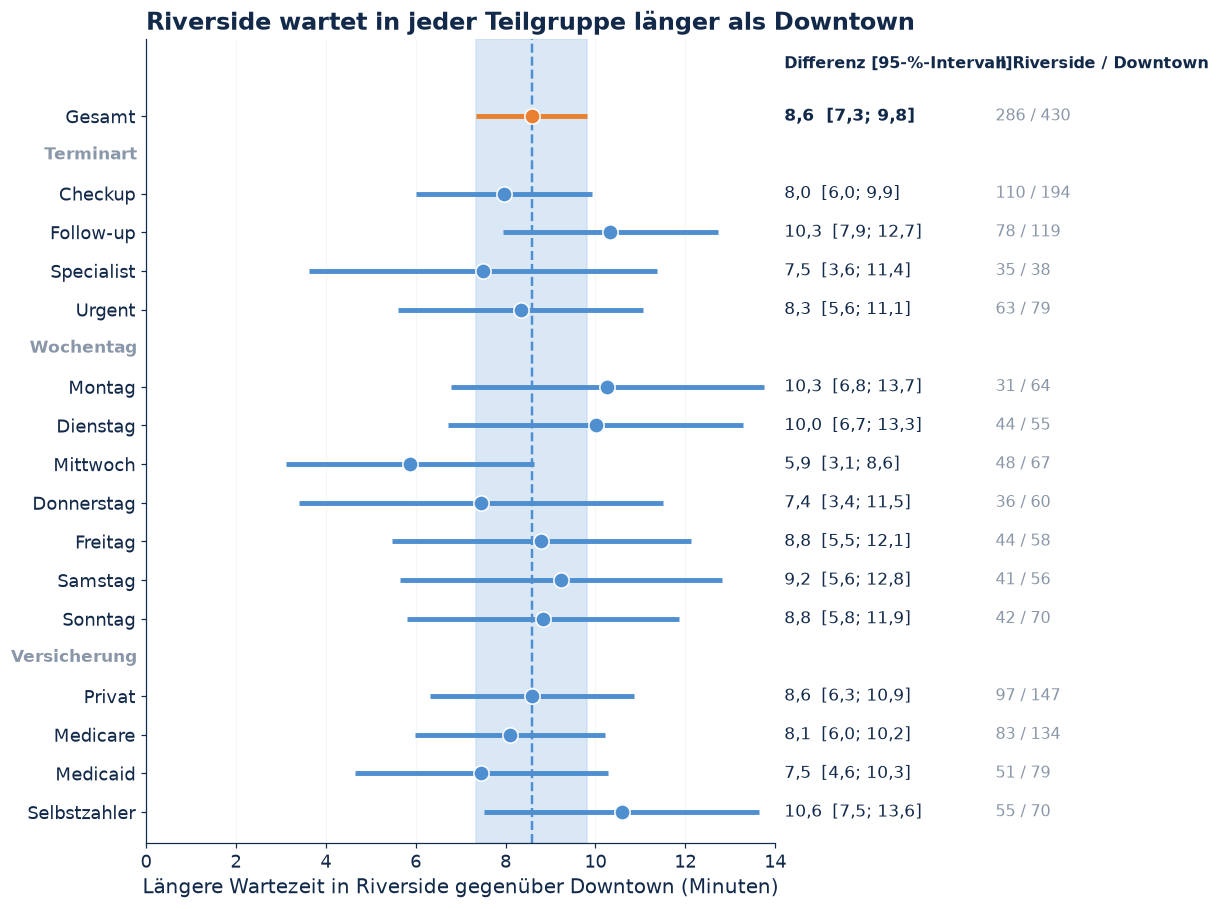

Kleinste Differenz einer Teilgruppe: 5,9 Min (Mittwoch), größte: 10,6 Min (Selbstzahler)
Teilgruppen, deren Intervall die 0 einschließt: 0 von 15


In [56]:
# Zusatz 1: Gilt der Standortunterschied in jeder Teilgruppe? Differenz Riverside − Downtown mit 95-%-Intervall
def zusatz_teilgruppen():
    TAGE = {"Monday": "Montag", "Tuesday": "Dienstag", "Wednesday": "Mittwoch", "Thursday": "Donnerstag",
            "Friday": "Freitag", "Saturday": "Samstag", "Sunday": "Sonntag"}
    VERS = {"Private": "Privat", "Medicare": "Medicare", "Medicaid": "Medicaid", "Self-pay": "Selbstzahler"}
    gruppen = [("Gesamt", None, None)]
    gruppen += [(t, "appointment_type", t) for t in ["Checkup", "Follow-up", "Specialist", "Urgent"]]
    gruppen += [(TAGE[t], "day_of_week", t) for t in TAGE]
    gruppen += [(VERS[v], "insurance_type", v) for v in VERS]

    def diff_ci(a, b, level=.95):
        d = a.mean() - b.mean(); se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        h = stats.t.ppf((1 + level) / 2, welch_df(a, b)) * se
        return d, d - h, d + h

    zeilen = []
    for name, spalte, wert in gruppen:
        sub = df if spalte is None else df[df[spalte] == wert]
        r = sub[sub.clinic_site == "Riverside"].wait_time_min.dropna(); dt = sub[sub.clinic_site == "Downtown"].wait_time_min.dropna()
        d_, lo_, hi_ = diff_ci(r, dt); zeilen.append((name, d_, lo_, hi_, len(r), len(dt)))
    tab = pd.DataFrame(zeilen, columns=["Gruppe", "Differenz", "untere", "obere", "n Riverside", "n Downtown"])
    print(tab.round(1).to_string(index=False))

    fig, ax = plt.subplots(figsize=(11, 8.6))
    y = 0; ypos = []; kopf = {1: "Terminart", 5: "Wochentag", 12: "Versicherung"}
    gesamt = tab.iloc[0]
    ax.axvspan(gesamt.untere, gesamt.obere, color=PASTEL["blau"], alpha=.55, zorder=0)
    ax.axvline(gesamt.Differenz, color=LINE["blau"], lw=1.6, ls="--", zorder=1)
    for i, z in tab.iterrows():
        y = i + (1 if i >= 1 else 0) + (1 if i >= 5 else 0) + (1 if i >= 12 else 0)
        ypos.append(y)
        farbe = LINE["rosa"] if i == 0 else LINE["blau"]
        ax.hlines(y, z.untere, z.obere, color=farbe, lw=3.2, zorder=2)
        ax.plot(z.Differenz, y, "o", color=farbe, ms=10, markeredgecolor="white", zorder=3)
        ax.text(14.2, y, f"{z.Differenz:.1f}  [{z.untere:.1f}; {z.obere:.1f}]", va="center", ha="left", fontsize=11, fontweight="bold" if i == 0 else "normal")
        ax.text(18.9, y, f"{int(z['n Riverside'])} / {int(z['n Downtown'])}", va="center", ha="left", fontsize=10.5, color=LINE["grau"])
    for i, t in kopf.items():
        yk = ypos[i] - 1
        ax.text(-0.2, yk, t, va="center", ha="right", fontsize=11, fontweight="bold", color=LINE["grau"])
    ax.axvline(0, color=INK, lw=1.2)
    ax.set_yticks(ypos); ax.set_yticklabels(tab.Gruppe); ax.invert_yaxis()
    ax.set_xlim(0, 14); ax.set_xlabel("Längere Wartezeit in Riverside gegenüber Downtown (Minuten)")
    ax.text(14.2, -1.35, "Differenz [95-%-Intervall]", ha="left", va="center", fontsize=10.5, color=INK, fontweight="bold")
    ax.text(18.9, -1.35, "n Riverside / Downtown", ha="left", va="center", fontsize=10.5, color=INK, fontweight="bold")
    ax.set_ylim(ypos[-1] + .8, -2)
    ax.grid(axis="y", visible=False)
    ax.set_title("Riverside wartet in jeder Teilgruppe länger als Downtown", loc="left")
    plt.subplots_adjust(left=.14, right=.66, top=.93, bottom=.08)
    show()
    teil = tab.iloc[1:]
    print(f"Kleinste Differenz einer Teilgruppe: {teil.Differenz.min():.1f} Min ({teil.loc[teil.Differenz.idxmin(), 'Gruppe']}), "
          f"größte: {teil.Differenz.max():.1f} Min ({teil.loc[teil.Differenz.idxmax(), 'Gruppe']})")
    print("Teilgruppen, deren Intervall die 0 einschließt:", int((teil.untere <= 0).sum()), "von", len(teil))


zusatz_teilgruppen()


**Aussage:** Riverside wartet in allen 15 Teilgruppen länger als Downtown (Differenzen von 5,9 bis 10,6 Minuten, kein Intervall schließt die 0 ein), der Unterschied hängt also nicht an einem einzelnen Wochentag, einer Terminart oder Versicherungsart.


### Zusatz 2: Wie klein darf ein Unterschied sein, damit der Welch-Test ihn noch erkennt?

Die Kurve zeigt die Teststärke (Wahrscheinlichkeit, einen echten Unterschied zu erkennen) in Abhängigkeit vom wahren Unterschied. Sie gehört zu den Fehlern 1. und 2. Art: Links bei 0 liegt α = 5 %, die Gefahr eines Übersehens (β) ist 100 % minus der Teststärke.


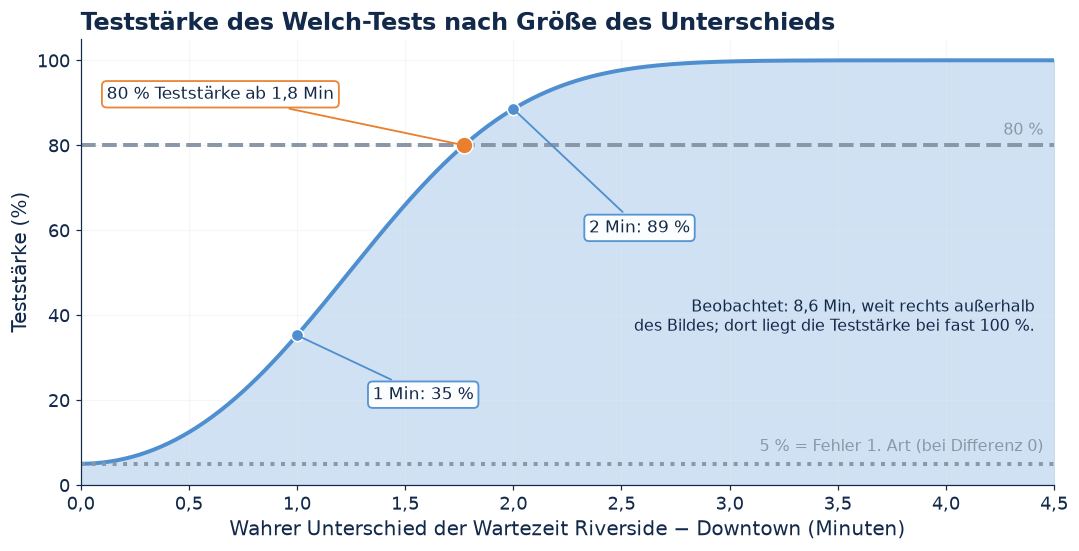

Standardfehler 0,632 | kleinster Unterschied mit 80 % Teststärke: 1,77 Min


In [57]:
# Zusatz 2: Teststärke des Welch-Tests in Abhängigkeit vom wahren Unterschied
def zusatz_teststaerke():
    a_ = df[df.clinic_site == "Riverside"].wait_time_min.dropna(); b_ = df[df.clinic_site == "Downtown"].wait_time_min.dropna()
    se_w = np.sqrt(a_.var(ddof=1) / len(a_) + b_.var(ddof=1) / len(b_))
    z_a = stats.norm.ppf(1 - .05 / 2)
    delta = np.linspace(0, 4.5, 400)
    power_kurve = stats.norm.cdf(delta / se_w - z_a) + stats.norm.cdf(-delta / se_w - z_a)
    mde_w = (z_a + stats.norm.ppf(.80)) * se_w
    fig, ax = plt.subplots(figsize=(10, 5.2))
    ax.fill_between(delta, power_kurve * 100, color=PASTEL["blau"], alpha=.7)
    ax.plot(delta, power_kurve * 100, color=LINE["blau"])
    ax.axhline(80, color=LINE["grau"], ls="--"); ax.axhline(5, color=LINE["grau"], ls=":")
    ax.plot(mde_w, 80, "o", color=LINE["rosa"], ms=11, markeredgecolor="white", zorder=5)
    tagd(ax, (mde_w, 80), (.12, 92), f"80 % Teststärke ab {mde_w:.1f} Min", LINE["rosa"])
    ax.text(4.45, 82.5, "80 %", ha="right", fontsize=10.5, color=LINE["grau"])
    ax.text(4.45, 8, "5 % = Fehler 1. Art (bei Differenz 0)", ha="right", fontsize=10.5, color=LINE["grau"])
    for dd in (1, 2):
        p_ = (stats.norm.cdf(dd / se_w - z_a) + stats.norm.cdf(-dd / se_w - z_a)) * 100
        ax.plot(dd, p_, "o", color=LINE["blau"], ms=8, markeredgecolor="white", zorder=5)
        tagd(ax, (dd, p_), (dd + .35, p_ - 14 if dd == 1 else p_ - 28), f"{dd} Min: {p_:.0f} %", LINE["blau"])
    ax.set_xlim(0, 4.5); ax.set_ylim(0, 105)
    ax.set_xlabel("Wahrer Unterschied der Wartezeit Riverside − Downtown (Minuten)"); ax.set_ylabel("Teststärke (%)")
    ax.set_title("Teststärke des Welch-Tests nach Größe des Unterschieds", loc="left")
    ax.text(.98, .42, "Beobachtet: 8,6 Min, weit rechts außerhalb\ndes Bildes; dort liegt die Teststärke bei fast 100 %.",
            transform=ax.transAxes, fontsize=10.5, va="top", ha="right", color=INK)
    plt.tight_layout(); show()
    print(f"Standardfehler {se_w:.3f} | kleinster Unterschied mit 80 % Teststärke: {mde_w:.2f} Min")


zusatz_teststaerke()


**Aussage:** Der Welch-Test erkennt einen echten Unterschied von 1 Minute nur in 35 % der Fälle, von 1,8 Minuten in 80 % und von 2 Minuten in 89 %; der beobachtete Unterschied von 8,6 Minuten liegt weit darüber, deshalb war die Gefahr, ihn zu übersehen, praktisch null.


### Zusatz 3: Wie stark schwankt die No-Show-Rate von allein?

Das Diagramm zeigt die No-Show-Rate je Standort und Monat im vorhandenen Besuchslog, in dem es keine SMS gab. April fehlt, weil der Log nur bis zum 5. April reicht (höchstens 23 Besuche je Standort).


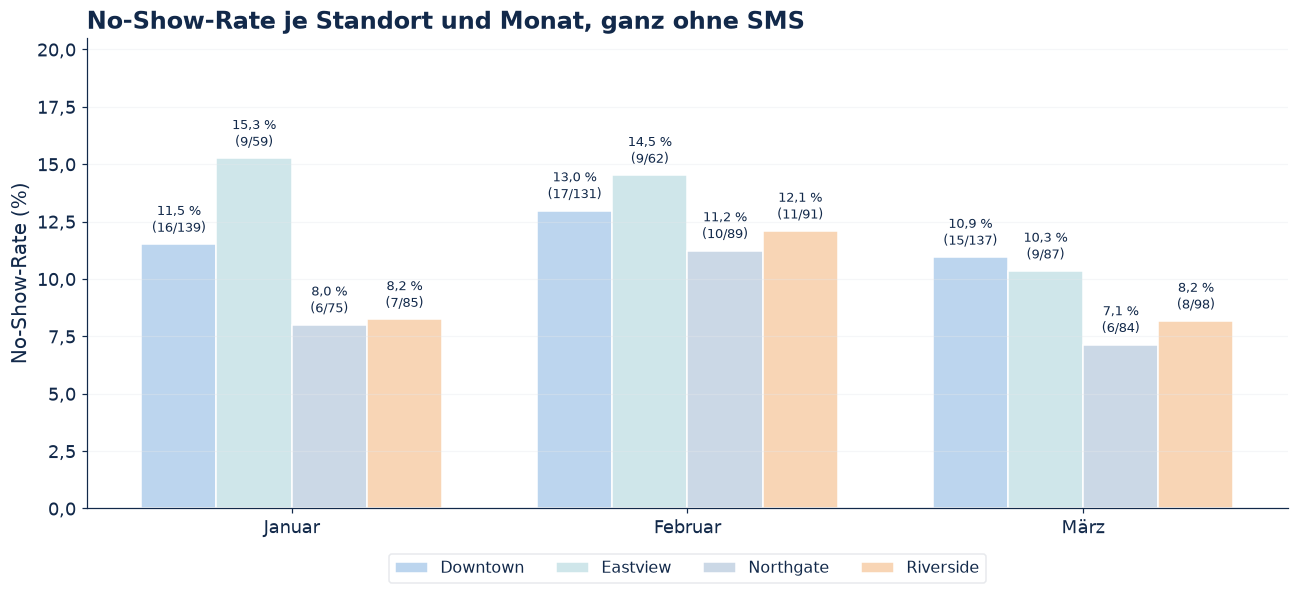

Spanne der Monatsraten: 7,1 bis 15,3 %
Riverside im März: [{'sum': 8, 'count': 98, 'rate': 8,2}]
Downtown im Februar: [{'sum': 17, 'count': 131, 'rate': 13,0}]
April nicht gezeigt (nur bis 5. April): {'Downtown': 23, 'Eastview': 12, 'Northgate': 16, 'Riverside': 12}


In [58]:
# Zusatz 3: No-Show-Rate je Standort und Monat im Besuchslog (ohne jede SMS)
def zusatz_no_show_monat():
    d3 = df.copy(); d3["monat"] = d3.appointment_date.dt.month
    MON = {1: "Januar", 2: "Februar", 3: "März"}
    tab3 = d3[d3.monat.isin(MON)].groupby(["clinic_site", "monat"]).no_show.agg(["sum", "count"]).reset_index()
    tab3["rate"] = tab3["sum"] / tab3["count"] * 100
    fig, ax = plt.subplots(figsize=(12, 5.6)); wd = .19
    for i, site in enumerate(SITE_ORDER):
        t_ = tab3[tab3.clinic_site == site].sort_values("monat")
        xs_ = np.arange(len(t_)) + (i - 1.5) * wd
        bars_ = ax.bar(xs_, t_.rate, width=wd, color=PASTEL[SITE_COL[site]], edgecolor="white", label=site)
        for x_, r_, k_, n_ in zip(xs_, t_.rate, t_["sum"], t_["count"]):
            ax.text(x_, r_ + .35, f"{r_:.1f} %\n({int(k_)}/{int(n_)})", ha="center", va="bottom", fontsize=8.6, color=INK)
    ax.set_xticks(range(3)); ax.set_xticklabels([MON[m] for m in MON])
    ax.set_ylabel("No-Show-Rate (%)"); ax.set_ylim(0, 20.5); ax.grid(axis="x", visible=False)
    ax.set_title("No-Show-Rate je Standort und Monat, ganz ohne SMS", loc="left")
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(.5, -.08), fontsize=10.5)
    plt.tight_layout(); show()
    print("Spanne der Monatsraten:", f"{tab3.rate.min():.1f} bis {tab3.rate.max():.1f} %")
    print("Riverside im März:", tab3[(tab3.clinic_site == 'Riverside') & (tab3.monat == 3)][["sum", "count", "rate"]].round(1).to_dict("records"))
    print("Downtown im Februar:", tab3[(tab3.clinic_site == 'Downtown') & (tab3.monat == 2)][["sum", "count", "rate"]].round(1).to_dict("records"))
    print("April nicht gezeigt (nur bis 5. April):", d3[d3.monat == 4].groupby("clinic_site").size().to_dict())


zusatz_no_show_monat()


**Aussage:** Schon ohne SMS liegt die No-Show-Rate je Standort und Monat zwischen 7,1 und 15,3 %: Riverside im März (8,2 %, 8 von 98) gegen Downtown im Februar (13,0 %, 17 von 131) zeigt einen Rückgang von 4,8 Punkten, den es ohne SMS gibt, weil Standort und Monat die Rate schon von allein verändern.


### Zusatz 4: Einfache lineare Regression, Zufriedenheit gegen Wartezeit

Die Regression beschreibt die Beziehung als Gerade: Zufriedenheit = Achsenabschnitt + Steigung · Wartezeit. R² gibt an, welchen Anteil der Streuung der Zufriedenheit die Wartezeit erklärt. Besuche ohne Bewertung (123, vor allem bei Urgent) fehlen, es bleiben 1077 Besuche mit beiden Werten. Die Regression rechnet das Notebook selbst mit der Methode der kleinsten Quadrate, ohne zusätzliche Pakete.


                       Koeffizient  untere   obere  p
Konstante                   4,5798  4,4999  4,6598  0
Wartezeit (je Minute)      -0,0332  -0,038 -0,0285  0
R² = 0,151 | angepasstes R² = 0,150 | n = 1077


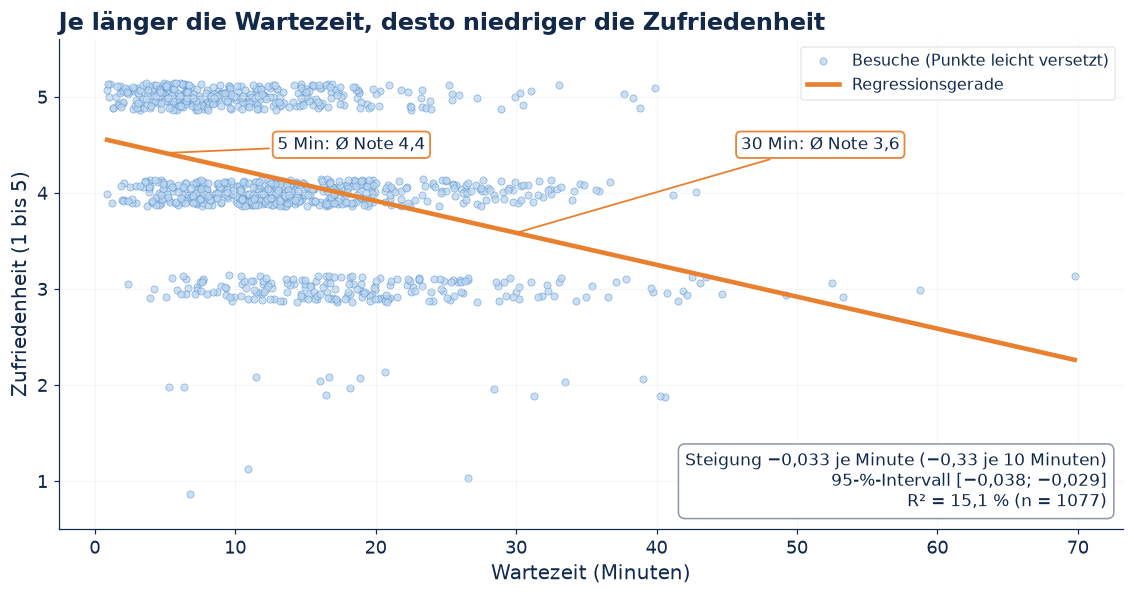

In [59]:
# Zusatz 4: Einfache lineare Regression, Zufriedenheit gegen Wartezeit
def ols_klein(y, X, namen):
    """Lineare Regression mit der Methode der kleinsten Quadrate, ohne zusätzliche Pakete. Gibt Koeffizienten mit 95-%-Intervall und p-Wert, R² und n zurück."""
    X = np.column_stack([np.ones(len(y)), X]); b = np.linalg.lstsq(X, y, rcond=None)[0]
    res = y - X @ b; n, k = X.shape; s2 = res @ res / (n - k)
    se = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X))); t_ = b / se
    h = stats.t.ppf(.975, n - k) * se
    tab = pd.DataFrame({"Koeffizient": b, "untere": b - h, "obere": b + h, "p": 2 * stats.t.sf(abs(t_), n - k)}, index=["Konstante"] + list(namen))
    r2 = 1 - res @ res / ((y - y.mean()) @ (y - y.mean()))
    return tab, r2, 1 - (1 - r2) * (n - 1) / (n - k), n

def zusatz_einfache_regression():
    mn = lambda x, nd: f"{x:.{nd}f}".replace("-", "−")
    s = df[["wait_time_min", "patient_satisfaction"]].dropna()
    tab, r2, r2a, n = ols_klein(s.patient_satisfaction.values, s[["wait_time_min"]].values, ["Wartezeit (je Minute)"])
    b0, b1 = tab.Koeffizient.iloc[0], tab.Koeffizient.iloc[1]; lo, hi = tab.untere.iloc[1], tab.obere.iloc[1]
    print(tab.round(4).to_string()); print(f"R² = {r2:.3f} | angepasstes R² = {r2a:.3f} | n = {n}")
    jit = np.random.default_rng(SEED).uniform(-.14, .14, len(s))
    fig, ax = plt.subplots(figsize=(10.5, 5.6))
    ax.scatter(s.wait_time_min, s.patient_satisfaction + jit, s=22, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=.4, alpha=.75, label="Besuche (Punkte leicht versetzt)")
    xs_ = np.linspace(s.wait_time_min.min(), s.wait_time_min.max(), 100)
    ax.plot(xs_, b0 + b1 * xs_, color=LINE["rosa"], lw=3, label="Regressionsgerade")
    for xv, tx, ty in ((5, 13, 4.5), (30, 46, 4.5)):
        tagd(ax, (xv, b0 + b1 * xv), (tx, ty), f"{xv} Min: Ø Note {mn(b0 + b1 * xv, 1)}", LINE["rosa"])
    ax.text(.985, .035, f"Steigung {mn(b1, 3)} je Minute ({mn(b1 * 10, 2)} je 10 Minuten)\n95-%-Intervall [{mn(lo, 3)}; {mn(hi, 3)}]\nR² = {mn(r2 * 100, 1)} % (n = {n})",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=11, bbox=dict(boxstyle="round,pad=.4", fc="white", ec=LINE["grau"]))
    ax.set_ylim(.5, 5.6); ax.set_yticks([1, 2, 3, 4, 5]); ax.set_xlabel("Wartezeit (Minuten)"); ax.set_ylabel("Zufriedenheit (1 bis 5)")
    ax.set_title("Je länger die Wartezeit, desto niedriger die Zufriedenheit", loc="left"); ax.legend(loc="upper right", fontsize=10.5)
    plt.tight_layout(); show()

zusatz_einfache_regression()


**Aussage:** Mit jeder Minute Wartezeit sinkt die Zufriedenheit im Mittel um 0,033 Punkte (0,33 je 10 Minuten, Intervall [−0,038; −0,029]), die Wartezeit erklärt dabei 15,1 % der Streuung (R²), die Beziehung ist also deutlich, aber nicht die einzige Einflussgröße.


### Zusatz 5: Multiple lineare Regression der Wartezeit

Das Modell erklärt die Wartezeit gleichzeitig durch Standort, Terminart, Versicherung und Wochentag (je Gruppe eine Referenzkategorie). Ein Koeffizient ist die Veränderung der Wartezeit gegenüber der Referenz bei sonst gleichen Merkmalen, das p prüft, ob dieser Koeffizient 0 sein könnte. Bei 15 Koeffizienten ist zu erwarten, dass einer zufällig unter 0,05 liegt, deshalb wird das Follow-up-Ergebnis (p = 0,03) nicht überinterpretiert.


            Koeffizient  untere  obere     p
Konstante        12,352  10,778 13,925     0
Eastview          0,366  -0,965  1,696  0,59
Northgate        -0,124  -1,382  1,133 0,846
Riverside         8,585   7,361  9,808     0
Follow-up        -1,265  -2,393 -0,136 0,028
Specialist       -0,307  -1,901  1,286 0,705
Urgent           -0,157  -1,436  1,121 0,809
Medicaid         -0,306  -1,658  1,046 0,657
Medicare          0,842  -0,315   2,00 0,153
Self-pay          0,312  -1,044  1,667 0,652
Dienstag         -0,058  -1,792  1,677 0,948
Mittwoch         -0,296  -2,034  1,442 0,739
Donnerstag        0,261  -1,472  1,993 0,768
Freitag           0,418  -1,313  2,148 0,636
Samstag           0,205  -1,527  1,937 0,816
Sonntag          -0,552  -2,286  1,182 0,532
R² = 0,175 | angepasstes R² = 0,164 | n = 1200


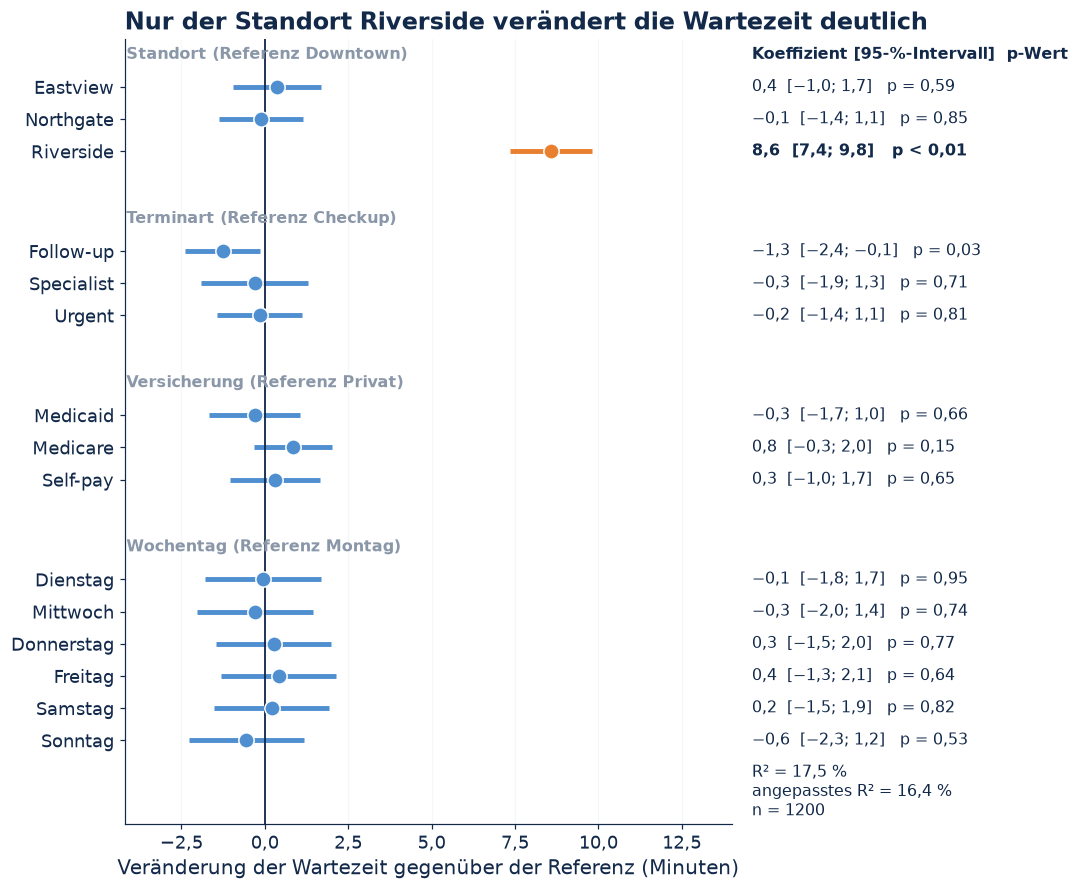

In [60]:
# Zusatz 5: Multiple lineare Regression der Wartezeit
def zusatz_multiple_regression():
    mn = lambda x, nd: f"{x:.{nd}f}".replace("-", "−")
    a = df[df.wait_time_min.notna()]
    spec = [("clinic_site", ["Eastview", "Northgate", "Riverside"], "Standort (Referenz Downtown)"),
            ("appointment_type", ["Follow-up", "Specialist", "Urgent"], "Terminart (Referenz Checkup)"),
            ("insurance_type", ["Medicaid", "Medicare", "Self-pay"], "Versicherung (Referenz Privat)"),
            ("day_of_week", ["Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], "Wochentag (Referenz Montag)")]
    TG = {"Tuesday": "Dienstag", "Wednesday": "Mittwoch", "Thursday": "Donnerstag", "Friday": "Freitag", "Saturday": "Samstag", "Sunday": "Sonntag"}
    namen, spalten, gruppen = [], [], []
    for col, stufen, gtitel in spec:
        for st in stufen:
            spalten.append((a[col] == st).astype(float).values); namen.append(TG.get(st, st)); gruppen.append(gtitel)
    tab, r2, r2a, n = ols_klein(a.wait_time_min.values, np.column_stack(spalten), namen)
    print(tab.round(3).to_string()); print(f"R² = {r2:.3f} | angepasstes R² = {r2a:.3f} | n = {n}")
    k = tab.iloc[1:].copy(); k["gruppe"] = gruppen
    fig, ax = plt.subplots(figsize=(11.5, 8.4)); ypos, yt, yl, last, y = [], [], [], None, 0
    for i, (nm, z) in enumerate(k.iterrows()):
        if z.gruppe != last:
            y += 1.1 if last else 0; ax.text(-4.15, y, z.gruppe, ha="left", va="center", fontsize=10.5, fontweight="bold", color=LINE["grau"]); y += 1; last = z.gruppe
        farbe = LINE["rosa"] if nm == "Riverside" else LINE["blau"]
        ax.hlines(y, z.untere, z.obere, color=farbe, lw=3.2, zorder=2); ax.plot(z.Koeffizient, y, "o", color=farbe, ms=10, markeredgecolor="white", zorder=3)
        ax.text(14.6, y, f"{mn(z.Koeffizient, 1)}  [{mn(z.untere, 1)}; {mn(z.obere, 1)}]   {('p = ' + mn(z.p, 2)) if z.p >= .01 else 'p < 0,01'}", va="center", ha="left", fontsize=10.5, fontweight="bold" if nm == "Riverside" else "normal")
        yt.append(y); yl.append(nm); y += 1
    ax.axvline(0, color=INK, lw=1.2); ax.set_yticks(yt); ax.set_yticklabels(yl); ax.invert_yaxis(); ax.set_xlim(-4.2, 14); ax.set_ylim(y + 1.6, -.5)
    ax.set_xlabel("Veränderung der Wartezeit gegenüber der Referenz (Minuten)"); ax.grid(axis="y", visible=False)
    ax.text(14.6, 0, "Koeffizient [95-%-Intervall]  p-Wert", ha="left", va="center", fontsize=10.5, fontweight="bold")
    ax.set_title("Nur der Standort Riverside verändert die Wartezeit deutlich", loc="left")
    ax.text(14.6, y + .6, f"R² = {mn(r2 * 100, 1)} %\nangepasstes R² = {mn(r2a * 100, 1)} %\nn = {n}", ha="left", va="center", fontsize=10.5, color=INK)
    plt.subplots_adjust(left=.14, right=.62, top=.94, bottom=.09); show()

zusatz_multiple_regression()


**Aussage:** Bei gleicher Terminart, Versicherung und gleichem Wochentag wartet man in Riverside 8,6 Minuten länger als in Downtown [7,4; 9,8], die übrigen Koeffizienten liegen nahe 0 (am weitesten weg: Follow-up mit −1,3 Minuten), und das Modell erklärt 17,5 % der Streuung.


### Zusatz 5b: Residuen des Wartezeit-Modells (Annahmen der Regression)

Die Regression aus Zusatz 5 stützt sich auf drei Annahmen über die Residuen (beobachtete minus vorhergesagte Wartezeit): Sie streuen ohne Muster um null, an allen Stellen gleich stark, und sie sind für die Intervalle annähernd normalverteilt. Ich prüfe alle drei und lasse die Intervalle zusätzlich mit robusten Standardfehlern (HC3) rechnen, die nicht von gleicher Streuung ausgehen. Cooks Distanz zeigt, ob einzelne Besuche das Modell bestimmen.

n = 1200 Besuche, 15 Prädiktoren. Residuen: Mittelwert 0,000, SD 8,14, Schiefe 1,53, Exzess-Kurtosis 4,28.
Riverside-Koeffizient 8,58: klassisch [7,36; 9,81], robust (HC3) [7,33; 9,84].
Shapiro-Wilk (Normalität der Residuen): W = 0,898, p = 1,5e-27.
Breusch-Pagan (gleiche Streuung der Residuen): LM = 6,72, p = 0,97.
Streuung der Residuen je Standort:
             std  size
clinic_site           
Downtown    8,06   430
Eastview    8,25   220
Northgate   7,72   264
Riverside   8,38   286
Cooks Distanz: größter Wert 0,035 (Grenze 1), 60 Besuche über 4/n = 0,0033.


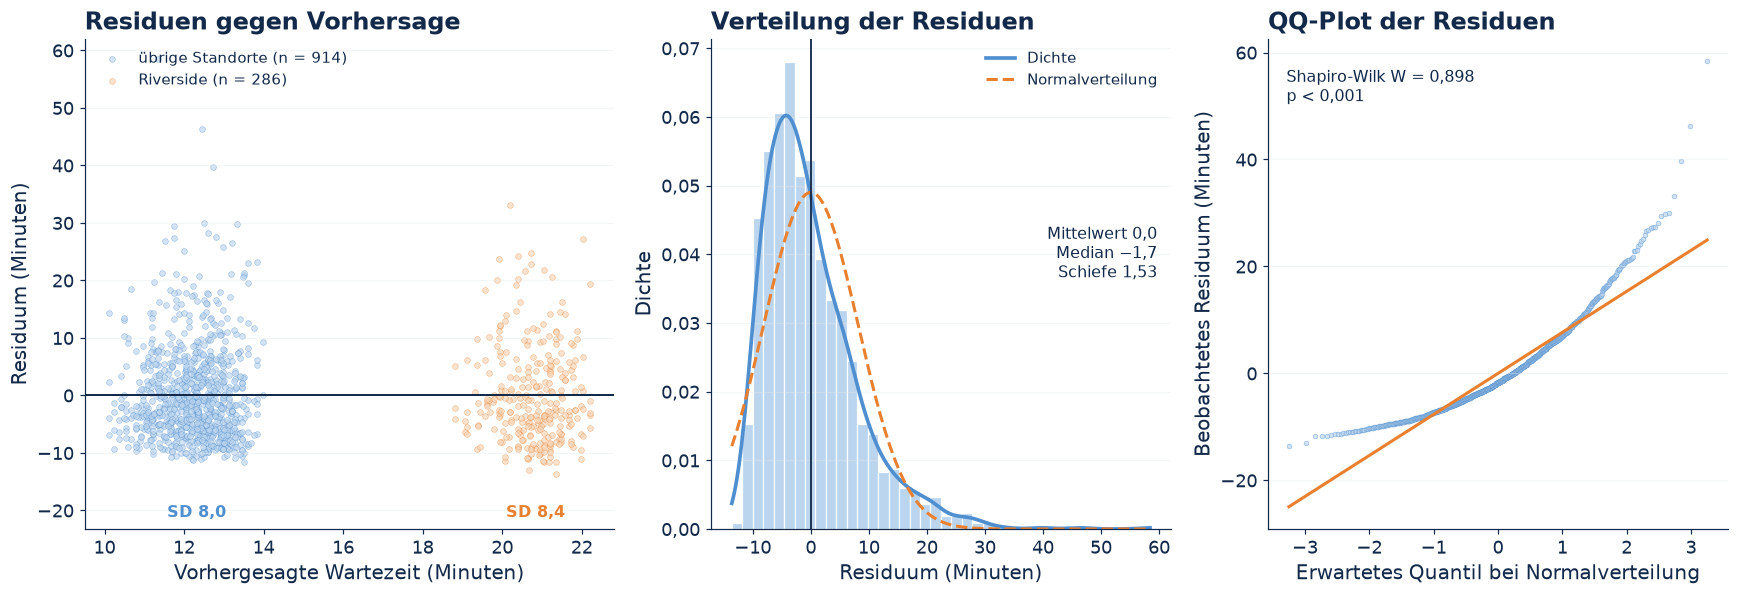

In [61]:
# Zusatz 5b: Residuen des Modells aus Zusatz 5, Prüfung der Annahmen
def zusatz_residuen_wartezeit():
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−").replace(".", ",")
    a = df[df.wait_time_min.notna()].reset_index(drop=True)
    X = np.column_stack([np.ones(len(a))] + [(a[c] == s).astype(float).values for c, ss in
        (("clinic_site", ["Eastview", "Northgate", "Riverside"]), ("appointment_type", ["Follow-up", "Specialist", "Urgent"]),
         ("insurance_type", ["Medicaid", "Medicare", "Self-pay"]), ("day_of_week", ["Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])) for s in ss])
    y = a.wait_time_min.values; b = np.linalg.lstsq(X, y, rcond=None)[0]; fit = X @ b; res = y - fit; n, k = X.shape
    s2 = res @ res / (n - k); XtXi = np.linalg.inv(X.T @ X); h = np.einsum("ij,jk,ik->i", X, XtXi, X)
    # Robuste Standardfehler (HC3) für den Riverside-Koeffizienten
    meat = (X * (res / (1 - h))[:, None]).T @ (X * (res / (1 - h))[:, None]); se3 = np.sqrt(np.diag(XtXi @ meat @ XtXi)); se0 = np.sqrt(np.diag(s2 * XtXi))
    j = 3; tq = stats.t.ppf(.975, n - k)
    print(f"n = {n} Besuche, {k - 1} Prädiktoren. Residuen: Mittelwert {mn(abs(res.mean()), 3)}, SD {mn(res.std(ddof=k), 2)}, Schiefe {mn(stats.skew(res))}, Exzess-Kurtosis {mn(stats.kurtosis(res))}.")
    print(f"Riverside-Koeffizient {mn(b[j])}: klassisch [{mn(b[j] - tq * se0[j])}; {mn(b[j] + tq * se0[j])}], robust (HC3) [{mn(b[j] - tq * se3[j])}; {mn(b[j] + tq * se3[j])}].")
    sw = stats.shapiro(res); print(f"Shapiro-Wilk (Normalität der Residuen): W = {mn(sw.statistic, 3)}, p = {sw.pvalue:.1e}.")
    aux = res ** 2; bb = np.linalg.lstsq(X, aux, rcond=None)[0]; r2a = 1 - ((aux - X @ bb) ** 2).sum() / ((aux - aux.mean()) ** 2).sum(); lm = n * r2a
    print(f"Breusch-Pagan (gleiche Streuung der Residuen): LM = {mn(lm)}, p = {mn(stats.chi2.sf(lm, k - 1))}.")
    sd_ = a.assign(res=res).groupby("clinic_site").res.agg(["std", "size"]); print("Streuung der Residuen je Standort:\n" + sd_.round(2).to_string())
    cook = res ** 2 / (k * s2) * h / (1 - h) ** 2; print(f"Cooks Distanz: größter Wert {mn(cook.max(), 3)} (Grenze 1), {int((cook > 4 / n).sum())} Besuche über 4/n = {mn(4 / n, 4)}.")
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.15, 1, 1]})
    grp = (a.clinic_site == "Riverside").values
    for m_, nm, c_ in ((~grp, "übrige Standorte", "blau"), (grp, "Riverside", "rosa")):
        ax[0].scatter(fit[m_], res[m_], s=14, color=PASTEL[c_], edgecolor=LINE[c_], lw=.3, alpha=.65, label=f"{nm} (n = {int(m_.sum())})")
    ax[0].axhline(0, color=INK, lw=1.3); ax[0].set_xlabel("Vorhergesagte Wartezeit (Minuten)"); ax[0].set_ylabel("Residuum (Minuten)")
    ax[0].set_title("Residuen gegen Vorhersage", loc="left"); ax[0].legend(loc="upper left", fontsize=9.5, frameon=False)
    yl = ax[0].get_ylim(); ax[0].set_ylim(yl[0] - 6, yl[1])
    for m_, c_ in ((~grp, "blau"), (grp, "rosa")):
        ax[0].text(np.median(fit[m_]), yl[0] - 3.2, f"SD {mn(res[m_].std(ddof=1), 1)}", ha="center", va="center", fontsize=10.5, fontweight="bold", color=LINE[c_])
    xs_ = np.linspace(res.min(), res.max(), 300); ax[1].hist(res, bins=40, density=True, color=PASTEL["blau"], edgecolor="white", lw=.8)
    kd = stats.gaussian_kde(res); ax[1].plot(xs_, kd(xs_), color=LINE["blau"], lw=2.4, label="Dichte"); ax[1].plot(xs_, stats.norm.pdf(xs_, 0, res.std(ddof=k)), color=LINE["rosa"], lw=2, ls="--", label="Normalverteilung")
    ax[1].axvline(0, color=INK, lw=1.2); ax[1].set_xlabel("Residuum (Minuten)"); ax[1].set_ylabel("Dichte"); ax[1].set_title("Verteilung der Residuen", loc="left")
    ax[1].text(.97, .62, f"Mittelwert {mn(abs(res.mean()), 1)}\nMedian {mn(np.median(res), 1)}\nSchiefe {mn(stats.skew(res), 2)}", transform=ax[1].transAxes, ha="right", va="top", fontsize=10.5)
    ax[1].legend(loc="upper right", fontsize=9.5, frameon=False)
    q = stats.probplot(res, dist="norm"); ax[2].scatter(q[0][0], q[0][1], s=10, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=.3, alpha=.7)
    ax[2].plot(q[0][0], q[1][1] + q[1][0] * q[0][0], color=LINE["rosa"], lw=2); ax[2].set_xlabel("Erwartetes Quantil bei Normalverteilung"); ax[2].set_ylabel("Beobachtetes Residuum (Minuten)")
    ax[2].set_title("QQ-Plot der Residuen", loc="left"); ax[2].text(.04, .94, f"Shapiro-Wilk W = {mn(sw.statistic, 3)}\np < 0,001", transform=ax[2].transAxes, ha="left", va="top", fontsize=10.5)
    for x_ in ax: x_.grid(axis="x", visible=False)
    plt.tight_layout(); show()
    return b, se0, se3, res

z5b = zusatz_residuen_wartezeit()


**Aussage:** Die Residuen streuen an allen Standorten gleich stark (Standardabweichung 8,0 Minuten in den übrigen Standorten, 8,4 in Riverside; Breusch-Pagan p = 0,97), sind aber rechtsschief (Schiefe 1,53; Shapiro-Wilk p < 0,001), und das robuste Intervall für Riverside [7,33; 9,84] weicht kaum vom klassischen [7,36; 9,81] ab.

**Einordnung:**
- **Gleiche Streuung:** Im Diagramm links bilden die Besuche zwei Wolken gleicher Höhe, eine bei etwa 12 Minuten (übrige Standorte) und eine bei etwa 21 Minuten (Riverside). Es gibt keinen Trichter und kein gekrümmtes Muster.
- **Normalverteilung:** Die Residuen sind rechtsschief, weil die Wartezeit nach unten durch null begrenzt ist und einzelne Besuche sehr lange warten (größtes Residuum über 58 Minuten). Das zeigen Histogramm und QQ-Plot übereinstimmend. Für die Intervalle der Koeffizienten ist das bei 1.200 Besuchen unkritisch, weil sie von Mittelwerten abhängen, und das robuste Intervall bestätigt es.
- **Einzelne Besuche:** Der größte Wert von Cooks Distanz liegt bei 0,035, weit unter 1. 60 Besuche liegen über der Faustregel 4/n, aber keiner bestimmt das Modell.
- **Grenze:** Das Modell beschreibt Mittelwerte. Für die Wartezeit eines einzelnen Besuchs wären symmetrische Vorhersagebereiche zu eng nach oben, weil die Verteilung eine lange rechte Seite hat.

### Zusatz 6: Ausgelassene Variablen

Wird eine wichtige Variable im Modell ausgelassen, kann ein Koeffizient verzerrt sein. Hier wird der Riverside-Koeffizient in vier Modellen verglichen, in die schrittweise Terminart, Versicherung und Wochentag aufgenommen werden. Wäre eine davon wichtig, würde sich der Wert verschieben.


        Modell  Riverside  untere  obere   R2
  Nur Standort       8,58    7,36   9,79 0,17
   + Terminart       8,59    7,37   9,81 0,17
+ Versicherung       8,60    7,38   9,82 0,17
   + Wochentag       8,58    7,36   9,81 0,17


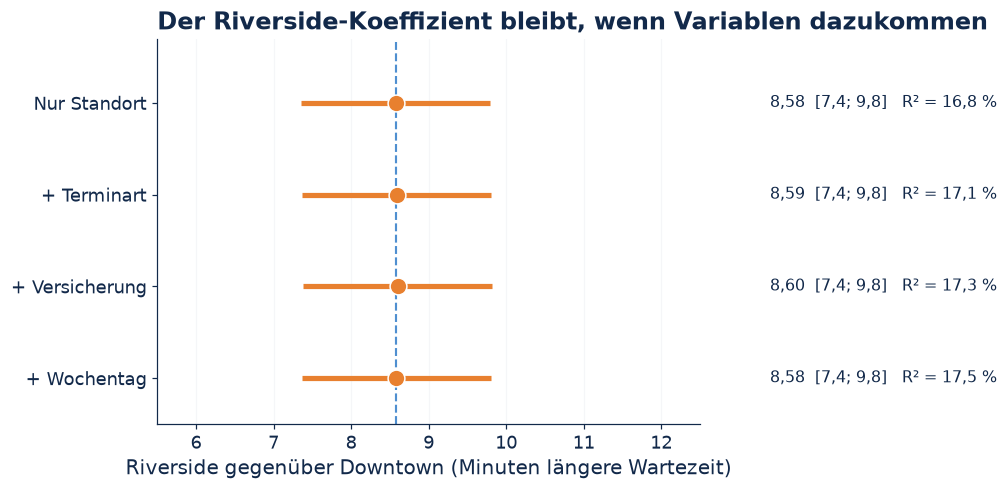

In [62]:
# Zusatz 6: Ausgelassene Variablen, bleibt der Riverside-Effekt stabil, wenn Variablen dazukommen?
def zusatz_ausgelassene_variablen():
    mn = lambda x, nd: f"{x:.{nd}f}".replace("-", "−")
    a = df[df.wait_time_min.notna()]
    def dummies(col, stufen): return [(a[col] == st).astype(float).values for st in stufen]
    bloecke = [("Standort", "clinic_site", ["Eastview", "Northgate", "Riverside"]), ("Terminart", "appointment_type", ["Follow-up", "Specialist", "Urgent"]),
               ("Versicherung", "insurance_type", ["Medicaid", "Medicare", "Self-pay"]),
               ("Wochentag", "day_of_week", ["Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])]
    zeilen, cols, nam = [], [], []
    for i, (titel, col, stufen) in enumerate(bloecke):
        cols += dummies(col, stufen); nam += [f"{col}:{s_}" for s_ in stufen]
        tab, r2, r2a, n = ols_klein(a.wait_time_min.values, np.column_stack(cols), nam)
        z = tab.loc["clinic_site:Riverside"]
        zeilen.append((("Nur Standort" if i == 0 else "+ " + titel), z.Koeffizient, z.untere, z.obere, r2))
    t = pd.DataFrame(zeilen, columns=["Modell", "Riverside", "untere", "obere", "R2"])
    print(t.round(2).to_string(index=False))
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    for i, z in t.iterrows():
        ax.hlines(i, z.untere, z.obere, color=LINE["rosa"], lw=3.4, zorder=2); ax.plot(z.Riverside, i, "o", color=LINE["rosa"], ms=11, markeredgecolor="white", zorder=3)
        ax.text(13.4, i, f"{mn(z.Riverside, 2)}  [{mn(z.untere, 1)}; {mn(z.obere, 1)}]   R² = {mn(z.R2 * 100, 1)} %", va="center", ha="left", fontsize=10.5)
    ax.axvline(t.Riverside.iloc[0], color=LINE["blau"], ls="--", lw=1.4)
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.Modell); ax.invert_yaxis(); ax.set_xlim(5.5, 12.5); ax.set_ylim(len(t) - .5, -.7)
    ax.set_xlabel("Riverside gegenüber Downtown (Minuten längere Wartezeit)"); ax.grid(axis="y", visible=False)
    ax.set_title("Der Riverside-Koeffizient bleibt, wenn Variablen dazukommen", loc="left")
    plt.subplots_adjust(left=.17, right=.64, top=.9, bottom=.17); show()

zusatz_ausgelassene_variablen()


**Aussage:** Der Riverside-Koeffizient liegt in allen vier Modellen bei 8,6 Minuten (8,58 bis 8,60), Terminart, Versicherung und Wochentag erklären den Standortunterschied also nicht, und das stützt das Ergebnis des Welch-Tests.


**Bezug zum SMS-Plan:** Dort lässt sich dasselbe nicht lösen. Jede Gruppe ist genau ein Standort in einem Monat, Gruppe, Standort und Monat sind also vollständig vermischt, und eine Regression könnte sie nicht trennen. Nicht gemessene Merkmale (Besetzung, Uhrzeit) bleiben auch hier möglich, deshalb bleibt die Ursache für Riverside offen.


### Zusatz 7: Betriebsdaten, Wartezeit erklären

Ich bearbeite hier neun Aufgaben zur Erklärung der Wartezeit. Grundlage sind die Betriebsdaten `solace_daily_ops.csv`: 90 Tage, eine Zeile pro Tag mit geplanten Patienten, Personal im Dienst, Wochenende (0/1) und Wartezeit in Minuten. Das ändert keine Aussage weiter oben. Liegt die Datei neben `solace_visits.csv`, wird sie gelesen, sonst nutzt das Notebook eine eingebettete Kopie derselben Daten.

**Aufgabe 1 (multiple Regression):** Die Wartezeit wird aus drei Größen gleichzeitig erklärt: Wartezeit = 5,13 + 0,50 × Patienten − 1,28 × Personal + 2,30 × Wochenende. Jeder Koeffizient gilt bei festgehaltenen anderen Größen.

In [63]:
# Zusatz 7: Betriebsdaten, Daten laden und multiples Modell rechnen
from io import StringIO
OPS_CSV = """patients_scheduled,staff_on_duty,is_weekend,wait_time
39,10,1,14.0
41,11,0,11.3
23,8,0,7.0
35,11,0,7.8
22,7,0,5.2
27,9,0,9.0
31,8,0,10.4
21,6,0,7.9
35,8,0,14.3
45,11,1,17.1
44,11,0,11.2
35,10,0,8.6
30,7,1,10.9
40,10,1,12.3
44,9,1,19.3
43,9,0,15.0
20,7,0,4.3
37,11,1,8.8
38,11,0,13.1
24,7,0,7.7
33,10,1,11.6
45,10,1,17.5
37,10,1,11.2
27,9,1,10.2
28,8,0,9.6
36,8,0,16.6
23,8,0,7.9
35,9,1,10.9
34,8,0,12.3
35,10,0,9.9
40,10,1,14.7
33,9,0,7.8
38,9,1,11.6
45,11,1,15.8
23,6,1,12.3
33,8,0,9.4
23,5,0,15.1
40,11,0,12.8
23,7,1,9.0
32,9,1,16.5
25,6,0,7.3
45,11,0,11.9
31,8,1,10.6
45,11,1,18.7
42,9,1,15.9
30,9,1,12.5
31,9,0,10.0
28,7,0,9.5
40,10,0,13.2
42,9,0,12.9
32,9,1,13.9
40,10,0,10.7
45,11,0,12.2
37,10,0,12.8
38,9,1,14.3
30,9,0,13.0
45,11,0,17.2
30,9,0,5.3
36,9,0,12.6
23,8,0,6.3
36,9,1,19.0
36,9,0,11.0
24,8,1,7.8
22,7,0,7.1
41,10,0,13.0
27,8,0,6.8
41,10,0,14.0
37,9,0,11.6
22,7,0,5.7
20,6,1,13.3
23,8,0,6.9
41,11,0,9.7
32,7,0,10.0
21,8,0,4.8
25,8,0,4.9
33,10,0,6.2
41,10,0,15.9
34,8,0,12.3
36,9,0,11.0
25,7,0,9.6
41,9,1,15.7
44,10,0,15.3
30,9,0,12.9
28,8,1,11.3
43,11,1,13.8
33,7,0,11.1
38,11,0,11.7
42,10,0,13.7
30,8,0,11.3
37,10,0,7.7
"""
def lade_betriebsdaten():
    """solace_daily_ops.csv aus dem Ordner des Notebooks, sonst die eingebettete Kopie (identisch mit der Originaldatei)."""
    p = Path(DATA_PATH).parent / "solace_daily_ops.csv"
    return pd.read_csv(p) if p.is_file() else pd.read_csv(StringIO(OPS_CSV))

ops_df = lade_betriebsdaten()
OPS_X = ["patients_scheduled", "staff_on_duty", "is_weekend"]

def ops_fit(spalten):
    """Regression von wait_time auf die angegebenen Spalten, mit Vorhersage und Restfehlern."""
    X = ops_df[spalten].values.astype(float); y = ops_df.wait_time.values
    tab, r2, r2a, n = ols_klein(y, X, spalten)
    fitted = tab.Koeffizient.iloc[0] + X @ tab.Koeffizient.iloc[1:].values
    res = y - fitted
    return tab, r2, r2a, n, fitted, res, np.sqrt(res @ res / (n - len(spalten) - 1))

def zusatz7_modell():
    print("Form:", ops_df.shape, "| fehlende Werte:", int(ops_df.isna().sum().sum()), "\n")
    print("Kennzahlen:"); print(ops_df.describe().loc[["mean", "std", "min", "max"]].round(2).to_string(), "\n")
    print("Korrelationen (Pearson):"); print(ops_df.corr().round(2).to_string(), "\n")
    tab, r2, r2a, n, fitted, res, s = ops_fit(OPS_X)
    print("Multiple lineare Regression: wait_time ~ patients_scheduled + staff_on_duty + is_weekend")
    print(tab.round(3).to_string())
    print(f"R² = {r2:.3f} | angepasstes R² = {r2a:.3f} | Restfehler s = {s:.2f} Min | n = {n}")

zusatz7_modell()


Form: (90, 4) | fehlende Werte: 0 

Kennzahlen:
      patients_scheduled  staff_on_duty  is_weekend  wait_time
mean               33,72           8,91        0,32      11,38
std                 7,48           1,47        0,47       3,48
min                20,00           5,00           0       4,30
max                45,00          11,00        1,00      19,30 

Korrelationen (Pearson):
                    patients_scheduled  staff_on_duty  is_weekend  wait_time
patients_scheduled                1,00           0,81        0,14       0,68
staff_on_duty                     0,81           1,00        0,09       0,37
is_weekend                        0,14           0,09        1,00       0,42
wait_time                         0,68           0,37        0,42       1,00 

Multiple lineare Regression: wait_time ~ patients_scheduled + staff_on_duty + is_weekend
                    Koeffizient  untere  obere  p
Konstante                 5,129   2,458   7,80  0
patients_scheduled        0,501   

**Aufgabe 3 (Koeffizienten und p-Werte):** Jeder zusätzliche geplante Patient geht mit einer um 0,50 Minuten höheren erwarteten Wartezeit einher [0,40; 0,60], also 10 Patienten mehr mit etwa 5 Minuten mehr. Eine Person mehr im Dienst geht mit einer um 1,28 Minuten niedrigeren einher [−1,78; −0,77] (jeweils bei gleichen übrigen Variablen, ein Zusammenhang und keine nachgewiesene Wirkung). Ein Wochenendtag ist im Mittel 2,30 Minuten länger [1,37; 3,22]. Alle drei p-Werte liegen unter 0,001.

**Aufgabe 4 (was ein p-Wert nicht sagt):** Der p-Wert zeigt nur, wie unwahrscheinlich ein so großer Koeffizient wäre, wenn es in Wahrheit keinen Zusammenhang gäbe. Er sagt nicht, wie groß oder wie wichtig der Effekt ist, nicht, wie wahrscheinlich die Nullhypothese stimmt, und nicht, dass die Ursache gefunden ist. Größe und Unsicherheit stehen im Konfidenzintervall, die Bedeutung bewertet man fachlich.

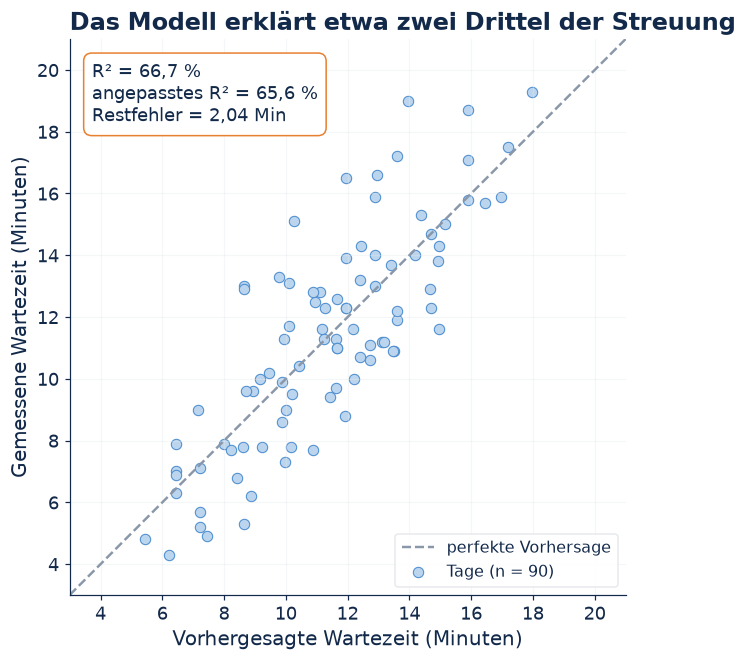

In [64]:
# Zusatz 7: Aufgabe 2, gemessene gegen vorhergesagte Wartezeit (R²)
def zusatz7_r2():
    mn = lambda x, nd: f"{x:.{nd}f}".replace("-", "−")
    tab, r2, r2a, n, fitted, res, s = ops_fit(OPS_X)
    fig, ax = plt.subplots(figsize=(8.6, 6.2))
    lim = (3, 21)
    ax.plot(lim, lim, color=LINE["grau"], ls="--", lw=1.6, label="perfekte Vorhersage")
    ax.scatter(fitted, ops_df.wait_time, s=46, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=.7, label="Tage (n = 90)")
    ax.text(.04, .96, f"R² = {mn(r2 * 100, 1)} %\nangepasstes R² = {mn(r2a * 100, 1)} %\nRestfehler = {mn(s, 2)} Min", transform=ax.transAxes, va="top", fontsize=12,
            bbox=dict(boxstyle="round,pad=.45", fc="white", ec=LINE["rosa"]))
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel("Vorhergesagte Wartezeit (Minuten)"); ax.set_ylabel("Gemessene Wartezeit (Minuten)")
    ax.set_title("Das Modell erklärt etwa zwei Drittel der Streuung", loc="left"); ax.legend(loc="lower right", fontsize=10.5)
    plt.tight_layout(); show()

zusatz7_r2()


**Aufgabe 2 (R²):** Das Modell erklärt 66,7 % der Streuung der Wartezeit (angepasstes R² 65,6 %, das zusätzliche Variablen bestraft). Die typische Abweichung zwischen Vorhersage und Messung beträgt 2,04 Minuten, ein Drittel der Streuung bleibt unerklärt. R² sagt, wie gut das Modell die vorhandenen Daten beschreibt, nicht, ob es kausal stimmt.

**Aussage:** Die vorhergesagten Wartezeiten liegen überwiegend nahe an den gemessenen, das Modell erklärt 66,7 % der Streuung, und die typische Abweichung beträgt 2,04 Minuten.

Shapiro-Wilk (Normalität der Restfehler): W = 0,963, p = 0,013
Breusch-Pagan (gleiche Streuung der Restfehler): LM = 1,08, p = 0,782
Durbin-Watson (Unabhängigkeit, setzt die Zeitreihenfolge der Zeilen voraus): 2,14
Varianzinflationsfaktor (VIF): {'patients_scheduled': 3,0, 'staff_on_duty': 2,97, 'is_weekend': 1,02}


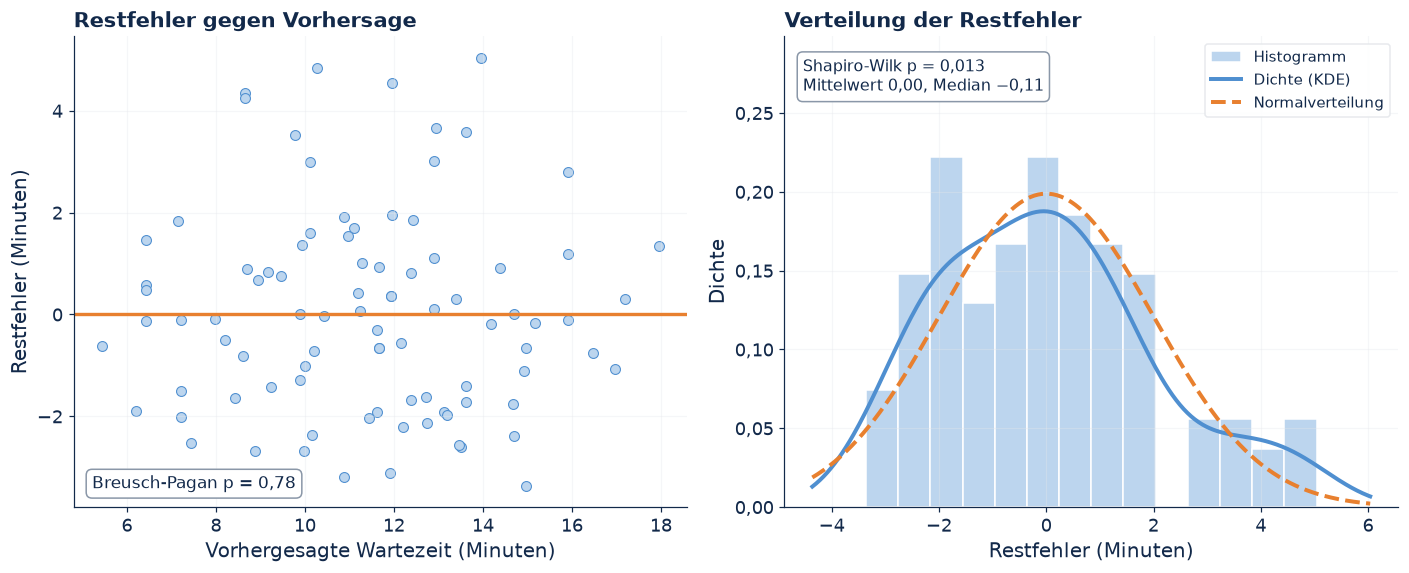

In [65]:
# Zusatz 7: Aufgabe 5, Prüfung der Modellannahmen
def zusatz7_annahmen():
    mn = lambda x, nd: f"{x:.{nd}f}".replace("-", "−")
    tab, r2, r2a, n, fitted, res, s = ops_fit(OPS_X)
    X = np.column_stack([np.ones(n), ops_df[OPS_X].values.astype(float)])
    sw = stats.shapiro(res)
    u = res ** 2; bu = np.linalg.lstsq(X, u, rcond=None)[0]; ru = u - X @ bu
    lm = n * (1 - ru @ ru / ((u - u.mean()) @ (u - u.mean()))); p_bp = 1 - stats.chi2.cdf(lm, X.shape[1] - 1)
    dw = np.sum(np.diff(res) ** 2) / np.sum(res ** 2)
    vif = {}
    for j, c_ in enumerate(OPS_X):
        andere = [i for i in range(1, X.shape[1]) if i != j + 1]; Z = X[:, [0] + andere]
        rr = X[:, j + 1] - Z @ np.linalg.lstsq(Z, X[:, j + 1], rcond=None)[0]
        vif[c_] = 1 / (rr @ rr / ((X[:, j + 1] - X[:, j + 1].mean()) @ (X[:, j + 1] - X[:, j + 1].mean())))
    print(f"Shapiro-Wilk (Normalität der Restfehler): W = {sw.statistic:.3f}, p = {sw.pvalue:.3f}")
    print(f"Breusch-Pagan (gleiche Streuung der Restfehler): LM = {lm:.2f}, p = {p_bp:.3f}")
    print(f"Durbin-Watson (Unabhängigkeit, setzt die Zeitreihenfolge der Zeilen voraus): {dw:.2f}")
    print("Varianzinflationsfaktor (VIF):", {k: round(float(v), 2) for k, v in vif.items()})
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.4))
    a1.scatter(fitted, res, s=42, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=.7)
    a1.axhline(0, color=LINE["rosa"], lw=2.2)
    a1.set_xlabel("Vorhergesagte Wartezeit (Minuten)"); a1.set_ylabel("Restfehler (Minuten)"); a1.set_title("Restfehler gegen Vorhersage", loc="left", fontsize=14)
    a1.text(.03, .04, f"Breusch-Pagan p = {mn(p_bp, 2)}", transform=a1.transAxes, fontsize=11, bbox=dict(boxstyle="round,pad=.35", fc="white", ec=LINE["grau"]))
    a2.hist(res, bins=14, density=True, color=PASTEL["blau"], edgecolor="white", label="Histogramm")
    xs_ = np.linspace(res.min() - 1, res.max() + 1, 300)
    a2.plot(xs_, stats.gaussian_kde(res)(xs_), color=LINE["blau"], label="Dichte (KDE)")
    a2.plot(xs_, stats.norm.pdf(xs_, 0, res.std(ddof=1)), color=LINE["rosa"], ls="--", label="Normalverteilung")
    a2.set_xlabel("Restfehler (Minuten)"); a2.set_ylabel("Dichte"); a2.set_title("Verteilung der Restfehler", loc="left", fontsize=14)
    a2.set_ylim(0, a2.get_ylim()[1] * 1.28); a2.legend(loc="upper right", fontsize=10)
    a2.text(.03, .955, f"Shapiro-Wilk p = {mn(sw.pvalue, 3)}\nMittelwert 0,00, Median {mn(np.median(res), 2)}", transform=a2.transAxes, va="top", fontsize=10.5,
            bbox=dict(boxstyle="round,pad=.35", fc="white", ec=LINE["grau"]))
    plt.tight_layout(); show()

zusatz7_annahmen()


**Aussage:** Die Restfehler streuen gleichmäßig um null (Breusch-Pagan p = 0,78) und weichen nur leicht von der Normalverteilung ab (Shapiro-Wilk p = 0,013), was bei 90 Tagen die Koeffizienten kaum beeinträchtigt.

**Aufgabe 5 (Annahmen):**
- **Linearität:** Im Diagramm der Restfehler gegen die vorhergesagten Werte ist kein Muster zu sehen.
- **Gleiche Streuung:** Breusch-Pagan p = 0,78, kein Hinweis auf ungleiche Streuung.
- **Normalverteilte Restfehler:** Shapiro-Wilk p = 0,013, leicht verletzt. Bei n = 90 sind Koeffizienten und Intervalle dagegen ziemlich robust, bei den Intervallen bleibt aber eine kleine Unsicherheit.
- **Unabhängigkeit:** Durbin-Watson 2,14 (nahe 2) spricht für unabhängige Restfehler, gilt aber nur, wenn die Zeilen in zeitlicher Reihenfolge stehen. Die Datei enthält kein Datum, das lässt sich also nicht prüfen. Aufeinanderfolgende Tage könnten ähnlich sein.
- **Multikollinearität:** Patienten und Personal hängen stark zusammen (r = 0,81, VIF 3,0 und 3,0, unter der üblichen Grenze von 5). Das macht beide Koeffizienten etwas ungenauer, sie bleiben aber nutzbar.

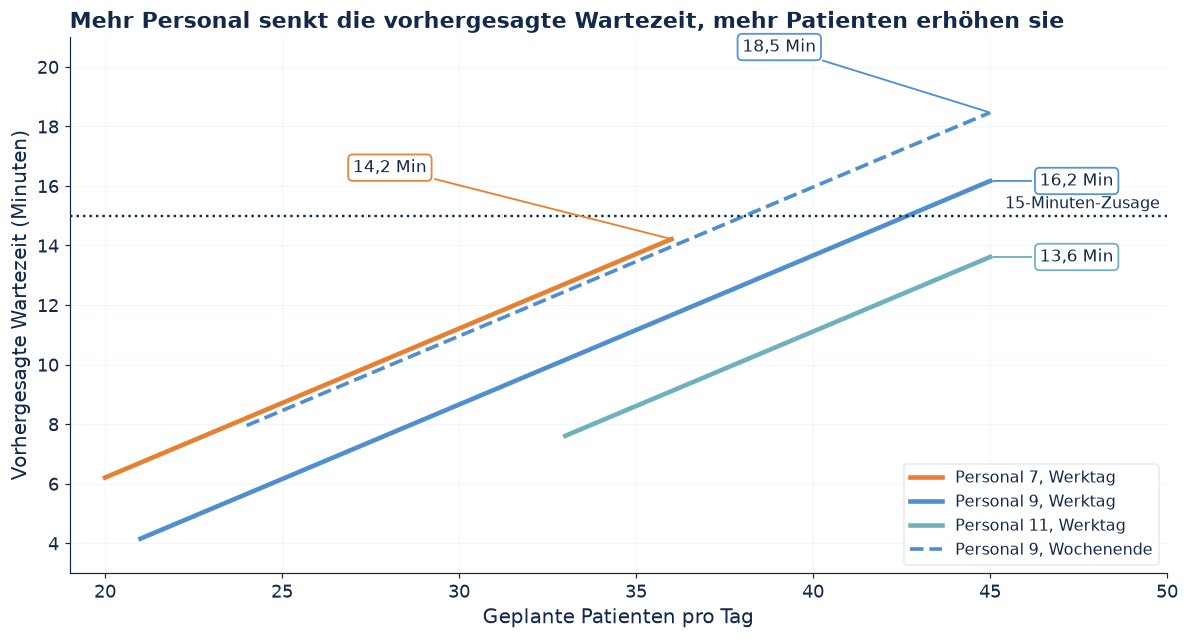

Ein Patient mehr: +0,50 Min | ein Mitarbeiter mehr: -1,28 Min | Wochenende: +2,30 Min


In [66]:
# Zusatz 7: Aufgabe 6, geschäftliche Erkenntnis: vorhergesagte Wartezeit nach Patientenzahl und Personal
def zusatz7_szenarien():
    mn = lambda x, nd: f"{x:.{nd}f}".replace("-", "−")
    tab = ops_fit(OPS_X)[0].Koeffizient; b0, bp, bs, bw = tab.values
    fig, ax = plt.subplots(figsize=(11, 6))
    farben = {7: LINE["rosa"], 9: LINE["blau"], 11: LINE["pfirsich"]}
    for st in (7, 9, 11):
        nah = ops_df[(ops_df.staff_on_duty - st).abs() <= 1]
        xs_ = np.linspace(nah.patients_scheduled.min(), nah.patients_scheduled.max(), 50)
        ys_ = b0 + bp * xs_ + bs * st
        ax.plot(xs_, ys_, color=farben[st], lw=3, label=f"Personal {st}, Werktag")
        tagd(ax, (xs_[-1], ys_[-1]), ((xs_[-1] - 9, ys_[-1] + 2.4) if st == 7 else (xs_[-1] + 1.4, ys_[-1])), f"{mn(ys_[-1], 1)} Min", farben[st], ha="left")
    we = ops_df[(ops_df.is_weekend == 1) & ((ops_df.staff_on_duty - 9).abs() <= 1)]
    xs_ = np.linspace(we.patients_scheduled.min(), we.patients_scheduled.max(), 50); yw_ = b0 + bp * xs_ + bs * 9 + bw
    ax.plot(xs_, yw_, color=LINE["blau"], lw=2.4, ls="--", label="Personal 9, Wochenende")
    tagd(ax, (xs_[-1], yw_[-1]), (xs_[-1] - 7, yw_[-1] + 2.2), f"{mn(yw_[-1], 1)} Min", LINE["blau"], ha="left")
    ax.axhline(15, color=INK, ls=":", lw=1.6); ax.text(49.8, 15.25, "15-Minuten-Zusage", fontsize=10.5, color=INK, ha="right")
    ax.set_xlim(19, 50); ax.set_ylim(3, 21); ax.set_xlabel("Geplante Patienten pro Tag"); ax.set_ylabel("Vorhergesagte Wartezeit (Minuten)")
    ax.set_title("Mehr Personal senkt die vorhergesagte Wartezeit, mehr Patienten erhöhen sie", loc="left", fontsize=14.5)
    ax.legend(loc="lower right", fontsize=10.5); plt.tight_layout(); show()
    print(f"Ein Patient mehr: {bp:+.2f} Min | ein Mitarbeiter mehr: {bs:+.2f} Min | Wochenende: {bw:+.2f} Min")

zusatz7_szenarien()


**Aussage:** Bei gleicher Patientenzahl liegt die vorhergesagte Wartezeit mit mehr Personal niedriger, und mit 9 Personen an einem Werktag bleibt sie bis etwa 42 Patienten unter der 15-Minuten-Zusage.

**Aufgabe 6 (geschäftliche Erkenntnisse):**
- Wartezeit steigt mit der Auslastung (+0,50 Minuten je Patient) und sinkt mit Personal (−1,28 Minuten je Person).
- Am Wochenende ist die Wartezeit bei gleicher Besetzung 2,30 Minuten höher. Mit 9 Personen reicht die Zusage dort nur bis etwa 38 Patienten.
- Das Diagramm zeigt nur Bereiche, die in den Daten vorkommen (20 bis 45 Patienten, 5 bis 11 Personen). Aussagen darüber hinaus, etwa für 12 Personen, wären Extrapolation.
- Personalkosten sind nicht in den Daten. Ob sich eine zusätzliche Person lohnt, lässt sich daher nicht entscheiden, nur wie viel Wartezeit sie im Modell einspart.

      Modell      b     lo     hi  p    R2
Nur Personal  0,868   0,40  1,336  0 0,134
 + Patienten -1,334 -1,902 -0,765  0 0,573
+ Wochenende -1,276 -1,782 -0,771  0 0,667


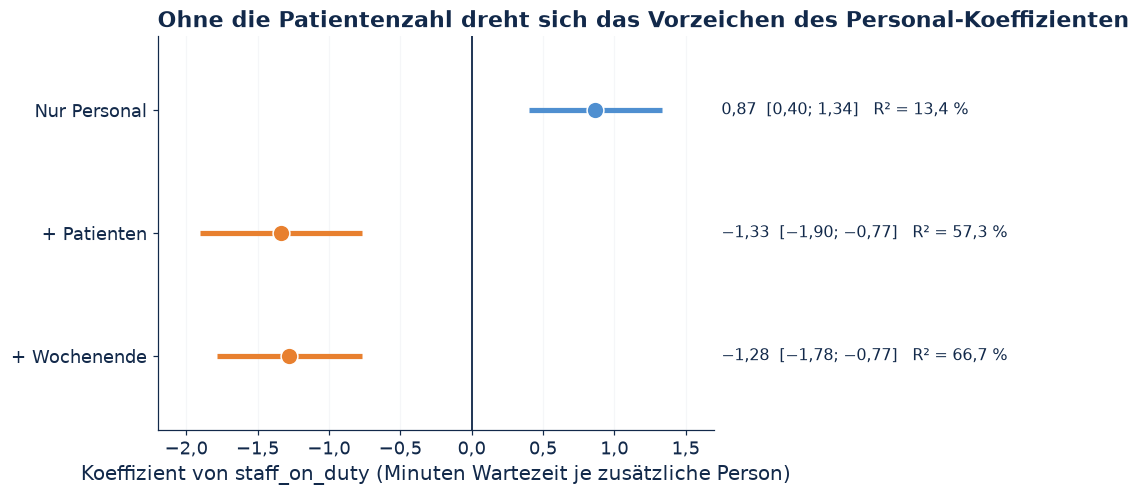

In [67]:
# Zusatz 7: Aufgabe 7, ausgelassene Variablen: Was passiert mit dem Koeffizienten von staff_on_duty?
def zusatz7_ausgelassen():
    mn = lambda x, nd: f"{x:.{nd}f}".replace("-", "−")
    modelle = [("Nur Personal", ["staff_on_duty"]), ("+ Patienten", ["staff_on_duty", "patients_scheduled"]), ("+ Wochenende", ["staff_on_duty", "patients_scheduled", "is_weekend"])]
    zeilen = []
    for name, cols in modelle:
        tab, r2, r2a, n, *_ = ops_fit(cols); z = tab.loc["staff_on_duty"]; zeilen.append((name, z.Koeffizient, z.untere, z.obere, z.p, r2))
    t = pd.DataFrame(zeilen, columns=["Modell", "b", "lo", "hi", "p", "R2"]); print(t.round(3).to_string(index=False))
    fig, ax = plt.subplots(figsize=(11, 4.9))
    for i, z in t.iterrows():
        farbe = LINE["rosa"] if z.b < 0 else LINE["blau"]
        ax.hlines(i, z.lo, z.hi, color=farbe, lw=3.4); ax.plot(z.b, i, "o", color=farbe, ms=11, markeredgecolor="white", zorder=3)
        ax.text(1.75, i, f"{mn(z.b, 2)}  [{mn(z.lo, 2)}; {mn(z.hi, 2)}]   R² = {mn(z.R2 * 100, 1)} %", va="center", ha="left", fontsize=10.5)
    ax.axvline(0, color=INK, lw=1.2); ax.set_yticks(range(3)); ax.set_yticklabels(t.Modell); ax.invert_yaxis()
    ax.set_xlim(-2.2, 1.7); ax.set_ylim(2.6, -.6); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Koeffizient von staff_on_duty (Minuten Wartezeit je zusätzliche Person)")
    ax.set_title("Ohne die Patientenzahl dreht sich das Vorzeichen des Personal-Koeffizienten", loc="left", fontsize=14.5)
    plt.subplots_adjust(left=.14, right=.6, top=.9, bottom=.17); show()

zusatz7_ausgelassen()


**Aussage:** Der Koeffizient für Personal wechselt von +0,87 im Modell nur mit Personal auf −1,33 und −1,28, sobald Patientenzahl und Wochenende dazukommen.

**Aufgabe 7 (ausgelassene Variablen):** Ohne die Patientenzahl sieht es aus, als würde mehr Personal die Wartezeit erhöhen. Der Grund: Volle Tage haben mehr Patienten und mehr Personal (r = 0,81), und der Personal-Koeffizient nimmt den Effekt der Patienten mit auf. Erst mit der Patientenzahl im Modell zeigt sich der eigentliche Zusammenhang. Das R² steigt dabei von 13,4 % über 57,3 % auf 66,7 %. Das ist dieselbe Gefahr wie bei Zusatz 6, nur stärker, weil das Vorzeichen kippt.

**Aufgabe 8 (fehlende Einflussgrößen):** Im Modell fehlen mögliche weitere Erklärungen. Vorstellbar sind Terminart-Mix, Uhrzeit und Spitzenzeiten, Räume und Kapazität, Saison, Personalausfälle, Termindauer und Walk-ins. Zu klären ist außerdem, wie die Wartezeit gemessen wurde (vermutlich als Tageswert), ob die Daten nur eine Klinik und nur 90 Tage abbilden, und ob aufeinanderfolgende Tage sich ähneln (mögliche Autokorrelation).

**Aufgabe 9 (keine Kausalität):** Die Daten sind beobachtet, nicht experimentell. Personal wird nicht zufällig vergeben, sondern nach erwartetem Andrang geplant, es kann also auch eine umgekehrte Wirkrichtung geben, und ausgelassene Größen bleiben möglich. Das Modell zeigt daher Zusammenhänge und taugt für Vorhersagen im beobachteten Bereich. Ob mehr Personal die Wartezeit senkt, ließe sich nur mit einem Experiment belegen, etwa einer zufälligen Zuteilung von Besetzungen auf Tage.

### Zusatz 8: Zwei Punkte zur Versuchsplanung (Mehrfachprüfung, Größenverhältnis)

Zwei Punkte fehlten im Review bisher: die **Fehlerkontrolle bei mehreren Prüfungen** und **auffällige Abweichungen vom geplanten Größenverhältnis** der Gruppen. Beides ist beschreibend und ändert keine Aussage der Tests.

**Mehrfachprüfung:** Zusatz 1 zeigt 15 Teilgruppen mit je einem 95-%-Intervall. Wer so oft prüft, findet allein durch Zufall leichter einen Ausreißer. Bei 15 unabhängigen Prüfungen mit α = 0,05 liegt die Chance auf mindestens einen Zufallsfund bei etwa 54 %. Die Bonferroni-Korrektur prüft jede Teilgruppe deshalb mit α/15 = 0,0033, die Intervalle gelten dann zu 99,67 %.

Anzahl Prüfungen m = 15 | Bonferroni-Niveau je Prüfung: α/m = 0,0033 (Intervalle zu 99,67 %)
Chance auf mindestens einen Zufallsfund bei 15 unabhängigen Tests ohne Korrektur: 54 %

      Gruppe  Differenz   uB    oB       p  p_Bonf
     Checkup       8,00 5,00 10,90 7,0e-14 1,1e-12
   Follow-up      10,30 6,70 13,90 9,8e-15 1,5e-13
  Specialist       7,50 1,60 13,40 2,4e-04 3,7e-03
      Urgent       8,30 4,20 12,50 1,5e-08 2,3e-07
      Montag      10,30 4,90 15,60 2,7e-07 4,1e-06
    Dienstag      10,00 5,00 15,00 3,4e-08 5,2e-07
    Mittwoch       5,90 1,70 10,00 5,1e-05 7,7e-04
  Donnerstag       7,40 1,30 13,60 4,4e-04 6,6e-03
     Freitag       8,80 3,70 13,80 1,1e-06 1,6e-05
     Samstag       9,20 3,80 14,70 2,5e-06 3,8e-05
     Sonntag       8,80 4,20 13,40 1,4e-07 2,1e-06
      Privat       8,60 5,20 12,00 2,5e-12 3,7e-11
    Medicare       8,10 4,90 11,30 2,4e-12 3,6e-11
    Medicaid       7,50 3,20 11,70 8,3e-07 1,2e-05
Selbstzahler      10,60 5,90 15,20 5,6e-10 8,4e-09


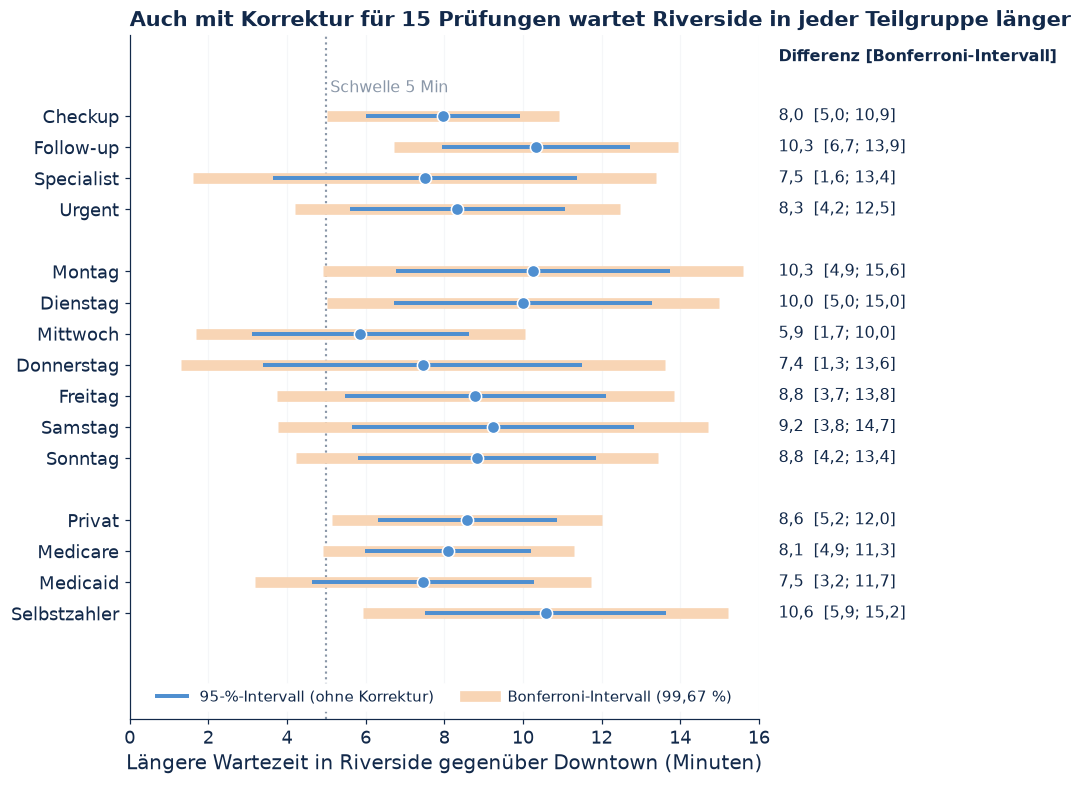

Teilgruppen, deren Bonferroni-Intervall die 0 einschließt: 0 von 15
Teilgruppen, deren Bonferroni-Intervall unter 5 Min reicht: Specialist, Urgent, Montag, Mittwoch, Donnerstag, Freitag, Samstag, Sonntag, Medicare, Medicaid
Kleinste Differenz: 5,9 Min | größtes korrigiertes p: 6,6e-03


In [68]:
# Zusatz 8a: Mehrfachprüfung, Intervalle der 15 Teilgruppen mit und ohne Bonferroni-Korrektur
def zusatz8_mehrfachpruefung():
    TAGE = {"Monday": "Montag", "Tuesday": "Dienstag", "Wednesday": "Mittwoch", "Thursday": "Donnerstag",
            "Friday": "Freitag", "Saturday": "Samstag", "Sunday": "Sonntag"}
    VERS = {"Private": "Privat", "Medicare": "Medicare", "Medicaid": "Medicaid", "Self-pay": "Selbstzahler"}
    gruppen = [(t, "appointment_type", t) for t in ["Checkup", "Follow-up", "Specialist", "Urgent"]]
    gruppen += [(TAGE[t], "day_of_week", t) for t in TAGE]
    gruppen += [(VERS[v], "insurance_type", v) for v in VERS]
    m = len(gruppen); alpha_b = .05 / m; niveau_b = 1 - alpha_b
    zeilen = []
    for name, spalte, wert in gruppen:
        sub = df[df[spalte] == wert]
        a = sub[sub.clinic_site == "Riverside"].wait_time_min.dropna(); b = sub[sub.clinic_site == "Downtown"].wait_time_min.dropna()
        d_ = a.mean() - b.mean(); se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b)); fg = welch_df(a, b)
        h95 = stats.t.ppf(.975, fg) * se; hb = stats.t.ppf(1 - alpha_b / 2, fg) * se
        p = stats.ttest_ind(a, b, equal_var=False).pvalue
        zeilen.append((name, d_, d_ - h95, d_ + h95, d_ - hb, d_ + hb, p, min(1, p * m)))
    tab = pd.DataFrame(zeilen, columns=["Gruppe", "Differenz", "u95", "o95", "uB", "oB", "p", "p_Bonf"])
    print(f"Anzahl Prüfungen m = {m} | Bonferroni-Niveau je Prüfung: α/m = {alpha_b:.4f} (Intervalle zu {niveau_b * 100:.2f} %)")
    print(f"Chance auf mindestens einen Zufallsfund bei {m} unabhängigen Tests ohne Korrektur: {100 * (1 - .95 ** m):.0f} %\n")
    ausgabe = tab[["Gruppe", "Differenz", "uB", "oB", "p", "p_Bonf"]].copy()
    ausgabe["p"] = ausgabe.p.map(lambda v: f"{v:.1e}"); ausgabe["p_Bonf"] = ausgabe.p_Bonf.map(lambda v: f"{v:.1e}")
    print(ausgabe.round(1).to_string(index=False))

    fig, ax = plt.subplots(figsize=(11, 7.4))
    ax.axvline(5, color=LINE["grau"], lw=1.4, ls=":", zorder=1)
    ax.text(5.1, -0.9, "Schwelle 5 Min", fontsize=10.5, color=LINE["grau"], va="center")
    for i, z in tab.iterrows():
        y = i + (1 if i >= 4 else 0) + (1 if i >= 11 else 0)
        ax.hlines(y, z.uB, z.oB, color=PASTEL["rosa"], lw=7, zorder=2)
        ax.hlines(y, z.u95, z.o95, color=LINE["blau"], lw=2.6, zorder=3)
        ax.plot(z.Differenz, y, "o", color=LINE["blau"], ms=8, markeredgecolor="white", zorder=4)
        ax.text(16.5, y, f"{z.Differenz:.1f}  [{z.uB:.1f}; {z.oB:.1f}]", va="center", fontsize=10.5)
    ypos = [i + (1 if i >= 4 else 0) + (1 if i >= 11 else 0) for i in range(m)]
    ax.text(16.5, -1.9, "Differenz [Bonferroni-Intervall]", fontsize=10.5, fontweight="bold", va="center")
    ax.set_yticks(ypos); ax.set_yticklabels(tab.Gruppe); ax.invert_yaxis(); ax.set_ylim(ypos[-1] + 3.4, -2.6)
    ax.axvline(0, color=INK, lw=1.2); ax.set_xlim(0, 16); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Längere Wartezeit in Riverside gegenüber Downtown (Minuten)")
    ax.set_title(f"Auch mit Korrektur für {m} Prüfungen wartet Riverside in jeder Teilgruppe länger", loc="left", fontsize=13.5)
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([0], [0], color=LINE["blau"], lw=2.6, label="95-%-Intervall (ohne Korrektur)"),
                       Line2D([0], [0], color=PASTEL["rosa"], lw=7, label=f"Bonferroni-Intervall ({niveau_b * 100:.2f} %)")],
              loc="lower center", ncol=2, frameon=True, framealpha=1, edgecolor="white", fontsize=10)
    plt.subplots_adjust(left=.14, right=.66, top=.93, bottom=.09); show()
    print("Teilgruppen, deren Bonferroni-Intervall die 0 einschließt:", int((tab.uB <= 0).sum()), "von", m)
    print("Teilgruppen, deren Bonferroni-Intervall unter 5 Min reicht:", ", ".join(tab[tab.uB < 5].Gruppe) or "keine")
    print(f"Kleinste Differenz: {tab.Differenz.min():.1f} Min | größtes korrigiertes p: {tab.p_Bonf.max():.1e}")

zusatz8_mehrfachpruefung()


**Aussage:** Auch nach der Korrektur für 15 Prüfungen schließt keines der Teilgruppen-Intervalle die 0 ein, bei zehn von ihnen reicht es aber unter die 5-Minuten-Schwelle.

**Einordnung:** Die Richtung des Unterschieds hält in allen Teilgruppen, das größte korrigierte p beträgt 0,0066 (Donnerstag). Dass er in jeder Teilgruppe mindestens 5 Minuten beträgt, ist dagegen nicht abgesichert, denn die Teilgruppen sind klein und die Intervalle breit. Maßgeblich bleibt der eine vorab geplante Gesamtvergleich, die Teilgruppen sind erkundend.

**Größenverhältnis:** Bei einem echten Experiment mit geplantem Verhältnis, etwa 1:1, prüft man vor der Auswertung, ob die tatsächlichen Gruppengrößen dazu passen (Chi-Quadrat-Anpassungstest). Eine auffällige Abweichung deutet auf Probleme bei der Zuteilung oder der Datenerfassung hin.

Gruppe mit SMS (Riverside, März): 98 Termine | Vergleichsgruppe (Downtown, Februar): 131 Termine
Erwartet bei 1:1: je 114,5 | Chi² = 4,76, df = 1, p = 0,029 | Verhältnis 1,34 : 1


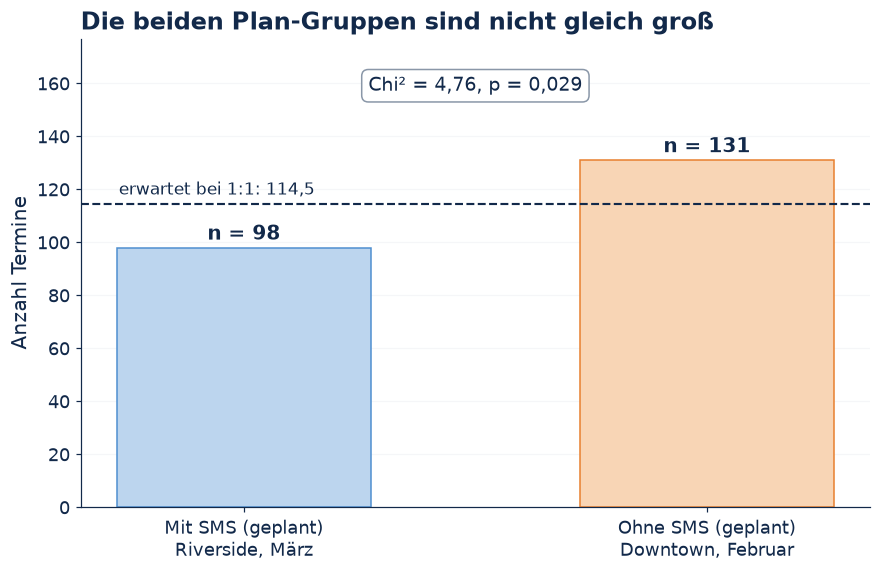

In [69]:
# Zusatz 8b: Größenverhältnis der Gruppen im SMS-Plan (Sample Ratio Mismatch, Chi-Quadrat-Anpassungstest)
def zusatz8_groessenverhaeltnis():
    d4 = df.copy(); d4["monat"] = pd.to_datetime(d4.appointment_date).dt.to_period("M").astype(str)
    mit_sms = d4[(d4.clinic_site == "Riverside") & (d4.monat == "2026-03")]     # Gruppe mit SMS laut Plan
    ohne_sms = d4[(d4.clinic_site == "Downtown") & (d4.monat == "2026-02")]     # Vergleichsgruppe laut Plan
    n1, n2 = len(mit_sms), len(ohne_sms); erw = (n1 + n2) / 2
    chi2 = ((n1 - erw) ** 2 + (n2 - erw) ** 2) / erw; p = stats.chi2.sf(chi2, 1)
    print(f"Gruppe mit SMS (Riverside, März): {n1} Termine | Vergleichsgruppe (Downtown, Februar): {n2} Termine")
    print(f"Erwartet bei 1:1: je {erw:.1f} | Chi² = {chi2:.2f}, df = 1, p = {p:.3f} | Verhältnis {n2 / n1:.2f} : 1")
    fig, ax = plt.subplots(figsize=(8.2, 5.4))
    bars = ax.bar(["Mit SMS (geplant)\nRiverside, März", "Ohne SMS (geplant)\nDowntown, Februar"], [n1, n2],
                  color=[PASTEL["blau"], PASTEL["rosa"]], edgecolor=[LINE["blau"], LINE["rosa"]], width=.55, zorder=2)
    ax.axhline(erw, color=INK, ls="--", lw=1.4, zorder=3)
    ax.text(-0.27, erw + 2, f"erwartet bei 1:1: {erw:.1f}".replace(".", ","), ha="left", va="bottom", fontsize=11, color=INK)
    for b_, n_ in zip(bars, [n1, n2]):
        ax.text(b_.get_x() + b_.get_width() / 2, n_ + 3, f"n = {n_}", ha="center", fontsize=13, fontweight="bold")
    ax.text(.5, max(n1, n2) * 1.2, f"Chi² = {chi2:.2f}, p = {p:.3f}".replace(".", ","), ha="center", fontsize=12.5,
            bbox=dict(boxstyle="round,pad=.35", fc="white", ec=LINE["grau"]))
    ax.set_ylim(0, max(n1, n2) * 1.35); ax.set_ylabel("Anzahl Termine"); ax.grid(axis="x", visible=False)
    ax.set_title("Die beiden Plan-Gruppen sind nicht gleich groß", loc="left"); plt.tight_layout(); show()
    return n1, n2, chi2, p

_ = zusatz8_groessenverhaeltnis()


**Aussage:** Die beiden Gruppen des SMS-Plans haben 98 und 131 Termine statt je 114,5 bei einem Verhältnis von 1:1 (Chi² = 4,76, p = 0,029), das Größenverhältnis weicht also auf.

**Einordnung:** Hier ist das kein klassisches Warnsignal, denn der Plan teilt nicht zufällig zu. Die Gruppen sind ein Standort in einem Monat und unterscheiden sich schon im Termin-Volumen. Es ist ein weiterer Hinweis auf die fehlende Randomisierung und zeigt die Prüfung, die man im echten Test vor der Auswertung machen würde, mit einer vorab festgelegten Grenze für den p-Wert.

### Zusatz 9: Relevanzgrenze, Stichprobe und Darstellung

Dieser Zusatz behandelt die fachliche Relevanzgrenze, den minimal nachweisbaren Effekt (MDE), den Stichprobenumfang und die Darstellung von Ergebnissen. Das meiste steht schon im Review. Zusatz 9 ergänzt, was noch gefehlt hat, und ordnet die Punkte zu. Es ist beschreibend und ändert keine Aussage der Tests.

| Punkt | Wo im Review |
|---|---|
| Fachliche Relevanzgrenze | 5 Minuten (Wartezeit) und 5 Prozentpunkte (SMS-Plan), die 5-Minuten-Schwelle ist als nachträglich gewählt gekennzeichnet (Abschnitt 3.4). |
| MDE hängt von Design und Teststärke ab | Welch-Test: etwa 1,8 Minuten bei 80 % Power (Zusatz 2). |
| Halbierte Zieldifferenz, vierfacher Umfang | Zusatz 9, erstes Diagramm. |
| Zu wenig Volumen: Laufzeit, Design, geringere Power | Zusatz 9, erstes Diagramm und Text unten. |
| Mehr Umfang macht kleine Effekte nicht relevant | Text unten. |
| Nicht signifikant heißt weder gleich noch wirkungslos | SMS-Plan-Vergleich, Text unten. |
| Absolut und relativ mit Ausgangsrate | Zusatz 9, zweites Diagramm. |
| Nutzen, Kosten, Unsicherheit, Intervallgrenzen | Text unten. |

**Stichprobenumfang:** Das Diagramm zeigt, wie viele Termine je Gruppe für verschiedene Zieldifferenzen der No-Show-Rate nötig sind (80 % Power, α = 0,05). Die Laufzeit rechnet mit dem Tempo von Riverside im Log (etwa 95 Termine je Monat), das ist eine Annahme und keine Prognose.

Ausgangsrate (alle Besuche): 10,75 % | Termine je Monat in Riverside: 95
5 Punkte: 471 je Gruppe | 2,5 Punkte (halbiert): 2155 (Faktor 4,6) | 2 Punkte: 3449
Laufzeit bei 95 Terminen je Monat und Gruppe: 5 Punkte 4,9 Monate, 2,5 Punkte 22,6 Monate, 2 Punkte 36,2 Monate


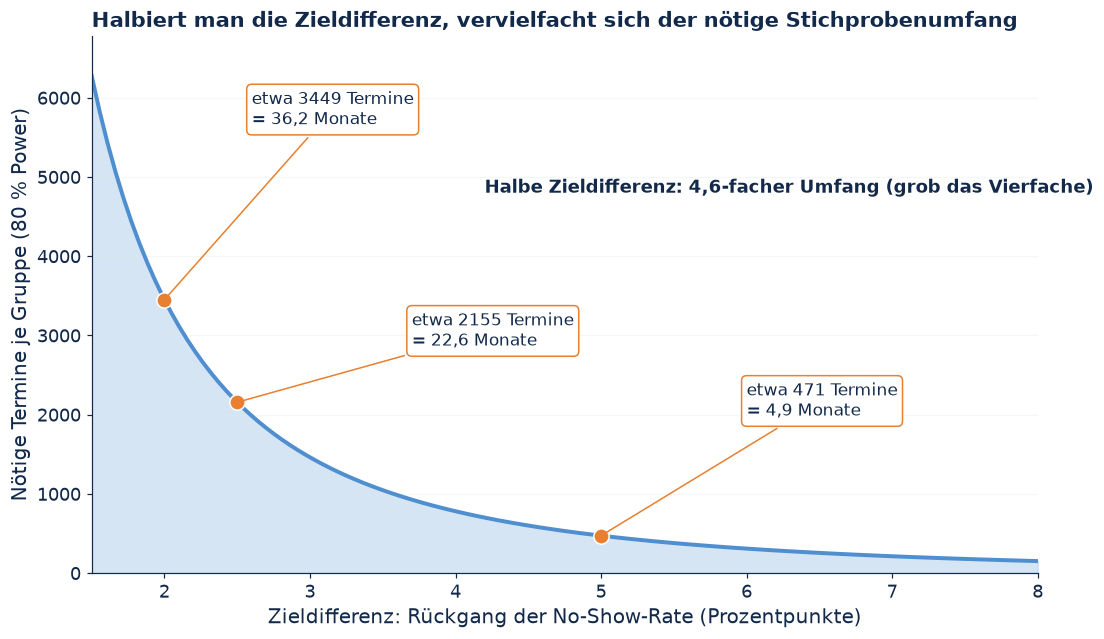

In [70]:
# Zusatz 9a: Nötige Stichprobe je Gruppe gegen die Zieldifferenz (No-Show-Rate), 80 % Teststärke, α = 0,05
def zusatz9_stichprobe():
    p0 = df.no_show.mean()
    def n_for(delta, pw=.8, alpha=.05):
        p2 = p0 - delta
        return (stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(pw)) ** 2 * (p0 * (1 - p0) + p2 * (1 - p2)) / delta ** 2
    deltas = np.linspace(.015, .08, 120)
    n_kurve = np.array([n_for(d_) for d_ in deltas])
    pro_monat = (df.clinic_site == "Riverside").sum() / 3          # Termine je Monat am kleineren Standort (Riverside)
    n5, n25, n2 = n_for(.05), n_for(.025), n_for(.02)
    print(f"Ausgangsrate (alle Besuche): {p0 * 100:.2f} % | Termine je Monat in Riverside: {pro_monat:.0f}")
    print(f"5 Punkte: {n5:.0f} je Gruppe | 2,5 Punkte (halbiert): {n25:.0f} (Faktor {n25 / n5:.1f}) | 2 Punkte: {n2:.0f}")
    print(f"Laufzeit bei {pro_monat:.0f} Terminen je Monat und Gruppe: 5 Punkte {n5 / pro_monat:.1f} Monate, 2,5 Punkte {n25 / pro_monat:.1f} Monate, 2 Punkte {n2 / pro_monat:.1f} Monate")

    fig, ax = plt.subplots(figsize=(10.5, 6))
    ax.fill_between(deltas * 100, n_kurve, color=PASTEL["blau"], alpha=.6, zorder=1)
    ax.plot(deltas * 100, n_kurve, color=LINE["blau"], lw=2.6, zorder=2)
    punkte = [(5, n5, (6.0, n5 + 1700), "etwa {:.0f} Termine\n= {:.1f} Monate".format(n5, n5 / pro_monat)),
              (2.5, n25, (3.7, n25 + 900), "etwa {:.0f} Termine\n= {:.1f} Monate".format(n25, n25 / pro_monat)),
              (2, n2, (2.6, n2 + 2400), "etwa {:.0f} Termine\n= {:.1f} Monate".format(n2, n2 / pro_monat))]
    for x_, y_, pos, text in punkte:
        ax.plot(x_, y_, "o", color=LINE["rosa"], ms=10, markeredgecolor="white", zorder=4)
        ax.annotate(text.replace(".", ","), (x_, y_), pos, fontsize=11, ha="left", va="center",
                    bbox=dict(boxstyle="round,pad=.3", fc="white", ec=LINE["rosa"]), arrowprops=dict(arrowstyle="-", color=LINE["rosa"]), zorder=5)
    ax.text(4.2, 4800, f"Halbe Zieldifferenz: {n25 / n5:.1f}-facher Umfang (grob das Vierfache)".replace(".", ","), fontsize=11.5, ha="left", fontweight="bold", color=INK)
    ax.set_xlabel("Zieldifferenz: Rückgang der No-Show-Rate (Prozentpunkte)"); ax.set_ylabel("Nötige Termine je Gruppe (80 % Power)")
    ax.set_xlim(1.5, 8); ax.set_ylim(0, n_kurve.max() * 1.08); ax.grid(axis="x", visible=False)
    ax.set_title("Halbiert man die Zieldifferenz, vervielfacht sich der nötige Stichprobenumfang", loc="left", fontsize=13.5)
    plt.tight_layout(); show()

zusatz9_stichprobe()


**Aussage:** Halbiert man die Zieldifferenz von 5 auf 2,5 Prozentpunkte, steigt der nötige Umfang von 471 auf 2155 Termine je Gruppe, bei Riverside-Tempo wären das 22,6 statt 4,9 Monate.

**Einordnung:** Der Faktor liegt mit 4,6 etwas über dem Vierfachen, weil sich bei kleinerer Differenz auch die Streuung der Raten leicht ändert. Reicht das Volumen nicht, hilft eine längere Laufzeit, ein besseres Design (zufällige Zuteilung, gleichzeitig, gleiche Standorte) oder man akzeptiert vorab eine geringere Power. Ein größerer Umfang erhöht nur die Präzision: Mit sehr vielen Terminen würde auch eine Minute Unterschied signifikant, relevant wäre sie deshalb nicht.

Ausgangsrate (Downtown, Februar): 13,0 % (17 von 131) | Vergleich (Riverside, März): 8,2 % (8 von 98)
Absolut: -4,8 Prozentpunkte [-12,7; 3,7] | relativ: -37 % [-72; 40]


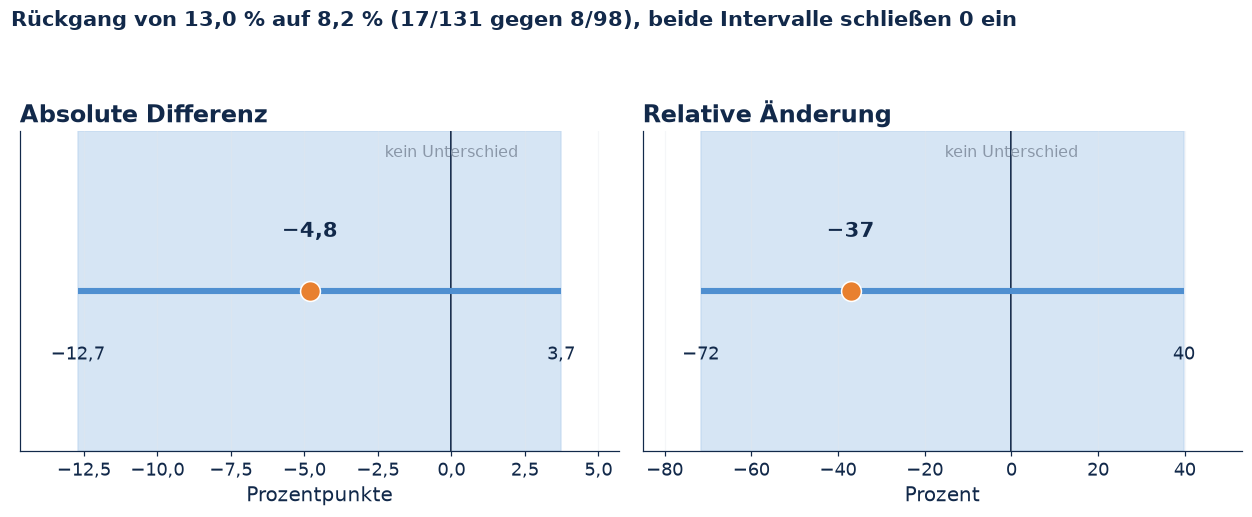

In [71]:
# Zusatz 9b: Absolute und relative Änderung mit Ausgangsrate und Bezug (Plan-Vergleich ohne SMS)
def zusatz9_absolut_relativ():
    d4 = df.copy(); d4["monat"] = pd.to_datetime(d4.appointment_date).dt.to_period("M").astype(str)
    a = d4[(d4.clinic_site == "Riverside") & (d4.monat == "2026-03")].no_show; b = d4[(d4.clinic_site == "Downtown") & (d4.monat == "2026-02")].no_show
    k1, n1, k2, n2 = int(a.sum()), len(a), int(b.sum()), len(b); p1, p2 = k1 / n1, k2 / n2
    def wilson_(k, n, z=1.96):
        p = k / n; dd = 1 + z ** 2 / n; c_ = (p + z ** 2 / (2 * n)) / dd; h_ = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / dd
        return c_ - h_, c_ + h_
    l1, h1 = wilson_(k1, n1); l2, h2 = wilson_(k2, n2)                  # Newcombe-Intervall wie im Plan-Vergleich oben
    abs_ = (p1 - p2) * 100
    abs_lo = (p1 - p2 - np.sqrt((p1 - l1) ** 2 + (h2 - p2) ** 2)) * 100; abs_hi = (p1 - p2 + np.sqrt((h1 - p1) ** 2 + (p2 - l2) ** 2)) * 100
    rr = p1 / p2; se_rr = np.sqrt(1 / k1 - 1 / n1 + 1 / k2 - 1 / n2)
    rel = (rr - 1) * 100; rel_lo, rel_hi = (np.exp(np.log(rr) + np.array([-1, 1]) * 1.96 * se_rr) - 1) * 100
    print(f"Ausgangsrate (Downtown, Februar): {p2 * 100:.1f} % ({k2} von {n2}) | Vergleich (Riverside, März): {p1 * 100:.1f} % ({k1} von {n1})")
    print(f"Absolut: {abs_:.1f} Prozentpunkte [{abs_lo:.1f}; {abs_hi:.1f}] | relativ: {rel:.0f} % [{rel_lo:.0f}; {rel_hi:.0f}]")
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
    for ax, wert, lo, hi, titel, einheit in [(axes[0], abs_, abs_lo, abs_hi, "Absolute Differenz", "Prozentpunkte"), (axes[1], rel, rel_lo, rel_hi, "Relative Änderung", "Prozent")]:
        ax.axvspan(lo, hi, color=PASTEL["blau"], alpha=.6, zorder=0)
        ax.hlines(0, lo, hi, color=LINE["blau"], lw=4, zorder=2); ax.plot(wert, 0, "o", color=LINE["rosa"], ms=13, markeredgecolor="white", zorder=3)
        ax.axvline(0, color=INK, lw=1.3, zorder=1)
        ax.text(wert, .17, (f"{wert:.1f}".replace(".", ",") if einheit != "Prozent" else f"{wert:.0f}").replace("-", "−"), ha="center", fontsize=14, fontweight="bold")
        ax.text(lo, -.17, (f"{lo:.1f}".replace(".", ",") if einheit != "Prozent" else f"{lo:.0f}").replace("-", "−"), ha="center", va="top", fontsize=12)
        ax.text(hi, -.17, (f"{hi:.1f}".replace(".", ",") if einheit != "Prozent" else f"{hi:.0f}").replace("-", "−"), ha="center", va="top", fontsize=12)
        pad = (hi - lo) * .12; ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(-.5, .5); ax.set_yticks([]); ax.grid(axis="y", visible=False); ax.set_xlabel(einheit); ax.set_title(titel, loc="left")
        ax.text(0, .42, "kein Unterschied", ha="center", fontsize=10.5, color=LINE["grau"])
    fig.suptitle(f"Rückgang von {p2 * 100:.1f} % auf {p1 * 100:.1f} % ({k2}/{n2} gegen {k1}/{n1}), beide Intervalle schließen 0 ein".replace(".", ","), x=.01, ha="left", fontsize=13.5, fontweight="bold", color=INK)
    plt.tight_layout(rect=(0, 0, 1, .93)); show()

zusatz9_absolut_relativ()


**Aussage:** Der scheinbare Rückgang von 4,8 Prozentpunkten entspricht relativ −37 % von der Ausgangsrate 13,0 %, aber beide Intervalle ([−12,7; 3,7] Punkte und [−72; 40] %) schließen „kein Rückgang“ ein.

**Einordnung:**
- **Absolut und relativ:** Immer beide angeben, mit Ausgangsrate und Bezug (hier Downtown im Februar, 17 von 131). „37 % weniger“ klingt größer als „4,8 Punkte“, beides beschreibt dasselbe.
- **Nicht signifikant:** Das Intervall ist mit einem Rückgang um bis zu 12,7 Punkte ebenso vereinbar wie mit einem leichten Anstieg. Es belegt weder „kein Effekt“ noch „Effekt“, die Daten sind schlicht zu dünn.
- **Intervallgrenzen:** Sie sind keine garantierten Extremwerte. Das 95-%-Intervall der Wartezeit-Differenz [7,3; 9,8] kann die wahre Differenz in etwa 5 von 100 Fällen verfehlen, und Werte in der Mitte sind plausibler als die am Rand.
- **Entscheidung:** Neben der Statistik zählen Nutzen und Kosten. Für Riverside sind es etwa 41 zusätzliche Wartestunden im Beobachtungszeitraum (Überschlag aus Abschnitt 3.2), was eine Maßnahme kosten darf, hängt von Personalkosten ab, die in den Daten fehlen.

### Zusatz 10: Modellgüte und Stabilität im Betriebsdaten-Modell

Zusatz 10 nutzt dieselben 90 Kliniktage wie Zusatz 7 und prüft, was dort noch fehlt: F-Test, Verhalten von R² und angepasstem R², Redundanz zwischen Prädiktoren, ein einzelner auffälliger Tag und die Frage, was „kleinste Quadrate“ von „kleinste Beträge“ unterscheidet. Er ist beschreibend und ändert keine Aussage weiter oben. Das einfache Modell erklärt 46,6 %, das Modell mit drei Prädiktoren 66,7 %.

**Teil 1: R², angepasstes R² und Zufallsspalten.** Zuerst die Kennzahlen, dann ein Test: Zu Modell 3 kommen nacheinander fünf reine Zufallsspalten (unabhängig erzeugt, Startwert 55).

Einfaches Modell (nur Patienten): R² = 46,6 % | Steigung 0,318 Min je Patient
Modell mit drei Prädiktoren: R² = 66,7 % | angepasstes R² = 65,6 %
Ohne Patientenzahl (Personal und Wochenende): R² = 28,2 %, angepasstes R² = 26,5 %, Koeffizient Personal +0,784
F-Test des Gesamtmodells (alle drei Steigungen gleich 0): F(3; 86) = 57,5, p = 1,75e-20

Fünf unabhängig erzeugte Zufallsspalten nacheinander ergänzt:
   3 Prädiktoren: R² = 66,72 %, angepasstes R² = 65,56 %
   4 Prädiktoren: R² = 66,78 %, angepasstes R² = 65,22 %
   5 Prädiktoren: R² = 66,90 %, angepasstes R² = 64,93 %
   6 Prädiktoren: R² = 67,19 %, angepasstes R² = 64,82 %
   7 Prädiktoren: R² = 68,60 %, angepasstes R² = 65,91 %
   8 Prädiktoren: R² = 68,72 %, angepasstes R² = 65,63 %
Höchstes angepasstes R² bei 7 Prädiktoren | R² sinkt jemals: nein | Zufallsspalten mit p < 0,05: 0 von 5

VIF Modell 3: patients_scheduled 3,0, staff_on_duty 3,0, is_weekend 1,0
VIF mit Personal je Patient: patients_scheduled 58,8, staff_on_duty 31,9

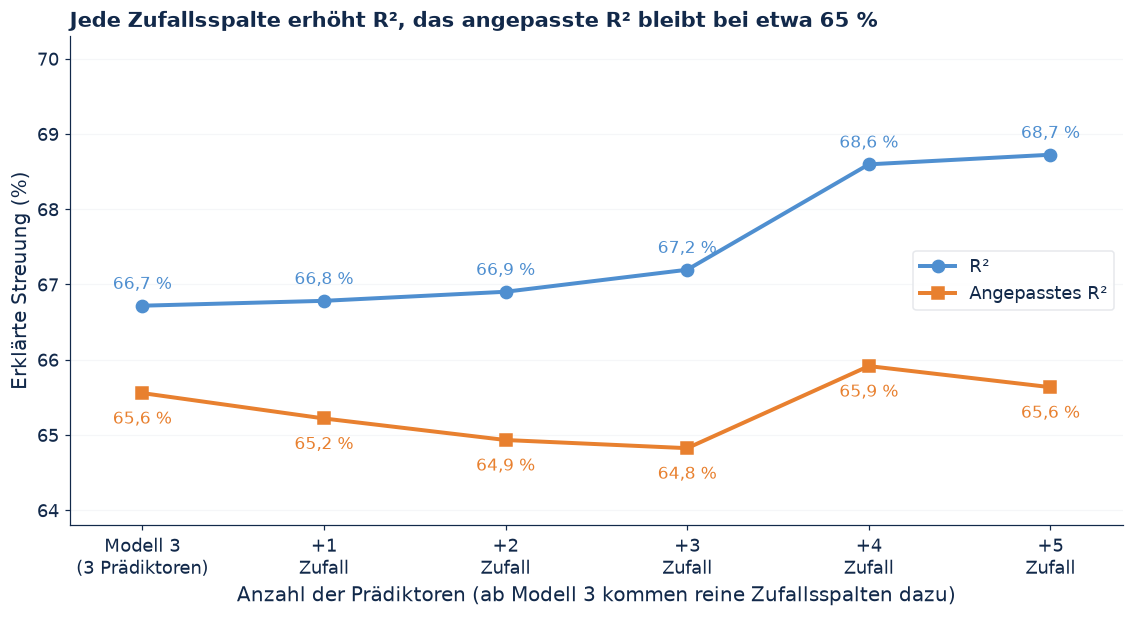

In [72]:
# Zusatz 10a: Modellqualität im Betriebsdaten-Modell: R², angepasstes R² und Zufallsspalten, F-Test, Personal je Patient (VIF)
def vif_werte(spalten):
    X = ops_df[spalten].values.astype(float); out = []
    for j in range(X.shape[1]):
        y_ = X[:, j]; Z = np.column_stack([np.ones(len(X)), np.delete(X, j, axis=1)])
        b_ = np.linalg.lstsq(Z, y_, rcond=None)[0]; r_ = y_ - Z @ b_
        out.append(1 / (r_ @ r_ / ((y_ - y_.mean()) @ (y_ - y_.mean()))))
    return out

def zusatz10_modellguete():
    y = ops_df.wait_time.values; n = len(y)
    tab1, r2_1, r2a_1, _, _, _, s1 = ops_fit(["patients_scheduled"])
    tab3, r2_3, r2a_3, _, _, _, s3 = ops_fit(OPS_X)
    k3 = len(OPS_X); F = (r2_3 / k3) / ((1 - r2_3) / (n - k3 - 1)); pF = stats.f.sf(F, k3, n - k3 - 1)
    print(f"Einfaches Modell (nur Patienten): R² = {r2_1 * 100:.1f} % | Steigung {tab1.Koeffizient.iloc[1]:.3f} Min je Patient")
    print(f"Modell mit drei Prädiktoren: R² = {r2_3 * 100:.1f} % | angepasstes R² = {r2a_3 * 100:.1f} %")
    tab2, r2_2, r2a_2, _, _, _, _ = ops_fit(["staff_on_duty", "is_weekend"])
    print(f"Ohne Patientenzahl (Personal und Wochenende): R² = {r2_2 * 100:.1f} %, angepasstes R² = {r2a_2 * 100:.1f} %, Koeffizient Personal {tab2.Koeffizient.loc['staff_on_duty']:+.3f}".replace(".", ",").replace("-", "−"))
    print(f"F-Test des Gesamtmodells (alle drei Steigungen gleich 0): F({k3}; {n - k3 - 1}) = {F:.1f}, p = {pF:.2e}\n")

    rng = np.random.default_rng(55); zufall = {f"Zufall {i}": rng.normal(size=n) for i in range(1, 6)}
    ops_df_orig = ops_df.copy(); verlauf = [(k3, r2_3, r2a_3)]; p_zufall = []
    spalten = list(OPS_X)
    try:
        for i, (nm, werte) in enumerate(zufall.items(), 1):
            ops_df[nm] = werte; spalten.append(nm)
            tab_, r2_, r2a_, _, _, _, _ = ops_fit(spalten); verlauf.append((k3 + i, r2_, r2a_)); p_zufall = list(tab_.p.iloc[-i:])
    finally:
        for nm in zufall: ops_df.drop(columns=nm, inplace=True, errors="ignore")
    print("Fünf unabhängig erzeugte Zufallsspalten nacheinander ergänzt:")
    for k_, r2_, r2a_ in verlauf: print(f"   {k_} Prädiktoren: R² = {r2_ * 100:.2f} %, angepasstes R² = {r2a_ * 100:.2f} %")
    bestes = max(verlauf, key=lambda t_: t_[2]); sinkt = any(verlauf[i + 1][1] < verlauf[i][1] - 1e-12 for i in range(len(verlauf) - 1))
    print(f"Höchstes angepasstes R² bei {bestes[0]} Prädiktoren | R² sinkt jemals: {'ja' if sinkt else 'nein'} | Zufallsspalten mit p < 0,05: {sum(p_ < .05 for p_ in p_zufall)} von 5\n")

    ops_df["staff_je_patient"] = ops_df.staff_on_duty / ops_df.patients_scheduled
    try:
        sp4 = OPS_X + ["staff_je_patient"]; tab4, r2_4, r2a_4, _, _, _, _ = ops_fit(sp4)
        v3, v4 = vif_werte(OPS_X), vif_werte(sp4)
        print("VIF Modell 3:", ", ".join(f"{a} {v:.1f}" for a, v in zip(OPS_X, v3)))
        print("VIF mit Personal je Patient:", ", ".join(f"{a} {v:.1f}" for a, v in zip(sp4, v4)))
        mn = lambda x, nd: f"{x:.{nd}f}".replace("-", "−")
        print(f"Koeffizient Personal: Modell 3 {mn(tab3.Koeffizient.loc['staff_on_duty'], 3)} (Intervall {mn(tab3.untere.loc['staff_on_duty'], 2)} bis {mn(tab3.obere.loc['staff_on_duty'], 2)}), mit Personal je Patient {mn(tab4.Koeffizient.loc['staff_on_duty'], 3)} (Intervall {mn(tab4.untere.loc['staff_on_duty'], 2)} bis {mn(tab4.obere.loc['staff_on_duty'], 2)})")
        print(f"Angepasstes R²: {r2a_3 * 100:.2f} % (Modell 3) gegenüber {r2a_4 * 100:.2f} % (mit Personal je Patient)")
    finally:
        ops_df.drop(columns="staff_je_patient", inplace=True, errors="ignore")

    fig, ax = plt.subplots(figsize=(10.5, 5.8)); xs = [v[0] for v in verlauf]
    ax.plot(xs, [v[1] * 100 for v in verlauf], "-o", color=LINE["blau"], lw=2.6, ms=8, label="R²")
    ax.plot(xs, [v[2] * 100 for v in verlauf], "-s", color=LINE["rosa"], lw=2.6, ms=8, label="Angepasstes R²")
    for x_, r_, a_ in verlauf:
        ax.annotate(f"{r_ * 100:.1f} %", (x_, r_ * 100), (0, 11), textcoords="offset points", ha="center", fontsize=11, color=LINE["blau"])
        ax.annotate(f"{a_ * 100:.1f} %", (x_, a_ * 100), (0, -20), textcoords="offset points", ha="center", fontsize=11, color=LINE["rosa"])
    ax.set_xticks(xs); ax.set_xticklabels(["Modell 3\n(3 Prädiktoren)"] + [f"+{i}\nZufall" for i in range(1, 6)])
    ax.set_ylim(63.8, 70.3); ax.set_xlim(2.6, 8.4); ax.set_xlabel("Anzahl der Prädiktoren (ab Modell 3 kommen reine Zufallsspalten dazu)"); ax.set_ylabel("Erklärte Streuung (%)")
    ax.legend(loc="center right", frameon=True, framealpha=.95); ax.grid(axis="x", visible=False)
    ax.set_title("Jede Zufallsspalte erhöht R², das angepasste R² bleibt bei etwa 65 %", loc="left", fontsize=13.5)
    plt.tight_layout(); show()

zusatz10_modellguete()


**Aussage:** Jede Zufallsspalte erhöht R² (von 66,7 % auf 68,7 %), das angepasste R² schwankt dagegen nur zwischen 64,8 % und 65,9 %, und keine der fünf Spalten ist signifikant.

**Einordnung:**
- **Gesamtmodell:** Der F-Test (F(3; 86) = 57,5, p = 1,75e-20) prüft, ob mindestens eine der drei Steigungen von null abweicht. Er sagt nicht, welche, und nicht, ob das Modell gut vorhersagt.
- **R² sinkt nie:** Mit jedem zusätzlichen Prädiktor steigt R² an den Trainingsdaten, auch bei reinem Zufall. Ein höheres R² allein belegt also keinen Nutzen.
- **Angepasstes R²:** Es bestraft zusätzliche Prädiktoren, kann aber durch Zufall trotzdem leicht steigen: Bei sieben Prädiktoren liegt es mit 65,9 % um 0,35 Punkte über Modell 3. Das ist keine Verbesserung, sondern Zufall in einem einzigen Durchlauf.
- **Auswahl nach p-Werten:** Bei fünf unabhängigen Zufallsspalten wäre mit Wahrscheinlichkeit 1 − 0,95⁵ ≈ 23 % mindestens eine davon bei α = 0,05 „signifikant“. Wer Prädiktoren nachträglich nach ihren p-Werten auswählt, findet so Zusammenhänge, die nur im Rauschen liegen, und seine p-Werte sind dann nicht mehr gültig.
- **Ohne Patientenzahl:** Mit nur Personal und Wochenende erklärt das Modell 28,2 % (angepasst 26,5 %), und der Personal-Koeffizient bleibt positiv (+0,784). Erst mit der Patientenzahl dreht er das Vorzeichen (Zusatz 7). Welches Modell man zeigt, hängt von der Frage ab: für „wie steht es um Personal bei gleicher Auslastung?“ Modell 3, für eine grobe Übersicht das einfache.

**Teil 2: Personal je Patient und Redundanz.** Ergänzt man `staff_on_duty / patients_scheduled`, ist diese Spalte aus den beiden anderen fast berechenbar. Die VIF-Werte steigen von etwa 3 auf 59, 32 und 20, der Koeffizient für Personal wechselt von −1,276 [−1,78; −0,77] auf −0,895 [−2,56; 0,77], sein Intervall schließt jetzt die 0 ein, und das angepasste R² sinkt leicht von 65,6 % auf 65,2 %. Zum Vorhersagen verändert das wenig, für die Deutung einzelner Koeffizienten ist das Modell aber unbrauchbar. Man sollte also vorher überlegen, welches Ziel man hat: vorhersagen oder einzelne Zusammenhänge schätzen.

**Teil 3: Tag 37 und die absolute Fehlersumme.** Tag 37 hat im einfachen Modell das größte positive Residuum (+7,1 Minuten: 15,1 Minuten Wartezeit bei nur 23 Patienten). Das Diagramm zeigt die Gerade mit allen Tagen, ohne Tag 37 und nach dem Kriterium „kleinste absolute Fehler“ (Raster über die Steigung, Achsenabschnitt jeweils als Median von y − Steigung · x).

Größtes positives Residuum: Tag 37 (Patienten 23, Wartezeit 15,1 Min, Residuum +7,1 Min)
Alle 90 Tage:      Steigung 0,318 | R² = 46,6 % | Schiefe der Residuen +0,53
Ohne Tag 37:        Steigung 0,334 | R² = 50,9 % | Schiefe der Residuen +0,42
Minimierung der absoluten Fehler: Steigung 0,363, Achsenabschnitt -0,90 | Summe |Residuen| 171,3 gegenüber 173,2 bei OLS
OLS minimiert die Summe der Quadrate, nicht der Beträge: Große Abweichungen wie Tag 37 bekommen dadurch mehr Gewicht.


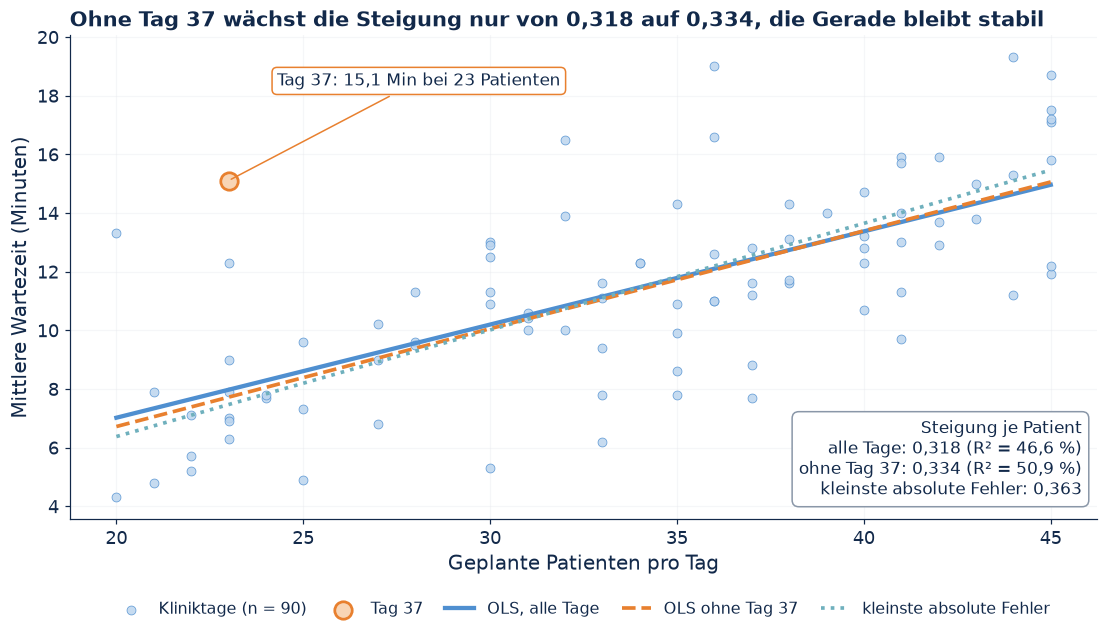

In [73]:
# Zusatz 10b: Einfache Regression mit Tag 37: Sensitivitätsanalyse und Vergleich mit der Minimierung der absoluten Fehler
def zusatz10_tag37():
    x = ops_df.patients_scheduled.values.astype(float); y = ops_df.wait_time.values; n = len(y)
    def ols(xx, yy):
        b1_ = ((xx - xx.mean()) * (yy - yy.mean())).sum() / ((xx - xx.mean()) ** 2).sum(); b0_ = yy.mean() - b1_ * xx.mean()
        res_ = yy - (b0_ + b1_ * xx); r2_ = 1 - (res_ @ res_) / ((yy - yy.mean()) @ (yy - yy.mean()))
        return b0_, b1_, r2_, res_
    b0, b1, r2, res = ols(x, y)
    tag = int(np.argmax(res)); print(f"Größtes positives Residuum: Tag {tag + 1} (Patienten {x[tag]:.0f}, Wartezeit {y[tag]:.1f} Min, Residuum {res[tag]:+.1f} Min)".replace(".", ","))
    keep = np.arange(n) != tag; c0, c1, c2, res2 = ols(x[keep], y[keep])
    print(f"Alle {n} Tage:      Steigung {b1:.3f} | R² = {r2 * 100:.1f} % | Schiefe der Residuen {stats.skew(res):+.2f}".replace(".", ","))
    print(f"Ohne Tag {tag + 1}:        Steigung {c1:.3f} | R² = {c2 * 100:.1f} % | Schiefe der Residuen {stats.skew(res2):+.2f}".replace(".", ","))
    # Minimierung der absoluten Fehler: Raster über die Steigung, Achsenabschnitt = Median von y − Steigung·x
    gitter = np.linspace(0, 0.7, 2801); sav = [np.abs(y - (np.median(y - s_ * x) + s_ * x)).sum() for s_ in gitter]
    l1 = gitter[int(np.argmin(sav))]; l0 = np.median(y - l1 * x)
    sav_ols = np.abs(res).sum(); sav_l1 = np.abs(y - (l0 + l1 * x)).sum()
    print(f"Minimierung der absoluten Fehler: Steigung {l1:.3f}, Achsenabschnitt {l0:.2f} | Summe |Residuen| {sav_l1:.1f} gegenüber {sav_ols:.1f} bei OLS".replace(".", ","))
    print("OLS minimiert die Summe der Quadrate, nicht der Beträge: Große Abweichungen wie Tag", tag + 1, "bekommen dadurch mehr Gewicht.")

    fig, ax = plt.subplots(figsize=(10.5, 6))
    ax.scatter(x, y, s=34, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=.5, alpha=.85, label="Kliniktage (n = 90)", zorder=2)
    ax.scatter(x[tag], y[tag], s=130, color=PASTEL["rosa"], edgecolor=LINE["rosa"], lw=1.8, zorder=4, label=f"Tag {tag + 1}")
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, b0 + b1 * xs, color=LINE["blau"], lw=2.8, label="OLS, alle Tage", zorder=3)
    ax.plot(xs, c0 + c1 * xs, color=LINE["rosa"], lw=2.4, ls="--", label=f"OLS ohne Tag {tag + 1}", zorder=3)
    ax.plot(xs, l0 + l1 * xs, color=LINE["pfirsich"], lw=2.4, ls=":", label="kleinste absolute Fehler", zorder=3)
    mn = lambda v, nd: f"{v:.{nd}f}".replace("-", "−")
    ax.annotate(f"Tag {tag + 1}: {mn(y[tag], 1)} Min bei {x[tag]:.0f} Patienten", (x[tag], y[tag]), (24.3, 18.5), fontsize=11, ha="left", va="center",
                bbox=dict(boxstyle="round,pad=.3", fc="white", ec=LINE["rosa"]), arrowprops=dict(arrowstyle="-", color=LINE["rosa"]), zorder=5)
    ax.text(.985, .04, f"Steigung je Patient\nalle Tage: {mn(b1, 3)} (R² = {mn(r2 * 100, 1)} %)\nohne Tag {tag + 1}: {mn(c1, 3)} (R² = {mn(c2 * 100, 1)} %)\nkleinste absolute Fehler: {mn(l1, 3)}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=11, bbox=dict(boxstyle="round,pad=.4", fc="white", ec=LINE["grau"]), zorder=6)
    ax.set_xlabel("Geplante Patienten pro Tag"); ax.set_ylabel("Mittlere Wartezeit (Minuten)"); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.14), ncol=5, frameon=False, fontsize=10.5, columnspacing=1.4, handlelength=1.8)
    ax.set_title(f"Ohne Tag {tag + 1} wächst die Steigung nur von {mn(b1, 3)} auf {mn(c1, 3)}, die Gerade bleibt stabil".replace(".", ","), loc="left", fontsize=13.5)
    plt.tight_layout(); show()

zusatz10_tag37()


**Aussage:** Ohne Tag 37 wächst die Steigung nur von 0,318 auf 0,334 Minuten je Patient, die Gerade bleibt also stabil, und das Kriterium der kleinsten absoluten Fehler liefert mit 0,363 eine etwas steilere Gerade.

**Einordnung:**
- **Sensitivität:** Ohne Tag 37 steigt R² von 46,6 % auf 50,9 %, die Schiefe der Residuen sinkt von +0,53 auf +0,42 und bleibt positiv. Die Aussage „mehr Patienten, längere Wartezeit“ ändert sich nicht.
- **Kein Ausschluss:** Tag 37 bleibt in allen Auswertungen drin. Ein Ausschluss bräuchte einen fachlichen oder erhebungsbezogenen Grund (etwa einen Messfehler), eine günstigere Kennzahl allein genügt dafür nicht.
- **Quadrate und Beträge:** OLS minimiert die Summe der Quadrate und gibt großen Abweichungen mehr Gewicht. Das Betragskriterium kommt mit 171,3 auf eine kleinere Summe der absoluten Residuen als OLS (173,2). Das Ergebnis ist rasterbasiert, die Steigung also eine Näherung. Dass beide so nah beieinanderliegen, spricht dafür, dass Tag 37 die Gerade nicht verzerrt.

### Zusatz 11: Wahrscheinlichkeitsmodelle mit den Projektdaten

Zusatz 11 rechnet bedingte Wahrscheinlichkeit und den Satz von Bayes, Binomial- und Poisson-Verteilung sowie Gamma-Verteilung und Perzentile mit den **echten Besuchsdaten** (n = 1.200). Die Zahlen weichen deshalb von Beispielwerten des Falls (etwa einer No-Show-Rate von 10 % und einer mittleren Wartezeit von 9,4 Minuten) ab: Die No-Show-Rate beträgt hier 10,75 % (129 von 1.200), die mittlere Wartezeit 14,25 Minuten. Der Zusatz ist beschreibend und ändert keine Aussage weiter oben.

**Teil 1: Bedingte Wahrscheinlichkeit und Satz von Bayes.** Zwei Fragen mit derselben Tabelle: Wie wahrscheinlich ist ein No-Show **bei einer bestimmten Terminart**, und wie verteilen sich die No-Shows **auf die Terminarten**?

P(No-Show) = 129 / 1200 = 10,75 %

                  Termine  P(Terminart)  No-Shows  P(No-Show | Terminart)  P(Terminart | No-Show)
appointment_type                                                                                 
Checkup               490         40,80        45                    9,20                   34,90
Follow-up             348         29,00        35                   10,10                   27,10
Urgent                233         19,40        40                   17,20                   31,00
Specialist            129         10,80         9                    7,00                    7,00

Kontrolle mit der Formel P(No-Show | T) · P(T) / P(No-Show): größte Abweichung 0,0e+00
Unabhängigkeit? P(Urgent und No-Show) = 3,33 % gegenüber P(Urgent) · P(No-Show) = 2,09 %
Chi-Quadrat-Test auf Unabhängigkeit von Terminart und No-Show: Chi² = 13,34, p = 0,0040


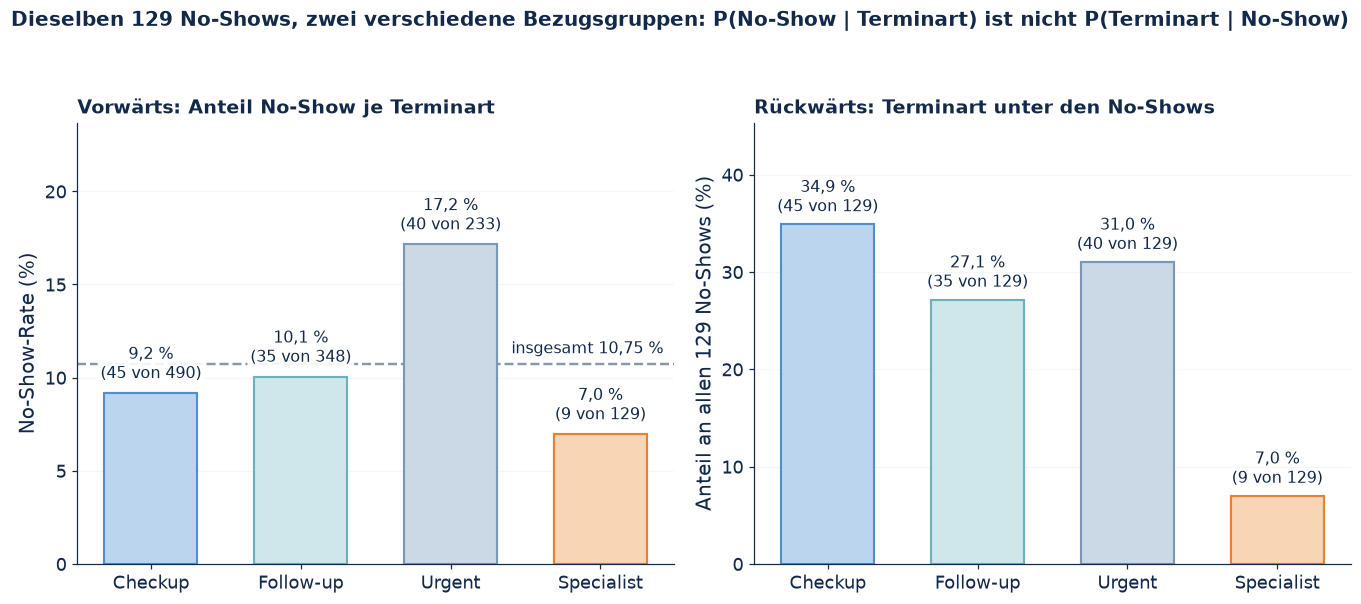

In [74]:
# Zusatz 11a: Bedingte Wahrscheinlichkeit und Satz von Bayes mit den Besuchsdaten (No-Show und Terminart)
def zusatz11_bayes():
    p_ns = df.no_show.mean(); n_ns = int(df.no_show.sum()); n = len(df)
    reihe = df.appointment_type.value_counts().index.tolist()
    vor = df.groupby("appointment_type").no_show.agg(["size", "sum"]).loc[reihe]
    anteil_typ = vor["size"] / n
    p_ns_typ = vor["sum"] / vor["size"]                              # P(No-Show | Terminart)
    p_typ_ns = vor["sum"] / n_ns                                     # P(Terminart | No-Show), Satz von Bayes
    bayes = p_ns_typ * anteil_typ / p_ns                             # dasselbe über die Formel
    print(f"P(No-Show) = {n_ns} / {n} = {p_ns * 100:.2f} %\n")
    print(pd.DataFrame({"Termine": vor["size"], "P(Terminart)": (anteil_typ * 100).round(1), "No-Shows": vor["sum"],
                        "P(No-Show | Terminart)": (p_ns_typ * 100).round(1), "P(Terminart | No-Show)": (p_typ_ns * 100).round(1)}).to_string())
    print(f"\nKontrolle mit der Formel P(No-Show | T) · P(T) / P(No-Show): größte Abweichung {np.abs(bayes - p_typ_ns).max():.1e}")
    u, s_ = "Urgent", "Specialist"
    print(f"Unabhängigkeit? P(Urgent und No-Show) = {vor.loc[u, 'sum'] / n * 100:.2f} % gegenüber P(Urgent) · P(No-Show) = {anteil_typ[u] * p_ns * 100:.2f} %")
    chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(df.appointment_type, df.no_show), correction=False)
    print(f"Chi-Quadrat-Test auf Unabhängigkeit von Terminart und No-Show: Chi² = {chi2:.2f}, p = {p_chi:.4f}".replace(".", ","))

    fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.6), sharey=False)
    farben = [("blau"), ("pfirsich"), ("gruen"), ("rosa")]
    x = np.arange(len(reihe))
    for ax, werte, titel, ylab in ((axs[0], p_ns_typ * 100, "Vorwärts: Anteil No-Show je Terminart", "No-Show-Rate (%)"),
                                   (axs[1], p_typ_ns * 100, "Rückwärts: Terminart unter den No-Shows", "Anteil an allen 129 No-Shows (%)")):
        ax.bar(x, werte, color=[PASTEL[c] for c in farben], edgecolor=[LINE[c] for c in farben], lw=1.4, width=.62, zorder=2)
        ax.set_xticks(x); ax.set_xticklabels(reihe); ax.set_ylabel(ylab); ax.set_title(titel, fontsize=12.5, loc="left"); ax.grid(axis="x", visible=False)
    for i_, t_ in enumerate(reihe):
        axs[0].text(i_, p_ns_typ[t_] * 100 + .5, f"{p_ns_typ[t_] * 100:.1f} %\n({int(vor.loc[t_, 'sum'])} von {int(vor.loc[t_, 'size'])})", ha="center", va="bottom", fontsize=10.5, color=INK, bbox=dict(boxstyle="round,pad=.18", fc="white", ec="none", alpha=.9), zorder=5)
        axs[1].text(i_, p_typ_ns[t_] * 100 + .8, f"{p_typ_ns[t_] * 100:.1f} %\n({int(vor.loc[t_, 'sum'])} von {n_ns})", ha="center", va="bottom", fontsize=10.5, color=INK)
    axs[0].axhline(p_ns * 100, color=LINE["grau"], ls="--", lw=1.6, zorder=1); axs[0].text(3.42, p_ns * 100 + .35, f"insgesamt {p_ns * 100:.2f} %", ha="right", va="bottom", fontsize=10.5, color=INK)
    axs[0].set_ylim(0, max(p_ns_typ * 100) * 1.38); axs[1].set_ylim(0, max(p_typ_ns * 100) * 1.30)
    fig.suptitle("Dieselben 129 No-Shows, zwei verschiedene Bezugsgruppen: P(No-Show | Terminart) ist nicht P(Terminart | No-Show)", x=.01, ha="left", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=(0, 0, 1, .94)); show()

zusatz11_bayes()


**Aussage:** Urgent-Termine haben mit 17,2 % die höchste No-Show-Rate, unter allen 129 No-Shows machen sie aber nur 31,0 % aus, weil Checkups (34,9 %) so viel häufiger vorkommen.

**Einordnung:**
- **Zwei Bezugsgruppen:** P(No-Show | Urgent) = 40 von 233 und P(Urgent | No-Show) = 40 von 129 haben denselben Zähler und verschiedene Nenner. Beide zu verwechseln ist der klassische Fehler.
- **Satz von Bayes:** P(Terminart | No-Show) = P(No-Show | Terminart) · P(Terminart) / P(No-Show). Die Formel ergibt genau die Anteile der Tabelle (die Kontrolle im Ausdruck zeigt Abweichung 0).
- **Nicht unabhängig:** Bei Unabhängigkeit wäre P(Urgent und No-Show) = 19,4 % · 10,75 % = 2,09 %, beobachtet sind es 3,33 %. Der Chi-Quadrat-Test bestätigt den Zusammenhang (Chi² = 13,34, p = 0,004), er passt zum Befund aus Abschnitt 1.7.
- **Zufall bei „9 von 129“:** Die Zahl 129 kommt in der Abbildung zweimal vor: 129 Specialist-Termine (davon 9 No-Shows) und 129 No-Shows insgesamt (davon 9 Specialist). Das ist Zufall, die Nenner meinen verschiedene Dinge.

**Teil 2: Binomialmodell und Poisson-Prüfung.** Die Binomialverteilung beschreibt die Zahl der No-Shows bei n unabhängigen Terminen mit gleicher Wahrscheinlichkeit p. Die Besuchsdaten haben keine festen Vormittagsblöcke, also betrachte ich jeden **Standort-Tag** (350 Tage mit mindestens einem Termin, im Mittel 3,43 Termine) und vergleiche die beobachtete Zahl der No-Shows mit dem Binomialmodell bei p = 10,75 %.

350 Standort-Tage mit mindestens einem Termin, im Mittel 3,43 Termine (kleinster Tag 1, größter 8)
Modell: Binomial(n je Tag, p = 10,75 %), unabhängige Termine, gleiche Rate an allen Tagen

 No-Shows je Standort-Tag  beobachtete Tage  erwartet
                        0               240    241,10
                        1                92     91,00
                        2                17     16,00
                        3                 1      1,80

Streuung: Summe der quadrierten Abweichungen / erwartete Binomial-Varianz = 104,4 / 115,1 = 0,91
Ein Wert um 1,00 passt zur Binomialverteilung, deutlich darüber spräche für gemeinsame Einflüsse auf die Termine eines Tages (Überstreuung).

Nur Standort-Tage mit genau 4 Terminen (n = 66): beobachtet [60,6, 33,3, 6,1, 0,0, 0,0] %, Binomial(4; 10,75 %) [63,5, 30,6, 5,5, 0,4, 0,0] %

Poisson-Prüfung der Termine je Standort-Tag (mit Tagen ohne Termine, 364 Standort-Tage): Mittelwert 3,30, Varianz 3,08, Verhältnis 0,93
Das Verhältnis liegt 

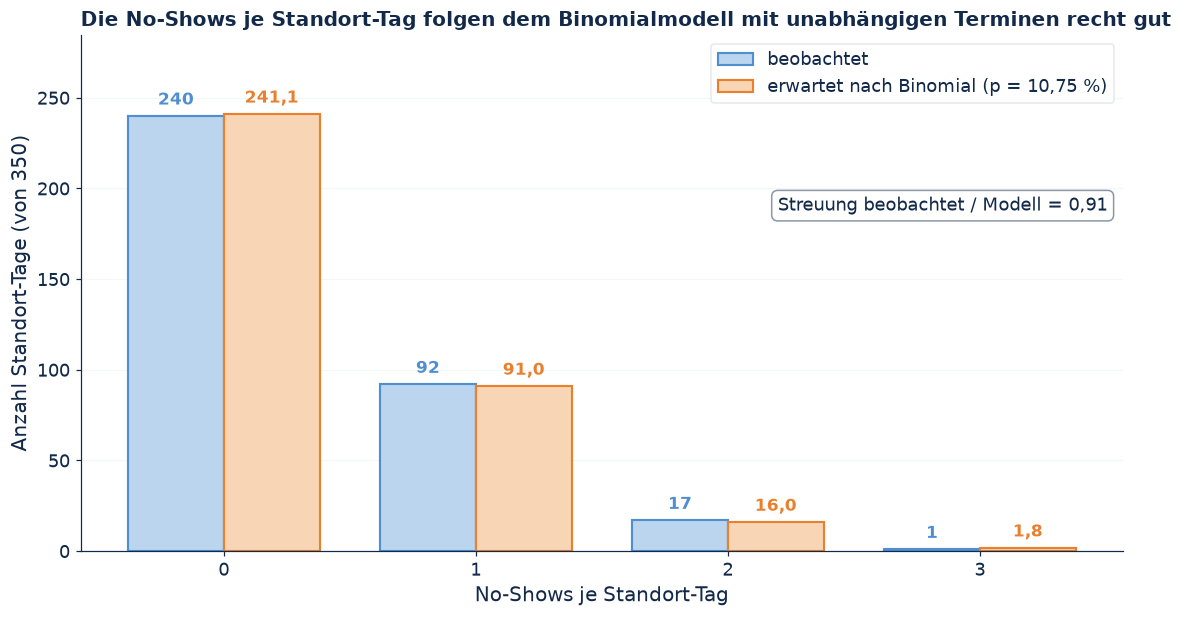

In [75]:
# Zusatz 11b: Binomialmodell für No-Shows je Standort-Tag und Poisson-Prüfung der Termine je Standort-Tag
def zusatz11_binomial():
    p = df.no_show.mean()
    tage = df.groupby(["clinic_site", "appointment_date"]).no_show.agg(n="size", k="sum").reset_index()
    m = len(tage); ks = np.arange(0, int(tage.k.max()) + 1)
    beob = np.array([(tage.k == k_).sum() for k_ in ks])
    erw = np.array([stats.binom.pmf(k_, tage.n, p).sum() for k_ in ks])                 # Summe der Binomialwahrscheinlichkeiten über alle Standort-Tage (n je Tag verschieden)
    var_beob = ((tage.k - tage.n * p) ** 2).sum(); var_mod = (tage.n * p * (1 - p)).sum()
    disp = var_beob / var_mod; chi_df = m
    print(f"{m} Standort-Tage mit mindestens einem Termin, im Mittel {tage.n.mean():.2f} Termine (kleinster Tag {tage.n.min()}, größter {tage.n.max()})")
    print(f"Modell: Binomial(n je Tag, p = {p * 100:.2f} %), unabhängige Termine, gleiche Rate an allen Tagen\n")
    print(pd.DataFrame({"No-Shows je Standort-Tag": ks, "beobachtete Tage": beob, "erwartet": erw.round(1)}).to_string(index=False))
    print(f"\nStreuung: Summe der quadrierten Abweichungen / erwartete Binomial-Varianz = {var_beob:.1f} / {var_mod:.1f} = {disp:.2f}")
    print("Ein Wert um 1,00 passt zur Binomialverteilung, deutlich darüber spräche für gemeinsame Einflüsse auf die Termine eines Tages (Überstreuung).")
    v4 = tage[tage.n == 4]
    if len(v4):
        b4 = np.array([(v4.k == k_).mean() for k_ in range(5)]); m4 = stats.binom.pmf(np.arange(5), 4, p)
        print(f"\nNur Standort-Tage mit genau 4 Terminen (n = {len(v4)}): beobachtet {np.round(b4 * 100, 1).tolist()} %, Binomial(4; {p * 100:.2f} %) {np.round(m4 * 100, 1).tolist()} %")

    alle = pd.MultiIndex.from_product([df.clinic_site.unique(), pd.date_range(df.appointment_date.min(), df.appointment_date.max())])
    zaehl = df.groupby(["clinic_site", "appointment_date"]).size().reindex(alle, fill_value=0)
    lam = zaehl.mean(); print(f"\nPoisson-Prüfung der Termine je Standort-Tag (mit Tagen ohne Termine, {len(zaehl)} Standort-Tage): Mittelwert {lam:.2f}, Varianz {zaehl.var(ddof=1):.2f}, Verhältnis {zaehl.var(ddof=1) / lam:.2f}")
    print("Bei einer Poisson-Verteilung wären Mittelwert und Varianz gleich (Verhältnis 1). Ein Verhältnis deutlich unter 1 spricht für eine begrenzte Kapazität.".replace(".", ",") if zaehl.var(ddof=1) / lam < .9 else "Das Verhältnis liegt nahe 1: mit der Poisson-Annahme vereinbar.")

    fig, ax = plt.subplots(figsize=(10.5, 5.8)); w = .38
    ax.bar(ks - w / 2, beob, w, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=1.4, label="beobachtet", zorder=2)
    ax.bar(ks + w / 2, erw, w, color=PASTEL["rosa"], edgecolor=LINE["rosa"], lw=1.4, label=f"erwartet nach Binomial (p = {p * 100:.2f} %)", zorder=2)
    for k_, b_, e_ in zip(ks, beob, erw):
        ax.text(k_ - w / 2, b_ + 4, f"{b_}", ha="center", va="bottom", fontsize=11, color=LINE["blau"], fontweight="bold")
        ax.text(k_ + w / 2, e_ + 4, f"{e_:.1f}", ha="center", va="bottom", fontsize=11, color=LINE["rosa"], fontweight="bold")
    ax.set_xticks(ks); ax.set_xlabel("No-Shows je Standort-Tag"); ax.set_ylabel(f"Anzahl Standort-Tage (von {m})"); ax.set_ylim(0, max(beob.max(), erw.max()) * 1.18)
    ax.legend(loc="upper right", frameon=True, framealpha=.95); ax.grid(axis="x", visible=False)
    ax.text(.985, .66, f"Streuung beobachtet / Modell = {disp:.2f}".replace(".", ","), transform=ax.transAxes, ha="right", fontsize=11.5, bbox=dict(boxstyle="round,pad=.35", fc="white", ec=LINE["grau"]))
    ax.set_title("Die No-Shows je Standort-Tag folgen dem Binomialmodell mit unabhängigen Terminen recht gut", loc="left", fontsize=13)
    plt.tight_layout(); show()

zusatz11_binomial()


**Aussage:** Die beobachteten No-Shows je Standort-Tag (240, 92, 17 und 1 Tage mit 0 bis 3 No-Shows) liegen sehr nah an den Erwartungen des Binomialmodells (241,1, 91,0, 16,0 und 1,8).

**Einordnung:**
- **Streuung:** Das Verhältnis aus beobachteter und erwarteter Streuung beträgt 0,91. Ein Wert deutlich über 1 würde auf gemeinsame Einflüsse an einem Tag hindeuten (das träfe zu, wenn Blöcke einen gemeinsamen Einflussfaktor hätten). Hier gibt es dafür keinen Hinweis. Dass der Wert leicht unter 1 liegt, ist mit den unterschiedlichen Raten je Terminart vereinbar, denn ungleiche Einzelwahrscheinlichkeiten machen die Summe etwas gleichmäßiger.
- **Nur Tage mit genau vier Terminen** (66 Tage): beobachtet 60,6 / 33,3 / 6,1 % für 0 / 1 / 2 No-Shows, Binomial(4; 10,75 %) ergibt 63,5 / 30,6 / 5,5 %. Das ist die Variante mit Vormittagsblöcken, gerechnet mit den echten Daten.
- **Poisson-Prüfung:** Für die Zahl der Termine je Standort-Tag (364 Standort-Tage, die 14 Tage ohne Eintrag zähle ich als null Termine, das ist eine Annahme) liegen Mittelwert 3,30 und Varianz 3,08 dicht beieinander (Verhältnis 0,93). Das ist mit der Poisson-Annahme vereinbar, beweist sie aber nicht.

**Teil 3: Gamma-Verteilung und Perzentile.** Die Wartezeit ist rechtsschief und nie negativ. Ich passe eine Gamma-Verteilung an alle 1.200 Wartezeiten an (Ort 0) und vergleiche sie mit einer Normalverteilung, die denselben Mittelwert und dieselbe Streuung hat.

Wartezeit (n = 1200): Mittelwert 14,25, Median 12,52, Standardabweichung 8,90, Schiefe +1,28
Gamma-Anpassung (Ort 0): Form 2,58, Skala 5,53 Min | Mittelwert 14,25, Median 12,46, Modalwert 8,72
Anteil über 15 Min: beobachtet 39,2 %, Gamma 38,6 %, Normal 46,7 %
Anteil unter 0 Min (unmöglich): Gamma 0,0 %, Normal 5,5 %
Kolmogorov-Smirnov gegen die angepasste Gamma: D = 0,020 (nur zur Orientierung, die Parameter stammen aus denselben Daten)
Perzentil  beobachtet  Gamma  Normal
     50 %       12,50  12,50   14,30
     80 %       20,00  20,70   21,70
     90 %       26,20  26,20   25,70
     95 %       31,10  31,30   28,90
   Downtown: Mittel 12,2, 90-%-Perzentil 21,9 Min, Anteil über 15 Min 27,9 %
   Eastview: Mittel 12,6, 90-%-Perzentil 23,1 Min, Anteil über 15 Min 31,8 %
   Northgate: Mittel 12,0, 90-%-Perzentil 21,6 Min, Anteil über 15 Min 27,3 %
   Riverside: Mittel 20,8, 90-%-Perzentil 32,0 Min, Anteil über 15 Min 72,7 %


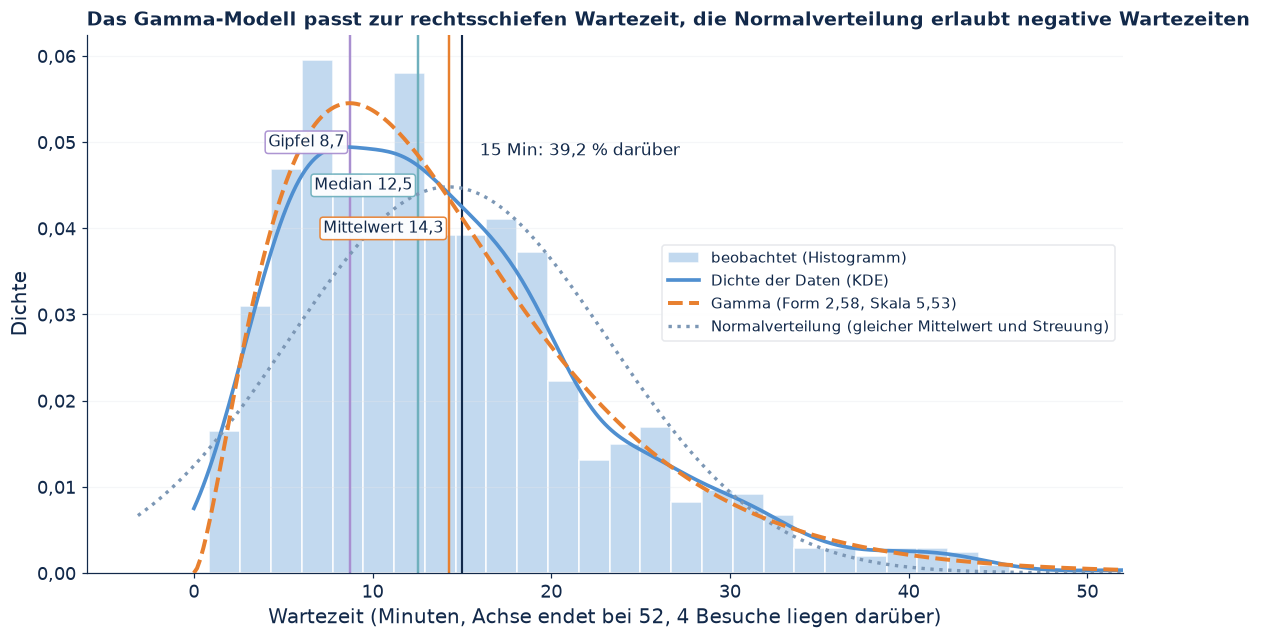

In [76]:
# Zusatz 11c: Gamma-Modell für die Wartezeit mit den Besuchsdaten, Vergleich mit der Normalverteilung, Perzentile als überprüfbare Zusage
def zusatz11_gamma():
    w = df.wait_time_min.dropna(); n = len(w)
    a, loc, sc = stats.gamma.fit(w, floc=0); gam = stats.gamma(a, scale=sc); nor = stats.norm(w.mean(), w.std(ddof=1))
    mod = max(0, (a - 1) * sc)
    print(f"Wartezeit (n = {n}): Mittelwert {w.mean():.2f}, Median {w.median():.2f}, Standardabweichung {w.std(ddof=1):.2f}, Schiefe {stats.skew(w):+.2f}")
    print(f"Gamma-Anpassung (Ort 0): Form {a:.2f}, Skala {sc:.2f} Min | Mittelwert {gam.mean():.2f}, Median {gam.median():.2f}, Modalwert {mod:.2f}")
    print(f"Anteil über 15 Min: beobachtet {(w > 15).mean() * 100:.1f} %, Gamma {gam.sf(15) * 100:.1f} %, Normal {nor.sf(15) * 100:.1f} %")
    print(f"Anteil unter 0 Min (unmöglich): Gamma 0,0 %, Normal {nor.cdf(0) * 100:.1f} %")
    ks_ = stats.kstest(w, gam.cdf); print(f"Kolmogorov-Smirnov gegen die angepasste Gamma: D = {ks_.statistic:.3f} (nur zur Orientierung, die Parameter stammen aus denselben Daten)")
    qs = [.5, .8, .9, .95]
    print(pd.DataFrame({"Perzentil": [f"{int(q * 100)} %" for q in qs], "beobachtet": [w.quantile(q) for q in qs], "Gamma": [gam.ppf(q) for q in qs], "Normal": [nor.ppf(q) for q in qs]}).round(1).to_string(index=False))
    for st in SITE_ORDER:
        ws = df.loc[df.clinic_site == st, "wait_time_min"].dropna()
        print(f"   {st}: Mittel {ws.mean():.1f}, 90-%-Perzentil {ws.quantile(.9):.1f} Min, Anteil über 15 Min {(ws > 15).mean() * 100:.1f} %")

    fig, ax = plt.subplots(figsize=(10.5, 6))
    ax.hist(w, bins=40, density=True, color=PASTEL["blau"], edgecolor="white", alpha=.9, label="beobachtet (Histogramm)", zorder=1)
    x = np.linspace(0, w.max() * 1.02, 400); xl = np.linspace(w.min() - 4, w.max() * 1.02, 400)
    kde = stats.gaussian_kde(w); ax.plot(x, kde(x), color=LINE["blau"], lw=2.4, label="Dichte der Daten (KDE)", zorder=3)
    ax.plot(x, gam.pdf(x), color=LINE["rosa"], lw=2.6, ls="--", label=f"Gamma (Form {a:.2f}, Skala {sc:.2f})", zorder=4)
    ax.plot(xl, nor.pdf(xl), color=LINE["gruen"], lw=2.2, ls=":", label="Normalverteilung (gleicher Mittelwert und Streuung)", zorder=3)
    ax.axvline(15, color=INK, lw=1.4, zorder=2); ax.text(16.0, ax.get_ylim()[1] * .80, f"15 Min: {(w > 15).mean() * 100:.1f} % darüber", fontsize=11, color=INK, va="top")
    for nm, v, c, yy in (("Gipfel", mod, "lila", .80), ("Median", w.median(), "pfirsich", .72), ("Mittelwert", w.mean(), "rosa", .64)):
        ax.axvline(v, color=LINE[c], lw=1.6, zorder=2)
        ax.text(v - .3, ax.get_ylim()[1] * yy, f"{nm} {v:.1f}", fontsize=10.5, color=INK, ha="right", va="center", bbox=dict(boxstyle="round,pad=.2", fc="white", ec=LINE[c], alpha=.95), zorder=6)
    ax.set_xlim(-6, 52)
    ax.set_xlabel(f"Wartezeit (Minuten, Achse endet bei 52, {int((w > 52).sum())} Besuche liegen darüber)"); ax.set_ylabel("Dichte"); ax.legend(loc="center right", frameon=True, framealpha=.95, fontsize=10, bbox_to_anchor=(1, .52))
    ax.grid(axis="x", visible=False); ax.set_title("Das Gamma-Modell passt zur rechtsschiefen Wartezeit, die Normalverteilung erlaubt negative Wartezeiten", loc="left", fontsize=12.5)
    plt.tight_layout(); show()

zusatz11_gamma()


**Aussage:** Das angepasste Gamma-Modell (Form 2,58, Skala 5,53) trifft den Anteil über 15 Minuten fast genau (39,2 % beobachtet, 38,6 % Gamma), die Normalverteilung kommt auf 46,7 % und erlaubt 5,5 % negative Wartezeiten.

**Einordnung:**
- **Lage:** Gipfel 8,7 < Median 12,5 < Mittelwert 14,3 Minuten, wie bei einer rechtsschiefen Verteilung. Der Mittelwert wird von wenigen langen Wartezeiten nach oben gezogen.
- **Perzentile als überprüfbare Zusage:** 80 % der Besuche warten höchstens 20,0 Minuten, 90 % höchstens 26,2 und 95 % höchstens 31,1 Minuten (Gamma: 20,7, 26,2 und 31,3). Eine Aussage wie „90 % warten höchstens 26 Minuten“ lässt sich prüfen, eine Aussage über die mittlere Wartezeit sagt nichts über die langen Fälle.
- **Je Standort:** Das 90-%-Perzentil beträgt in Downtown 21,9, Eastview 23,1, Northgate 21,6 und Riverside 32,0 Minuten. Der Anteil über 15 Minuten ist in Riverside mit 72,7 % am höchsten (Downtown 27,9 %, wie in Checkpoint 2).
- **Grenzen:** Das Modell passt die gemeinsame Verteilung aller Standorte an, die wegen Riverside eine Mischung ist. Die Güte ist nur zur Orientierung beurteilt (Kolmogorov-Smirnov D = 0,020, die Parameter stammen aus denselben Daten). Die Wartezeiten der No-Shows bleiben wie in Checkpoint 1 beschrieben unverändert in den Daten. Die Werte Form 2,375, Skala 3,958, Mittelwert 9,4 gehören zu den Fallkonstanten und nicht zu diesen Daten.

### Zusatz 12: Vorhersage für neue Tage (Betriebsdaten, Modell aus Zusatz 7)

Bisher habe ich das Regressionsmodell **beschrieben** (Koeffizienten, R², Residuen). Hier frage ich, wie gut es **neue, noch nicht gesehene Tage vorhersagt**, und wie unsicher eine einzelne Vorhersage ist. Das ist die Frage, die für die Planung zählt: „Wie lange warten Patienten an einem Tag mit 45 geplanten Patienten und 9 Mitarbeitenden?“ Grundlage sind die 90 Kliniktage aus `solace_daily_ops.csv`. Der Zusatz ist beschreibend und ändert keine Aussage weiter oben.

**Teil 1: Kreuzvalidierung.** Ein Modell sieht auf den Daten, mit denen es geschätzt wurde, immer besser aus als auf neuen Daten. Deshalb schätze ich es auf vier Fünfteln der Tage und sage das übrige Fünftel vorher (5-fache Kreuzvalidierung, 50-mal mit zufälliger Aufteilung wiederholt). Verglichen werden fünf Modelle, darunter Modell 3 und dasselbe Modell mit drei reinen Zufallsspalten.

Wartezeit der 90 Kliniktage: Standardabweichung 3,48 Min | 50 × 5-fache Kreuzvalidierung (jeder Tag wird je Durchgang genau einmal vorhergesagt, ohne im Training zu sein)

                                    Modell  RMSE Training (Min)  RMSE ungesehene Tage (Min)  MAE ungesehene Tage (Min)
                            Nur Mittelwert                 3,46                        3,51                       2,81
                             Nur Patienten                 2,53                        2,60                       1,98
                   Personal und Wochenende                 2,93                        3,06                       2,48
Modell 3 (Patienten, Personal, Wochenende)                 2,00                        2,11                       1,68
               Modell 3 + 3 Zufallsspalten                 1,99                        2,17                       1,74

Modell 3: Fehler an neuen Tagen 2,11 Min gegenüber 2,00 Min im Training (Aufschlag 0,12 Min), Gegenüber dem reine

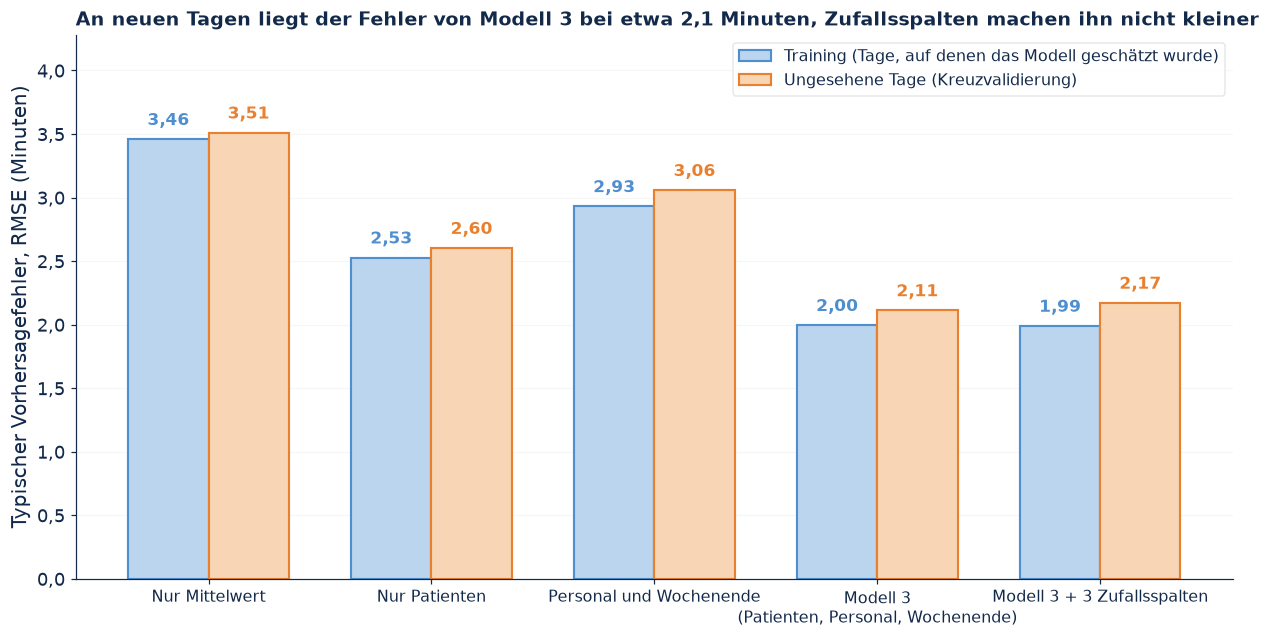

In [77]:
# Zusatz 12a: Vorhersage an neuen Tagen: Kreuzvalidierung der Betriebsdaten-Modelle (RMSE in Minuten)
def kv_rmse(spalten, wiederholungen=50, k=5, seed=SEED):
    """Wiederholte k-fache Kreuzvalidierung: Modell auf (k−1)/k der Tage schätzen, Rest vorhersagen. Gibt RMSE und MAE an den ungesehenen Tagen zurück."""
    y = ops_df.wait_time.values; X = np.column_stack([np.ones(len(y))] + [ops_df[s_].values.astype(float) for s_ in spalten]) if spalten else np.ones((len(y), 1))
    rng = np.random.default_rng(seed); fehler = []
    for _ in range(wiederholungen):
        teile = np.array_split(rng.permutation(len(y)), k)
        for te in teile:
            tr = np.setdiff1d(np.arange(len(y)), te); b_ = np.linalg.lstsq(X[tr], y[tr], rcond=None)[0]; fehler.append(y[te] - X[te] @ b_)
    f_ = np.concatenate(fehler); return np.sqrt(np.mean(f_ ** 2)), np.mean(np.abs(f_))

def zusatz12_kreuzvalidierung():
    y = ops_df.wait_time.values; n = len(y)
    ops_df["zufall_a"] = np.random.default_rng(55).normal(size=n); ops_df["zufall_b"] = np.random.default_rng(56).normal(size=n); ops_df["zufall_c"] = np.random.default_rng(57).normal(size=n)
    try:
        modelle = [("Nur Mittelwert", []), ("Nur Patienten", ["patients_scheduled"]), ("Personal und Wochenende", ["staff_on_duty", "is_weekend"]),
                   ("Modell 3\n(Patienten, Personal, Wochenende)", OPS_X), ("Modell 3 + 3 Zufallsspalten", OPS_X + ["zufall_a", "zufall_b", "zufall_c"])]
        zeilen = []
        for nm, sp in modelle:
            if sp: _, _, _, _, _, res, _ = ops_fit(sp); rmse_tr = np.sqrt(np.mean(res ** 2))
            else: rmse_tr = np.sqrt(np.mean((y - y.mean()) ** 2))
            rmse_cv, mae_cv = kv_rmse(sp); zeilen.append((nm, rmse_tr, rmse_cv, mae_cv))
    finally:
        ops_df.drop(columns=["zufall_a", "zufall_b", "zufall_c"], inplace=True, errors="ignore")
    print(f"Wartezeit der {n} Kliniktage: Standardabweichung {y.std(ddof=1):.2f} Min | 50 × 5-fache Kreuzvalidierung (jeder Tag wird je Durchgang genau einmal vorhergesagt, ohne im Training zu sein)\n")
    print(pd.DataFrame({"Modell": [z[0].replace("\n", " ") for z in zeilen], "RMSE Training (Min)": [z[1] for z in zeilen], "RMSE ungesehene Tage (Min)": [z[2] for z in zeilen], "MAE ungesehene Tage (Min)": [z[3] for z in zeilen]}).round(2).to_string(index=False))
    m3 = zeilen[3]; print(f"\nModell 3: Fehler an neuen Tagen {m3[2]:.2f} Min gegenüber {m3[1]:.2f} Min im Training (Aufschlag {m3[2] - m3[1]:.2f} Min). Gegenüber dem reinen Mittelwert ({zeilen[0][2]:.2f} Min) sinkt der Fehler um {(1 - m3[2] / zeilen[0][2]) * 100:.0f} %.".replace(".", ",").rstrip(",") + ".")
    print(f"Mit drei Zufallsspalten: Training {zeilen[4][1]:.2f} Min (besser), ungesehene Tage {zeilen[4][2]:.2f} Min (schlechter als Modell 3)".replace(".", ",") + ".")

    fig, ax = plt.subplots(figsize=(11.5, 6)); x = np.arange(len(zeilen)); w = .36
    ax.bar(x - w / 2, [z[1] for z in zeilen], w, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=1.4, label="Training (Tage, auf denen das Modell geschätzt wurde)", zorder=2)
    ax.bar(x + w / 2, [z[2] for z in zeilen], w, color=PASTEL["rosa"], edgecolor=LINE["rosa"], lw=1.4, label="Ungesehene Tage (Kreuzvalidierung)", zorder=2)
    for i_, z in enumerate(zeilen):
        ax.text(i_ - w / 2, z[1] + .08, f"{z[1]:.2f}", ha="center", va="bottom", fontsize=11, color=LINE["blau"], fontweight="bold")
        ax.text(i_ + w / 2, z[2] + .08, f"{z[2]:.2f}", ha="center", va="bottom", fontsize=11, color=LINE["rosa"], fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels([z[0] for z in zeilen], fontsize=10.5); ax.set_ylabel("Typischer Vorhersagefehler, RMSE (Minuten)"); ax.set_ylim(0, max(z[2] for z in zeilen) * 1.22)
    ax.legend(loc="upper right", frameon=True, framealpha=.95, fontsize=10.5); ax.grid(axis="x", visible=False)
    ax.set_title("An neuen Tagen liegt der Fehler von Modell 3 bei etwa 2,1 Minuten, Zufallsspalten machen ihn nicht kleiner", loc="left", fontsize=12.5)
    plt.tight_layout(); show()

zusatz12_kreuzvalidierung()


**Aussage:** An neuen Tagen liegt der typische Vorhersagefehler von Modell 3 bei 2,11 Minuten (RMSE), 0,12 Minuten über dem Trainingsfehler und 40 % unter dem Fehler der Vorhersage „immer der Mittelwert“ (3,51 Minuten). Drei Zufallsspalten verbessern die Vorhersage nicht.

**Einordnung:**
- **Training gegen neue Tage:** Ein Aufschlag von 0,12 Minuten ist klein. Das Modell ist nicht stark überangepasst, was bei 3 Merkmalen und 90 Tagen zu erwarten ist.
- **Zufallsspalten:** Mit ihnen sinkt der Trainingsfehler leicht (1,99), der Fehler an neuen Tagen steigt aber (2,17 statt 2,11). Das ist dieselbe Warnung wie bei Zusatz 10: Mehr Spalten sehen im Training immer besser aus, der Test an neuen Tagen deckt es auf.
- **Welche Spalte trägt:** Personal und Wochenende allein (3,06) schlagen den Mittelwert kaum, die Patientenzahl allein (2,60) ist der stärkste Einzelfaktor, erst alle drei zusammen erreichen 2,11. Das passt zu den Koeffizienten aus Zusatz 7.
- **RMSE und MAE:** Der RMSE gewichtet große Fehler stärker. Der mittlere absolute Fehler beträgt für Modell 3 1,68 Minuten (Tabelle).

**Teil 2: Vorhersageintervall.** Eine einzelne Vorhersage ist unsicherer als der Mittelwert, den das Modell schätzt, denn zum Schätzfehler kommt die Streuung eines einzelnen Tages dazu. Das **95-%-Vorhersageintervall** für einen neuen Tag mit den Merkmalen x₀ ist ŷ ± t(0,975; n−4) · s · √(1 + x₀′(X′X)⁻¹x₀). Ich zeige es für Werktage mit 20 bis 45 Patienten (der Bereich der Daten) und 7, 9 und 11 Mitarbeitenden, und prüfe das Intervall anschließend an den echten Tagen.

Typischer Werktag (35 Patienten, 9 Personal): Vorhersage 11,2 Min, 95-%-Vorhersageintervall [7,1; 15,3] (Breite 8,2 Min, Freiheitsgrade 86)
Zum Vergleich: Das Konfidenzintervall für die Koeffizienten sagt etwas über den Mittelwert, das Vorhersageintervall über einen einzelnen Tag und ist deshalb breiter.

 Personal  Patienten  Vorhersage (Min)  untere Grenze  obere Grenze  P(Wartezeit > 15 Min) in %
        7         30              11,2            7,1          15,4                         3,7
        7         38              15,2           10,9          19,5                        54,0
        7         45              18,7           14,2          23,3                        94,6
        9         30               8,7            4,5          12,8                         0,1
        9         38              12,7            8,5          16,8                        13,1
        9         45              16,2           11,9          20,4                        70,7
       11         30 

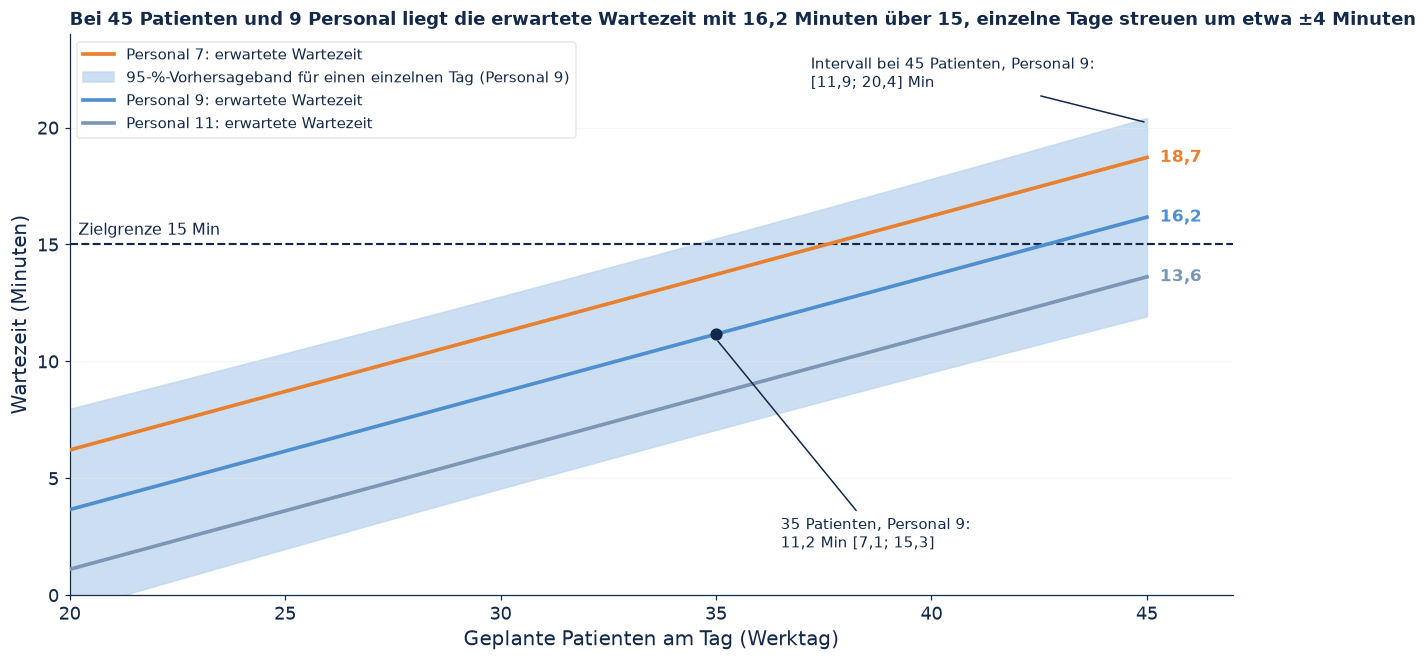

In [78]:
# Zusatz 12b: Vorhersageintervall für einen neuen Tag (Modell 3, Werktag)
from scipy import stats as _st
def pi_modell3(patienten, personal, wochenende=0, niveau=.95):
    """Punktvorhersage und Vorhersageintervall für einen neuen Tag: ŷ ± t·s·√(1 + x0'(X'X)⁻¹x0)."""
    X = np.column_stack([np.ones(len(ops_df))] + [ops_df[c].values.astype(float) for c in OPS_X]); y = ops_df.wait_time.values
    b_ = np.linalg.lstsq(X, y, rcond=None)[0]; res = y - X @ b_; dfr = len(y) - X.shape[1]; s_ = np.sqrt(res @ res / dfr); XtXi = np.linalg.inv(X.T @ X)
    x0 = np.array([1, patienten, personal, wochenende], float); yh = x0 @ b_; se = s_ * np.sqrt(1 + x0 @ XtXi @ x0); t_ = _st.t.ppf(1 - (1 - niveau) / 2, dfr)
    return yh, yh - t_ * se, yh + t_ * se, se, dfr

def zusatz12_vorhersageintervall():
    n = len(ops_df); yh, u, o, se, dfr = pi_modell3(35, 9)
    print(f"Typischer Werktag (35 Patienten, 9 Personal): Vorhersage {yh:.1f} Min, 95-%-Vorhersageintervall [{u:.1f}; {o:.1f}] (Breite {o - u:.1f} Min, Freiheitsgrade {dfr})".replace(".", ","))
    print("Zum Vergleich: Das Konfidenzintervall für die Koeffizienten sagt etwas über den Mittelwert, das Vorhersageintervall über einen einzelnen Tag und ist deshalb breiter.\n")
    zeilen = []
    for pers in (7, 9, 11):
        for pat in (30, 38, 45):
            a, l_, h_, se_, _ = pi_modell3(pat, pers); p15 = 1 - _st.t.cdf((15 - a) / se_, dfr); zeilen.append((pers, pat, a, l_, h_, p15 * 100))
    print(pd.DataFrame(zeilen, columns=["Personal", "Patienten", "Vorhersage (Min)", "untere Grenze", "obere Grenze", "P(Wartezeit > 15 Min) in %"]).to_string(index=False, float_format=lambda v: f"{v:.1f}").replace(".", ","))
    # Abdeckung: wie oft liegt ein ungesehener Tag im Intervall? (leave-one-out)
    y = ops_df.wait_time.values; X = np.column_stack([np.ones(n)] + [ops_df[c].values.astype(float) for c in OPS_X]); drin = 0
    for i_ in range(n):
        tr = np.delete(np.arange(n), i_); b_ = np.linalg.lstsq(X[tr], y[tr], rcond=None)[0]; r_ = y[tr] - X[tr] @ b_; d_ = len(tr) - X.shape[1]; s_ = np.sqrt(r_ @ r_ / d_)
        se_ = s_ * np.sqrt(1 + X[i_] @ np.linalg.inv(X[tr].T @ X[tr]) @ X[i_]); drin += abs(y[i_] - X[i_] @ b_) <= _st.t.ppf(.975, d_) * se_
    print(f"\nPrüfung an echten Daten (jeden Tag einmal weglassen, vorhersagen): {drin} von {n} Tagen = {drin / n * 100:.1f} % liegen im 95-%-Intervall (Sollwert 95 %)".replace(".", ",") + ".")

    gitter = np.arange(20, 46); fig, ax = plt.subplots(figsize=(11.5, 6.2))
    farben = {7: ("rosa", "Personal 7"), 9: ("blau", "Personal 9"), 11: ("gruen", "Personal 11")}
    for pers, (fk, lab) in farben.items():
        fk_ = fk if fk in PASTEL else list(PASTEL)[1]
        v = np.array([pi_modell3(g, pers) for g in gitter], dtype=float)
        if pers == 9: ax.fill_between(gitter, v[:, 1], v[:, 2], color=PASTEL[fk_], alpha=.75, zorder=1, label="95-%-Vorhersageband für einen einzelnen Tag (Personal 9)")
        ax.plot(gitter, v[:, 0], color=LINE[fk_], lw=2.4, zorder=3, label=f"{lab}: erwartete Wartezeit")
        ax.text(45.3, v[-1, 0], f"{v[-1, 0]:.1f}".replace(".", ","), color=LINE[fk_], fontsize=11, fontweight="bold", va="center")
    ax.axhline(15, color=INK, ls="--", lw=1.4, zorder=2); ax.text(20.2, 15.25, "Zielgrenze 15 Min", fontsize=10.5, color=INK, va="bottom")
    v9 = np.array(pi_modell3(45, 9), dtype=float); v35 = pi_modell3(35, 9)
    ax.annotate(f"Intervall bei 45 Patienten, Personal 9:\n[{v9[1]:.1f}; {v9[2]:.1f}] Min".replace(".", ","), xy=(45, v9[2] - .2), xytext=(37.2, 22.3), fontsize=10, color=INK, va="center", ha="left", arrowprops=dict(arrowstyle="-", color=INK, lw=1))
    ax.plot([35], [v35[0]], "o", color=INK, ms=7, zorder=4)
    ax.annotate(f"35 Patienten, Personal 9:\n{v35[0]:.1f} Min [{v35[1]:.1f}; {v35[2]:.1f}]".replace(".", ","), xy=(35, v35[0] - .2), xytext=(36.5, 2.6), fontsize=10, color=INK, va="center", ha="left", arrowprops=dict(arrowstyle="-", color=INK, lw=1))
    ax.set_xlim(20, 47); ax.set_xlabel("Geplante Patienten am Tag (Werktag)"); ax.set_ylabel("Wartezeit (Minuten)"); ax.set_ylim(0, 24)
    ax.legend(loc="upper left", fontsize=10, frameon=True, framealpha=.95, bbox_to_anchor=(0, 1)); ax.grid(axis="x", visible=False)
    ax.set_title("Bei 45 Patienten und 9 Personal liegt die erwartete Wartezeit mit 16,2 Minuten über 15, einzelne Tage streuen um etwa ±4 Minuten", loc="left", fontsize=12)
    plt.tight_layout(); show()

zusatz12_vorhersageintervall()


**Aussage:** Bei 45 Patienten und 9 Mitarbeitenden erwartet das Modell 16,2 Minuten Wartezeit [11,9; 20,4]. Das liegt im Mittel über der 15-Minuten-Grenze, einzelne Tage streuen aber um etwa ±4 Minuten.

**Einordnung:**
- **Breite:** Für einen typischen Werktag (35 Patienten, 9 Personal) ergibt das Modell 11,2 Minuten [7,1; 15,3]. Das Intervall ist 8,2 Minuten breit, weil die Tagesstreuung (s ≈ 2,04 Minuten) dominiert und nicht der Schätzfehler der Koeffizienten.
- **Risiko über 15 Minuten:** Eine Vorhersage nahe 15 Minuten heißt nicht „genau an der Grenze“, sondern ein Risiko von etwa 50 %. Bei 9 Personal und 38 Patienten sind es 13 %, bei 45 Patienten 71 %. Mit 11 Personal sinkt das Risiko bei 45 Patienten auf 25 %, mit 7 steigt es auf 95 %.
- **Prüfung an echten Daten:** Lässt man jeden der 90 Tage einmal weg und sagt ihn mit dem Modell der übrigen 89 vorher, liegen 85 Tage (94,4 %) im 95-%-Intervall. Die Intervalle sind also etwa so zuverlässig wie angegeben.
- **Grenzen:** Das Intervall gilt nur im Datenbereich (20 bis 45 Patienten, 5 bis 11 Personal) und setzt annähernd normalverteilte Restfehler mit gleicher Streuung voraus. Der Breusch-Pagan-Test spricht nicht gegen gleiche Streuung (p = 0,78), der Shapiro-Test deutet leichte Abweichungen von der Normalverteilung an (p = 0,013). Die Zusammenhänge sind beobachtet, nicht experimentell belegt: Dass mehr Personal die Wartezeit senkt, ist plausibel, aber aus diesen Daten nicht kausal bewiesen. 90 Tage sind eine kleine Grundlage.

### Zusatz 13: Logistische Regression für No-Show (Besuchsdaten)

Die Regression in Zusatz 7 und 10 erklärt eine Zahl (die Wartezeit). No-Show ist dagegen eine Ja/Nein-Größe, dafür gehört die **logistische Regression**. Sie beantwortet eine Frage, die der Chi-Quadrat-Test aus Abschnitt 1.7 und Zusatz 11 offen lässt: Gilt der Zusammenhang zwischen Terminart und No-Show auch, wenn man **Standort, Versicherung und Wochenende gleichzeitig berücksichtigt**? Grundlage sind alle 1.200 Termine (129 No-Shows). Der Zusatz ist beschreibend und ändert keine Aussage weiter oben.

**Modell:** No-Show ~ Terminart + Standort + Versicherung + Wochenende (Basisgruppen: Checkup, Downtown, Private, Werktag). Die Wartezeit nehme ich bewusst **nicht** auf: Sie entsteht erst beim Besuch und stünde als Merkmal zum Zeitpunkt der Terminvergabe nicht zur Verfügung. Mit 10 Merkmalen und 129 No-Shows kommen auf jedes Merkmal etwa 13 Ereignisse, das reicht für eine Faustregel von mindestens 10. Die Schätzung läuft mit einer eigenen Newton-Routine (nur numpy), damit das Notebook ohne weitere Pakete läuft.

Ein **Odds Ratio** (OR) vergleicht die Chancen (Odds = p / (1 − p)) zweier Gruppen: OR = 1 bedeutet kein Unterschied, OR = 2 doppelte Chancen auf einen No-Show. Odds Ratios sind keine Risikoverhältnisse, sie liegen bei kleinen Anteilen aber nah beieinander.

Logistische Regression: no_show ~ Terminart + Standort + Versicherung + Wochenende | n = 1200, No-Shows = 129 (10,75 %), Merkmale = 10, No-Shows je Merkmal = 12,9

                                        Odds Ratio  untere Grenze  obere Grenze  p-Wert
Terminart: Follow-up (gegen Checkup)         1,115          0,698          1,78    0,65
Terminart: Specialist (gegen Checkup)        0,753          0,357         1,588   0,456
Terminart: Urgent (gegen Checkup)            2,055          1,296         3,259   0,002
Standort: Eastview (gegen Downtown)          1,127          0,684         1,857   0,638
Standort: Northgate (gegen Downtown)         0,755           0,45         1,268   0,289
Standort: Riverside (gegen Downtown)         0,777          0,472         1,279   0,322
Versicherung: Medicaid (gegen Private)        1,46          0,855         2,493   0,166
Versicherung: Medicare (gegen Private)       1,441          0,902         2,303   0,127
Versicherung: Self-pay (gegen Private)      

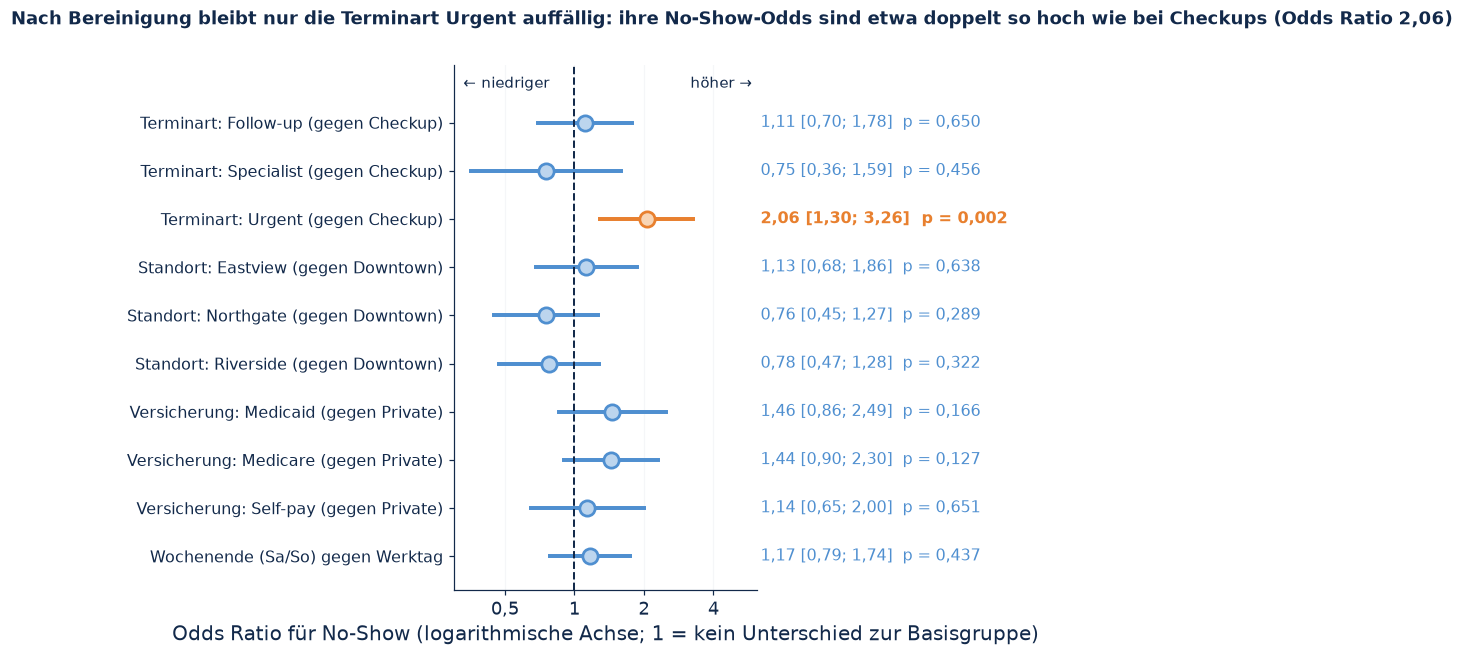

In [79]:
# Zusatz 13a: Logistische Regression für No-Show (Odds Ratios, bereinigt um die anderen Merkmale)
from scipy import stats as _st

def logit_fit(X, y, iters=50):
    """Logistische Regression per IRLS (Newton-Verfahren), nur mit numpy. Gibt Koeffizienten, Kovarianzmatrix und Log-Likelihood zurück."""
    b = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ b)); W = p * (1 - p); H = X.T @ (X * W[:, None]); neu = b + np.linalg.solve(H, X.T @ (y - p))
        if np.max(np.abs(neu - b)) < 1e-10: b = neu; break
        b = neu
    p = 1 / (1 + np.exp(-X @ b)); ll = np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)); H = X.T @ (X * (p * (1 - p))[:, None])
    return b, np.linalg.inv(H), ll

def auc_rang(y, score):
    """AUC über Rangsumme (Mann-Whitney): Wahrscheinlichkeit, dass ein No-Show einen höheren Score hat als ein Termin ohne No-Show."""
    r = _st.rankdata(score); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def design13(d):
    """Designmatrix: Terminart (Basis Checkup), Standort (Basis Downtown), Versicherung (Basis Private), Wochenende (Basis Werktag)."""
    spalten = {}
    for kol, basis in [("appointment_type", "Checkup"), ("clinic_site", "Downtown"), ("insurance_type", "Private")]:
        for lev in sorted(d[kol].unique()):
            if lev != basis: spalten[f"{kol.split('_')[0].replace('appointment', 'Terminart').replace('clinic', 'Standort').replace('insurance', 'Versicherung')}: {lev} (gegen {basis})"] = (d[kol] == lev).astype(float).values
    spalten["Wochenende (Sa/So) gegen Werktag"] = d.day_of_week.isin(["Saturday", "Sunday"]).astype(float).values
    return spalten

def zusatz13_logit():
    y = df.no_show.values.astype(float); sp = design13(df); namen = list(sp); X = np.column_stack([np.ones(len(y))] + [sp[k] for k in namen])
    b, V, ll = logit_fit(X, y); se = np.sqrt(np.diag(V)); z = b / se; p = 2 * (1 - _st.norm.cdf(np.abs(z)))
    _, _, ll0 = logit_fit(np.ones((len(y), 1)), y); lr = 2 * (ll - ll0); k = X.shape[1] - 1; p_lr = 1 - _st.chi2.cdf(lr, k)
    tab = pd.DataFrame({"Odds Ratio": np.exp(b[1:]), "untere Grenze": np.exp(b[1:] - 1.96 * se[1:]), "obere Grenze": np.exp(b[1:] + 1.96 * se[1:]), "p-Wert": p[1:]}, index=namen)
    print(f"Logistische Regression: no_show ~ Terminart + Standort + Versicherung + Wochenende | n = {len(y)}, No-Shows = {int(y.sum())} ({y.mean() * 100:.2f} %), Merkmale = {k}, No-Shows je Merkmal = {y.sum() / k:.1f}\n".replace(".", ","))
    print(tab.round(3).to_string().replace(".", ","))
    pred = 1 / (1 + np.exp(-X @ b)); mcf = 1 - ll / ll0; auc = auc_rang(y, pred)
    print(f"\nGesamttest (Likelihood-Quotient): Chi² = {lr:.2f}, Freiheitsgrade = {k}, p = {p_lr:.3f} | McFadden-Pseudo-R² = {mcf:.3f} | AUC im Training = {auc:.3f}".replace(".", ","))
    # AUC an ungesehenen Terminen: 5-fache Kreuzvalidierung, 20 Wiederholungen
    rng = np.random.default_rng(SEED); aucs = []
    for _ in range(20):
        sc = np.zeros(len(y))
        for te in np.array_split(rng.permutation(len(y)), 5):
            tr = np.setdiff1d(np.arange(len(y)), te); bb, _, _ = logit_fit(X[tr], y[tr]); sc[te] = X[te] @ bb
        aucs.append(auc_rang(y, sc))
    print(f"AUC an ungesehenen Terminen (5-fache Kreuzvalidierung, 20 Wiederholungen): {np.mean(aucs):.3f} (0,5 = reiner Zufall, 1,0 = perfekt)".replace(".", ","))
    roh = df.groupby("appointment_type").no_show.mean()
    print("\nRoh gegen bereinigt je Terminart (Urgent gegen Checkup): ", f"rohes Odds Ratio = {(roh['Urgent'] / (1 - roh['Urgent'])) / (roh['Checkup'] / (1 - roh['Checkup'])):.2f}, bereinigtes Odds Ratio = {tab.iloc[list(tab.index).index('Terminart: Urgent (gegen Checkup)'), 0]:.2f}".replace(".", ","))

    # Waldplot
    fig, ax = plt.subplots(figsize=(11.5, 6.2)); yy = np.arange(len(tab))[::-1]
    for i_, (nm, r_) in enumerate(tab.iterrows()):
        sig = r_["p-Wert"] < .05; col = LINE["rosa"] if sig else LINE["blau"]
        ax.plot([r_["untere Grenze"], r_["obere Grenze"]], [yy[i_]] * 2, color=col, lw=2.6, zorder=2)
        ax.plot(r_["Odds Ratio"], yy[i_], "o", color=PASTEL["rosa"] if sig else PASTEL["blau"], mec=col, mew=1.8, ms=10, zorder=3)
        ax.text(6.4, yy[i_], f"{r_['Odds Ratio']:.2f} [{r_['untere Grenze']:.2f}; {r_['obere Grenze']:.2f}]  p = {r_['p-Wert']:.3f}".replace(".", ","), va="center", ha="left", fontsize=10.5, color=col, fontweight="bold" if sig else "normal")
    ax.axvline(1, color=INK, ls="--", lw=1.3); ax.set_xscale("log"); ax.xaxis.set_minor_locator(plt.NullLocator()); ax.set_xlim(.3, 6.2); ax.set_xticks([.5, 1, 2, 4]); ax.set_xticklabels(["0,5", "1", "2", "4"])
    ax.set_yticks(yy); ax.set_yticklabels(list(tab.index), fontsize=10.5); ax.set_xlabel("Odds Ratio für No-Show (logarithmische Achse; 1 = kein Unterschied zur Basisgruppe)"); ax.grid(axis="y", visible=False)
    ax.text(5.9, len(tab) - .35, "höher →", fontsize=10, color=INK, va="bottom", ha="right"); ax.text(.33, len(tab) - .35, "← niedriger", fontsize=10, color=INK, va="bottom", ha="left")
    ax.set_ylim(-.7, len(tab) + .2); fig.subplots_adjust(left=.36, right=.60, top=.9, bottom=.13)
    fig.suptitle("Nach Bereinigung bleibt nur die Terminart Urgent auffällig: ihre No-Show-Odds sind etwa doppelt so hoch wie bei Checkups (Odds Ratio 2,06)".replace(".", ","), x=.01, ha="left", fontsize=12, fontweight="bold")
    show()
    return tab

tab13 = zusatz13_logit()


**Aussage:** Nach Bereinigung bleibt nur die Terminart Urgent auffällig: Ihre No-Show-Odds sind mit OR = 2,06 [1,30; 3,26] etwa doppelt so hoch wie bei Checkups (p = 0,002). Alle anderen Merkmale haben Konfidenzintervalle, die die 1 einschließen.

**Einordnung:**
- **Roh gegen bereinigt:** Das rohe Odds Ratio für Urgent gegen Checkup beträgt 2,05, das bereinigte 2,06. Der Befund aus Zusatz 11 stammt also nicht daher, dass Urgent-Termine zufällig an anderen Standorten oder bei anderen Versicherungen häufiger wären.
- **Mehrfachprüfung:** Bei 10 Koeffizienten kommt eine Auffälligkeit auch zufällig vor. Mit Bonferroni-Korrektur (p · 10 = 0,02) bleibt Urgent signifikant, die übrigen Merkmale mit p ≥ 0,127 nicht.
- **Versicherung:** Medicaid (OR 1,46) und Medicare (OR 1,44) liegen über Private, die Intervalle [0,86; 2,49] und [0,90; 2,30] schließen die 1 aber ein. Das ist ein Hinweis, kein Nachweis.
- **Standort:** Kein Standort unterscheidet sich im No-Show-Risiko von Downtown (alle p ≥ 0,289). Der Unterschied der Wartezeiten zwischen Riverside und Downtown aus Checkpoint 3 hat damit keine Entsprechung bei den No-Shows.

**Wie gut sagt das Modell No-Shows vorher?** Ein signifikanter Koeffizient heißt noch nicht, dass man damit einzelne Termine gut vorhersagen kann. Dafür prüfe ich die **Trennschärfe (AUC)**: die Wahrscheinlichkeit, dass ein zufällig gewählter No-Show einen höheren Modellwert hat als ein zufällig gewählter Termin ohne No-Show (0,5 = reiner Zufall, 1,0 = perfekt). Anschließend teile ich die Termine nach dem vorhergesagten Risiko in drei gleich große Gruppen. Die Vorhersagen stammen aus einer 5-fachen Kreuzvalidierung, jeder Termin wird also von einem Modell vorhergesagt, das ihn nicht gesehen hat.

                           Gruppe  No-Shows  Termine  Beobachtet %  untere Grenze  obere Grenze  vorhergesagt %
Niedriges Risiko (untere Drittel)        45      399          11,3            8,5          14,8             6,6
                 Mittleres Risiko        30      400           7,5            5,3          10,5             9,9
    Hohes Risiko (oberes Drittel)        54      401          13,5           10,5          17,2            15,7

Gesamt: 129 von 1200 = 10,8 %, Das obere Drittel hat 13,5 %, das untere 11,3 %: Die Gruppen unterscheiden sich um 2,2 Prozentpunkte, die mittlere Gruppe liegt mit 7,5 % sogar unter der niedrigen (die Reihenfolge stimmt nicht).


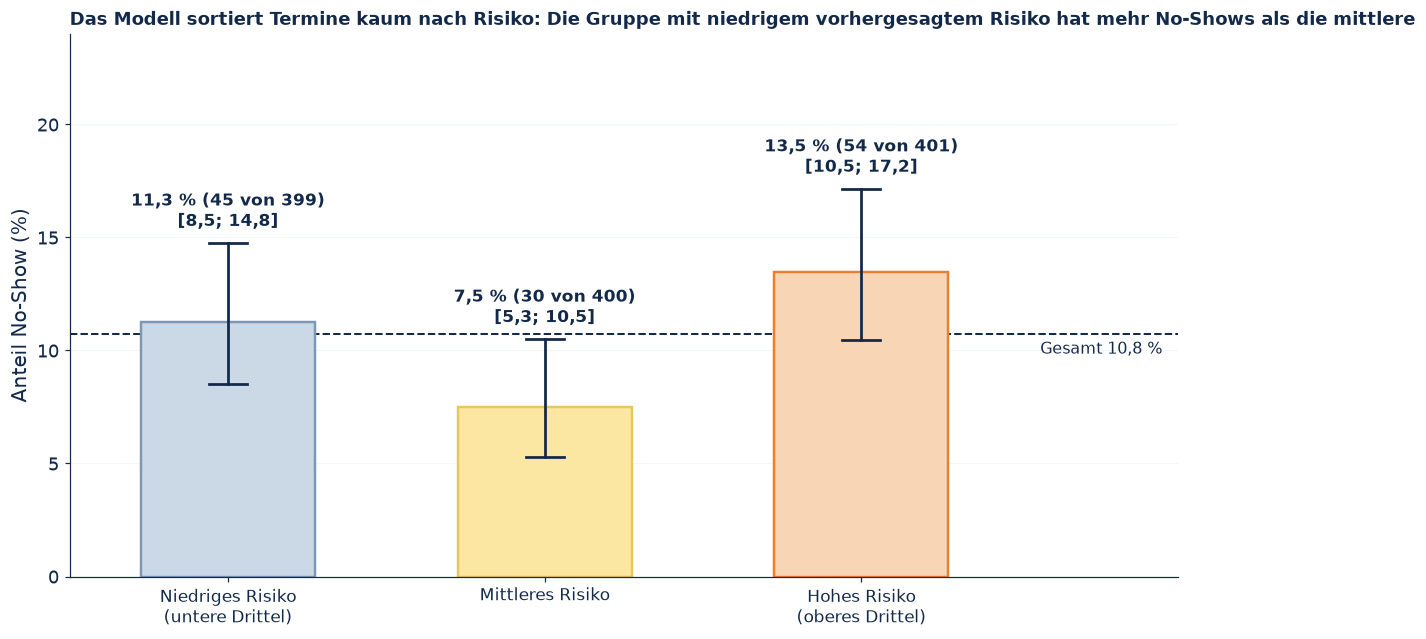

In [80]:
# Zusatz 13b: Wie gut trennt das Modell? No-Show-Anteil nach vorhergesagter Risikogruppe (Vorhersagen aus der Kreuzvalidierung)
def wilson(k, n, z=1.96):
    p = k / n; m = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n); return m - h, m + h

def zusatz13_risikogruppen():
    y = df.no_show.values.astype(float); sp = design13(df); X = np.column_stack([np.ones(len(y))] + [sp[k] for k in sp]); sc = np.zeros(len(y)); rng = np.random.default_rng(SEED)
    for te in np.array_split(rng.permutation(len(y)), 5):
        tr = np.setdiff1d(np.arange(len(y)), te); bb, _, _ = logit_fit(X[tr], y[tr]); sc[te] = 1 / (1 + np.exp(-X[te] @ bb))
    grenzen = np.quantile(sc, [1 / 3, 2 / 3]); grp = np.digitize(sc, grenzen); namen = ["Niedriges Risiko\n(untere Drittel)", "Mittleres Risiko", "Hohes Risiko\n(oberes Drittel)"]
    zeilen = []
    for g in range(3):
        m = grp == g; k = int(y[m].sum()); n = int(m.sum()); lo, hi = wilson(k, n); zeilen.append((namen[g], k, n, k / n * 100, lo * 100, hi * 100, sc[m].mean() * 100))
    print(pd.DataFrame(zeilen, columns=["Gruppe", "No-Shows", "Termine", "Beobachtet %", "untere Grenze", "obere Grenze", "vorhergesagt %"]).assign(Gruppe=lambda d: d.Gruppe.str.replace("\n", " ")).round(1).to_string(index=False, float_format=lambda v: f"{v:.1f}").replace(".", ","))
    print(f"\nGesamt: {int(y.sum())} von {len(y)} = {y.mean() * 100:.1f} %. Das obere Drittel hat {zeilen[2][3]:.1f} %, das untere {zeilen[0][3]:.1f} %: Die Gruppen unterscheiden sich um {zeilen[2][3] - zeilen[0][3]:.1f} Prozentpunkte, die mittlere Gruppe liegt mit {zeilen[1][3]:.1f} % sogar unter der niedrigen (die Reihenfolge stimmt nicht)".replace(".", ",") + ".")
    fig, ax = plt.subplots(figsize=(11, 6)); cols = [("gruen", "gruen"), ("gelb", "gelb"), ("rosa", "rosa")]
    for i_, z in enumerate(zeilen):
        ax.bar(i_, z[3], .55, color=PASTEL[cols[i_][0]], edgecolor=LINE[cols[i_][1]], lw=1.6, zorder=2)
        ax.plot([i_, i_], [z[4], z[5]], color=INK, lw=1.8, zorder=3); ax.plot([i_ - .06, i_ + .06], [z[4]] * 2, color=INK, lw=1.8); ax.plot([i_ - .06, i_ + .06], [z[5]] * 2, color=INK, lw=1.8)
        ax.text(i_, z[5] + .5, f"{z[3]:.1f} % ({z[1]} von {z[2]})\n[{z[4]:.1f}; {z[5]:.1f}]".replace(".", ","), ha="center", va="bottom", fontsize=11, color=INK, fontweight="bold")
    ax.axhline(y.mean() * 100, color=INK, ls="--", lw=1.3, zorder=1); ax.text(2.95, y.mean() * 100 - .35, f"Gesamt {y.mean() * 100:.1f} %".replace(".", ","), ha="right", va="top", fontsize=10.5, color=INK)
    ax.set_xticks(range(3)); ax.set_xticklabels([z[0] for z in zeilen], fontsize=11); ax.set_ylabel("Anteil No-Show (%)"); ax.set_xlim(-.5, 3.0); ax.set_ylim(0, 24); ax.grid(axis="x", visible=False)
    ax.set_title("Das Modell sortiert Termine kaum nach Risiko: Die Gruppe mit niedrigem vorhergesagtem Risiko hat mehr No-Shows als die mittlere", loc="left", fontsize=12)
    plt.tight_layout(); show()

zusatz13_risikogruppen()


**Aussage:** Das Modell erklärt zwar einen echten Zusammenhang (Gesamttest p = 0,042), sortiert einzelne Termine aber kaum nach Risiko: Die Gruppe mit niedrigem vorhergesagtem Risiko hat mit 11,3 % mehr No-Shows als die mittlere (7,5 %), die Gruppe mit hohem Risiko 13,5 %.

**Einordnung:**
- **Kennzahlen:** McFadden-Pseudo-R² = 0,023, AUC im Training 0,611, an ungesehenen Terminen nur 0,543. Das liegt kaum über dem Zufallswert 0,5. Die Differenz zwischen Training und Kreuzvalidierung zeigt wie in Zusatz 12, dass die Anpassung auf den eigenen Daten besser aussieht als sie auf neuen ist.
- **Folgerung:** Die Terminart Urgent ist ein plausibler Ansatzpunkt für Erinnerungen (Urgent-Termine fallen häufiger aus), aber mit diesen Merkmalen lässt sich nicht für einzelne Termine vorhersagen, wer nicht erscheint. Für eine Vorhersage fehlen Merkmale wie Vorlaufzeit, frühere No-Shows oder Entfernung.
- **Zusammenhang mit dem SMS-Plan (Checkpoint 4):** Das stützt die Aussage, dass der Plan nur mit zufälliger Zuteilung beurteilt werden kann. Die vorhandenen Merkmale erklären den No-Show kaum, ein Unterschied zwischen den Gruppen lässt sich also nicht einfach „herausrechnen“.
- **Grenzen:** Die Daten sind beobachtet, die Koeffizienten beschreiben Zusammenhänge und keine Ursachen. Die Wald-Intervalle sind Näherungen für 129 Ereignisse. Geprüft wurden nur die vier genannten Merkmale.

### Zusatz 14: Signifikanz und praktische Bedeutung

Dieser Zusatz trennt drei Fragen, die oft vermischt werden: **Ist ein Unterschied unter der Nullhypothese überraschend (p-Wert)? Wie groß ist er und wie sicher (Konfidenzintervall)? Ist er für die Praxis relevant (fachliche Schwelle)?** Ich rechne das mit den Projektdaten und ergänze, was im Notebook bisher fehlte: eine Simulation, was ein p-Wert eigentlich ist (14a), wie sich Intervall und p-Wert mit der Stichprobengröße ändern (14b), Koeffizienten in Minuten je Standardabweichung (14c) und die Fehlalarmrate bei vielen Tests (14d). Die Rechenwege selbst (t-Test, F-Test, Bonferroni, Intervalle) stehen schon in den Checkpoints und in Zusatz 7, 8 und 10.

**Teil 1 (14a): Was ein p-Wert ist.** Die Nullhypothese H₀ lautet: Der Standort hat keinen Einfluss auf die Wartezeit. Unter H₀ sind die Standort-Etiketten austauschbar. Ich ordne die 716 Wartezeiten (286 Riverside, 430 Downtown) 20.000-mal zufällig den beiden Standorten zu und berechne jedes Mal die Differenz der Mittelwerte. Das ergibt die Verteilung der Differenz unter H₀. Der p-Wert ist der Anteil der Differenzen, die mindestens so extrem sind wie die beobachtete.

Beobachtete Differenz Riverside − Downtown: 8,58 Minuten (n = 286 und 430)
H₀-Verteilung aus 20 000 Umordnungen: Mittelwert 0,00, Standardabweichung 0,71, 95-%-Bereich [−1,37; 1,42], Spannweite [−2,64; 3,32] Minuten
Mindestens so extreme Differenzen (Betrag): 0 von 20 000 -> p < 0,00005 (die Simulation kann keinen kleineren p-Wert als 1/20 000 ausweisen)
Welch-Test dazu: t = 13,56, p = 1,0e-36. Der beobachtete Wert liegt 12,1 Standardabweichungen vom H₀-Zentrum entfernt.


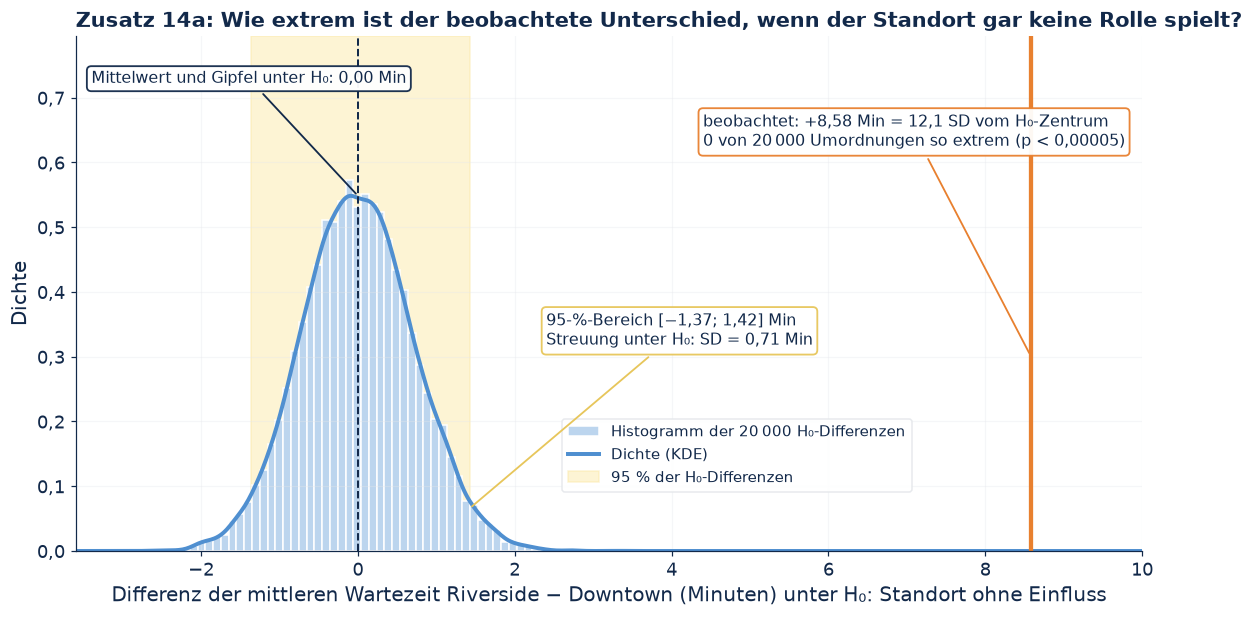

In [81]:
# Zusatz 14a: Was ein p-Wert ist, Permutationstest für den Standortunterschied
def tsd(n):
    """Tausendertrennung mit schmalem Leerzeichen (der Punkt würde in den Beschriftungen zum Dezimalkomma)."""
    return f"{n:,}".replace(",", " ")

def zusatz14_permutation(reps=20000):
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−")
    a = df[df.clinic_site == "Riverside"].wait_time_min.values; b = df[df.clinic_site == "Downtown"].wait_time_min.values
    obs = a.mean() - b.mean(); alle = np.concatenate([a, b]); n = len(a); rg = np.random.default_rng(SEED); diffs = np.empty(reps)
    for i in range(reps):                                   # H₀: Standort ist egal, die Wartezeiten werden den Standorten zufällig neu zugeordnet
        pm = rg.permutation(alle); diffs[i] = pm[:n].mean() - pm[n:].mean()
    extrem = int((np.abs(diffs) >= abs(obs)).sum()); welch = stats.ttest_ind(a, b, equal_var=False)
    lo95, hi95 = np.percentile(diffs, [2.5, 97.5]); sd0 = diffs.std(ddof=1)
    print(f"Beobachtete Differenz Riverside − Downtown: {obs:.2f} Minuten (n = {len(a)} und {len(b)})")
    print(f"H₀-Verteilung aus {tsd(reps)} Umordnungen: Mittelwert {diffs.mean():.2f}, Standardabweichung {sd0:.2f}, 95-%-Bereich [{mn(lo95)}; {mn(hi95)}], Spannweite [{mn(diffs.min())}; {mn(diffs.max())}] Minuten")
    print(f"Mindestens so extreme Differenzen (Betrag): {extrem} von {tsd(reps)} -> p < {1 / reps:.5f} (die Simulation kann keinen kleineren p-Wert als 1/{tsd(reps)} ausweisen)")
    print(f"Welch-Test dazu: t = {welch.statistic:.2f}, p = {welch.pvalue:.1e}. Der beobachtete Wert liegt {obs / sd0:.1f} Standardabweichungen vom H₀-Zentrum entfernt.")
    fig, ax = plt.subplots(figsize=(11, 5.8))
    ax.hist(diffs, bins=60, density=True, color=PASTEL["blau"], edgecolor="white", label=f"Histogramm der {tsd(reps)} H₀-Differenzen")
    xs = np.linspace(-3.6, 10, 600); kde = stats.gaussian_kde(diffs)(xs); ax.plot(xs, kde, color=LINE["blau"], label="Dichte (KDE)")
    ax.axvspan(lo95, hi95, color=PASTEL["gelb"], alpha=.45, zorder=0, label="95 % der H₀-Differenzen")
    ax.axvline(0, color=INK, ls="--", lw=1.3); ax.axvline(obs, color=LINE["rosa"], lw=2.8)
    ymax = kde.max(); ax.set_ylim(0, ymax * 1.45); ax.set_xlim(-3.6, 10)
    tagd(ax, (0, ymax * 1.0), (-3.4, ymax * 1.33), f"Mittelwert und Gipfel unter H₀: {diffs.mean():.2f} Min", INK, fs=10.5)
    tagd(ax, (hi95, ymax * .12), (2.4, ymax * .62), f"95-%-Bereich [{mn(lo95)}; {mn(hi95)}] Min\nStreuung unter H₀: SD = {sd0:.2f} Min", LINE["gelb"], fs=10.5)
    tagd(ax, (obs, ymax * .55), (4.4, ymax * 1.18), f"beobachtet: +{obs:.2f} Min = {obs / sd0:.1f} SD vom H₀-Zentrum\n{extrem} von {tsd(reps)} Umordnungen so extrem (p < {1 / reps:.5f})", LINE["rosa"], fs=10.5)
    ax.set_xlabel("Differenz der mittleren Wartezeit Riverside − Downtown (Minuten) unter H₀: Standort ohne Einfluss"); ax.set_ylabel("Dichte")
    ax.set_title("Zusatz 14a: Wie extrem ist der beobachtete Unterschied, wenn der Standort gar keine Rolle spielt?", fontsize=13.5, loc="left"); ax.legend(loc="lower center", bbox_to_anchor=(.62, .10), fontsize=10)
    plt.tight_layout(); show()
    return obs, diffs, extrem

obs14, diffs14, extrem14 = zusatz14_permutation()


**Aussage:** Wenn der Standort keine Rolle spielt, liegen 95 % der Differenzen zwischen −1,37 und +1,42 Minuten; die beobachteten +8,58 Minuten liegen 12,1 Standardabweichungen daneben, und keine der 20.000 Umordnungen erreicht sie (p < 0,00005).

**Einordnung:**
- **Gleiches Ergebnis wie der Welch-Test:** Der Welch-Test aus Checkpoint 3 liefert t = 13,56 und p ≈ 10⁻³⁶. Die Simulation kann wegen der 20.000 Durchläufe nur „p < 0,00005“ ausweisen, das ist keine Aussage „p = 0“.
- **Was der p-Wert nicht sagt:** Er ist die Wahrscheinlichkeit einer mindestens so extremen Differenz unter H₀ und den Testannahmen. Er ist nicht die Wahrscheinlichkeit, dass H₀ stimmt, und nicht die Wahrscheinlichkeit, dass der Befund „Zufall“ ist. Über Größe und Ursache sagt er nichts: Die Standorte wurden nicht zufällig zugeteilt, ein anderer Patientenmix könnte mitspielen.
- **Annahme der Simulation:** Austauschbar sind die Etiketten nur, wenn die Termine unabhängig voneinander sind. Das habe ich in den Annahmen (1.4b) nicht einzeln durchgerechnet, es betrifft Welch-Test und Simulation gleichermaßen.

**Teil 2 (14b): p-Wert, Intervall und Relevanz hängen von der Stichprobengröße ab.** Ich ziehe aus beiden Standorten je n Termine (300 Ziehungen je n, ohne Zurücklegen) und berechne Welch-Test und 95-%-Intervall der Differenz. Die 5-Minuten-Schwelle aus Entscheidung 2 zeigt, ob die Untergrenze des Intervalls den Unterschied als mindestens so groß stützt (plausible Mindestgröße). Wie im Hauptteil gilt: Die Schwelle habe ich nach dem Welch-Test festgelegt, nicht vorab.

Je Stichprobengröße 300 zufällige Teilstichproben (ohne Zurücklegen) aus beiden Standorten; Welch-Test und 95-%-Intervall je Ziehung, Mediane über die Ziehungen.
    Differenz (Min) KI unten KI oben Median-p p < 0,05 (%) KI-Untergrenze > 5 (%)
n                                                                                
10             8,51     1,35   16,14    0,022         67,0                   17,0
20             8,99     4,12   13,99  8,2e-04         89,3                   33,3
40             8,42     4,84   12,13  1,2e-05         98,3                   47,0
80             8,52      6,0    11,1  5,2e-10        100,0                   78,0
160            8,58     6,76   10,39  3,0e-18        100,0                   99,7
286            8,61     7,27    9,97  7,6e-32        100,0                  100,0
Bei n = 286 ist Riverside vollständig enthalten, Downtown wird aus 430 Terminen gezogen. Die Teilstichproben stammen aus denselben Daten und sind keine unabhängigen Replikationen.


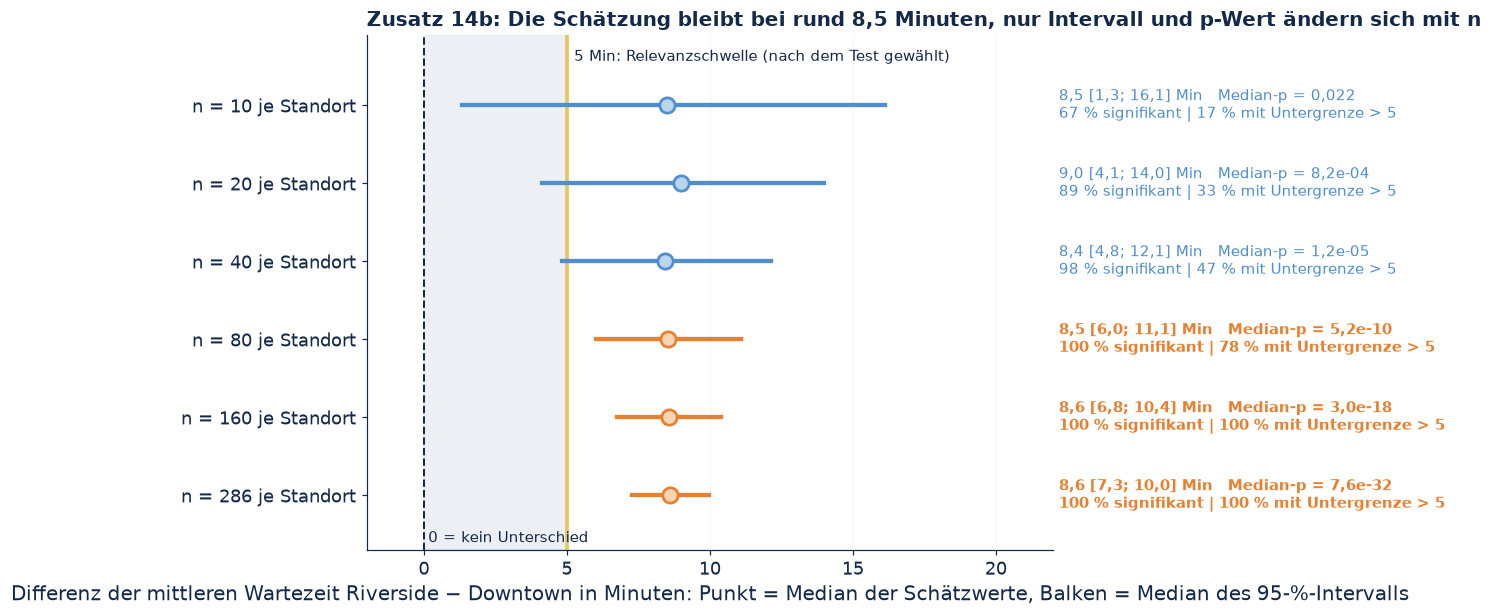

In [82]:
# Zusatz 14b: p-Wert und Konfidenzintervall bei wachsender Stichprobe (Riverside gegen Downtown, Teilstichproben der Projektdaten)
def zusatz14_stichprobe(ns=(10, 20, 40, 80, 160, 286), reps=300, schwelle=5):
    mn = lambda x, nd=1: f"{x:.{nd}f}".replace("-", "−")
    a = df[df.clinic_site == "Riverside"].wait_time_min.values; b = df[df.clinic_site == "Downtown"].wait_time_min.values; rg = np.random.default_rng(SEED); zeilen = []
    for n in ns:
        d_, lo_, hi_, p_ = [], [], [], []
        for _ in range(reps):
            x = rg.choice(a, n, replace=False); y = rg.choice(b, n, replace=False); dif = x.mean() - y.mean()
            se = np.sqrt(x.var(ddof=1) / n + y.var(ddof=1) / n); dfw = welch_df(pd.Series(x), pd.Series(y)); h = stats.t.ppf(.975, dfw) * se
            d_.append(dif); lo_.append(dif - h); hi_.append(dif + h); p_.append(2 * stats.t.sf(abs(dif / se), dfw))
        d_, lo_, hi_, p_ = map(np.array, (d_, lo_, hi_, p_))
        zeilen.append(dict(n=n, diff=np.median(d_), lo=np.median(lo_), hi=np.median(hi_), p=np.median(p_), sig=(p_ < .05).mean() * 100, rel=(lo_ > schwelle).mean() * 100))
    t = pd.DataFrame(zeilen).set_index("n")
    print(f"Je Stichprobengröße {reps} zufällige Teilstichproben (ohne Zurücklegen) aus beiden Standorten; Welch-Test und 95-%-Intervall je Ziehung, Mediane über die Ziehungen.")
    fp = lambda p: f"{p:.1e}" if p < .001 else f"{p:.3f}"
    ausg = pd.DataFrame({"Differenz (Min)": t["diff"].round(2), "KI unten": t.lo.round(2), "KI oben": t.hi.round(2), "Median-p": t.p.map(fp), "p < 0,05 (%)": t.sig.round(1), f"KI-Untergrenze > {schwelle} (%)": t.rel.round(1)})
    print(ausg.to_string(formatters={c: (lambda v: f"{v}") for c in ausg.columns}).replace(".", ","))
    print("Bei n = 286 ist Riverside vollständig enthalten, Downtown wird aus 430 Terminen gezogen. Die Teilstichproben stammen aus denselben Daten und sind keine unabhängigen Replikationen.")
    fig, ax = plt.subplots(figsize=(12, 6)); yy = np.arange(len(t))[::-1]; xt = 22.2
    ax.axvspan(0, schwelle, color=PASTEL["grau"], alpha=.55, zorder=0); ax.axvline(0, color=INK, ls="--", lw=1.3); ax.axvline(schwelle, color=LINE["gelb"], lw=2.4)
    for y_, (n, r) in zip(yy, t.iterrows()):
        sicher = r.lo > schwelle; col = LINE["rosa"] if sicher else LINE["blau"]
        ax.plot([r.lo, r.hi], [y_, y_], color=col, lw=2.8, zorder=2); ax.plot(r["diff"], y_, "o", color=PASTEL["rosa"] if sicher else PASTEL["blau"], mec=col, mew=1.8, ms=10, zorder=3)
        ax.text(xt, y_, f"{mn(r['diff'])} [{mn(r.lo)}; {mn(r.hi)}] Min   Median-p = {fp(r.p)}".replace(".", ",") + f"\n{r.sig:.0f} % signifikant | {r.rel:.0f} % mit Untergrenze > {schwelle}".replace(".", ","), va="center", ha="left", fontsize=9.6, color=col, fontweight="bold" if sicher else "normal")
    ax.set_yticks(yy); ax.set_yticklabels([f"n = {n} je Standort" for n in t.index]); ax.set_xlim(-2, 22); ax.set_ylim(-.7, len(t) - .1); ax.grid(axis="y", visible=False)
    ax.text(schwelle + .25, len(t) - .38, f"{schwelle} Min: Relevanzschwelle (nach dem Test gewählt)", ha="left", va="center", fontsize=9.6, color=INK)
    ax.text(.15, -.55, "0 = kein Unterschied", ha="left", va="center", fontsize=9.6, color=INK)
    ax.set_xlabel("Differenz der mittleren Wartezeit Riverside − Downtown in Minuten: Punkt = Median der Schätzwerte, Balken = Median des 95-%-Intervalls")
    ax.set_title("Zusatz 14b: Die Schätzung bleibt bei rund 8,5 Minuten, nur Intervall und p-Wert ändern sich mit n", fontsize=13, loc="left")
    fig.subplots_adjust(left=.14, right=.66, top=.91, bottom=.13); show()
    return t

t14b = zusatz14_stichprobe()


**Aussage:** Die Punktschätzung bleibt bei allen Stichprobengrößen um 8,5 Minuten, das Intervall schrumpft von [1,3; 16,1] bei 10 Terminen je Standort auf [7,3; 10,0] bei 286, und erst ab 160 Terminen liegt die Untergrenze in praktisch allen Ziehungen (99,7 %) über 5 Minuten.

**Einordnung:**
- **Signifikant heißt nicht relevant:** Bei 10 Terminen je Standort sind 67 % der Ziehungen signifikant, aber nur 17 % haben eine Untergrenze über 5 Minuten. Ein signifikantes Ergebnis stützt die Richtung, die Größe bleibt offen.
- **Was n ändert:** Der Schätzwert bleibt (Median 8,4 bis 9,0 Minuten), Intervallbreite und p-Wert ändern sich. Mit allen 286 und 430 Terminen lautet das Intervall [7,3; 9,8], die plausible Mindestdifferenz also 7,3 Minuten; nach außen gerundet bleibt es bei 7,3 bis 9,9. Das stützt, ist aber keine Garantie und keine Wirkung einer Maßnahme.
- **Grenzen:** Die Ziehungen stammen aus denselben Daten und sind keine unabhängigen Wiederholungen; die Simulation zeigt das Verhalten der Methode, sie bestätigt keinen neuen Befund. Der Median-p-Wert bei 286 Terminen (7,6 · 10⁻³²) weicht vom Gesamtwert ab, weil Downtown dort aus 430 Terminen gezogen wird. „Nicht signifikant“ bedeutet auch hier weder Gleichheit noch Wirkungslosigkeit.

**Teil 3 (14c): Koeffizienten vergleichbar machen.** Im Betriebsdaten-Modell aus Zusatz 7 haben die Koeffizienten unterschiedliche Einheiten (Minuten je Termin, je Person, je Wochenendtag), ihre Beträge lassen sich nicht direkt vergleichen. Multipliziere ich jeden Koeffizienten mit der Standardabweichung seines Prädiktors, erhalte ich den vorhergesagten Unterschied in Minuten je Standardabweichung. Die Zielgröße bleibt dabei in Minuten, es werden nur die Prädiktoren standardisiert.

Koeffizient b (Minuten je Einheit), SD(x) und b × SD(x) (Minuten je Standardabweichung des Prädiktors), mit 95-%-Intervall:
                        b  SD(x)  b × SD(x)  KI unten  KI oben
Geplante Termine    0,501   7,48       3,74      3,00     4,49
Personal im Dienst -1,276   1,47      -1,87     -2,61    -1,13
Wochenende (0/1)    2,298   0,47       1,08      0,64     1,52

Einheitenwechsel: Personal in Stunden (Personen × 8): b = −0,160 Min je Stunde (vorher −1,276 je Person), b × SD = −1,871 Min (vorher −1,871). Der Koeffizient ändert sich mit der Einheit, b × SD(x) nicht.
Personal: 95-%-Intervall [−1,782; −0,771] Min je Person, also 0,771 bis 1,782 Min weniger Wartezeit je zusätzlicher Person; plausible Mindestverringerung 0,771 Min, nach außen gerundet 0,7 bis 1,8 Min (Zusammenhang im Modell, keine Wirkung einer Maßnahme).


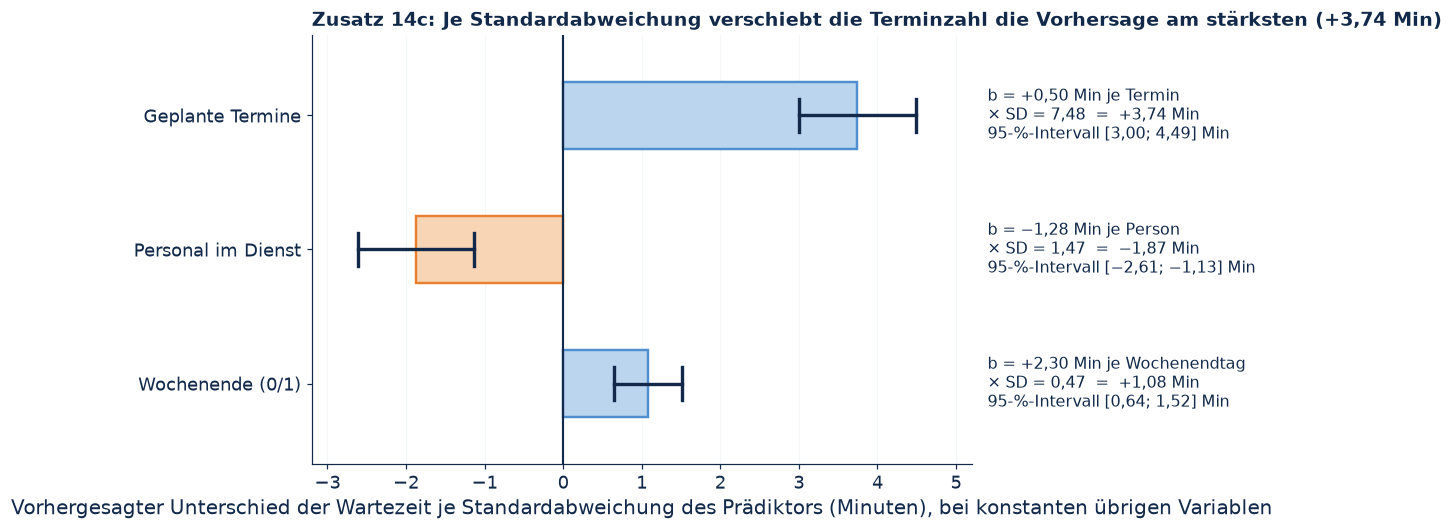

In [83]:
# Zusatz 14c: Koeffizienten vergleichbar machen: b × SD(x) in Minuten (Betriebsdaten, Modell aus Zusatz 7)
def zusatz14_standardisiert():
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−"); sg = lambda x, nd=2: ("+" if x >= 0 else "−") + f"{abs(x):.{nd}f}"
    tab = ops_fit(OPS_X)[0]; sd = ops_df[OPS_X].std(ddof=1)
    namen = {"patients_scheduled": ("Geplante Termine", "Termine"), "staff_on_duty": ("Personal im Dienst", "Personen"), "is_weekend": ("Wochenende (0/1)", "Wochenende")}
    ein = {"patients_scheduled": "Termin", "staff_on_duty": "Person", "is_weekend": "Wochenendtag"}
    z = pd.DataFrame({"b": tab.Koeffizient.iloc[1:], "SD": sd, "lo": tab.untere.iloc[1:] * sd, "hi": tab.obere.iloc[1:] * sd}); z["bsd"] = z.b * z.SD
    print("Koeffizient b (Minuten je Einheit), SD(x) und b × SD(x) (Minuten je Standardabweichung des Prädiktors), mit 95-%-Intervall:")
    print(pd.DataFrame({"b": z.b.round(3), "SD(x)": z.SD.round(2), "b × SD(x)": z.bsd.round(2), "KI unten": z.lo.round(2), "KI oben": z.hi.round(2)}).rename(index={k: v[0] for k, v in namen.items()}).to_string())
    sh = ops_df.staff_on_duty.values * 8.0; tab8 = ols_klein(ops_df.wait_time.values, np.column_stack([ops_df.patients_scheduled.values, sh, ops_df.is_weekend.values]), ["t", "h", "w"])[0]
    print(f"\nEinheitenwechsel: Personal in Stunden (Personen × 8): b = {mn(tab8.Koeffizient.iloc[2], 3)} Min je Stunde (vorher {mn(z.b['staff_on_duty'], 3)} je Person), b × SD = {mn(tab8.Koeffizient.iloc[2] * sh.std(ddof=1), 3)} Min (vorher {mn(z.bsd['staff_on_duty'], 3)}). Der Koeffizient ändert sich mit der Einheit, b × SD(x) nicht.")
    lo_, hi_ = tab.untere["staff_on_duty"], tab.obere["staff_on_duty"]
    print(f"Personal: 95-%-Intervall [{mn(lo_, 3)}; {mn(hi_, 3)}] Min je Person, also {abs(hi_):.3f} bis {abs(lo_):.3f} Min weniger Wartezeit je zusätzlicher Person; plausible Mindestverringerung {abs(hi_):.3f} Min, nach außen gerundet {np.floor(abs(hi_) * 10) / 10:.1f} bis {np.ceil(abs(lo_) * 10) / 10:.1f} Min (Zusammenhang im Modell, keine Wirkung einer Maßnahme).")
    fig, ax = plt.subplots(figsize=(12, 5.2)); yy = np.arange(3)[::-1]; xt = 5.4
    for y_, (k, r) in zip(yy, z.iterrows()):
        col = LINE["blau"] if r.bsd > 0 else LINE["rosa"]; fc = PASTEL["blau"] if r.bsd > 0 else PASTEL["rosa"]
        ax.barh(y_, r.bsd, height=.5, color=fc, edgecolor=col, lw=1.6, zorder=2); ax.plot([r.lo, r.hi], [y_, y_], color=INK, lw=2.2, zorder=3)
        for e in (r.lo, r.hi): ax.plot([e, e], [y_ - .12, y_ + .12], color=INK, lw=2.2, zorder=3)
        ax.text(xt, y_, f"b = {sg(r.b)} Min je {ein[k]}\n× SD = {mn(r.SD)}  =  {sg(r.bsd)} Min\n95-%-Intervall [{mn(r.lo)}; {mn(r.hi)}] Min", va="center", ha="left", fontsize=10.3, color=INK)
    ax.axvline(0, color=INK, lw=1.4); ax.set_yticks(yy); ax.set_yticklabels([namen[k][0] for k in z.index]); ax.set_xlim(-3.2, 5.2); ax.set_ylim(-.6, 2.6); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Vorhergesagter Unterschied der Wartezeit je Standardabweichung des Prädiktors (Minuten), bei konstanten übrigen Variablen")
    ax.set_title("Zusatz 14c: Je Standardabweichung verschiebt die Terminzahl die Vorhersage am stärksten (+3,74 Min)", fontsize=12.5, loc="left")
    fig.subplots_adjust(left=.17, right=.67, top=.9, bottom=.15); show()
    return z

z14 = zusatz14_standardisiert()


**Aussage:** Je Standardabweichung verändert die Terminzahl die vorhergesagte Wartezeit um +3,74 Minuten [3,00; 4,49], das Personal um −1,87 Minuten [−2,61; −1,13] und der Wochenendstatus um +1,08 Minuten [0,64; 1,52].

**Einordnung:**
- **Einheitenprobe:** Rechne ich das Personal in Stunden (Personen × 8), ändert sich der Koeffizient von −1,276 auf −0,160 Minuten je Stunde, das Produkt mit der Standardabweichung bleibt −1,871 Minuten. Der Koeffizient hängt an der Einheit, das Produkt nicht.
- **Mindestgröße beim Personal:** Das Intervall [−1,78; −0,77] Minuten je Person heißt: Mit jeder zusätzlichen Person geht im Modell eine um 0,77 bis 1,78 Minuten kürzere mittlere Wartezeit einher, bei gleicher Terminzahl und gleichem Wochenendstatus. Die plausible Mindestverringerung beträgt 0,77 Minuten (nach außen gerundet 0,7 bis 1,8).
- **Grenzen:** Das ist ein Größenvergleich im Modell, keine Rangfolge von Ursachen; die Personalbesetzung wurde nicht zufällig zugeteilt. Die Standardabweichung eines 0/1-Merkmals (0,47) entspricht keiner tatsächlichen Änderung, für das Wochenende bleibt der Koeffizient von 2,30 Minuten die anschaulichere Angabe.

**Teil 4 (14d): Viele Tests, viele Fehlalarme.** Zusatz 8a hat die 15 Teilgruppen mit Bonferroni-Korrektur geprüft. Hier zeige ich den Grund mit einer Simulation: 20 Zufallsspalten, die garantiert nichts mit der Wartezeit der Betriebsdaten zu tun haben, werden einzeln gegen die Wartezeit getestet, das Ganze 2.000-mal.

2000 Läufe mit je 20 unabhängigen Zufallsspalten (n = 90 Tage), jede einzeln gegen die Wartezeit getestet. Alle Nullhypothesen sind wahr.
Mittlere Zahl der Treffer mit p < 0,05: 1,02 je Lauf (Erwartung 1,0). Läufe mit mindestens einem Treffer: 65,0 % (Rechnung 1 − 0,95^20 = 64,2 %).
Mit Bonferroni-Niveau 0,05/20 = 0,0025: Läufe mit mindestens einem Treffer 4,5 %. Kleinster p-Wert im Median: 0,033; Anteil der Läufe mit kleinstem p < 0,05 nach Bonferroni: 4,5 %.


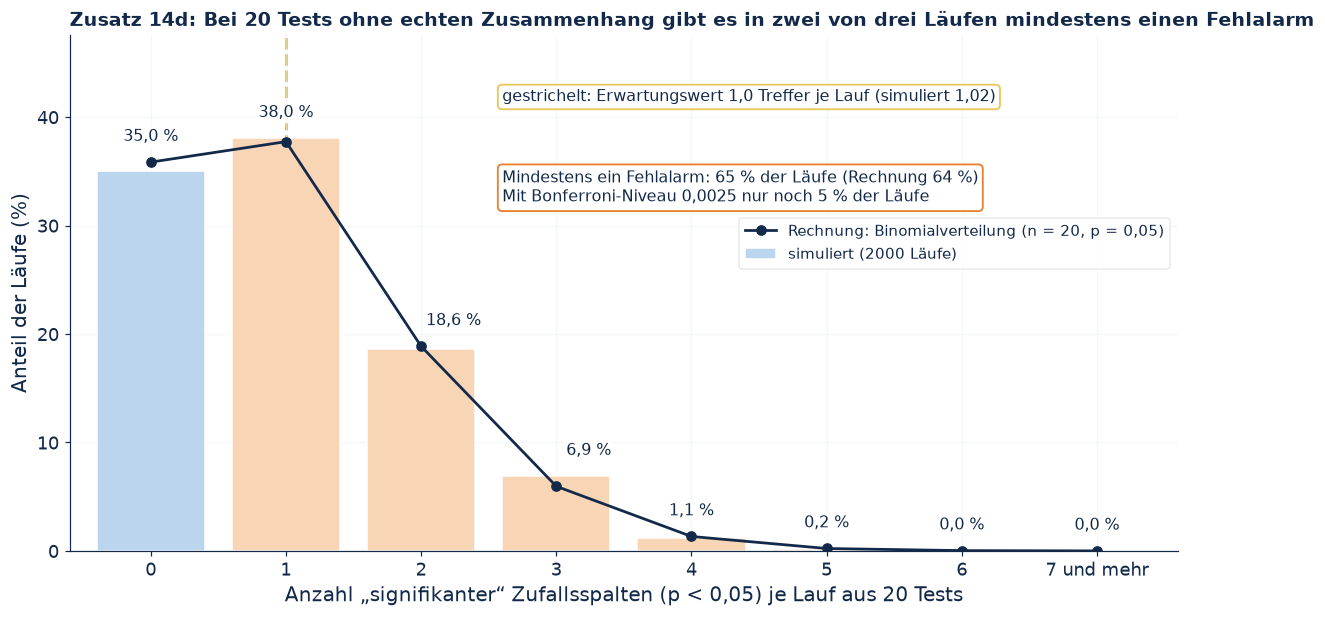

In [84]:
# Zusatz 14d: Mehrfachprüfung, wie oft Zufallsvariablen „signifikant“ werden (20 Zufallsspalten gegen die Wartezeit der Betriebsdaten)
def zusatz14_mehrfach(laeufe=2000, m=20, alpha=.05):
    mn = lambda x, nd=1: f"{x:.{nd}f}".replace("-", "−")
    y = ops_df.wait_time.values; n = len(y); rg = np.random.default_rng(196); yz = (y - y.mean()) / y.std(ddof=1)
    treffer = np.empty(laeufe, int); bonf = np.empty(laeufe, int); pmin = np.empty(laeufe)
    for i in range(laeufe):
        x = rg.normal(size=(n, m)); x = (x - x.mean(0)) / x.std(0, ddof=1); r = (x * yz[:, None]).sum(0) / (n - 1)
        p = 2 * stats.t.sf(np.abs(r * np.sqrt((n - 2) / (1 - r ** 2))), n - 2)
        treffer[i] = (p < alpha).sum(); bonf[i] = (p < alpha / m).sum(); pmin[i] = p.min()
    mind1 = (treffer >= 1).mean() * 100; theo = (1 - (1 - alpha) ** m) * 100; mind1b = (bonf >= 1).mean() * 100
    print(f"{laeufe} Läufe mit je {m} unabhängigen Zufallsspalten (n = {n} Tage), jede einzeln gegen die Wartezeit getestet. Alle Nullhypothesen sind wahr.")
    print(f"Mittlere Zahl der Treffer mit p < {alpha}: {treffer.mean():.2f} je Lauf (Erwartung {m * alpha:.1f}). Läufe mit mindestens einem Treffer: {mind1:.1f} % (Rechnung 1 − 0,95^{m} = {theo:.1f} %).")
    print(f"Mit Bonferroni-Niveau {alpha}/{m} = {alpha / m:.4f}: Läufe mit mindestens einem Treffer {mind1b:.1f} %. Kleinster p-Wert im Median: {np.median(pmin):.3f}; Anteil der Läufe mit kleinstem p < 0,05 nach Bonferroni: {(pmin < alpha / m).mean() * 100:.1f} %.")
    ks = np.arange(0, 8); anteil = np.array([(treffer == k).mean() * 100 for k in ks]); anteil[-1] += (treffer > ks[-1]).mean() * 100; pmf = stats.binom.pmf(ks, m, alpha) * 100; pmf[-1] += stats.binom.sf(ks[-1], m, alpha) * 100
    fig, ax = plt.subplots(figsize=(11, 5.8))
    ax.bar(ks, anteil, width=.8, color=[PASTEL["rosa"] if k >= 1 else PASTEL["blau"] for k in ks], edgecolor="white", label=f"simuliert ({laeufe} Läufe)", zorder=2)
    ax.plot(ks, pmf, "o-", color=INK, lw=1.8, ms=6, label=f"Rechnung: Binomialverteilung (n = {m}, p = {alpha})".replace(".", ","), zorder=3)
    for k, a_, q_ in zip(ks, anteil, pmf): ax.text(k + (.24 if k in (2, 3) else 0), max(a_, q_) + 1.6, f"{a_:.1f} %", ha="center", va="bottom", fontsize=10.5, color=INK, bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.9), zorder=6)
    ax.set_xticks(ks); ax.set_xticklabels([str(k) for k in ks[:-1]] + [f"{ks[-1]} und mehr"]); ax.set_ylim(0, anteil.max() * 1.25); ax.set_xlim(-.6, 7.6)
    ax.axvline(m * alpha, color=LINE["gelb"], ls="--", lw=2, zorder=1)
    ax.text(2.6, anteil.max() * 1.10, f"gestrichelt: Erwartungswert 1,0 Treffer je Lauf (simuliert {treffer.mean():.2f})", ha="left", va="center", fontsize=10.3, color=INK, bbox=dict(boxstyle="round,pad=.28", fc="white", ec=LINE["gelb"], lw=1.2))
    ax.text(2.6, anteil.max() * .88, f"Mindestens ein Fehlalarm: {mind1:.0f} % der Läufe (Rechnung {theo:.0f} %)\nMit Bonferroni-Niveau 0,0025 nur noch {mind1b:.0f} % der Läufe", ha="left", va="center", fontsize=10.3, color=INK, bbox=dict(boxstyle="round,pad=.28", fc="white", ec=LINE["rosa"], lw=1.2))
    ax.set_xlabel(f"Anzahl „signifikanter“ Zufallsspalten (p < {alpha}) je Lauf aus {m} Tests".replace(".", ",")); ax.set_ylabel("Anteil der Läufe (%)")
    ax.set_title("Zusatz 14d: Bei 20 Tests ohne echten Zusammenhang gibt es in zwei von drei Läufen mindestens einen Fehlalarm", fontsize=12.5, loc="left"); ax.legend(loc="upper right", fontsize=10, bbox_to_anchor=(1.0, .66))
    plt.tight_layout(); show()
    return treffer

treffer14 = zusatz14_mehrfach()


**Aussage:** Obwohl keine Spalte etwas mit der Wartezeit zu tun hat, ist in 65,0 % der Läufe mindestens eine „signifikant“ (Rechnung: 1 − 0,95²⁰ = 64,2 %); mit dem Bonferroni-Niveau 0,0025 sinkt der Anteil auf 4,5 %.

**Einordnung:**
- **Erwartungswert und einzelner Lauf:** Im Mittel gibt es 1,02 Treffer je Lauf (Erwartung 1,0). Der einzelne Lauf weicht ab: 35,0 % der Läufe haben keinen Treffer, rund 8 % drei oder mehr.
- **Folge für die Auswertung:** Wer viele Teilgruppen oder Merkmale durchsucht und nur das Auffällige berichtet, verzerrt p-Werte und Intervalle. Testfamilie und Auswahlregeln gehören deshalb vorab dokumentiert, im Projekt sind das 15 Teilgruppen (Zusatz 8a) und 10 Koeffizienten (Zusatz 13).
- **Annahme:** Die Rechnung 1 − (1 − α)ᵐ setzt unabhängige Tests voraus. Bonferroni hält die Fehlerrate auch ohne Unabhängigkeit ein, ist dann aber konservativ.

### Zusatz 15: Was das Modell nicht erfassen kann

Dieser Zusatz fragt, was passiert, wenn im Modell etwas fehlt oder falsch aufgenommen wird: **ausgelassene Variablen, Confounder, Mediatoren und Kollider, Modellspezifikation.** Das Vorzeichen-Kippen des Personal-Koeffizienten stand schon in Zusatz 6 und 7. Neu ist hier: die exakte Zerlegung, warum sich ein Koeffizient ändert (15a), der Vergleich aller Teilmodelle (15b), eine Simulation mit bekannter Wahrheit (15c) und ein Kollider-Beispiel (15d). Alles läuft mit den 90 Betriebstagen aus Zusatz 7.

**Die drei Rollen im Überblick.** Ob eine Variable ins Modell gehört, hängt von der **angenommenen Kausalstruktur** und der Fragestellung ab, nicht vom Datensatz allein:

| Rolle | Struktur | Was die Aufnahme ins Modell bewirkt |
|---|---|---|
| Confounder | gemeinsame Ursache von X und Y (Z → X, Z → Y) | Aufnahme kann den Zusammenhang von X und Y von Z bereinigen |
| Mediator | auf dem Pfad X → M → Y | Aufnahme blendet den über M laufenden Teil aus: Aus dem Gesamteffekt wird der direkte Effekt, die Frage ändert sich |
| Kollider | gemeinsame Folge von X und Y (X → K ← Y) | Aufnahme oder Auswahl nach K **erzeugt** einen Zusammenhang zwischen X und Y |

Im Projekt lässt sich die Struktur aus den Daten nicht ablesen. Das Personal könnte nach dem erwarteten Andrang geplant werden (dann wäre die Terminzahl eine Ursache der Besetzung, und das Personal läge auf dem Weg zwischen Terminen und Wartezeit, ein Mediator), oder beide hängen an einer dritten Größe wie der erwarteten Auslastung (ein Confounder). Beide Lesarten passen zu denselben Zahlen. Die Terminzahl ins Modell zu nehmen, beantwortet die Frage „Was geht mit mehr Personal **bei gleicher Terminzahl** einher?“, sie beweist keine Wirkung.

**Teil 1 (15a): Warum ändert sich der Koeffizient?** Für lineare Regression (OLS) gilt in derselben Stichprobe exakt: **b_kurz = b_lang + g × δ.** Dabei ist b_lang die Steigung im Modell mit beiden Variablen, g der Koeffizient der ausgelassenen Variable im Langmodell und δ die Steigung der Hilfsregression (ausgelassene Variable auf die beibehaltene). Ich rechne das für beide Richtungen nach.

Zerlegung b_kurz = b_lang + g × δ (g: Koeffizient der ausgelassenen Variable im Langmodell, δ: Steigung der Hilfsregression ausgelassene auf beibehaltene Variable)
  Terminsteigung (Personal ausgelassen): b_lang 0,5306 + g −1,3338 × δ 0,1596 = 0,3177; b_kurz direkt 0,3177; Abweichung 2,2e-16
  Personalsteigung (Termine ausgelassen): b_lang −1,3338 + g 0,5306 × δ 4,1496 = 0,8678; b_kurz direkt 0,8678; Abweichung 1,3e-15
Korrelation Termine/Personal: r = 0,814; δ aus r × SD(Personal)/SD(Termine) = 0,1596


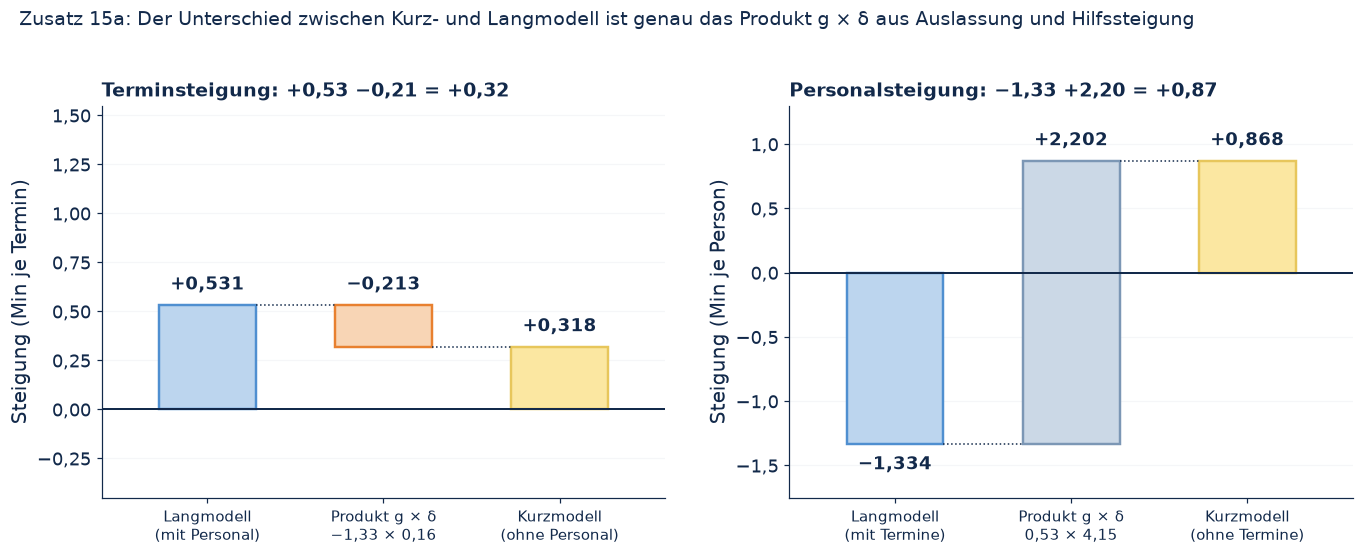

In [85]:
# Zusatz 15a: Zerlegung b_kurz = b_lang + g × δ (Betriebsdaten)
def zusatz15_zerlegung():
    mn = lambda x, nd=3: f"{x:.{nd}f}".replace("-", "−"); sg = lambda x, nd=3: ("+" if x >= 0 else "−") + f"{abs(x):.{nd}f}"
    y = ops_df.wait_time.values; T = ops_df.patients_scheduled.values.astype(float); S = ops_df.staff_on_duty.values.astype(float)
    def b(cols, namen, k): return ols_klein(y, np.column_stack(cols), namen)[0].Koeffizient.iloc[k]
    fall = []
    # (1) Terminsteigung ohne Personal (kurz) und mit Personal (lang); ausgelassen: Personal
    k1, l1 = b([T], ["T"], 1), b([T, S], ["T", "S"], 1); g1 = b([T, S], ["T", "S"], 2); d1 = ols_klein(S, T.reshape(-1, 1), ["T"])[0].Koeffizient.iloc[1]
    fall.append(("Terminsteigung", "Personal ausgelassen", k1, l1, g1, d1, "Min je Termin"))
    # (2) Personalsteigung ohne Termine (kurz) und mit Terminen (lang); ausgelassen: Termine
    k2, l2 = b([S], ["S"], 1), b([S, T], ["S", "T"], 1); g2 = b([S, T], ["S", "T"], 2); d2 = ols_klein(T, S.reshape(-1, 1), ["S"])[0].Koeffizient.iloc[1]
    fall.append(("Personalsteigung", "Termine ausgelassen", k2, l2, g2, d2, "Min je Person"))
    print("Zerlegung b_kurz = b_lang + g × δ (g: Koeffizient der ausgelassenen Variable im Langmodell, δ: Steigung der Hilfsregression ausgelassene auf beibehaltene Variable)")
    for nm, aus, k, l, g, d, e in fall:
        print(f"  {nm} ({aus}): b_lang {mn(l, 4)} + g {mn(g, 4)} × δ {mn(d, 4)} = {mn(l + g * d, 4)}; b_kurz direkt {mn(k, 4)}; Abweichung {abs(l + g * d - k):.1e}")
    r = np.corrcoef(T, S)[0, 1]
    print(f"Korrelation Termine/Personal: r = {mn(r)}; δ aus r × SD(Personal)/SD(Termine) = {mn(r * S.std(ddof=1) / T.std(ddof=1), 4)}")
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4)); lim = [(-.45, 1.55), (-1.75, 1.3)]
    for ax, (nm, aus, k, l, g, d, e), (lo, hi) in zip(axes, fall, lim):
        p = g * d; pos = [0, 1, 2]
        ax.bar(0, l, width=.55, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=1.6, zorder=2)
        ax.bar(1, p, bottom=l, width=.55, color=PASTEL["rosa"] if p < 0 else PASTEL["gruen"], edgecolor=LINE["rosa"] if p < 0 else LINE["gruen"], lw=1.6, zorder=2)
        ax.bar(2, k, width=.55, color=PASTEL["gelb"], edgecolor=LINE["gelb"], lw=1.6, zorder=2)
        ax.plot([.275, .725], [l, l], color=INK, lw=1, ls=":"); ax.plot([1.275, 1.725], [k, k], color=INK, lw=1, ls=":"); ax.axhline(0, color=INK, lw=1.3)
        yo = (hi - lo) * .03
        ax.text(0, l + (yo if l >= 0 else -yo), f"{sg(l)}", ha="center", va="bottom" if l >= 0 else "top", fontsize=11.5, fontweight="bold")
        ax.text(1, max(l, l + p) + yo, f"{sg(p)}", ha="center", va="bottom", fontsize=11.5, fontweight="bold")
        ax.text(2, k + (yo if k >= 0 else -yo), f"{sg(k)}", ha="center", va="bottom" if k >= 0 else "top", fontsize=11.5, fontweight="bold")
        ax.set_xticks(pos); ax.set_xticklabels([f"Langmodell\n(mit {aus.split()[0]})", f"Produkt g × δ\n{mn(g, 2)} × {mn(d, 2)}", f"Kurzmodell\n(ohne {aus.split()[0]})"], fontsize=10)
        ax.set_ylim(lo, hi); ax.set_xlim(-.6, 2.6); ax.grid(axis="x", visible=False); ax.set_ylabel(f"Steigung ({e})")
        ax.set_title(f"{nm}: {sg(l, 2)} {sg(p, 2)} = {sg(k, 2)}".replace(".", ","), fontsize=12.5, loc="left")
    fig.suptitle("Zusatz 15a: Der Unterschied zwischen Kurz- und Langmodell ist genau das Produkt g × δ aus Auslassung und Hilfssteigung", fontsize=12.5, x=.01, ha="left")
    fig.subplots_adjust(left=.07, right=.98, top=.82, bottom=.16, wspace=.22); show()
    return fall

z15a = zusatz15_zerlegung()


**Aussage:** Die Terminsteigung fällt ohne Personal von 0,531 auf 0,318 (0,531 − 0,213), die Personalsteigung steigt ohne Termine von −1,334 auf +0,868 (−1,334 + 2,202), beide Male genau das Produkt g × δ.

**Einordnung:**
- **Warum das Vorzeichen kippt:** Termine und Personal hängen zusammen (r = 0,814). Lässt man die Termine weg, nimmt der Personal-Koeffizient ihren Effekt mit: 0,531 × 4,150 = +2,202 Minuten je Person, mehr als der eigene Effekt von −1,334.
- **Prüfung:** Die Identität stimmt bis auf Rechengenauigkeit (Abweichung unter 10⁻¹⁵). Sie ist reine Algebra der Stichprobe.
- **Was sie nicht sagt:** Die Zerlegung zeigt die Differenz zweier Schätzungen, nicht den Abstand zu einem wahren Wert. Ob ein Modell „verzerrt“ ist, braucht eine begründete Kausalannahme. Auch ein Koeffizient mit g × δ = 0 schließt Verzerrung nicht aus, wenn andere Variablen fehlen.

**Teil 2 (15b): Alle sieben Teilmodelle.** Zusatz 6 und 7 haben einzelne Modellpaare verglichen. Hier steht für jede der drei Variablen der Koeffizient mit Intervall in **jedem** Teilmodell, in dem sie vorkommt. Wichtig ist die Frage: Welche Koeffizienten sind stabil, welche hängen am Modell?

Koeffizient [95-%-Intervall] in allen sieben Teilmodellen (Minuten Wartezeit je Einheit):
  Termine    im Modell Termine                                0,318 [0,246; 0,390]  R² = 46,6 %
  Termine    im Modell Termine + Personal                     0,531 [0,419; 0,642]  R² = 57,3 %
  Termine    im Modell Termine + Wochenende                   0,296 [0,230; 0,362]  R² = 57,0 %
  Termine    im Modell Termine + Personal + Wochenende        0,501 [0,401; 0,600]  R² = 66,7 %
  Personal   im Modell Personal                               0,868 [0,400; 1,336]  R² = 13,4 %
  Personal   im Modell Termine + Personal                    −1,334 [−1,902; −0,765]  R² = 57,3 %
  Personal   im Modell Personal + Wochenende                  0,784 [0,354; 1,215]  R² = 28,2 %
  Personal   im Modell Termine + Personal + Wochenende       −1,276 [−1,782; −0,771]  R² = 66,7 %
  Wochenende im Modell Wochenende                             3,084 [1,658; 4,509]  R² = 17,4 %
  Wochenende im Modell Termine + Wochenend

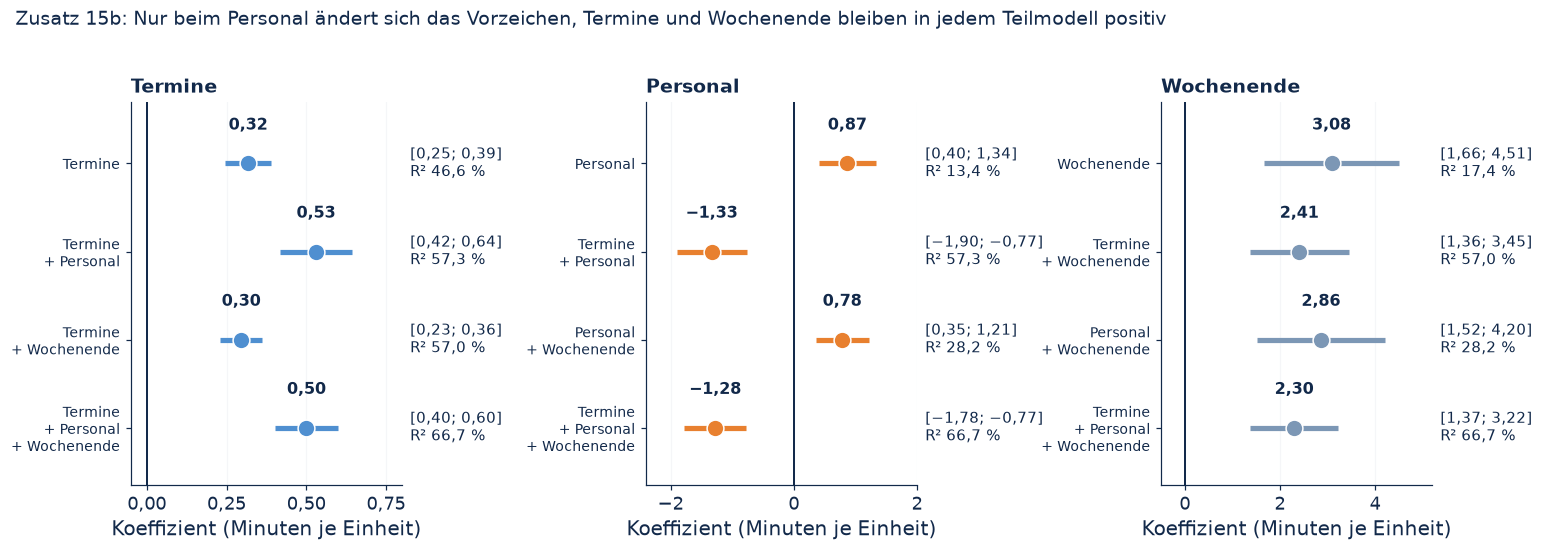


Personal: roh 0,868, mit Terminen −1,334 (Verschiebung −2,202), im vollen Modell −1,276 [−1,782; −0,771].
Hypothetische Verschiebung, die den vollen Personal-Koeffizienten auf null brächte: +1,276 Min je Person (Punktschätzung) bzw. +0,771 (obere Intervallgrenze); sie läge unter dem Betrag der Verschiebung durch die Terminzahl (2,202). Das ist eine Rechenhilfe, kein Beleg für einen unbeobachteten Einfluss.


In [86]:
# Zusatz 15b: Alle Teilmodelle der drei Prädiktoren, wie stabil sind die Koeffizienten? (Betriebsdaten)
def zusatz15_teilmodelle():
    import itertools
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−")
    kurz = {"patients_scheduled": "Termine", "staff_on_duty": "Personal", "is_weekend": "Wochenende"}
    zeilen = []
    for k in (1, 2, 3):
        for combo in itertools.combinations(OPS_X, k):
            tab, r2, *_ = ops_fit(list(combo))
            zeilen.append({"combo": combo, "name": " + ".join(kurz[c] for c in combo), "r2": r2, **{c: (tab.Koeffizient[c], tab.untere[c], tab.obere[c]) for c in combo}})
    print("Koeffizient [95-%-Intervall] in allen sieben Teilmodellen (Minuten Wartezeit je Einheit):")
    for var in ("patients_scheduled", "staff_on_duty", "is_weekend"):
        for z in zeilen:
            if var in z["combo"]: print(f"  {kurz[var]:10s} im Modell {z['name']:36s} {mn(z[var][0], 3):>7} [{mn(z[var][1], 3)}; {mn(z[var][2], 3)}]  R² = {mn(z['r2'] * 100, 1)} %")
    fig, axes = plt.subplots(1, 3, figsize=(14, 5.2)); farben = {"patients_scheduled": "blau", "staff_on_duty": "rosa", "is_weekend": "gruen"}
    xl = {"patients_scheduled": (-.05, .8), "staff_on_duty": (-2.4, 2.0), "is_weekend": (-.5, 5.2)}
    for ax, var in zip(axes, OPS_X):
        sub = [z for z in zeilen if var in z["combo"]]; sub.sort(key=lambda z: len(z["combo"]))
        for i, z in enumerate(sub):
            b, lo, hi = z[var]; ax.hlines(i, lo, hi, color=LINE[farben[var]], lw=3.4, zorder=2); ax.plot(b, i, "o", color=LINE[farben[var]], ms=11, markeredgecolor="white", zorder=3)
            ax.text(b, i - .34, f"{mn(b, 2)}", ha="center", va="bottom", fontsize=10.5, fontweight="bold")
            ax.text(1.03, i, f"[{mn(lo, 2)}; {mn(hi, 2)}]\nR² {mn(z['r2'] * 100, 1)} %", va="center", ha="left", fontsize=9.6, transform=ax.get_yaxis_transform())
        ax.axvline(0, color=INK, lw=1.3); ax.set_yticks(range(len(sub))); ax.set_yticklabels([z["name"].replace(" + ", "\n+ ") for z in sub], fontsize=9); ax.invert_yaxis()
        ax.set_xlim(*xl[var]); ax.set_ylim(len(sub) - .35, -.7); ax.grid(axis="y", visible=False); ax.set_title(f"{kurz[var]}", fontsize=12.5, loc="left")
        ax.set_xlabel("Koeffizient (Minuten je Einheit)")
    fig.suptitle("Zusatz 15b: Nur beim Personal ändert sich das Vorzeichen, Termine und Wochenende bleiben in jedem Teilmodell positiv", fontsize=12.5, x=.01, ha="left")
    fig.subplots_adjust(left=.085, right=.93, top=.82, bottom=.15, wspace=.9); show()
    tab = ops_fit(OPS_X)[0]; s = tab.loc["staff_on_duty"]
    s_roh = [z for z in zeilen if z["combo"] == ("staff_on_duty",)][0]["staff_on_duty"][0]; s_t = [z for z in zeilen if z["combo"] == ("patients_scheduled", "staff_on_duty")][0]["staff_on_duty"][0]
    print(f"\nPersonal: roh {mn(s_roh, 3)}, mit Terminen {mn(s_t, 3)} (Verschiebung {mn(s_t - s_roh, 3)}), im vollen Modell {mn(s.Koeffizient, 3)} [{mn(s.untere, 3)}; {mn(s.obere, 3)}].")
    print(f"Hypothetische Verschiebung, die den vollen Personal-Koeffizienten auf null brächte: +{abs(s.Koeffizient):.3f} Min je Person (Punktschätzung) bzw. +{abs(s.obere):.3f} (obere Intervallgrenze); sie läge unter dem Betrag der Verschiebung durch die Terminzahl ({abs(s_t - s_roh):.3f}). Das ist eine Rechenhilfe, kein Beleg für einen unbeobachteten Einfluss.")
    return zeilen

z15b = zusatz15_teilmodelle()


**Aussage:** Nur der Personal-Koeffizient wechselt sein Vorzeichen (+0,87 und +0,78 ohne Termine, −1,33 und −1,28 mit Terminen), die Terminsteigung liegt in allen Teilmodellen zwischen 0,30 und 0,53 und der Wochenendkoeffizient zwischen 2,30 und 3,08 Minuten.

**Einordnung:**
- **Stabil und instabil:** Termine und Wochenende bleiben positiv, ihre Intervalle schließen null nie ein. Beim Personal hängt sogar die Richtung vom Modell ab. Die Wahl des Modells muss durch Fragestellung und Annahmen begründet werden, nicht durch den günstigsten Koeffizienten.
- **Rechenhilfe zur Größe:** Damit der volle Personal-Koeffizient (−1,276) auf null stiege, müsste ein unbeobachteter Einfluss ihn um 1,276 Minuten je Person verschieben, bis zur oberen Intervallgrenze reichen 0,771. Die Terminzahl hat ihn um 2,202 verschoben. Eine solche Größenordnung ist also denkbar. Das ist keine Aussage, dass es einen solchen Einfluss gibt, sondern ein Maß dafür, wie viel Spielraum das Ergebnis lässt.
- **Grenzen:** Das Intervall (−1,78; −0,77) gilt unter den Modellannahmen. Es erfasst Auslassungs-, Mess- oder Auswahlverzerrung nicht.

**Teil 3 (15c): Confounding mit bekannter Wahrheit.** In echten Daten kennt man die Wahrheit nicht. Deshalb baue ich eine Simulation: Das Gerüst bilden die **echten** Termin- und Personalzahlen der 90 Tage. Die Wartezeit erzeuge ich neu als 2,0 + 0,318 × Termine + Zufall (die Terminsteigung aus dem Modell nur mit Terminen, die Streuung aus demselben Modell). Das Personal hat in dieser Simulation **keinen** Einfluss. Ich wiederhole das 2.000-mal (SEED 42) und schätze den Personal-Koeffizienten einmal ohne und einmal mit der Terminzahl im Modell.

Simulierte Wartezeit = 2,0 + 0,318 × Termine + Zufall (SD 2,56 Min); wahrer Personal-Effekt = 0; 2 000 Läufe mit den echten 90 Tagen als Gerüst.
Personal-Koeffizient ohne Terminzahl im Modell: Mittelwert 1,320 (Median 1,315), 95 % der Läufe in [0,96; 1,68]; signifikant (p < 0,05) in 100,0 % der Läufe.
Personal-Koeffizient mit Terminzahl im Modell:  Mittelwert 0,000 (Median 0,005), 95 % der Läufe in [−0,63; 0,62]; signifikant in 4,9 % der Läufe, Intervall enthält 0 in 95,1 %.


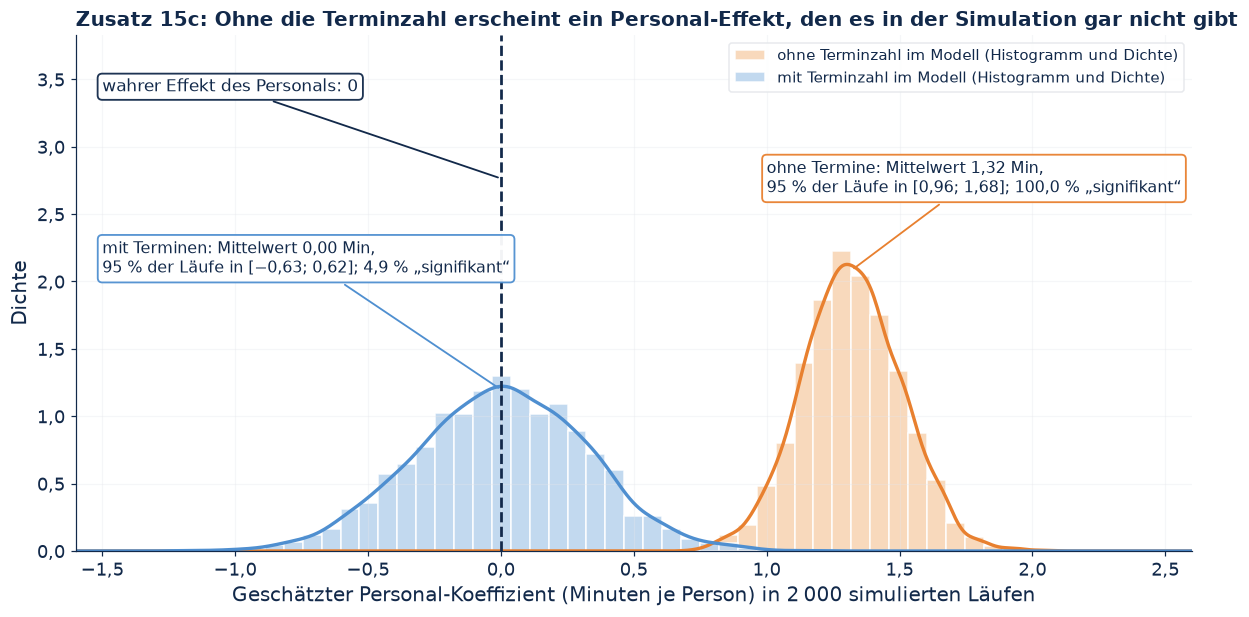

In [87]:
# Zusatz 15c: Confounding mit bekannter Wahrheit, Simulation auf den echten Personal- und Terminzahlen
def zusatz15_confounder(laeufe=2000):
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−")
    T = ops_df.patients_scheduled.values.astype(float); S = ops_df.staff_on_duty.values.astype(float); n = len(T)
    b_wahr = ops_fit(["patients_scheduled"])[0].Koeffizient["patients_scheduled"]; sd_e = ops_fit(["patients_scheduled"])[6]
    rg = np.random.default_rng(SEED); X1 = np.column_stack([np.ones(n), S]); X2 = np.column_stack([np.ones(n), S, T])
    inv1 = np.linalg.inv(X1.T @ X1); inv2 = np.linalg.inv(X2.T @ X2); naiv = np.empty(laeufe); adj = np.empty(laeufe); sig_n = 0; sig_a = 0; ci_a = 0
    for i in range(laeufe):
        y = 2.0 + b_wahr * T + rg.normal(0, sd_e, n)        # Wahrheit: nur die Terminzahl wirkt, das Personal hat den Effekt 0
        for X, inv, store, k in ((X1, inv1, naiv, 1), (X2, inv2, adj, 1)):
            b = inv @ X.T @ y; r = y - X @ b; se = np.sqrt(r @ r / (n - X.shape[1]) * inv[k, k]); store[i] = b[k]
            sig = abs(b[k] / se) > stats.t.ppf(.975, n - X.shape[1])
            if store is naiv: sig_n += sig
            else: sig_a += sig; ci_a += abs(b[k]) <= stats.t.ppf(.975, n - X.shape[1]) * se
    print(f"Simulierte Wartezeit = 2,0 + {mn(b_wahr, 3)} × Termine + Zufall (SD {mn(sd_e, 2)} Min); wahrer Personal-Effekt = 0; {tsd(laeufe)} Läufe mit den echten 90 Tagen als Gerüst.")
    print(f"Personal-Koeffizient ohne Terminzahl im Modell: Mittelwert {mn(naiv.mean(), 3)} (Median {mn(np.median(naiv), 3)}), 95 % der Läufe in [{mn(np.percentile(naiv, 2.5), 2)}; {mn(np.percentile(naiv, 97.5), 2)}]; signifikant (p < 0,05) in {sig_n / laeufe * 100:.1f} % der Läufe.")
    print(f"Personal-Koeffizient mit Terminzahl im Modell:  Mittelwert {mn(adj.mean(), 3)} (Median {mn(np.median(adj), 3)}), 95 % der Läufe in [{mn(np.percentile(adj, 2.5), 2)}; {mn(np.percentile(adj, 97.5), 2)}]; signifikant in {sig_a / laeufe * 100:.1f} % der Läufe, Intervall enthält 0 in {ci_a / laeufe * 100:.1f} %.")
    fig, ax = plt.subplots(figsize=(11.5, 5.8)); bins = np.linspace(-1.6, 2.6, 60); xs = np.linspace(-1.6, 2.6, 700)
    ax.hist(naiv, bins=bins, density=True, color=PASTEL["rosa"], edgecolor="white", alpha=.9, label="ohne Terminzahl im Modell (Histogramm und Dichte)")
    ax.hist(adj, bins=bins, density=True, color=PASTEL["blau"], edgecolor="white", alpha=.9, label="mit Terminzahl im Modell (Histogramm und Dichte)")
    kn = stats.gaussian_kde(naiv)(xs); ka = stats.gaussian_kde(adj)(xs); ax.plot(xs, kn, color=LINE["rosa"], lw=2.2); ax.plot(xs, ka, color=LINE["blau"], lw=2.2)
    ax.axvline(0, color=INK, lw=1.8, ls="--")
    ym = max(kn.max(), ka.max()); ax.set_ylim(0, ym * 1.8); ax.set_xlim(-1.6, 2.6)
    tagd(ax, (0, ym * 1.3), (-1.5, ym * 1.62), "wahrer Effekt des Personals: 0", INK, fs=10.8)
    tagd(ax, (naiv.mean(), kn.max() * .98), (1.0, ym * 1.3), f"ohne Termine: Mittelwert {mn(naiv.mean())} Min,\n95 % der Läufe in [{mn(np.percentile(naiv, 2.5))}; {mn(np.percentile(naiv, 97.5))}]; {sig_n / laeufe * 100:.1f} % „signifikant“".replace(".", ","), LINE["rosa"], fs=10.5)
    tagd(ax, (adj.mean(), ka.max() * .98), (-1.5, ym * 1.02), f"mit Terminen: Mittelwert {mn(adj.mean())} Min,\n95 % der Läufe in [{mn(np.percentile(adj, 2.5))}; {mn(np.percentile(adj, 97.5))}]; {sig_a / laeufe * 100:.1f} % „signifikant“".replace(".", ","), LINE["blau"], fs=10.5)
    ax.set_xlabel(f"Geschätzter Personal-Koeffizient (Minuten je Person) in {tsd(laeufe)} simulierten Läufen"); ax.set_ylabel("Dichte")
    ax.set_title("Zusatz 15c: Ohne die Terminzahl erscheint ein Personal-Effekt, den es in der Simulation gar nicht gibt", fontsize=13, loc="left"); ax.legend(loc="upper right", fontsize=9.8, bbox_to_anchor=(1, 1))
    plt.tight_layout(); show()
    return naiv, adj

z15c = zusatz15_confounder()


**Aussage:** Obwohl das Personal in der Simulation nichts bewirkt, ist sein Koeffizient ohne Terminzahl im Modell im Mittel +1,32 Minuten je Person und in allen 2.000 Läufen „signifikant“, mit Terminzahl liegt er im Mittel bei 0,00 und ist nur in 4,9 % der Läufe signifikant.

**Einordnung:**
- **Genau das Produkt aus 15a:** 0,318 × 4,150 ≈ 1,32. Der Scheineffekt entsteht, weil Personal und Termine zusammenhängen (r = 0,814) und die Termine fehlen.
- **Mit dem Confounder im Modell** liegt die Fehlalarmrate bei 4,9 % und damit beim erwarteten Niveau von 5 %; das Intervall enthält in 95,1 % der Läufe die Null.
- **Aussagekraft:** Das ist ein konstruiertes Beispiel mit bekannter Wahrheit. Es zeigt, wie die Methode arbeitet, nicht, wie die Welt im Klinikbetrieb ist. In den echten Daten gilt −1,276 nur, wenn die Terminzahl der richtige Ausgleich ist und nichts anderes fehlt.

**Teil 4 (15d): Kollider.** Ein Kollider ist eine gemeinsame **Folge** zweier Größen. Wer danach auswählt oder ihn ins Modell nimmt, erzeugt einen Zusammenhang, der vorher nicht da war. Für das Beispiel nehme ich zwei echte Größen, die per Konstruktion unkorreliert sind: die Terminzahl und die **Personal-Abweichung** (Personal minus der aus der Terminzahl vorhergesagte Wert, also die Besetzung „über oder unter dem Üblichen“). Als konstruierten Kollider lasse ich eine Prüfung die 40 % der Tage auswählen, an denen Termine und Personal-Abweichung zusammen hoch sind (Auswahlwert = z(Termine) + z(Abweichung) + Zufall). Diese Prüfung ist erfunden, sie dient nur der Veranschaulichung.

Konstruktion: Personal-Abweichung R = Personal minus Vorhersage aus der Terminzahl (per Konstruktion unkorreliert mit den Terminen). Prüfstatus = oberste 40 % von z(Termine) + z(R) + Zufall: 36 von 90 Tagen (SEED 42).
Alle 90 Tage:      r = 0,000, Steigung 0,000 [−0,024; 0,024] Personen je Termin, p = 1,00
Nur 36 Prüftage:    r = −0,479, Steigung −0,057 [−0,094; −0,021] Personen je Termin, p = 0,0031


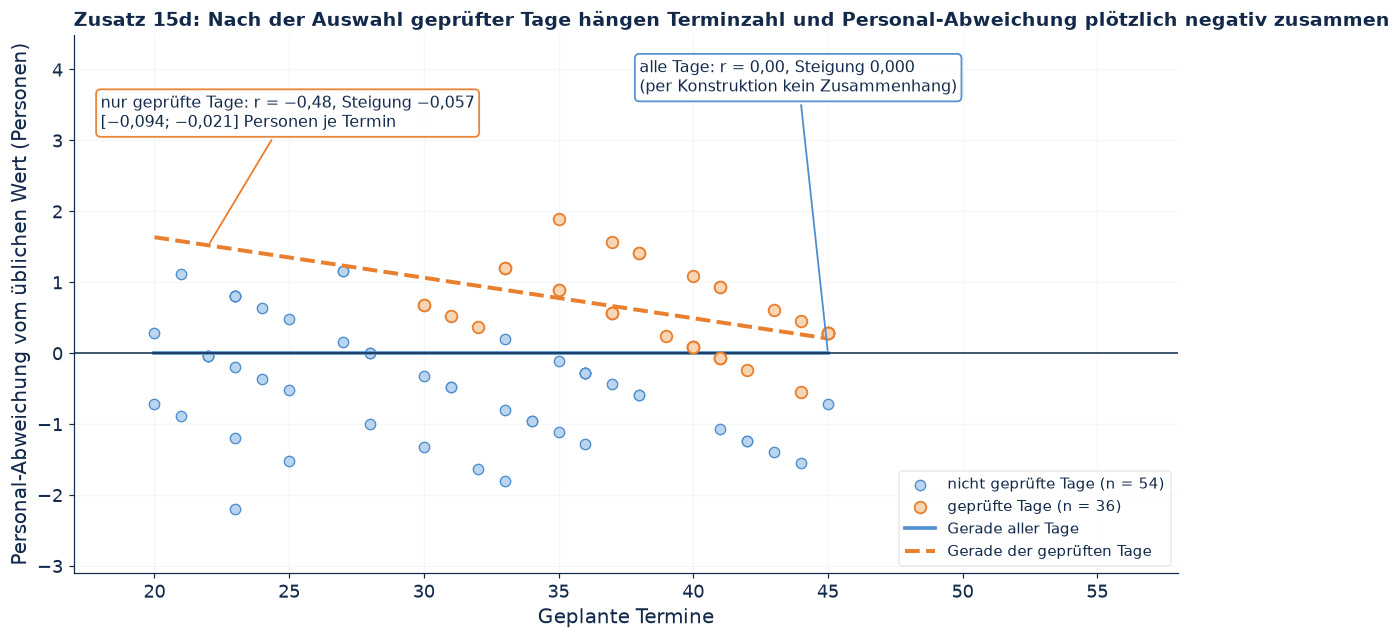

In [88]:
# Zusatz 15d: Kollider, eine Auswahl nach einer gemeinsamen Folge erzeugt einen Zusammenhang (Betriebsdaten)
def zusatz15_kollider():
    mn = lambda x, nd=2: f"{(0.0 if round(x, nd) == 0 else x):.{nd}f}".replace("-", "−"); sg = lambda x, nd=2: ("+" if x >= 0 else "−") + f"{abs(x):.{nd}f}" if round(x, nd) != 0 else f"{0:.{nd}f}"
    T = ops_df.patients_scheduled.values.astype(float); S = ops_df.staff_on_duty.values.astype(float); n = len(T)
    tab, *_ = ols_klein(S, T.reshape(-1, 1), ["T"]); R = S - (tab.Koeffizient.iloc[0] + tab.Koeffizient.iloc[1] * T)     # Personal-Abweichung vom für die Terminzahl üblichen Wert
    z = lambda v: (v - v.mean()) / v.std(ddof=1); rg = np.random.default_rng(SEED)
    score = z(T) + z(R) + rg.normal(0, .5, n); sel = score > np.quantile(score, .60)                                         # konstruierter Prüfstatus: beide Größen gehen in die Auswahl ein
    r_all = np.corrcoef(T, R)[0, 1]; r_sel = np.corrcoef(T[sel], R[sel])[0, 1]
    t_all = ols_klein(R, T.reshape(-1, 1), ["T"])[0].loc["T"]; t_sel = ols_klein(R[sel], T[sel].reshape(-1, 1), ["T"])[0].loc["T"]
    print(f"Konstruktion: Personal-Abweichung R = Personal minus Vorhersage aus der Terminzahl (per Konstruktion unkorreliert mit den Terminen). Prüfstatus = oberste 40 % von z(Termine) + z(R) + Zufall: {int(sel.sum())} von {n} Tagen (SEED {SEED}).")
    print(f"Alle {n} Tage:      r = {mn(r_all, 3)}, Steigung {sg(t_all.Koeffizient, 3)} [{mn(t_all.untere, 3)}; {mn(t_all.obere, 3)}] Personen je Termin, p = {t_all.p:.2f}")
    print(f"Nur {int(sel.sum())} Prüftage:    r = {mn(r_sel, 3)}, Steigung {sg(t_sel.Koeffizient, 3)} [{mn(t_sel.untere, 3)}; {mn(t_sel.obere, 3)}] Personen je Termin, p = {t_sel.p:.4f}")
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.scatter(T[~sel], R[~sel], s=46, color=PASTEL["blau"], edgecolor=LINE["blau"], lw=.9, label=f"nicht geprüfte Tage (n = {int((~sel).sum())})", zorder=2)
    ax.scatter(T[sel], R[sel], s=58, color=PASTEL["rosa"], edgecolor=LINE["rosa"], lw=1.2, label=f"geprüfte Tage (n = {int(sel.sum())})", zorder=3)
    xs = np.array([T.min(), T.max()]); ax.plot(xs, t_all.Konstante if False else ols_klein(R, T.reshape(-1, 1), ["T"])[0].Koeffizient.iloc[0] + t_all.Koeffizient * xs, color=LINE["blau"], lw=2.4, label="Gerade aller Tage")
    c_sel = ols_klein(R[sel], T[sel].reshape(-1, 1), ["T"])[0].Koeffizient.iloc[0]; ax.plot(xs, c_sel + t_sel.Koeffizient * xs, color=LINE["rosa"], lw=2.6, ls="--", label="Gerade der geprüften Tage")
    ax.axhline(0, color=INK, lw=1)
    ax.set_xlim(17, 58); ax.set_ylim(R.min() - .9, R.max() + 2.6)
    tagd(ax, (xs[1], tab.Koeffizient.iloc[0] * 0 + ols_klein(R, T.reshape(-1, 1), ["T"])[0].Koeffizient.iloc[0] + t_all.Koeffizient * xs[1]), (38, R.max() + 2.0), f"alle Tage: r = {mn(r_all, 2)}, Steigung {sg(t_all.Koeffizient, 3)}\n(per Konstruktion kein Zusammenhang)", LINE["blau"], fs=10.5)
    tagd(ax, (xs[0] + 2, c_sel + t_sel.Koeffizient * (xs[0] + 2)), (18, R.max() + 1.5), f"nur geprüfte Tage: r = {mn(r_sel, 2)}, Steigung {sg(t_sel.Koeffizient, 3)}\n[{mn(t_sel.untere, 3)}; {mn(t_sel.obere, 3)}] Personen je Termin", LINE["rosa"], fs=10.5)
    ax.set_xlabel("Geplante Termine"); ax.set_ylabel("Personal-Abweichung vom üblichen Wert (Personen)")
    ax.set_title("Zusatz 15d: Nach der Auswahl geprüfter Tage hängen Terminzahl und Personal-Abweichung plötzlich negativ zusammen", fontsize=12.2, loc="left"); ax.legend(loc="lower right", fontsize=9.8)
    plt.tight_layout(); show()
    return r_all, r_sel

z15d = zusatz15_kollider()


**Aussage:** Über alle 90 Tage sind Terminzahl und Personal-Abweichung unkorreliert (r = 0,00), unter den 36 ausgewählten Tagen aber negativ (r = −0,48, Steigung −0,057 Personen je Termin, p = 0,003).

**Einordnung:**
- **Warum negativ:** Wer bei wenigen Terminen ausgewählt wurde, muss eine hohe Personal-Abweichung haben, und umgekehrt. Die Auswahl koppelt beide Größen aneinander.
- **Übertrag auf das Projekt:** Eine Auswertung nur der „auffälligen“ Tage, Termine oder Kliniken (Auswahl nach einer Folge von Ursache und Ergebnis) kann einen Zusammenhang erzeugen, der ohne die Auswahl nicht besteht. Deshalb ist wichtig, wie die Daten zustande kamen (Bereinigung in 1.3, Ausreißerregel in 1.4), nicht nur, was sie zeigen.
- **Grenze:** Das Beispiel ist künstlich. Welche Variablen im Klinikbetrieb tatsächlich Kollider, Mediatoren oder Confounder sind, folgt aus Fachwissen und Studiendesign und nicht aus der Regression.

### Zusatz 16: Hält das Modell der Betriebsdaten, was es verspricht? (Diagnose)

Zusatz 7 bis 15 haben das Modell der 90 Betriebstage beschrieben, getestet und mit Simulationen ausgereizt. Hier prüfe ich drei Dinge, die bisher offen waren: ob das Modell an einzelnen **Tagen** hängt (16a), ob die **Intervalle** von der Rechenmethode abhängen (16b) und ob die Annahme „gerade Linien, Wirkungen addieren sich“ haltbar ist (16c). Grundlage ist das Modell 3 aus Zusatz 7 (Patienten, Personal, Wochenende). Das vertieft die Annahmenprüfung aus Aufgabe 5 von Zusatz 7.

**16a: Einflussreiche Tage.** Ein Tag prägt das Modell stark, wenn er einen auffälligen Wert hat (großer Restfehler) und zugleich ungewöhnliche Merkmale (großer Hebel). Cooks Distanz D misst beides zusammen: Wie stark ändern sich die Koeffizienten, wenn man den Tag weglässt? Als Faustregel schaut man sich Tage über 4/n an, ein Wert über 1 wäre ein starker Einfluss.

90 Tage, 4 Koeffizienten. Hebelwert: Mittel 0,044, Schwelle 2k/n = 0,089, größter Wert 0,113 (Tag 37), Tage über der Schwelle: 2.
Cooks Distanz: Faustregel 4/n = 0,044. Tage darüber: 37 (0,202), 70 (0,080), 61 (0,058), 40 (0,053), 18 (0,051).
Zur Einordnung: Cooks Distanz über 1 wäre ein starker Einfluss auf das ganze Modell; der größte Wert ist 0,202.

Koeffizienten mit allen Tagen und ohne die 5 auffälligen Tage:
                        alle 90 Tage  ohne 5 Tage
Konstante                      5,129        2,902
Patienten (je Patient)         0,501        0,479
Personal (je Person)          -1,276       -0,956
Wochenende                     2,298        1,949
R²: 66,7 % mit allen Tagen, 73,8 % ohne die 5 Tage.
Lässt man jeden einzelnen Tag einmal weg (90 Modelle), liegt der Personal-Koeffizient zwischen −1,345 und −1,089 (alle Tage: −1,276), das Vorzeichen bleibt.


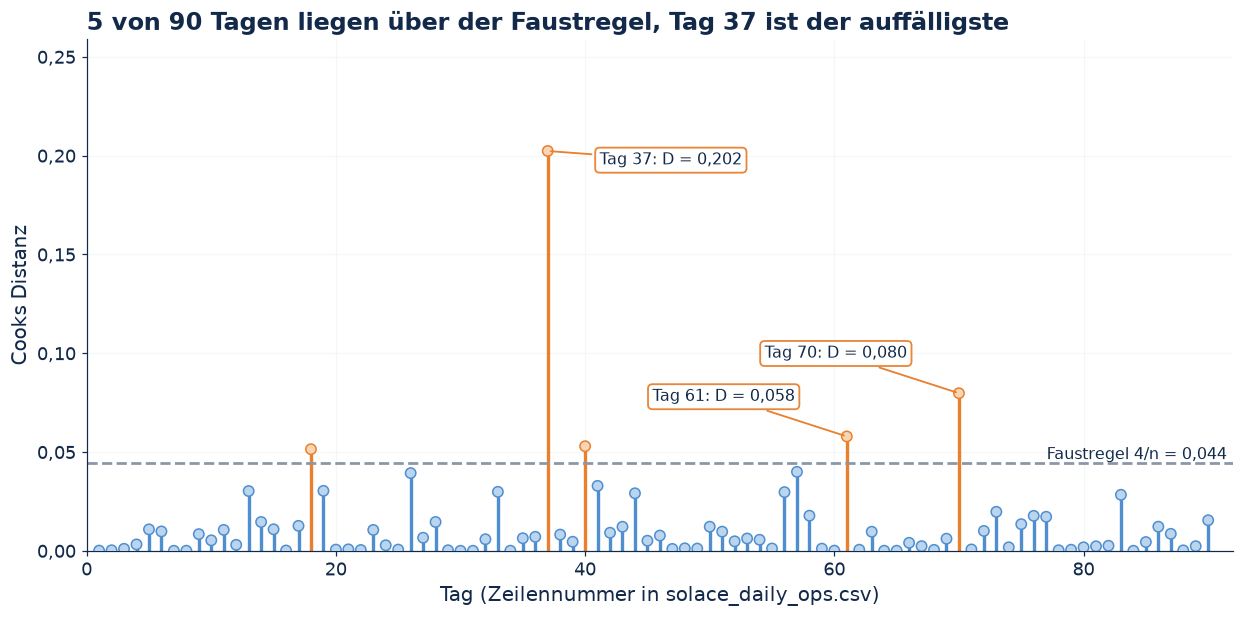

In [89]:
# Zusatz 16a: Einflussreiche Tage im Betriebsdaten-Modell (Hebelwerte und Cooks Distanz)
def zusatz16_einfluss():
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−")
    y = ops_df.wait_time.values; X = np.column_stack([np.ones(len(y))] + [ops_df[c].values.astype(float) for c in OPS_X]); n, k = X.shape
    b = np.linalg.lstsq(X, y, rcond=None)[0]; res = y - X @ b; s2 = res @ res / (n - k); H = np.einsum("ij,jk,ik->i", X, np.linalg.inv(X.T @ X), X)
    cook = res ** 2 / (k * s2) * H / (1 - H) ** 2; sch = 4 / n; auff = np.where(cook > sch)[0]; reihe = np.argsort(-cook)
    print(f"{n} Tage, {k} Koeffizienten. Hebelwert: Mittel {k / n:.3f}, Schwelle 2k/n = {2 * k / n:.3f}, größter Wert {H.max():.3f} (Tag {H.argmax() + 1}), Tage über der Schwelle: {int((H > 2 * k / n).sum())}.")
    print(f"Cooks Distanz: Faustregel 4/n = {sch:.3f}. Tage darüber: {', '.join(f'{i + 1} ({mn(cook[i], 3)})' for i in reihe[:len(auff)])}.")
    print("Zur Einordnung: Cooks Distanz über 1 wäre ein starker Einfluss auf das ganze Modell; der größte Wert ist " + mn(cook.max(), 3) + ".")
    ohne = np.setdiff1d(np.arange(n), auff); b2 = np.linalg.lstsq(X[ohne], y[ohne], rcond=None)[0]
    r2 = lambda Xm, ym, bb: 1 - ((ym - Xm @ bb) ** 2).sum() / ((ym - ym.mean()) ** 2).sum()
    namen = ["Konstante"] + ["Patienten (je Patient)", "Personal (je Person)", "Wochenende"]
    print("\nKoeffizienten mit allen Tagen und ohne die " + str(len(auff)) + " auffälligen Tage:")
    print(pd.DataFrame({"alle 90 Tage": b, f"ohne {len(auff)} Tage": b2}, index=namen).to_string(float_format=lambda v: f"{v:.3f}"))
    print(f"R²: {r2(X, y, b) * 100:.1f} % mit allen Tagen, {r2(X[ohne], y[ohne], b2) * 100:.1f} % ohne die {len(auff)} Tage.")
    lo = np.array([np.linalg.lstsq(np.delete(X, i, 0), np.delete(y, i), rcond=None)[0] for i in range(n)])
    print(f"Lässt man jeden einzelnen Tag einmal weg (90 Modelle), liegt der Personal-Koeffizient zwischen {mn(lo[:, 2].min(), 3)} und {mn(lo[:, 2].max(), 3)} (alle Tage: {mn(b[2], 3)}), das Vorzeichen bleibt.")
    fig, ax = plt.subplots(figsize=(11.5, 5.8)); tage = np.arange(1, n + 1); farbe = [PASTEL["rosa"] if c > sch else PASTEL["blau"] for c in cook]
    ax.vlines(tage, 0, cook, colors=[LINE["rosa"] if c > sch else LINE["blau"] for c in cook], lw=2.2, zorder=2); ax.scatter(tage, cook, s=46, c=farbe, edgecolor=[LINE["rosa"] if c > sch else LINE["blau"] for c in cook], zorder=3)
    ax.axhline(sch, color=LINE["grau"], ls="--", lw=1.8); ax.text(n + 1.5, sch, f"Faustregel 4/n = {mn(sch, 3)}", va="bottom", ha="right", fontsize=10.5)
    ym = cook.max(); ax.set_ylim(0, ym * 1.28); ax.set_xlim(0, n + 2)
    for j, i in enumerate(reihe[:3]):
        tag(ax, i + 1, cook[i], f"Tag {i + 1}: D = {mn(cook[i], 3)}", LINE["rosa"], ox=(34 if i < 60 else -34), oy=(-6 if j == 0 else 26), ha=("left" if i < 60 else "right"), fs=10.5)
    ax.set_xlabel("Tag (Zeilennummer in solace_daily_ops.csv)"); ax.set_ylabel("Cooks Distanz")
    ax.set_title(f"{len(auff)} von {n} Tagen liegen über der Faustregel, Tag {reihe[0] + 1} ist der auffälligste", loc="left"); plt.tight_layout(); show()
    return cook, H

z16a = zusatz16_einfluss()

**Aussage:** Fünf von 90 Tagen liegen über der Faustregel 4/n = 0,044, Tag 37 ist mit D = 0,202 der auffälligste und liegt weit unter 1, und lässt man jeden Tag einmal weg, bleibt der Personal-Koeffizient zwischen −1,35 und −1,09.

**Einordnung:**
- **Hebel:** Tag 37 hat auch den größten Hebelwert (0,113 bei einer Schwelle von 0,089), insgesamt liegen zwei Tage darüber. Tag 37 war schon in Zusatz 10 der auffälligste Tag.
- **Ohne die fünf Tage:** Patienten 0,48 (vorher 0,50), Personal −0,96 (vorher −1,28), Wochenende 1,95 (vorher 2,30), R² 73,8 % (vorher 66,7 %). Vorzeichen und Rangfolge bleiben, der Personal-Effekt wird etwa ein Viertel kleiner.
- **Vorsicht bei der Lesart:** Wer Tage weglässt, weil sie schlecht passen, erhöht R² fast automatisch. Das ist eine Empfindlichkeitsprüfung, kein besseres Modell. Ich behalte alle 90 Tage.
- **Fazit:** Das Modell steht und fällt nicht mit einzelnen Tagen, die genaue Größe des Personal-Effekts hängt aber etwas an ihnen.

**16b: Dieselben Koeffizienten, drei Arten von Intervallen.** Das klassische t-Intervall setzt gleich streuende, annähernd normalverteilte Restfehler voraus (in Zusatz 7 geprüft). Zwei Gegenproben: *Robuste Standardfehler (HC3)* kommen ohne gleiche Streuung aus, der *Bootstrap* zieht 5.000-mal 90 Tage mit Zurücklegen und liest das Intervall aus den Ergebnissen ab.

Klassisch: t-Intervall mit gleicher Streuung aller Tage. HC3: robuste Standardfehler, die ungleiche Streuung und einzelne Tage berücksichtigen. Bootstrap: 5 000 Ziehungen von 90 Tagen mit Zurücklegen, 2,5- und 97,5-%-Perzentil.
                   Koeffizient  Schätzung  klassisch u.  klassisch o.  HC3 u.  HC3 o.  Bootstrap u.  Bootstrap o.
    Patienten (Min je Patient)       0,50          0,40          0,60    0,41    0,60          0,41          0,59
      Personal (Min je Person)      -1,28         -1,78         -0,77   -1,89   -0,67         -1,83         -0,71
Wochenende (Min gegen Werktag)       2,30          1,37          3,22    1,30    3,30          1,34          3,25
Breite des Intervalls für Personal: klassisch 1,01, HC3 1,22, Bootstrap 1,12 Minuten.


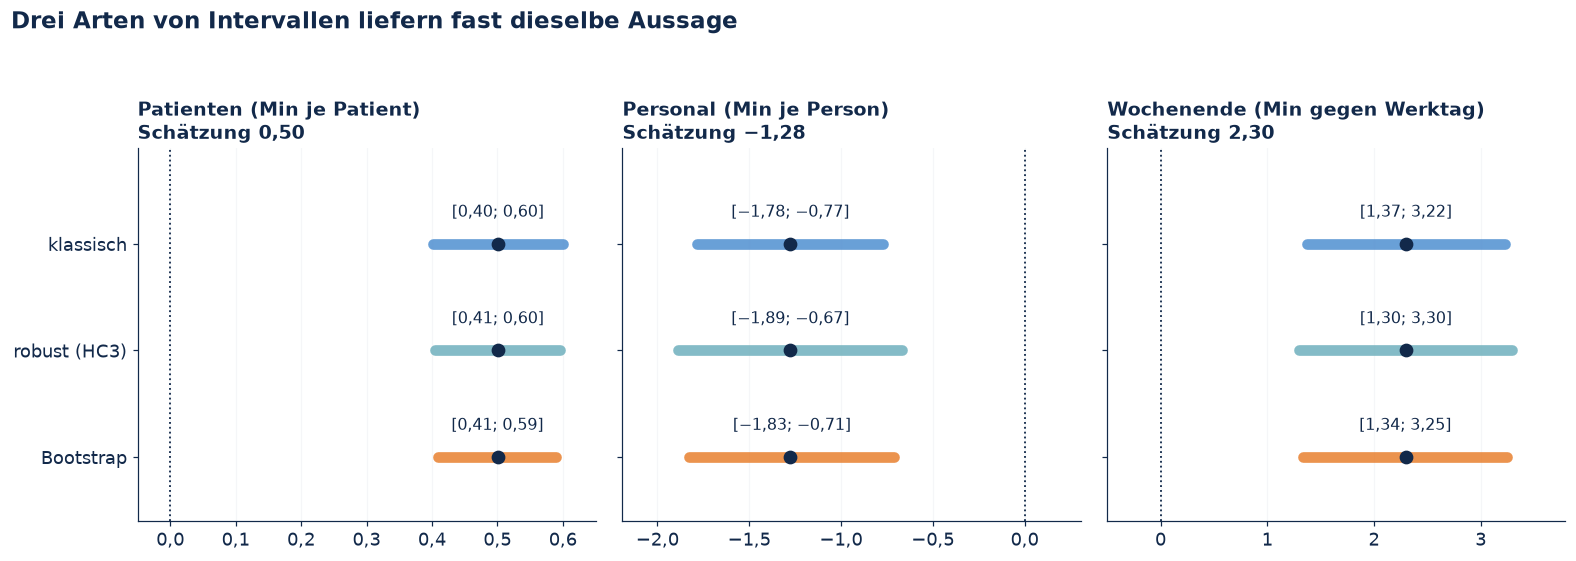

In [90]:
# Zusatz 16b: Dieselben Koeffizienten mit drei Arten von Intervallen (klassisch, robust nach HC3, Bootstrap)
def zusatz16_intervalle(wiederholungen=5000):
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−").replace(".", ",")
    y = ops_df.wait_time.values; X = np.column_stack([np.ones(len(y))] + [ops_df[c].values.astype(float) for c in OPS_X]); n, k = X.shape
    b = np.linalg.lstsq(X, y, rcond=None)[0]; res = y - X @ b; s2 = res @ res / (n - k); XtXi = np.linalg.inv(X.T @ X); H = np.einsum("ij,jk,ik->i", X, XtXi, X)
    tq = stats.t.ppf(.975, n - k); se_k = np.sqrt(np.diag(s2 * XtXi)); V3 = XtXi @ (X.T * (res / (1 - H)) ** 2) @ X @ XtXi; se_3 = np.sqrt(np.diag(V3))
    rg = np.random.default_rng(SEED); B = np.empty((wiederholungen, k))
    for i in range(wiederholungen):
        ix = rg.integers(0, n, n); B[i] = np.linalg.lstsq(X[ix], y[ix], rcond=None)[0]
    bl, bu = np.percentile(B, [2.5, 97.5], axis=0)
    namen = ["Patienten (Min je Patient)", "Personal (Min je Person)", "Wochenende (Min gegen Werktag)"]; zeilen = []
    for j in (1, 2, 3):
        zeilen.append([namen[j - 1], b[j], b[j] - tq * se_k[j], b[j] + tq * se_k[j], b[j] - tq * se_3[j], b[j] + tq * se_3[j], bl[j], bu[j]])
    tab = pd.DataFrame(zeilen, columns=["Koeffizient", "Schätzung", "klassisch u.", "klassisch o.", "HC3 u.", "HC3 o.", "Bootstrap u.", "Bootstrap o."])
    print(f"Klassisch: t-Intervall mit gleicher Streuung aller Tage. HC3: robuste Standardfehler, die ungleiche Streuung und einzelne Tage berücksichtigen. Bootstrap: {tsd(wiederholungen)} Ziehungen von 90 Tagen mit Zurücklegen, 2,5- und 97,5-%-Perzentil.")
    print(tab.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
    print("Breite des Intervalls für Personal: klassisch " + mn(2 * tq * se_k[2]) + ", HC3 " + mn(2 * tq * se_3[2]) + ", Bootstrap " + mn(bu[2] - bl[2]) + " Minuten.")
    fig, axs = plt.subplots(1, 3, figsize=(14.5, 5.2)); meth = [("klassisch", "blau"), ("robust (HC3)", "pfirsich"), ("Bootstrap", "rosa")]
    for a_, j in zip(axs, (0, 1, 2)):
        z = zeilen[j]; ivs = [(z[2], z[3]), (z[4], z[5]), (z[6], z[7])]; lo_, hi_ = min(v[0] for v in ivs), max(v[1] for v in ivs); br = hi_ - lo_
        for r_, ((u, o), (nm, c)) in enumerate(zip(ivs, meth)):
            yy = 2 - r_; a_.plot([u, o], [yy, yy], color=LINE[c], lw=7, solid_capstyle="round", alpha=.85); a_.plot(z[1], yy, "o", color=INK, ms=8, zorder=4)
            a_.text((u + o) / 2, yy + .22, f"[{mn(u)}; {mn(o)}]", ha="center", va="bottom", fontsize=10.3)
        a_.axvline(0, color=INK, lw=1.2, ls=":"); a_.set_yticks([2, 1, 0]); a_.set_yticklabels([m[0] for m in meth] if j == 0 else ["", "", ""]); a_.set_ylim(-.6, 2.9)
        a_.set_xlim(min(lo_, 0) - br * .25, max(hi_, 0) + br * .25); a_.set_title(f"{z[0]}\nSchätzung {mn(z[1])}", fontsize=12.2, loc="left"); a_.grid(axis="y", visible=False)
    fig.suptitle("Drei Arten von Intervallen liefern fast dieselbe Aussage", x=.012, ha="left", fontsize=15, fontweight="bold"); plt.tight_layout(rect=(0, 0, 1, .94)); show()
    return tab

z16b = zusatz16_intervalle()

**Aussage:** Alle drei Intervalle sagen dasselbe: Der Personal-Koeffizient liegt klassisch bei [−1,78; −0,77], robust bei [−1,89; −0,67] und per Bootstrap bei [−1,83; −0,71] Minuten je Person, und keines schließt 0 ein.

**Einordnung:**
- **Breite:** Beim Personal sind die Gegenproben 11 bis 21 % breiter (Breite 1,01 klassisch, 1,12 Bootstrap, 1,22 HC3 Minuten). Bei Patienten und Wochenende sind die Unterschiede klein.
- **Passend zu Zusatz 7:** Der Breusch-Pagan-Test (p = 0,78) hatte keine ungleiche Streuung gezeigt, entsprechend wenig ändert sich.
- **Was es heißt:** Das Ergebnis hängt nicht an den Annahmen des klassischen Intervalls. Die Richtung ist gesichert, die Größe des Personal-Effekts etwas unschärfer als das klassische Intervall vermuten lässt.

**16c: Funktionsform.** Das Modell nimmt an, dass jede Variable gradlinig wirkt und sich die Wirkungen addieren. Ich prüfe vier Erweiterungen jeweils mit einem F-Test gegen das Ausgangsmodell: Wechselwirkungen (wirkt ein zusätzlicher Patient anders, wenn mehr Personal da ist oder am Wochenende?) und Krümmung (Patienten², Personal²). Außerdem ersetze ich Patienten und Personal durch ein einziges Auslastungsmaß (Patienten je Person) und rechne einmal mit der logarithmierten Wartezeit.

                                          Modell  angepasstes R² (%)    F    p
Ausgangsmodell (Patienten, Personal, Wochenende)               65,56  NaN  NaN
                          + Patienten × Personal               65,37 0,53 0,47
                        + Patienten × Wochenende               65,35 0,50 0,48
                         + Patienten² (Krümmung)               65,23 0,20 0,65
                          + Personal² (Krümmung)               65,46 0,77 0,38
  Auslastung (Patienten ÷ Personal) statt beider               58,56  NaN  NaN

Logarithmierte Wartezeit (Modell mit allen drei Variablen): R² = 66,2 % auf der Log-Skala (nicht direkt mit den obigen Werten vergleichbar). Koeffizient Wochenende 0,209, das entspricht etwa +23 % Wartezeit
Auslastung: Je zusätzlichem Patienten je Person steigt die erwartete Wartezeit um 4,40 Minuten (Modell mit Wochenende).


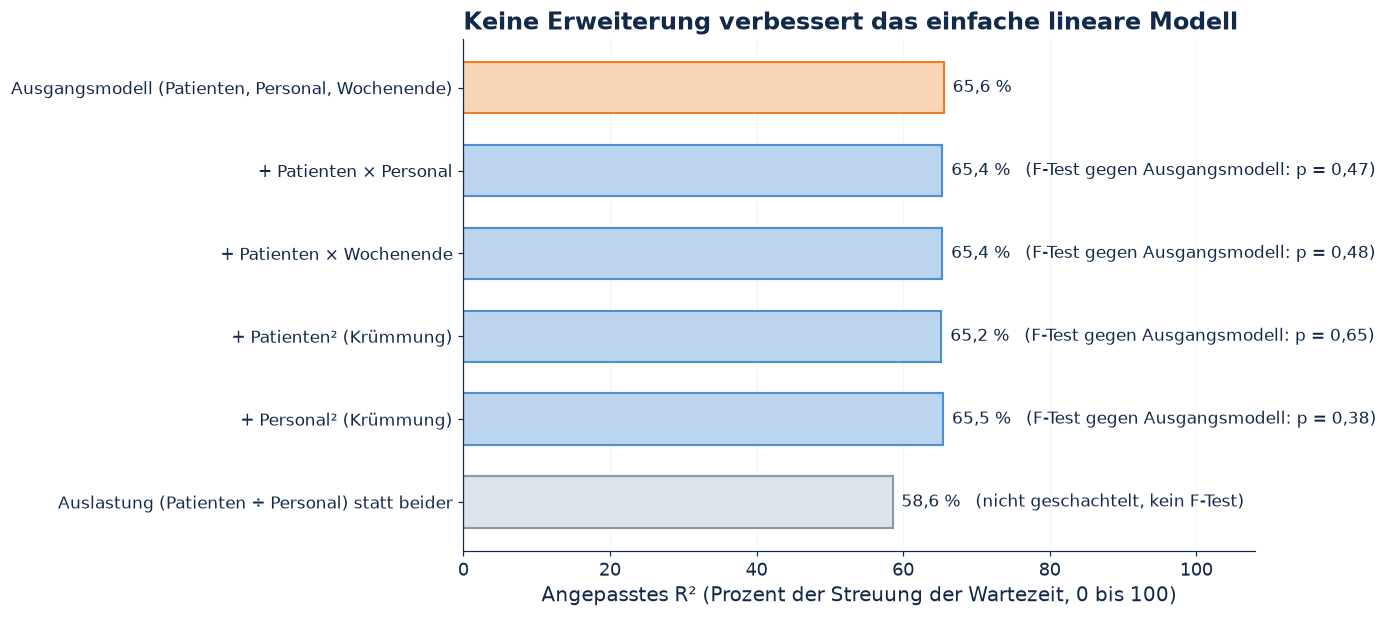

In [91]:
# Zusatz 16c: Ist die Annahme "gerade Linien, Wirkungen addieren sich" haltbar? Wechselwirkungen, Krümmung, Auslastungsmaß
def zusatz16_funktionsform():
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−")
    y = ops_df.wait_time.values; T = ops_df.patients_scheduled.values.astype(float); S = ops_df.staff_on_duty.values.astype(float); W = ops_df.is_weekend.values.astype(float); n = len(y)
    X0 = np.column_stack([np.ones(n), T, S, W]); sst = ((y - y.mean()) ** 2).sum()
    def fit(X):
        b = np.linalg.lstsq(X, y, rcond=None)[0]; r = y - X @ b; return r @ r, X.shape[1], b
    rss0, k0, _ = fit(X0); r2a = lambda rss, k: 1 - rss / (n - k) / (sst / (n - 1))
    kandidaten = [("Patienten × Personal", T * S, "Wirkung der Patientenzahl hängt vom Personal ab"), ("Patienten × Wochenende", T * W, "Wirkung der Patientenzahl hängt vom Wochentag ab"),
                  ("Patienten² (Krümmung)", T ** 2, "Wartezeit steigt schneller als linear"), ("Personal² (Krümmung)", S ** 2, "abnehmender Nutzen zusätzlichen Personals")]
    zeilen = [("Ausgangsmodell (Patienten, Personal, Wochenende)", r2a(rss0, k0) * 100, None, None)]
    for nm, extra, _ in kandidaten:
        rss1, k1, bb = fit(np.column_stack([X0, extra])); F = (rss0 - rss1) / (k1 - k0) / (rss1 / (n - k1)); zeilen.append((f"+ {nm}", r2a(rss1, k1) * 100, F, stats.f.sf(F, 1, n - k1)))
    Xa = np.column_stack([np.ones(n), T / S, W]); rssa, ka, ba = fit(Xa); zeilen.append(("Auslastung (Patienten ÷ Personal) statt beider", r2a(rssa, ka) * 100, None, None))
    ly = np.log(y); bl = np.linalg.lstsq(X0, ly, rcond=None)[0]; rl = ly - X0 @ bl; r2log = 1 - rl @ rl / ((ly - ly.mean()) ** 2).sum()
    tab = pd.DataFrame(zeilen, columns=["Modell", "angepasstes R² (%)", "F", "p"])
    print(tab.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
    print(f"\nLogarithmierte Wartezeit (Modell mit allen drei Variablen): R² = {r2log * 100:.1f} % auf der Log-Skala (nicht direkt mit den obigen Werten vergleichbar). Koeffizient Wochenende {bl[3]:.3f}, das entspricht etwa +{(np.exp(bl[3]) - 1) * 100:.0f} % Wartezeit")
    print(f"Auslastung: Je zusätzlichem Patienten je Person steigt die erwartete Wartezeit um {mn(ba[1])} Minuten (Modell mit Wochenende).")
    fig, ax = plt.subplots(figsize=(12, 5.8)); werte = [z[1] for z in zeilen]; ypos = np.arange(len(zeilen))[::-1]
    for yy, z in zip(ypos, zeilen):
        c = "rosa" if z[2] is None and yy == ypos[0] else ("grau" if z[2] is None else "blau")
        ax.barh(yy, z[1], .62, color=PASTEL[c], edgecolor=LINE[c], lw=1.4, zorder=2)
        txt = f"{mn(z[1], 1)} %" + (f"   (F-Test gegen Ausgangsmodell: p = {mn(z[3], 2)})" if z[3] is not None else ("   (nicht geschachtelt, kein F-Test)" if yy != ypos[0] else ""))
        ax.text(z[1] + 1.2, yy, txt, va="center", fontsize=10.8)
    ax.set_yticks(ypos); ax.set_yticklabels([z[0] for z in zeilen], fontsize=11); ax.set_xlim(0, 108); ax.set_xlabel("Angepasstes R² (Prozent der Streuung der Wartezeit, 0 bis 100)"); ax.grid(axis="y", visible=False)
    ax.set_title("Keine Erweiterung verbessert das einfache lineare Modell", loc="left"); plt.tight_layout(); show()
    return tab

z16c = zusatz16_funktionsform()

**Aussage:** Keine Erweiterung verbessert das Modell: Das angepasste R² bleibt bei 65,2 bis 65,5 % (Ausgangsmodell 65,6 %), alle F-Tests haben p ≥ 0,38, und das Auslastungsmaß allein erklärt mit 58,6 % weniger.

**Einordnung:**
- **Wechselwirkungen:** Nicht nachweisbar (p = 0,47 und 0,48). Der Effekt zusätzlicher Patienten ist bei unterschiedlichem Personal und am Wochenende ähnlich. Bei 90 Tagen hat der Test für Wechselwirkungen wenig Teststärke, „nicht nachweisbar“ heißt nicht „nicht vorhanden“.
- **Krümmung:** Nicht nachweisbar (p = 0,65 und 0,38).
- **Auslastung:** Das Maß „Patienten je Person“ passt schlechter als beide Variablen getrennt. Ein zusätzlicher Patient und eine fehlende Person wirken also nicht im Verhältnis 1 zu 1 (0,50 gegen −1,28 Minuten).
- **Log-Skala:** Mit der logarithmierten Wartezeit liegt R² bei 66,2 %, das Wochenende bedeutet dort etwa +23 % statt +2,3 Minuten. Die Skala ändert die Lesart, nicht die Richtung.
- **Fazit:** Das einfache lineare Modell reicht. Zusätzliche Terme würden bei 90 Tagen vor allem Zufall anpassen (vergleiche die Zufallsspalten in Zusatz 10).

### Zusatz 17: Wie viel Personal braucht ein Tag mit n Patienten? (Kapazitätsplanung)

Zusatz 7 und 12 haben gezeigt, was das Modell vorhersagt. Für die Betriebsleitung zählt die Umkehrung: **Bei wie viel Personal wird das Serviceversprechen von 15 Minuten an einem Tag mit n Patienten mit hoher Wahrscheinlichkeit gehalten?** Ich nutze Modell 3 und das Vorhersageintervall aus Zusatz 12b (t-Verteilung des Vorhersagefehlers) und berechne für jede Kombination aus Patientenzahl, Personal und Tagesart die Wahrscheinlichkeit, dass die Wartezeit des Tages über 15 Minuten liegt. Die Wartezeit der Betriebsdaten ist ein Tageswert; die Wahrscheinlichkeit gilt für den Tageswert, nicht für einzelne Patienten.

Beobachtungsbereich der 90 Tage: Patienten 20 bis 45, Personal 5 bis 11. Außerhalb davon (mehr als 45 Patienten, mehr als 11 Personen) wäre jede Aussage eine Extrapolation.

Kleinste Personalzahl, bei der die Wahrscheinlichkeit einer Wartezeit über 15 Minuten höchstens 25 % bzw. 10 % beträgt:
       Tag  Patienten         Personal für höchstens 25 %                      Personal für höchstens 10 %
   Werktag         25                                   5                                                5
   Werktag         30                                   6                                                7
   Werktag         35                                   8                                                9
   Werktag         40                                  10                                               11
   Werktag         45 12 oder mehr (über der Beobachtung)              12 oder mehr (über der Beobachtung)
Wochenende         25                                   6       

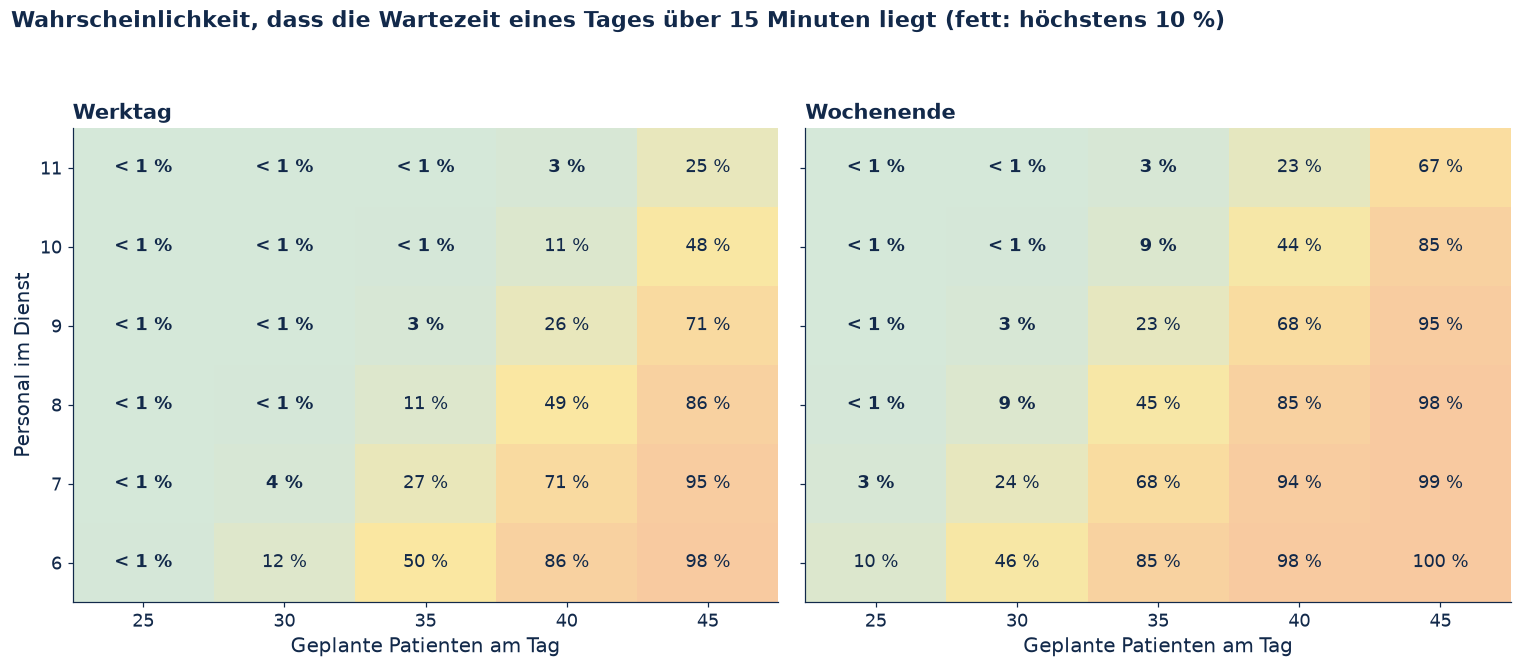

In [92]:
# Zusatz 17: Kapazitätsplanung. Wie viel Personal braucht ein Tag mit n Patienten? (Modell 3, Vorhersageintervall)
def zusatz17_kapazitaet():
    mn = lambda x, nd=0: f"{x:.{nd}f}".replace("-", "−")
    patienten = [25, 30, 35, 40, 45]; personal = list(range(6, 12))
    def p15(pat, per, we):
        a, _, _, se, dfr = pi_modell3(pat, per, we); return (1 - stats.t.cdf((15 - a) / se, dfr)) * 100
    print(f"Beobachtungsbereich der 90 Tage: Patienten {int(ops_df.patients_scheduled.min())} bis {int(ops_df.patients_scheduled.max())}, Personal {int(ops_df.staff_on_duty.min())} bis {int(ops_df.staff_on_duty.max())}. Außerhalb davon (mehr als 45 Patienten, mehr als 11 Personen) wäre jede Aussage eine Extrapolation.")
    zeilen = []
    for we, nm in ((0, "Werktag"), (1, "Wochenende")):
        for pat in patienten:
            mind10 = next((p for p in range(5, 15) if p15(pat, p, we) <= 10), None); mind25 = next((p for p in range(5, 15) if p15(pat, p, we) <= 25), None)
            zeilen.append((nm, pat, mind25, mind10))
    fmt = lambda v: ("auch mit 14 nicht erreicht (außerhalb der Daten)" if v is None else ("12 oder mehr (über der Beobachtung)" if v > 11 else str(v)))
    print("\nKleinste Personalzahl, bei der die Wahrscheinlichkeit einer Wartezeit über 15 Minuten höchstens 25 % bzw. 10 % beträgt:")
    print(pd.DataFrame([(a, b, fmt(c), fmt(d)) for a, b, c, d in zeilen], columns=["Tag", "Patienten", "Personal für höchstens 25 %", "Personal für höchstens 10 %"]).to_string(index=False))
    cm = LinearSegmentedColormap.from_list("kap", ["#D5E8D9", "#FBE7A1", "#F8C9A0"]); fig, axs = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True)
    for a_, we, nm in zip(axs, (0, 1), ("Werktag", "Wochenende")):
        M = np.array([[p15(pat, per, we) for pat in patienten] for per in personal]); a_.imshow(M, cmap=cm, vmin=0, vmax=100, aspect="auto", origin="lower")
        for i, per in enumerate(personal):
            for j, pat in enumerate(patienten):
                v = M[i, j]; a_.text(j, i, f"{v:.0f} %" if v >= 1 else "< 1 %", ha="center", va="center", fontsize=11.5, fontweight=("bold" if v <= 10 else "normal"))
        a_.set_xticks(range(len(patienten))); a_.set_xticklabels(patienten); a_.set_yticks(range(len(personal))); a_.set_yticklabels(personal); a_.set_xlabel("Geplante Patienten am Tag"); a_.set_title(nm, loc="left", fontsize=14); a_.grid(False)
    axs[0].set_ylabel("Personal im Dienst")
    fig.suptitle("Wahrscheinlichkeit, dass die Wartezeit eines Tages über 15 Minuten liegt (fett: höchstens 10 %)", x=.012, ha="left", fontsize=14.5, fontweight="bold"); plt.tight_layout(rect=(0, 0, 1, .94)); show()
    return zeilen

z17 = zusatz17_kapazitaet()

**Aussage:** Ein Werktag mit 35 Patienten braucht mindestens 8 Personen, damit die Wartezeit des Tages mit höchstens 25 % Wahrscheinlichkeit über 15 Minuten liegt (9 für höchstens 10 %), bei 40 Patienten sind es 10 und 11, und 45 Patienten sind mit den bisher beobachteten Personalzahlen nicht unter 25 % zu bringen.

**Einordnung:**
- **Wochenende:** Gleiche Patientenzahl, ein bis zwei Personen mehr (35 Patienten: 9 für höchstens 25 %, 10 für höchstens 10 %).
- **Beobachtungsbereich:** Die Daten decken 20 bis 45 Patienten und 5 bis 11 Personen ab. Alles darüber (zum Beispiel 12 Personen bei 45 Patienten) wäre eine Extrapolation und ist in der Tabelle nur als „12 oder mehr“ vermerkt.
- **Wie man es lesen darf:** Als Planungshilfe unter den Annahmen des Modells. Der Personal-Koeffizient gilt bei gleicher Terminzahl und beweist keine Wirkung (Zusatz 15). Personalkosten liegen nicht vor, ein Kostenvergleich ist deshalb nicht möglich.
- **Grenzen:** Das Vorhersageintervall setzt annähernd normalverteilte Restfehler voraus (Zusatz 7, 16b). Die Betriebsdaten haben keine Standortspalte, für einzelne Standorte lässt sich daraus nichts ablesen.

### Zusatz 18: Zufriedenheit mit mehreren Einflussgrößen und der Weg über die Wartezeit

Zusatz 4 hat die Zufriedenheit nur gegen die Wartezeit gerechnet (R² 15,1 %). Zwei Fragen blieben offen. **18a:** Bleibt der Zusammenhang, wenn Standort, Terminart, Versicherung und Wochenende gleichzeitig berücksichtigt werden? **18b:** Riverside-Patienten sind unzufriedener (3.8). Liegt das an der Wartezeit oder an etwas anderem in Riverside? Das ist die **Mediation** aus Zusatz 15 mit echten Daten: Standort → Wartezeit → Zufriedenheit. Der **Gesamteffekt** ist der Unterschied zwischen den Standorten. Der **direkte Effekt** ist der Rest, der bei gleicher Wartezeit bleibt. Der **indirekte Effekt** ist der Teil über die Wartezeit, das Produkt aus Pfad a (Standort → Wartezeit) und Pfad b (Wartezeit → Zufriedenheit). Die Intervalle stammen aus 5.000 Bootstrap-Ziehungen der Besuche.

Zufriedenheit (1 bis 5) erklärt durch Wartezeit, Standort, Terminart, Versicherung und Wochenende; n = 1077 Besuche mit Bewertung, R² = 15,7 % (angepasst 14,8 %).
                                        Koeffizient  untere  obere       p
Wartezeit (je 10 Min)                        -0,325  -0,377 -0,273 2,0e-32
Terminart: Follow-up (gegen Checkup)         -0,046  -0,147  0,055   0,371
Terminart: Specialist (gegen Checkup)         0,005  -0,137  0,147   0,944
Terminart: Urgent (gegen Checkup)            -0,021  -0,149  0,108   0,753
Standort: Eastview (gegen Downtown)           0,013  -0,110  0,136   0,836
Standort: Northgate (gegen Downtown)         -0,042  -0,158  0,073   0,473
Standort: Riverside (gegen Downtown)         -0,060  -0,181  0,062   0,335
Versicherung: Medicaid (gegen Private)        0,084  -0,040  0,208   0,186
Versicherung: Medicare (gegen Private)        0,117   0,010  0,224   0,032
Versicherung: Self-pay (gegen Private)        0,054  -0,071  0,178   0,399
Wochenende (

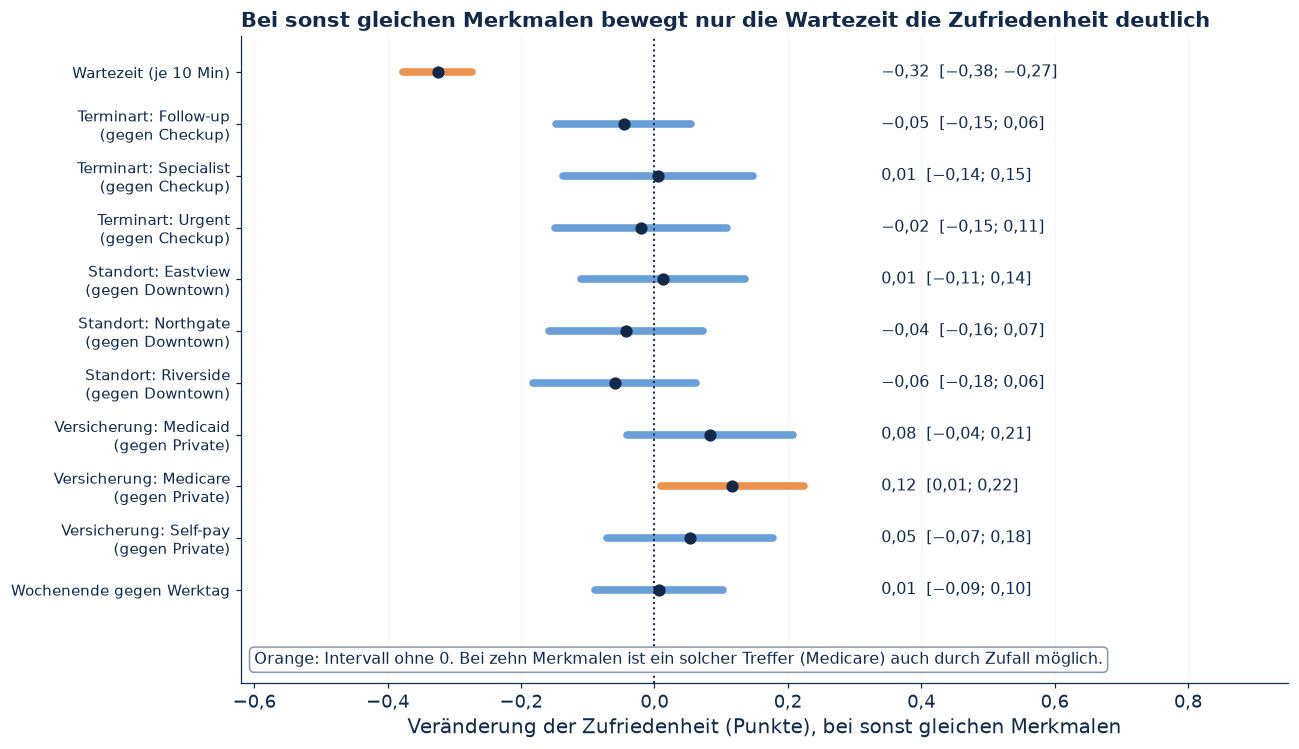


Mediation, Riverside gegen Downtown (n = 641 Besuche mit Bewertung, 5 000 Bootstrap-Ziehungen):
Pfad a (Riverside → Wartezeit): +8,61 Min. Pfad b (Wartezeit → Zufriedenheit, bei gleichem Standort): −0,0307 Punkte je Minute.
Gesamteffekt Riverside auf Zufriedenheit: −0,34 [−0,46; −0,22]. Direkter Effekt (Wartezeit konstant): −0,08 [−0,20; 0,05]. Indirekt über die Wartezeit (a × b): −0,26 [−0,34; −0,20].
Anteil des Gesamteffekts, der über die Wartezeit läuft: 77 % [53; 119] %.


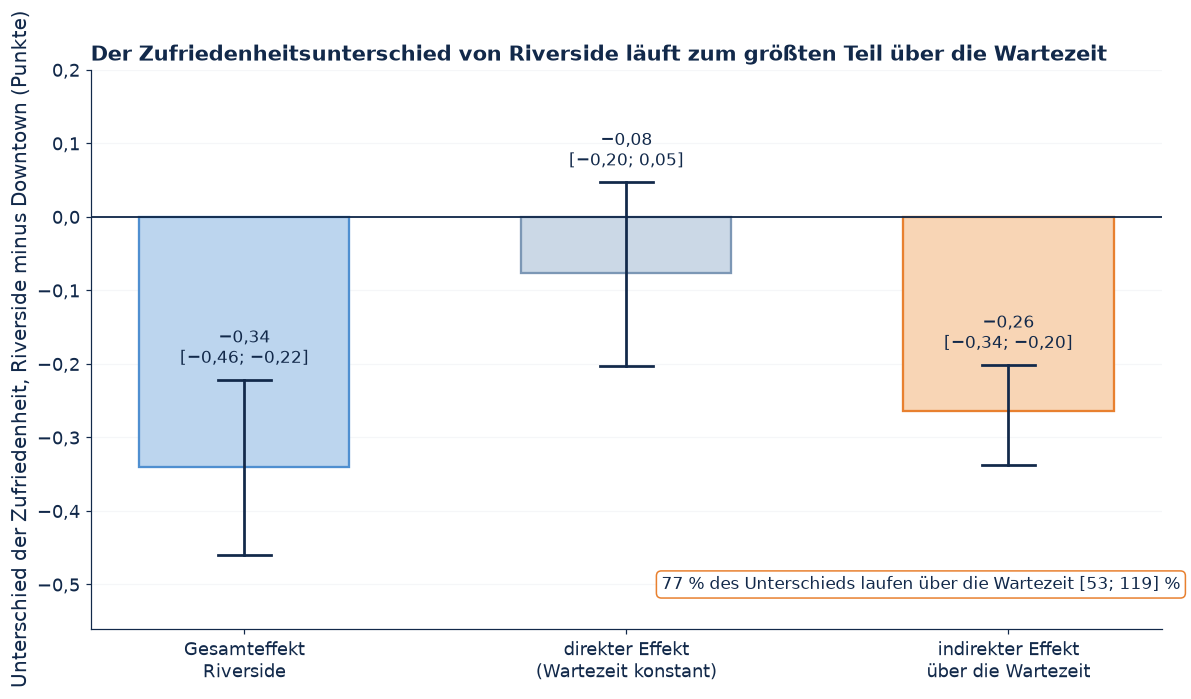

In [93]:
# Zusatz 18a: Zufriedenheit mit mehreren Einflussgrößen gleichzeitig (Besuchsdaten); 18b: Wie viel vom Standortunterschied läuft über die Wartezeit?
def zusatz18_modell():
    mn = lambda x, nd=2: f"{x:.{nd}f}".replace("-", "−")
    s = df.dropna(subset=["patient_satisfaction"]).copy(); sp = design13(s); namen = ["Wartezeit (je 10 Min)"] + list(sp)
    X = np.column_stack([s.wait_time_min.values / 10] + [sp[k] for k in sp]); tab, r2, r2a, n = ols_klein(s.patient_satisfaction.values, X, namen)
    print(f"Zufriedenheit (1 bis 5) erklärt durch Wartezeit, Standort, Terminart, Versicherung und Wochenende; n = {n} Besuche mit Bewertung, R² = {r2 * 100:.1f} % (angepasst {r2a * 100:.1f} %).")
    print(tab.drop(index="Konstante").to_string(float_format=lambda v: f"{v:.3f}" if abs(v) >= 1e-3 else f"{v:.1e}"))
    t2 = tab.drop(index="Konstante").iloc[::-1]; fig, ax = plt.subplots(figsize=(12, 7)); ypos = np.arange(len(t2))
    for yy, (k, r) in zip(ypos, t2.iterrows()):
        sig = r.untere > 0 or r.obere < 0; c = "rosa" if sig else "blau"
        ax.plot([r.untere, r.obere], [yy, yy], color=LINE[c], lw=5, solid_capstyle="round", alpha=.85); ax.plot(r.Koeffizient, yy, "o", color=INK, ms=7, zorder=4)
        ax.text(.34, yy, f"{mn(r.Koeffizient)}  [{mn(r.untere)}; {mn(r.obere)}]", va="center", fontsize=10.3)
    ax.axvline(0, color=INK, lw=1.3, ls=":"); ax.set_yticks(ypos); ax.set_yticklabels([k.replace(" (gegen ", "\n(gegen ").replace("Wochenende (Sa/So) gegen Werktag", "Wochenende gegen Werktag") for k in t2.index], fontsize=10); ax.set_xlim(-.62, .95); ax.set_ylim(-1.8, len(t2) - .3)
    ax.set_xlabel("Veränderung der Zufriedenheit (Punkte), bei sonst gleichen Merkmalen"); ax.grid(axis="y", visible=False)
    ax.text(-.6, -1.35, "Orange: Intervall ohne 0. Bei zehn Merkmalen ist ein solcher Treffer (Medicare) auch durch Zufall möglich.", fontsize=10.3, va="center", ha="left", bbox=dict(boxstyle="round,pad=.3", fc="white", ec=LINE["grau"])); ax.set_title("Bei sonst gleichen Merkmalen bewegt nur die Wartezeit die Zufriedenheit deutlich", loc="left", fontsize=13.5); plt.tight_layout(); show()
    # 18b: Mediation Riverside (gegen Downtown) -> Wartezeit -> Zufriedenheit
    rv = s[s.clinic_site.isin(["Riverside", "Downtown"])]; R = (rv.clinic_site == "Riverside").astype(float).values; w = rv.wait_time_min.values; z = rv.patient_satisfaction.values
    def pfade(R, w, z):
        a = np.polyfit(R, w, 1)[0]; Xd = np.column_stack([np.ones(len(z)), R, w]); bd = np.linalg.lstsq(Xd, z, rcond=None)[0]; tot = np.polyfit(R, z, 1)[0]
        return tot, bd[1], a * bd[2], a, bd[2]
    tot, direkt, indirekt, a_, b_ = pfade(R, w, z); rg = np.random.default_rng(SEED); B = np.array([pfade(R[i], w[i], z[i]) for i in (rg.integers(0, len(z), len(z)) for _ in range(5000))])
    ci = np.percentile(B, [2.5, 97.5], axis=0); anteil = B[:, 2] / B[:, 0]; ai = np.percentile(anteil, [2.5, 97.5])
    print(f"\nMediation, Riverside gegen Downtown (n = {len(z)} Besuche mit Bewertung, {tsd(5000)} Bootstrap-Ziehungen):")
    print(f"Pfad a (Riverside → Wartezeit): +{mn(a_)} Min. Pfad b (Wartezeit → Zufriedenheit, bei gleichem Standort): {mn(b_, 4)} Punkte je Minute.")
    print(f"Gesamteffekt Riverside auf Zufriedenheit: {mn(tot)} [{mn(ci[0, 0])}; {mn(ci[1, 0])}]. Direkter Effekt (Wartezeit konstant): {mn(direkt)} [{mn(ci[0, 1])}; {mn(ci[1, 1])}]. Indirekt über die Wartezeit (a × b): {mn(indirekt)} [{mn(ci[0, 2])}; {mn(ci[1, 2])}].")
    print(f"Anteil des Gesamteffekts, der über die Wartezeit läuft: {indirekt / tot * 100:.0f} % [{ai[0] * 100:.0f}; {ai[1] * 100:.0f}] %.")
    fig, ax = plt.subplots(figsize=(11, 6.2)); werte = [("Gesamteffekt\nRiverside", tot, ci[0, 0], ci[1, 0], "blau"), ("direkter Effekt\n(Wartezeit konstant)", direkt, ci[0, 1], ci[1, 1], "gruen"), ("indirekter Effekt\nüber die Wartezeit", indirekt, ci[0, 2], ci[1, 2], "rosa")]
    for i, (nm, v, u, o, c) in enumerate(werte):
        ax.bar(i, v, .55, color=PASTEL[c], edgecolor=LINE[c], lw=1.5, zorder=2); ax.plot([i, i], [u, o], color=INK, lw=1.8, zorder=3); ax.plot([i - .07, i + .07], [u] * 2, color=INK, lw=1.8); ax.plot([i - .07, i + .07], [o] * 2, color=INK, lw=1.8)
        ax.text(i, o + .015, f"{mn(v)}\n[{mn(u)}; {mn(o)}]", ha="center", va="bottom", fontsize=11)
    ax.axhline(0, color=INK, lw=1.2); ax.set_xticks(range(3)); ax.set_xticklabels([w_[0] for w_ in werte]); ax.set_ylim(-.56, .2); ax.set_ylabel("Unterschied der Zufriedenheit, Riverside minus Downtown (Punkte)"); ax.grid(axis="x", visible=False)
    ax.text(2.45, -.5, f"{indirekt / tot * 100:.0f} % des Unterschieds laufen über die Wartezeit [{ai[0] * 100:.0f}; {ai[1] * 100:.0f}] %", ha="right", va="center", fontsize=11, bbox=dict(boxstyle="round,pad=.3", fc="white", ec=LINE["rosa"]))
    ax.set_title("Der Zufriedenheitsunterschied von Riverside läuft zum größten Teil über die Wartezeit", loc="left", fontsize=14); plt.tight_layout(); show()
    return tab, (tot, direkt, indirekt, ci, ai)

z18 = zusatz18_modell()

**Aussage:** Bei sonst gleichen Merkmalen sinkt die Zufriedenheit mit jeweils 10 Minuten mehr Wartezeit um 0,32 Punkte [−0,38; −0,27] (einfach gerechnet in Zusatz 4: 0,33), kein anderes Merkmal zeigt einen deutlichen Einfluss, und das Modell erklärt 15,7 % der Streuung.

**Einordnung:**
- **Unverändert:** Der Wert ist fast derselbe wie in Zusatz 4. Standort, Terminart und Versicherung erklären den Zusammenhang zwischen Wartezeit und Zufriedenheit also nicht weg.
- **Medicare:** +0,12 [0,01; 0,22], p = 0,032. Bei zehn Merkmalen ist ein Treffer unter 0,05 auch durch Zufall möglich (wie das Follow-up-Ergebnis in Zusatz 5), ich lese ihn nicht als Befund.
- **Riverside:** Sobald die Wartezeit im Modell ist, liegt der Riverside-Koeffizient bei −0,06 [−0,18; 0,06]. Das ist der Hinweis auf die Mediation in 18b.
- **Grenzen:** R² von 15,7 % heißt, dass der Großteil der Unterschiede in der Zufriedenheit unerklärt bleibt. Zufriedenheit ist eine Rangskala mit fünf Stufen, lineare Regression ist hier eine Näherung (3.8 stützt das Ergebnis mit dem Mann-Whitney-Test und der Rangkorrelation).

**Aussage zu 18b (Mediation):** Der Zufriedenheitsunterschied zwischen Riverside und Downtown beträgt −0,34 Punkte [−0,46; −0,22]; davon laufen −0,26 [−0,34; −0,20] über die Wartezeit, das sind 77 % [53; 119], und der direkte Effekt von −0,08 [−0,20; 0,05] ist von null nicht zu unterscheiden.

**Einordnung:**
- **Rechnung:** Pfad a: Riverside wartet 8,61 Minuten länger. Pfad b: Jede Minute Wartezeit kostet 0,0307 Punkte. Produkt: 8,61 × (−0,0307) = −0,264.
- **Intervall des Anteils:** Es reicht über 100 %, weil der direkte Effekt auch leicht positiv sein könnte. Vorsichtig gelesen: mindestens etwa die Hälfte, wahrscheinlich der größte Teil des Unterschieds läuft über die Wartezeit.
- **Was daraus folgt:** Würde die Wartezeit in Riverside auf das Niveau von Downtown sinken, ließe sich unter diesen Annahmen rechnerisch der größte Teil der Zufriedenheitslücke schließen. Das ist eine Rechnung, keine Prognose.
- **Annahmen:** Die Wartezeit wurde nicht zugeteilt, sondern beobachtet. Merkmale wie Dringlichkeit oder Erwartung könnten Wartezeit und Zufriedenheit zugleich beeinflussen. Die Bootstrap-Intervalle erfassen nur die Stichprobenschwankung, nicht solche Verzerrungen. Ein direkter Effekt „nicht von null zu unterscheiden“ heißt nicht „null“.

## Annahmen und Grenzen im Überblick

Dieser Abschnitt fasst zusammen, wovon die Ergebnisse abhängen (Annahmen) und was sie nicht tragen (Grenzen). Die Prüfungen selbst stehen in den genannten Abschnitten.

### Annahmen der beiden Tests

| Annahme | Gilt für | Wie geprüft | Einordnung |
|---|---|---|---|
| Die Besuche sind voneinander unabhängig | beide Tests | 1.200 Besuche von 1.180 Patienten, 20 Patient-Tage mit zwei Besuchen (siehe 1.4b) | Fast jeder Patient erscheint nur einmal. Eine mögliche Abhängigkeit wurde nicht einzeln durchgerechnet. |
| Die Stichprobenmittelwerte sind näherungsweise normalverteilt (nicht die einzelnen Wartezeiten) | beide Tests | QQ-Plot im Annahmen-Check von Checkpoint 2, Schiefe der Wartezeit 1,29, Bootstrap und Mann-Whitney-Test als Gegenprobe in 3.3 und 3.4 | Die Einzelwerte sind rechtsschief, bei 430 und 286 Besuchen trägt der zentrale Grenzwertsatz. Die Gegenproben bestätigen das Ergebnis. |
| Gleiche Streuung in beiden Gruppen | nur klassischer t-Test | Levene-Test p = 0,175 in 3.2 | Wird nicht vorausgesetzt, weil Welch (`equal_var=False`) verwendet wird. Ein nicht signifikanter Levene-Test beweist keine Gleichheit. |
| Die Wartezeit wird an allen Standorten gleich gemessen | Test 2 | nicht prüfbar, aus dem Log nicht erkennbar | Wird angenommen. Wäre die Messung unterschiedlich, wäre der Unterschied von 8,6 Minuten teilweise ein Messunterschied. |
| Der Beobachtungszeitraum ist repräsentativ | beide Tests | Besuchslog vom 5. Januar bis 5. April 2026, ein Quartal | Aussagen gelten für diesen Zeitraum. Saisonale Schwankungen sind nicht erfasst. |

### Fehler 1. und 2. Art im Überblick

| | Fehler 1. Art (falscher Alarm) | Fehler 2. Art (verpasster Unterschied) |
|---|---|---|
| Test 1: Downtown gegen 15 Minuten | Wir sagen „Versprechen eingehalten“, obwohl die mittlere Wartezeit bei 15 Minuten oder darüber liegt. Die Betriebsleitung würde sich in falscher Sicherheit wiegen. Das Risiko ist durch α = 0,05 auf höchstens 5 % begrenzt. | Das Versprechen gilt tatsächlich, der Test erkennt es nicht. Die Folge wären unnötige Maßnahmen in Downtown. |
| Test 2: Riverside gegen Downtown | Wir behaupten einen Unterschied, den es nicht gibt. Personal würde ohne Bedarf verlegt (Kosten siehe 3.2). | Wir übersehen einen echten Unterschied. Patienten in Riverside warten weiter länger, die Zufriedenheit leidet (Kosten siehe 3.2). |
| Hier | Bei p = 1,35 × 10⁻¹² (Test 1) und p ≈ 10⁻³⁶ (Test 2) praktisch ausgeschlossen. | Der Test erkennt bei 80 % Power Unterschiede ab etwa 1,8 Minuten, der beobachtete Unterschied ist 8,6. |

### Grenzen der Aussagen

- **Ursache offen:** Die Daten zeigen, dass Riverside länger wartet, nicht warum. Dafür bräuchte man Uhrzeit und Personalbesetzung, denn Wochentag und Terminart sind schon geprüft.
- **Beobachtungsdaten:** Die Standorte wurden nicht zufällig zugeteilt. Der Unterschied von 8,6 Minuten ist ein Befund, keine Wirkung einer Maßnahme.
- **Wirkung der SMS unbekannt:** Der Besuchslog enthält keine SMS-Erinnerungen, und der geplante Test kann sie wegen fehlender Zufallszuteilung nicht bewerten.
- **Durchschnitt ist nicht jeder Patient:** In Downtown liegen 27,9 % der Besuche über 15 Minuten, obwohl der Mittelwert darunter liegt.
- **Zeitraum und Standorte:** Vier Standorte, 5. Januar bis 5. April 2026. Über andere Zeiten oder Standorte sagen die Tests nichts.
- **Fehlende Zufriedenheit:** Bei Urgent fehlt die Bewertung in 31,8 % der Besuche, nicht zufällig. Der Zusammenhang zwischen Wartezeit und Zufriedenheit gilt für die Besuche mit Bewertung.
- **Kosten mit zwei Gipfeln:** Median und Mittelwert beschreiben keine der beiden Gruppen. Die Ursache der Gipfel bleibt offen.
- **Dauerwerte:** 14 Werte sehen wie Erfassungsfehler aus. Sie wurden markiert und bei Dauer-Analysen getrennt behandelt, die Ursache ist unbekannt.
- **5-Minuten-Schwelle:** Sie wurde erst nach dem Welch-Test festgelegt und ist keine Vorabfestlegung. Deshalb wurde sie bei 3, 5, 7 und 10 Minuten geprüft.
- **Termindauer (3.7):** Die Daten haben keine Uhrzeit und keine Reihenfolge der Termine im Tag. Dass die Überziehung die Tageswartezeit nicht erklärt, schließt eine Verzögerung einzelner Patienten durch vorherige Termine nicht aus.
- **Zufriedenheit und Mediation (3.8, Zusatz 18):** Beobachtungsdaten, 123 Besuche ohne Bewertung. Der Weg über die Wartezeit setzt voraus, dass keine unbeobachtete Größe Wartezeit und Zufriedenheit zugleich bestimmt.
- **Kapazitätsplanung (Zusatz 17):** Gilt nur im beobachteten Bereich (20 bis 45 Patienten, 5 bis 11 Personen) und für den Tageswert der Wartezeit.


### Fehler 1. und 2. Art im Diagramm

Die blaue Kurve zeigt, welche Differenzen der Wartezeiten zu erwarten wären, wenn es keinen Unterschied gäbe (H₀). Die orange Kurve zeigt dasselbe für einen kleinen echten Unterschied (H₁). Die gestrichelten Linien sind die Grenzen des Tests bei α = 5 %.


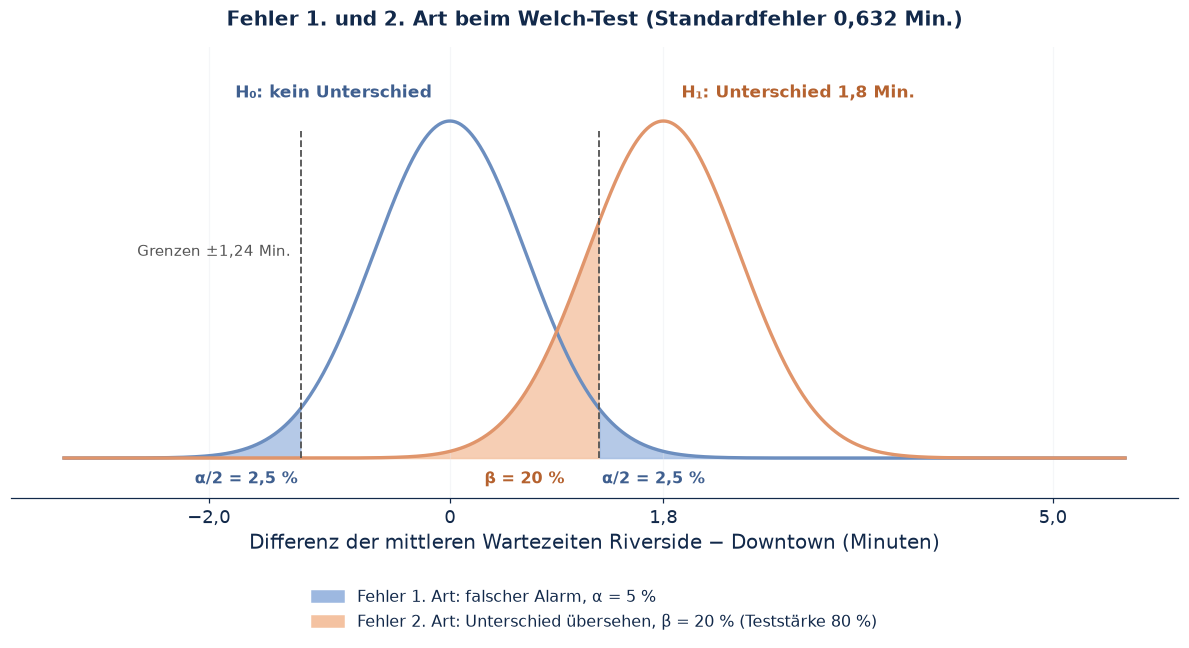

Kleinster nachweisbarer Unterschied bei α = 5 % und 80 % Teststärke: 1,77 Minuten
Beobachtet: 8,58 Minuten, das ist etwa 4,8 mal so groß; dort ist β praktisch 0.


In [94]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def dk(x, nd=1):
    return f"{x:.{nd}f}".replace(".", ",")

alpha, power_ziel = 0.05, 0.80
se2 = 0.632                                   # Standardfehler der Differenz (Welch-Test)
z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power_ziel)
mde = (z_a + z_b) * se2                       # kleinster Unterschied mit 80 % Teststärke
kr = z_a * se2                                # kritische Grenze (zweiseitig, rechts)

fig, ax = plt.subplots(figsize=(11, 6.2))
x = np.linspace(-3.2, 5.6, 1200)
h0, h1 = stats.norm.pdf(x, 0, se2), stats.norm.pdf(x, mde, se2)
ax.plot(x, h0, color="#6C8EBF", lw=2.2)
ax.plot(x, h1, color="#E0956B", lw=2.2)
ax.fill_between(x, h0, where=(x >= kr), color="#9DB8E0", alpha=.75)
ax.fill_between(x, h0, where=(x <= -kr), color="#9DB8E0", alpha=.75)
ax.fill_between(x, h1, where=(x <= kr), color="#F4C2A1", alpha=.8)
ax.vlines([-kr, kr], 0, h0.max() * 0.97, color="#555", ls="--", lw=1.2)
top = h0.max()
ax.set_ylim(-top * .12, top * 1.22)
ax.text(-0.15, top * 1.07, "H₀: kein Unterschied", ha="right", color="#3F5F8F", fontsize=11, fontweight="bold")
ax.text(mde + 0.15, top * 1.07, f"H₁: Unterschied {dk(mde)} Min.", ha="left", color="#B5622F", fontsize=11, fontweight="bold")
ax.text(-kr - .08, top * .6, f"Grenzen ±{dk(kr,2)} Min.", color="#555", fontsize=10, ha="right")
ax.text(kr - .62, -top * .075, f"β = {dk((1-power_ziel)*100,0)} %", color="#B5622F", fontsize=10.5, fontweight="bold", ha="center")
ax.text(kr + .45, -top * .075, f"α/2 = {dk(alpha*50,1)} %", color="#3F5F8F", fontsize=10.5, fontweight="bold", ha="center")
ax.text(-kr - .45, -top * .075, f"α/2 = {dk(alpha*50,1)} %", color="#3F5F8F", fontsize=10.5, fontweight="bold", ha="center")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#9DB8E0", label=f"Fehler 1. Art: falscher Alarm, α = {dk(alpha*100,0)} %"),
                   Patch(color="#F4C2A1", label=f"Fehler 2. Art: Unterschied übersehen, β = {dk((1-power_ziel)*100,0)} % (Teststärke {dk(power_ziel*100,0)} %)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False, fontsize=10.5)
ax.set_xlabel("Differenz der mittleren Wartezeiten Riverside − Downtown (Minuten)")
ax.set_yticks([])
ax.set_xticks([-2, 0, mde, 5])
ax.set_xticklabels(["\u22122,0", "0", dk(mde), dk(5)])
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.set_title("Fehler 1. und 2. Art beim Welch-Test (Standardfehler 0,632 Min.)", fontsize=13, pad=14)
plt.tight_layout()
plt.show()
print(f"Kleinster nachweisbarer Unterschied bei α = 5 % und 80 % Teststärke: {dk(mde,2)} Minuten")
print("Beobachtet: 8,58 Minuten, das ist etwa", dk(8.58 / mde, 1), "mal so groß; dort ist β praktisch 0.")


**Aussage:** Der Welch-Test erkennt einen echten Unterschied von 1,8 Minuten in 80 % der Fälle und übersieht ihn in 20 % (Fehler 2. Art), der beobachtete Unterschied von 8,6 Minuten ist etwa fünfmal so groß, sodass die Gefahr, ihn zu übersehen, praktisch null ist, und ein falscher Alarm (Fehler 1. Art) ist durch α = 5 % begrenzt.


## Formeln im Überblick

Alle Werte stammen aus den Zellen oben (n, Mittelwert, Standardabweichung). Hier steht, wie sie zusammenhängen.

**Test 1: Einseitiger Einstichproben-t-Test (Downtown, H₀: μ ≥ 15)**

- Teststatistik: t = (x̄ − μ₀) / (s / √n) = (12,18 − 15) / 0,392 ≈ −7,20
- Freiheitsgrade: df = n − 1 = 429
- 95-%-Konfidenzintervall des Mittelwerts: x̄ ± t_krit · s / √n = [11,4; 12,9]

**Test 2: Welch-t-Test (Riverside gegen Downtown, zweiseitig)**

- Differenz der Mittelwerte: 8,58 Minuten
- Standardfehler der Differenz: √(s₁²/n₁ + s₂²/n₂) ≈ 0,632
- Teststatistik: t = Differenz / Standardfehler = 8,577 / 0,632 ≈ 13,56
- Freiheitsgrade nach Welch: df ≈ 596,8 statt n₁ + n₂ − 2 = 714, weil die Streuungen nicht als gleich angenommen werden
- 95-%-Konfidenzintervall der Differenz: [7,3; 9,8]
- Effektstärke: Cohens d = Differenz / gepoolte Standardabweichung = 8,577 / 8,23 ≈ 1,04, Intervall [0,88; 1,20]

**Mittelwert und Median:** Der Median (157,28 \$) steht für den typischen Besuch. Der Mittelwert (190,83 \$) steht für die Gesamtkosten: 190,83 × 1.200 = 229.000,58 \$.


## Glossar: die wichtigsten Begriffe in einem Satz

- **Mittelwert:** Summe aller Werte geteilt durch ihre Anzahl, geeignet für Gesamtsummen (190,83 \$ mal 1.200 Besuche gleich 229.000,58 \$).
- **Median:** Der mittlere Wert, die Hälfte der Besuche liegt darunter, die Hälfte darüber; er steht für den typischen Besuch (157,28 \$).
- **Standardabweichung:** Wie weit einzelne Werte im Schnitt vom Mittelwert entfernt liegen (Wartezeit Downtown: 8,1 Minuten).
- **Konfidenzintervall (95 %):** Der Bereich, in dem der wahre Wert bei dieser Datenlage plausibel liegt (Wartezeit Downtown: 11,4 bis 12,9 Minuten).
- **Nullhypothese (H₀):** Die Annahme „es gibt keinen Unterschied“ oder „das Versprechen gilt nicht“, die der Test widerlegen soll.
- **p-Wert:** Wie unwahrscheinlich ein so extremes Ergebnis wäre, wenn die Nullhypothese stimmt; er sagt nicht, wie groß oder wichtig ein Unterschied ist.
- **Signifikanzniveau α:** Die vorab festgelegte Grenze für den p-Wert (hier 5 %); sie bestimmt das Risiko eines falschen Alarms.
- **Fehler 1. Art:** Falscher Alarm, ein Unterschied wird behauptet, den es nicht gibt.
- **Fehler 2. Art:** Ein echter Unterschied wird übersehen; sein Risiko heißt β.
- **Teststärke (Power):** Die Wahrscheinlichkeit, einen echten Unterschied zu erkennen (hier 80 %, also β = 20 %).
- **Effektstärke (Cohens d):** Wie groß ein Unterschied im Verhältnis zur Streuung ist (hier 1,04, ein großer Effekt).
- **Welch-Test:** Ein t-Test für zwei Gruppen, der unterschiedliche Streuungen erlaubt, daher die Freiheitsgrade von etwa 596,8 statt 714.
- **Randomisierung:** Zufällige Zuteilung zu den Gruppen, damit sich die Gruppen sonst nicht systematisch unterscheiden.
- **Regressionskoeffizient:** Wie stark sich der erklärte Wert (hier die Wartezeit) ändert, wenn sich ein Merkmal um eins erhöht, bei sonst gleichen Merkmalen.
- **R²:** Der Anteil der Streuung, den ein Regressionsmodell erklärt (hier 17,5 % bei der Wartezeit).
- **Ausgelassene Variable:** Ein wichtiges Merkmal fehlt im Modell, und ein Koeffizient kann dadurch verzerrt sein.
- **Konfundierung:** Eine zweite Ursache (hier Standort und Monat) vermischt sich mit der untersuchten, sodass man beide nicht trennen kann.
- **Praktische Relevanz:** Ob ein Unterschied für den Betrieb zählt, unabhängig vom p-Wert; im Projekt die 5-Minuten-Grenze, die ich nach dem Test festgelegt habe.
- **Permutationstest:** Die Gruppenzuordnung wird viele Male zufällig neu gemischt, um zu sehen, welche Unterschiede allein durch Zufall entstehen (Zusatz 14: keine von 20.000 Umordnungen erreicht 8,58 Minuten).
- **Mehrfachprüfung (Bonferroni):** Bei vielen Tests steigt die Chance auf einen Zufallsfund (20 Tests: etwa 64 %); Bonferroni teilt dafür α durch die Zahl der Tests.
- **Confounder:** Eine gemeinsame Ursache von Merkmal und Ergebnis, die einen Zusammenhang erzeugen oder verändern kann (Zusatz 15: Termine und Personal).
- **Mediator:** Eine Größe auf dem Weg zwischen Ursache und Ergebnis; sie ins Modell zu nehmen blendet den Teil aus, der über sie läuft.
- **Kollider:** Eine gemeinsame Folge zweier Größen; Auswahl oder Kontrolle danach erzeugt einen Zusammenhang, der vorher nicht da war (Zusatz 15d).
- **Cooks Distanz:** Misst, wie stark sich ein Regressionsmodell ändert, wenn man einen einzelnen Tag weglässt (Faustregel: ab 4/n genauer ansehen, Zusatz 16a).
- **Robuste Standardfehler (HC3):** Standardfehler, die keine gleiche Streuung der Restfehler voraussetzen (Zusatz 16b).
- **Bootstrap-Intervall:** Intervall aus vielen Ziehungen mit Zurücklegen aus den eigenen Daten, ohne Verteilungsannahme (3.3, Zusatz 16b und 18b).
- **Mediation:** Zerlegung eines Gesamteffekts in den Teil, der über eine Zwischengröße läuft (indirekt), und den Rest (direkt); Zusatz 18b: Riverside → Wartezeit → Zufriedenheit.
- **Spearman-Korrelation:** Rangkorrelation, geeignet für schiefe Verteilungen und Skalen mit wenigen Stufen (3.7 und 3.8).


# Kennzahlen-Übersicht

Jede im Bericht zitierte Zahl stammt aus dieser Tabelle und lässt sich auf die Zelle zurückführen, die sie erzeugt.

In [95]:
miss_t = df.patient_satisfaction.isna().groupby(df.appointment_type).mean() * 100
rate_u = ct.loc['Urgent', 1] / ct.loc['Urgent'].sum() * 100; rate_s = ct.loc['Specialist', 1] / ct.loc['Specialist'].sum() * 100
kennzahlen = pd.DataFrame([
    ("Zeilen Rohdaten / bereinigt", f"{len(raw)} / {len(df)}", "1.1, 1.3"),
    ("Entfernte Duplikate", len(raw) - len(df), "1.3"),
    ("Fehlende Zufriedenheit (bereinigt)", f"{int(df.patient_satisfaction.isna().sum())} ({100 * df.patient_satisfaction.isna().mean():.1f} %)", "1.2"),
    ("No-Shows mit Messwerten", int(((raw.no_show == 1) & raw.wait_time_min.notna()).sum()), "1.2"),
    ("Besuchskosten: Minimum / Q1 / Median / Q3 / Maximum", " / ".join(f"{v:.2f}" for v in [c.min(), q1c, medc, q3c, c.max()]), "1.5"),
    ("Besuchskosten: Mittelwert / Schiefe / Summe", f"{c.mean():.2f} / {c.skew():.2f} / {c.sum():,.2f}", "1.5, 1.5b"),
    ("Fehlende Zufriedenheit: Urgent / übrige Terminarten", f"{miss_t['Urgent']:.1f} % / {miss_t.drop('Urgent').mean():.1f} %", "1.2b"),
    ("Wartezeit: Minimum / Q1 / Median / Q3 / Maximum", " / ".join(f"{v:.2f}" for v in [w.min(), w.quantile(.25), w.median(), w.quantile(.75), w.max()]), "1.5"),
    ("Wartezeit: Mittelwert / Schiefe", f"{w.mean():.2f} / {w.skew():.2f}", "1.5"),
    ("Korrelation Wartezeit–Zufriedenheit (Pearson)", f"{r:.3f} (KI {r_lo:.2f} bis {r_hi:.2f})", "1.7"),
    ("Terminart gegen No-Show: chi2, p, Cramér's V", f"{chi2:.2f}, {p_chi:.4f}, {cramer_v:.3f}", "1.7"),
    ("Downtown: n, Mittelwert, SD", f"{n_d}, {xbar:.2f}, {sd_d:.2f}", "2"),
    ("Einseitiger Test: t, df, p", f"{t_stat:.2f}, {dfree}, {p_one:.2e}", "2"),
    ("Downtown 95%-Intervall des Mittelwerts", f"{ci_lo2:.2f} bis {ci_hi2:.2f}", "2"),
    ("Downtown: Anteil über 15 Minuten", f"{(dt > MU0).mean() * 100:.1f} % ({int((dt > MU0).sum())} von {len(dt)})", "2"),
    ("Riverside: n, Mittelwert, SD", f"{n1}, {m1:.2f}, {s1:.2f}", "3.2"),
    ("Riverside: Anteil über 15 Minuten", f"{(df.loc[df.clinic_site == 'Riverside', 'wait_time_min'] > MU0).mean() * 100:.1f} % ({int((df.loc[df.clinic_site == 'Riverside', 'wait_time_min'] > MU0).sum())} von {n1})", "3.2"),
    ("Differenz Riverside minus Downtown", f"{diff:.2f} Min", "3.2"),
    ("Wartezeit-Ausreißer: Anteil in Riverside / an den übrigen Standorten", f"{anteil_r:.1f} % / {anteil_u:.1f} %", "1.4c"),
    ("Patient-Tage mit zwei Besuchen: andere Terminart / anderer Standort", f"{n_tag_art} / {n_tag_ort} (von {n_tage})", "1.4c"),
    ("SMS-Test: 5 Punkte in % der Ausgangsrate / Chance bei 2 Punkten mit 471 Terminen", f"{5 / (p0 * 100) * 100:.0f} % / {pw2_plan * 100:.0f} %", "4.1"),
    ("Überschlag: zusätzliche Wartestunden in Riverside (n mal Differenz)", f"{n1 * diff / 60:.0f} Stunden", "3.2"),
    ("Welch: t, df, p", f"{t_w:.2f}, {df_w:.1f}, {p_w:.1e}", "3.2"),
    ("95%-Intervall der Differenz (Welch / Bootstrap)", f"{ci_lo:.2f} bis {ci_hi:.2f} / {boot_lo:.2f} bis {boot_hi:.2f}", "3.2, 3.3"),
    ("Cohens d (95%-Intervall)", f"{d_cohen:.2f} ({d_lo:.2f} bis {d_hi:.2f})", "3.2"),
    ("Mann-Whitney p / Überlegenheitswahrscheinlichkeit", f"{mw.pvalue:.1e} / {prob_sup:.2f}", "3.3"),
    ("Kleinste erkennbare Differenz (80 % Power)", f"{mde:.2f} Min", "3.3"),
    ("No-Show-Rate Urgent / Specialist / gesamt", f"{rate_u:.1f} % / {rate_s:.1f} % / {df.no_show.mean() * 100:.1f} %", "1.7"),
    ("Plan-Vergleich ohne SMS (Riverside März gegen Downtown Februar)", f"{placebo:.1f} Punkte ({k_rmar} von {n_rmar} gegen {k_dfeb} von {n_dfeb})", "4"),
    ("Newcombe-95%-Intervall dieses Abstands", f"{lo_pl * 100:.1f} bis {hi_pl * 100:.1f} Punkte (schließt null ein: {lo_pl < 0 < hi_pl})", "4"),
    ("Chance, 2 Punkte zu erkennen (1 Monat / 1 Quartal)", f"{pw_monat * 100:.0f} % / {pw_quartal * 100:.0f} %", "4"),
    ("Termine je Gruppe für 80 % Power (2 / 5 Punkte)", f"{n_for(p0, p0 - .02):.0f} / {n_for(p0, p0 - .05):.0f}", "4"),
    ("Zusätzliche Wartezeit in Riverside, Intervall (Stunden gesamt / je Woche)", f"{std_lo:.0f} bis {std_hi:.0f} / {std_lo / (TAGE / 7):.1f} bis {std_hi / (TAGE / 7):.1f}", "3.5"),
    ("Anteil der Besuche über 15 Minuten: Riverside / Downtown", f"{(rv > MU0).mean() * 100:.1f} % / {(dw > MU0).mean() * 100:.1f} %", "3.5"),
    ("Plan-Vergleich zerlegt: Standort / Monat / Rest", f"{standort_diff:.1f} / {monat_diff:.1f} / {rest_diff:+.1f} Punkte", "4.2"),
    ("Riverside März: Besuche ab dem 15. März", f"{len(phasen['Riverside']['ab dem 15. März'])} von {len(mar[mar.clinic_site == 'Riverside'])} ({anteil_spaet:.1f} %)", "4.2"),
    ("Standort-Monate: Spannweite / Standardabweichung der No-Show-Rate", f"{min_zelle:.1f} % bis {max_zelle:.1f} % / {sd_zellen:.1f} Punkte", "4.2"),
    ("Vier Kennzahlen: Chance auf mindestens einen Fehlalarm", f"{p_mind1 * 100:.1f} %", "4.2"),
    ("Standortunterschied je Monat (Jan / Feb / Mär / Apr), Minuten", " / ".join(f"{v:.1f}" for v in z36[0]["Differenz"]), "3.6"),
    ("Wechselwirkung Standort × Monat: F, p", f"{z36[1]:.2f}, {z36[2]:.3f}", "3.6"),
    ("Termindauer: Median der Überziehung / Anteil über Plan", f"{(df.actual_duration_min - df.scheduled_duration_min).median():.1f} Min / {((df.actual_duration_min - df.scheduled_duration_min) > 0).mean() * 100:.1f} %", "3.7"),
    ("Spearman Wartezeit gegen Überziehung (Standort-Tage)", f"{z37[1]:.3f} (p = {z37[2]:.2f})", "3.7"),
    ("Zufriedenheit Riverside / Downtown, Differenz", f"{df[df.clinic_site == 'Riverside'].patient_satisfaction.mean():.2f} / {df[df.clinic_site == 'Downtown'].patient_satisfaction.mean():.2f}, {z38[1]:.2f}", "3.8"),
    ("Zufriedenheit nach Wartezeit: bis 5 Min / über 30 Min", f"{z38[0].Mittelwert.iloc[0]:.2f} / {z38[0].Mittelwert.iloc[-1]:.2f}", "3.8"),
    ("Zusatz 16a: Tage über 4/n / größte Cooks Distanz", f"{int((z16a[0] > 4 / len(z16a[0])).sum())} / {z16a[0].max():.3f}", "Zusatz 16a"),
    ("Zusatz 16b: Personal-Intervall klassisch / HC3 / Bootstrap", " / ".join(f"[{z16b.iloc[1, a]:.2f}; {z16b.iloc[1, b]:.2f}]" for a, b in ((2, 3), (4, 5), (6, 7))), "Zusatz 16b"),
    ("Zusatz 16c: angepasstes R² Ausgangsmodell / Auslastungsmaß", f"{z16c.iloc[0, 1]:.1f} % / {z16c.iloc[5, 1]:.1f} %", "Zusatz 16c"),
    ("Zusatz 17: Mindestpersonal Werktag, 35 und 40 Patienten (höchstens 25 %)", f"{z17[2][2]} / {z17[3][2]}", "Zusatz 17"),
    ("Zusatz 18b: Gesamt / direkt / indirekt, Anteil", f"{z18[1][0]:.2f} / {z18[1][1]:.2f} / {z18[1][2]:.2f}, {z18[1][2] / z18[1][0] * 100:.0f} %", "Zusatz 18b"),
], columns=["Kennzahl", "Wert", "Abschnitt"])
de_df(kennzahlen, ["Wert"])


,Kennzahl,Wert,Abschnitt
0,Zeilen Rohdaten / bereinigt,1209 / 1200,"1.1, 1.3"
1,Entfernte Duplikate,9,1.3
2,Fehlende Zufriedenheit (bereinigt),"123 (10,2 %)",1.2
3,No-Shows mit Messwerten,129,1.2
4,Besuchskosten: Minimum / Q1 / Median / Q3 / Ma...,"70,86 / 130,13 / 157,28 / 263,73 / 1208,54",1.5
5,Besuchskosten: Mittelwert / Schiefe / Summe,"190,83 / 2,49 / 229.000,58","1.5, 1.5b"
6,Fehlende Zufriedenheit: Urgent / übrige Termin...,"31,8 % / 4,9 %",1.2b
7,Wartezeit: Minimum / Q1 / Median / Q3 / Maximum,"0,87 / 7,48 / 12,52 / 18,80 / 69,78",1.5
8,Wartezeit: Mittelwert / Schiefe,"14,25 / 1,29",1.5
9,Korrelation Wartezeit–Zufriedenheit (Pearson),"-0,388 (KI -0,44 bis -0,34)",1.7


## Selbstprüfung der zitierten Zahlen

Diese Zelle vergleicht die im Bericht (Dokument, Zusammenfassung, Folien) genannten Werte mit den hier berechneten. Weicht eine Zahl ab, bricht das Notebook mit einer Fehlermeldung ab, statt stillschweigend falsche Werte zu zeigen.

In [96]:
# Selbstprüfung: Stimmen die im Bericht zitierten Zahlen mit den hier berechneten überein?
erwartet = [
    ("Zeilen Rohdaten", len(raw), 1209, 0),
    ("Zeilen bereinigt", len(df), 1200, 0),
    ("Downtown: n", n_d, 430, 0),
    ("Downtown: Mittelwert (Min)", xbar, 12.18, .005),
    ("Einseitiger Test: t", t_stat, -7.20, .005),
    ("Riverside: n", n1, 286, 0),
    ("Differenz Riverside minus Downtown (Min)", diff, 8.58, .005),
    ("Welch: t", t_w, 13.56, .005),
    ("Welch: Freiheitsgrade", df_w, 596.8, .05),
    ("Cohens d", d_cohen, 1.04, .005),
    ("Bootstrap-Intervall: untere Grenze", boot_lo, 7.34, .005),
    ("Bootstrap-Intervall: obere Grenze", boot_hi, 9.81, .005),
    ("Kleinste erkennbare Differenz (Min)", mde, 1.77, .005),
    ("Pearson r Wartezeit–Zufriedenheit", r, -0.388, .0005),
    ("Cramérs V Terminart–No-Show", cramer_v, 0.105, .0005),
    ("Plan-Vergleich ohne SMS (Punkte)", abs(placebo), 4.8, .05),
    ("Wartezeit-Ausreißer: Anteil Riverside (%)", anteil_r, 5.9, .05),
    ("Wartezeit-Ausreißer: Anteil übrige Standorte (%)", anteil_u, 1.6, .05),
    ("Übrige markierte Wartezeiten nahe am Zaun (Anzahl)", len(rest_nah), 12, 0),
    ("Markierte Kosten nahe am Zaun (Anzahl)", len(nah_k), 11, 0),
    ("Patient-Tage mit anderer Terminart", n_tag_art, 20, 0),
    ("Patient-Tage mit anderem Standort", n_tag_ort, 14, 0),
    ("Chance bei 2 Punkten mit 471 Terminen (%)", pw2_plan * 100, 18, .5),
    ("Plan-Vergleich: Standortunterschied Jan bis Mär (Punkte)", standort_diff, -2.3, .05),
    ("Plan-Vergleich: Monatsunterschied März minus Februar (Punkte)", monat_diff, -3.2, .05),
    ("Plan-Vergleich: Rest zur Summe (Punkte)", rest_diff, 0.7, .05),
    ("Riverside März: Anteil der Besuche ab 15. März (%)", anteil_spaet, 59.2, .05),
    ("Standort-Monate: Standardabweichung der No-Show-Rate (Punkte)", sd_zellen, 2.6, .05),
    ("Eastview Januar: No-Show-Rate (%)", ev_jan.no_show.mean() * 100, 15.3, .05),
    ("Eastview Februar und März: No-Show-Rate (%)", ev_sp.no_show.mean() * 100, 12.1, .05),
    ("Vier Kennzahlen: Chance auf mindestens einen Fehlalarm (%)", p_mind1 * 100, 18.5, .05),
    ("Zusätzliche Wartestunden Riverside, untere Grenze", std_lo, 35, .5),
    ("Zusätzliche Wartestunden Riverside, Punktschätzung", std_mid, 41, .5),
    ("Zusätzliche Wartestunden Riverside, obere Grenze", std_hi, 47, .5),
    ("Riverside: Anteil der Besuche über 15 Minuten (%)", (rv > MU0).mean() * 100, 72.7, .05),
]
pruef = pd.DataFrame(erwartet, columns=["Kennzahl", "berechnet", "im Bericht", "Toleranz"])
pruef["stimmt"] = [abs(a - b) <= t + 1e-9 for a, b, t in zip(pruef["berechnet"], pruef["im Bericht"], pruef["Toleranz"])]
def _z(v):
    return f"{v:.3f}".rstrip("0").rstrip(".")
print(f"{int(pruef['stimmt'].sum())} von {len(pruef)} zitierten Kennzahlen stimmen mit der Berechnung überein.")
assert pruef["stimmt"].all(), "Mindestens eine zitierte Kennzahl weicht von der Berechnung ab."
de_df(pd.DataFrame({"Kennzahl": pruef["Kennzahl"], "berechnet": pruef["berechnet"].map(_z), "im Bericht": pruef["im Bericht"].map(_z),
                    "stimmt": pruef["stimmt"].map({True: "ja", False: "NEIN"})}))


35 von 35 zitierten Kennzahlen stimmen mit der Berechnung überein.


,Kennzahl,berechnet,im Bericht,stimmt
0,Zeilen Rohdaten,1209,1209,ja
1,Zeilen bereinigt,1200,1200,ja
2,Downtown: n,430,430,ja
3,Downtown: Mittelwert (Min),"12,179","12,18",ja
4,Einseitiger Test: t,"-7,201","-7,2",ja
5,Riverside: n,286,286,ja
6,Differenz Riverside minus Downtown (Min),"8,577","8,58",ja
7,Welch: t,"13,562","13,56",ja
8,Welch: Freiheitsgrade,"596,783","596,8",ja
9,Cohens d,"1,042","1,04",ja


## Selbstprüfung der weiterführenden Auswertungen (Zusatz 7, 14 und 15)

Dieselbe Prüfung für die Zahlen, die im Abgabedokument und in der Zusammenfassung aus den Zusätzen zitiert werden. Weicht eine Zahl ab, bricht das Notebook mit einer Fehlermeldung ab. Die Zelle setzt voraus, dass Zusatz 7, 14 und 15 vorher gelaufen sind.

In [97]:
# Selbstprüfung der Zusätze: Stimmen die zitierten Zahlen mit den berechneten überein?
_t7 = ops_fit(OPS_X)[0]; _r2 = ops_fit(OPS_X)[1]
_a, _b = z15a                                   # (Terminsteigung, Personalsteigung) als Tupel aus Zusatz 15a
erwartet_z = [
    ("Zusatz 7: Termine-Koeffizient", _t7.Koeffizient["patients_scheduled"], 0.50, .005),
    ("Zusatz 7: Personal-Koeffizient", _t7.Koeffizient["staff_on_duty"], -1.28, .005),
    ("Zusatz 7: Wochenende-Koeffizient", _t7.Koeffizient["is_weekend"], 2.30, .005),
    ("Zusatz 7: R² (%)", _r2 * 100, 66.7, .05),
    ("Zusatz 14a: beobachtete Differenz (Min)", obs14, 8.58, .005),
    ("Zusatz 14a: Umordnungen mit mindestens so extremer Differenz", extrem14, 0, 0),
    ("Zusatz 14c: Termine je Standardabweichung (Min)", z14.bsd["patients_scheduled"], 3.74, .005),
    ("Zusatz 14c: Personal je Standardabweichung (Min)", z14.bsd["staff_on_duty"], -1.87, .005),
    ("Zusatz 15a: Terminsteigung ohne Personal", _a[2], 0.318, .0005),
    ("Zusatz 15a: Terminsteigung mit Personal", _a[3], 0.531, .0005),
    ("Zusatz 15a: Personalsteigung ohne Termine", _b[2], 0.868, .0005),
    ("Zusatz 15a: Personalsteigung mit Terminen", _b[3], -1.334, .0005),
    ("Zusatz 15c: mittlerer Personal-Koeffizient ohne Terminzahl", z15c[0].mean(), 1.32, .005),
    ("Zusatz 15c: mittlerer Personal-Koeffizient mit Terminzahl", z15c[1].mean(), 0.00, .005),
    ("Zusatz 15d: Korrelation aller Tage", z15d[0], 0.00, .005),
    ("Zusatz 15d: Korrelation der ausgewählten Tage", z15d[1], -0.48, .005),
]
pruef_z = pd.DataFrame(erwartet_z, columns=["Kennzahl", "berechnet", "im Bericht", "Toleranz"])
pruef_z["stimmt"] = [abs(a - b) <= t + 1e-9 for a, b, t in zip(pruef_z["berechnet"], pruef_z["im Bericht"], pruef_z["Toleranz"])]
print(f"{int(pruef_z['stimmt'].sum())} von {len(pruef_z)} zitierten Kennzahlen der Zusätze stimmen mit der Berechnung überein.")
assert pruef_z["stimmt"].all(), "Mindestens eine zitierte Kennzahl der Zusätze weicht von der Berechnung ab."
de_df(pd.DataFrame({"Kennzahl": pruef_z["Kennzahl"], "berechnet": pruef_z["berechnet"].map(_z), "im Bericht": pruef_z["im Bericht"].map(_z),
                    "stimmt": pruef_z["stimmt"].map({True: "ja", False: "NEIN"})}))


16 von 16 zitierten Kennzahlen der Zusätze stimmen mit der Berechnung überein.


,Kennzahl,berechnet,im Bericht,stimmt
0,Zusatz 7: Termine-Koeffizient,"0,501","0,5",ja
1,Zusatz 7: Personal-Koeffizient,"-1,276","-1,28",ja
2,Zusatz 7: Wochenende-Koeffizient,"2,298","2,3",ja
3,Zusatz 7: R² (%),"66,717","66,7",ja
4,Zusatz 14a: beobachtete Differenz (Min),"8,577","8,58",ja
5,Zusatz 14a: Umordnungen mit mindestens so extr...,0,0,ja
6,Zusatz 14c: Termine je Standardabweichung (Min),"3,742","3,74",ja
7,Zusatz 14c: Personal je Standardabweichung (Min),"-1,871","-1,87",ja
8,Zusatz 15a: Terminsteigung ohne Personal,"0,318","0,318",ja
9,Zusatz 15a: Terminsteigung mit Personal,"0,531","0,531",ja


## Selbstprüfung der Vertiefungen (3.6 bis 3.8, Zusatz 16 bis 18)

Dieselbe Prüfung für die Zahlen der neuen Auswertungen. Weicht eine Zahl ab, bricht das Notebook mit einer Fehlermeldung ab. Die Zelle setzt voraus, dass 3.6 bis 3.8 und Zusatz 16 bis 18 vorher gelaufen sind.

In [98]:
# Selbstprüfung der Vertiefungen: Stimmen die zitierten Zahlen mit den berechneten überein?
_m = z36[0]; _s = df[df.patient_satisfaction.notna()]; _ue = df.actual_duration_min - df.scheduled_duration_min
_dr = {s_: _s[_s.clinic_site == s_].patient_satisfaction for s_ in ("Riverside", "Downtown")}
erwartet_v = [
    ("3.6: Differenz Januar (Min)", _m["Differenz"].iloc[0], 9.68, .005),
    ("3.6: Differenz Februar (Min)", _m["Differenz"].iloc[1], 8.96, .005),
    ("3.6: Differenz März (Min)", _m["Differenz"].iloc[2], 6.86, .005),
    ("3.6: Untergrenze März (Min)", _m["untere"].iloc[2], 4.61, .005),
    ("3.6: Wechselwirkung Standort × Monat, p", z36[2], 0.256, .0005),
    ("3.7: Median der Überziehung (Min)", _ue.median(), -2.4, .05),
    ("3.7: Anteil über Plan (%)", (_ue > 0).mean() * 100, 34.1, .05),
    ("3.7: Spearman Wartezeit gegen Überziehung", z37[1], -0.005, .0005),
    ("3.8: Zufriedenheit Riverside", _dr["Riverside"].mean(), 3.85, .005),
    ("3.8: Zufriedenheit Downtown", _dr["Downtown"].mean(), 4.19, .005),
    ("3.8: Zufriedenheit bis 5 Minuten", z38[0].Mittelwert.iloc[0], 4.60, .005),
    ("3.8: Zufriedenheit über 30 Minuten", z38[0].Mittelwert.iloc[-1], 3.52, .005),
    ("Zusatz 16a: Tage über 4/n", int((z16a[0] > 4 / len(z16a[0])).sum()), 5, 0),
    ("Zusatz 16a: größte Cooks Distanz", z16a[0].max(), 0.202, .0005),
    ("Zusatz 16b: Personal klassisch, untere Grenze", z16b.iloc[1, 2], -1.78, .005),
    ("Zusatz 16b: Personal HC3, untere Grenze", z16b.iloc[1, 4], -1.89, .005),
    ("Zusatz 16c: angepasstes R² Ausgangsmodell (%)", z16c.iloc[0, 1], 65.6, .05),
    ("Zusatz 16c: kleinstes p der Erweiterungen", float(z16c["p"].min()), 0.38, .005),
    ("Zusatz 17: Mindestpersonal Werktag 35 Patienten (höchstens 25 %)", z17[2][2], 8, 0),
    ("Zusatz 17: Mindestpersonal Werktag 40 Patienten (höchstens 10 %)", z17[3][3], 11, 0),
    ("Zusatz 18b: Gesamteffekt", z18[1][0], -0.34, .005),
    ("Zusatz 18b: indirekter Effekt", z18[1][2], -0.26, .005),
    ("Zusatz 18b: Anteil über die Wartezeit (%)", z18[1][2] / z18[1][0] * 100, 77, .5),
]
pruef_v = pd.DataFrame(erwartet_v, columns=["Kennzahl", "berechnet", "im Bericht", "Toleranz"])
pruef_v["stimmt"] = [abs(a - b) <= t + 1e-9 for a, b, t in zip(pruef_v["berechnet"], pruef_v["im Bericht"], pruef_v["Toleranz"])]
print(f"{int(pruef_v['stimmt'].sum())} von {len(pruef_v)} zitierten Kennzahlen der Vertiefungen stimmen mit der Berechnung überein.")
assert pruef_v["stimmt"].all(), "Mindestens eine zitierte Kennzahl der Vertiefungen weicht von der Berechnung ab."
de_df(pd.DataFrame({"Kennzahl": pruef_v["Kennzahl"], "berechnet": pruef_v["berechnet"].map(_z), "im Bericht": pruef_v["im Bericht"].map(_z),
                    "stimmt": pruef_v["stimmt"].map({True: "ja", False: "NEIN"})}))

23 von 23 zitierten Kennzahlen der Vertiefungen stimmen mit der Berechnung überein.


,Kennzahl,berechnet,im Bericht,stimmt
0,"3,6: Differenz Januar (Min)","9,676","9,68",ja
1,"3,6: Differenz Februar (Min)","8,963","8,96",ja
2,"3,6: Differenz März (Min)","6,864","6,86",ja
3,"3,6: Untergrenze März (Min)","4,615","4,61",ja
4,"3,6: Wechselwirkung Standort × Monat, p","0,256","0,256",ja
5,"3,7: Median der Überziehung (Min)","-2,395","-2,4",ja
6,"3,7: Anteil über Plan (%)","34,083","34,1",ja
7,"3,7: Spearman Wartezeit gegen Überziehung","-0,005","-0,005",ja
8,"3,8: Zufriedenheit Riverside","3,85","3,85",ja
9,"3,8: Zufriedenheit Downtown","4,191","4,19",ja


In [99]:
# Selbstprüfung Zusatz 5b: Stimmen die zitierten Residuen-Kennzahlen mit den berechneten überein?
_b5, _se0_5, _se3_5, _res5 = z5b; _tq5 = stats.t.ppf(.975, len(_res5) - len(_b5))
_gr5 = (df[df.wait_time_min.notna()].clinic_site == "Riverside").values
erwartet_5b = [
    ("5b: Schiefe der Residuen", stats.skew(_res5), 1.53, .005),
    ("5b: Streuung der Residuen übrige Standorte (Min)", _res5[~_gr5].std(ddof=1), 8.0, .05),
    ("5b: Streuung der Residuen Riverside (Min)", _res5[_gr5].std(ddof=1), 8.4, .05),
    ("5b: Riverside robust (HC3), untere Grenze", _b5[3] - _tq5 * _se3_5[3], 7.33, .005),
    ("5b: Riverside robust (HC3), obere Grenze", _b5[3] + _tq5 * _se3_5[3], 9.84, .005),
]
pruef_5b = pd.DataFrame(erwartet_5b, columns=["Kennzahl", "berechnet", "im Bericht", "Toleranz"])
pruef_5b["stimmt"] = [abs(a - b) <= t + 1e-9 for a, b, t in zip(pruef_5b["berechnet"], pruef_5b["im Bericht"], pruef_5b["Toleranz"])]
print(f"{int(pruef_5b['stimmt'].sum())} von {len(pruef_5b)} zitierten Kennzahlen zu Zusatz 5b stimmen mit der Berechnung überein.")
assert pruef_5b["stimmt"].all(), "Mindestens eine zitierte Kennzahl zu Zusatz 5b weicht von der Berechnung ab."


5 von 5 zitierten Kennzahlen zu Zusatz 5b stimmen mit der Berechnung überein.
